# C15_MPFN_Pipeline_v1_01 — Pipeline científico reproducible integrado

**Versión:** 1.01 · **Ejecución:** integral desde cero.

Esta versión integra controles metodológicos en las etapas científicas correspondientes. No contiene una celda artificial para responder observaciones ni genera el manuscrito principal o un Word de resultados.

**Salidas:** datos procesados, tablas CSV, libro Excel suplementario, figuras individuales PNG/TIFF, predicciones, reportes Markdown, manifiestos y ZIP reproducible.


# C-15 · Pipeline reproducible para predecir el riesgo de congestión fiscal (MPFN, 2019–2026)

**Estudio:** *A Reproducible Methodological Framework for Prosecutorial Congestion Risk Prediction Using
Explainable Machine Learning and Temporal Validation* (financiamiento SENATI). Revista objetivo: revista_objetivo in
Artificial Intelligence, sección Technology and Law.

**Qué hace:** desde los ocho CSV anuales del dataset abierto *MPFN – Casos Fiscales* construye el target proxy de
congestión, controla la fuga de información, selecciona variables por consenso, entrena y compara modelos con
validación temporal estricta, evalúa el modelo final frente a líneas base (no informativa, persistencia y volumen),
analiza su robustez, calibración, deriva e interpretabilidad, y genera las tablas, figuras, textos de resultados y
el material de envío del artículo.

**Cómo usarlo:** `Entorno de ejecución → Ejecutar todo`. Cada etapa guarda un manifest con la huella SHA-256 de su
configuración, de su código y de las salidas de sus dependencias. En esta versión `RECALCULAR_TODO = True` y `FORZAR = ["todo"]`: todas las etapas se ejecutan desde cero.
todo se calcula desde los CSV; no se recuperan checkpoints ni resultados de ejecuciones anteriores.

**Datos de entrada:** `2019.csv` … `2026.csv` en `MyDrive/C-15-MPFN/data/raw/` (si la carpeta está vacía, el script
pide subirlos).

## Etapas

| # | Etapa | Contenido |
|---|---|---|
| 00 | adquisicion | Inventario de archivos con huella SHA-256 |
| 01 | consolidacion | Calidad de datos y consolidación |
| 02 | feature_engineering | Ingeniería de variables (14 derivadas) |
| 03 | preprocessing | Imputación por mediana de entrenamiento, indicadores de nulo y rezago de la etiqueta |
| 04 | sensibilidad_target | Sensibilidad del target proxy (P70/P30 … P85/P15) |
| 05 | feature_selection | Filtros Pearson/Cramér V y consenso de 6 métodos |
| 06 | split | Partición temporal por bloques anuales (capa *gold*) |
| 07 | espacio_caracteristicas | Validación no supervisada (PCA, t-SNE, UMAP, clustering, anomalías) |
| 08 | train | Búsqueda de hiperparámetros, umbral τ en 2024, ensambles voting/stacking |
| 09 | comparativa | Comparación de modelos, CV temporal interna, Friedman y selección del modelo final |
| 10 | evaluacion_final | Métricas, IC bootstrap, DeLong, umbrales alternativos y costos |
| 11 | walk_forward | Validación walk-forward 2020–2026 |
| 12 | calibracion | Diagrama de confiabilidad, ECE, MCE, Brier |
| 13 | drift_psi | Deriva temporal de variables (PSI) |
| 14 | ablacion | Ablación por familias de variables |
| 15 | interpretabilidad | Permutación, SHAP, interacciones y contrafactuales |
| 16 | persistencia | Línea base de persistencia (etiqueta del año previo) y McNemar |
| 16d | priorizacion | Captura top-k y diferencias pareadas frente a la persistencia |
| 16e | robustez_target | Robustez de las conclusiones a la definición del target y línea base de volumen |
| 16b | auditoria_fuga | Exclusiones y asociación de las variables finales con los componentes del target |
| 16c | diversidad_subgrupos | Correlación entre modelos y desempeño por subgrupo |
| 17 | tablas_articulo | Tablas, figuras y resultados en texto (CSV + Word) |
| 18 | reporte | Reporte Markdown, tiempos y ZIP |
| 19 | kit_envio | Material de envío para la revista |

## Alcance

**Granularidad:** los archivos contienen registros anuales: 2019–2025 con periodo `ENERO - DICIEMBRE` y 2026 con
periodo `ENERO - SETIEMBRE` (fecha de corte 27/10/2026). La unidad de análisis es el registro administrativo agregado por año y combinación
institucional/territorial; no se crean observaciones mensuales.

**Protocolo temporal:** entrenamiento 2019–2023 (selección de variables con 2019–2022 y validación interna 2023),
selección de modelo y umbral en 2024, prueba 2025 y evaluación externa parcial 2026.

**Garantías:** huellas SHA-256 de datos y artefactos, semillas deterministas por modelo, preprocesamiento ajustado
solo en entrenamiento, exclusión de las variables que definen el target, RFECV con bloques anuales y auditoría de fuga.

**Análisis incluidos:**

1. **Rezago de la etiqueta** (`riesgo_prev_anio`, `riesgo_prev_disponible`): etiqueta del año previo de la misma combinación, calculada con los umbrales de entrenamiento y solo con años cerrados.
2. **Selección de variables por consenso**: one-hot + frecuencia de cada categórica; seis métodos (MI, ANOVA, χ², Random Forest, Boruta, RFECV con F1 y pliegues anuales) votan por sus 40 mejores variables, con desempates por información mutua.
3. **Selección del modelo con F1 y ROC-AUC en 2024**, excluyendo candidatos que solo copian la etiqueta del año previo; la persistencia aparece como fila de referencia (Tabla 9).
4. **Tabla 9 con dos umbrales**: F1 al umbral común 0,5 y F1 al umbral τ* propio de cada modelo (optimizado en 2024).
5. **Persistencia**: transiciones, combinaciones sin historial y McNemar pareado (Tablas S10–S11).
6. **Priorización top-k** (Tabla S12 y curva de ganancia) y **diferencias pareadas** de ROC-AUC y PR-AUC frente a la persistencia con IC 95 % (1000 remuestreos bootstrap) y DeLong (Tabla S13).
7. **Sensibilidad de la regla de selección** (Tabla S14).
8. **Robustez a la definición del target** (P70/P30, P80/P20, P85/P15) con línea base de volumen, acuerdo de etiquetas, estabilidad de SHAP y diagnóstico de la construcción del target (Tablas S15–S17). Los remuestreos bootstrap son comunes a todos los escenarios, por lo que el intervalo del escenario P75/P25 es idéntico al de la Tabla S13.
9. **Material de envío** para revista de inteligencia artificial (Technology and Law): cifras del resumen, plantillas de declaraciones, figuras TIFF a 600 dpi y lista de control.
11. **Verificación del protocolo temporal** (Tabla S18 del pipeline; Supplementary Table S8 del artículo): la auditoría recalcula con los datos guardados la etiqueta (umbrales de entrenamiento), las medianas de imputación, el escalador, el umbral τ en 2024, el rezago t−1 y las métricas históricas; la etapa se detiene si algún control falla.
12. **Subgrupos con incertidumbre** (Tabla S7 del pipeline; Supplementary Table S9 del artículo): N, positivos, prevalencia, precisión, recall y F1 con IC 95 % bootstrap, en 2025 y 2026; los subgrupos con menos de 30 positivos se marcan como indicativos.
13. **Registro de reproducibilidad y SHA-256** (`outputs/reproducibilidad/`): semillas, versiones de Python y librerías, configuración, hiperparámetros, entradas, tiempos, errores y advertencias; manifiesto SHA-256 del código (script y notebook), de los CSV y de cada resultado, y `SHA256SUMS.txt` para verificar con `sha256sum -c`.
14. **Correspondencia con el manuscrito** (`outputs/articulo/revista_objetivo/`): qué archivo de esta ejecución respalda cada tabla y figura del artículo, y las tablas combinadas (6, 7, S7–S9) ya en el formato del Word.
10. **2026 rotulado como corte parcial** (enero–setiembre, corte 27/10/2026); la consolidación verifica que el periodo del archivo coincida con la configuración.

### Celda 0 · Dependencias
**Qué hace:** instala solo las librerías que faltan en Colab (CatBoost, Optuna, Boruta, librerías científicas y de visualización, etc.).
**Por qué:** el entorno de Colab cambia; instalar únicamente lo ausente evita romper las versiones preinstaladas y acelera el arranque.

In [5]:
#@title 0. Dependencias
import importlib.util
import subprocess
import sys

_REQUERIDOS = {
    "lightgbm": "lightgbm",
    "xgboost": "xgboost",
    "catboost": "catboost",
    "optuna": "optuna",
    "boruta": "boruta",
    "shap": "shap",
    "umap": "umap-learn",
    "pyarrow": "pyarrow",
    "yaml": "pyyaml",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
}
_faltantes = [pkg for mod, pkg in _REQUERIDOS.items() if importlib.util.find_spec(mod) is None]
if _faltantes:
    print(f"[deps] instalando: {_faltantes}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_faltantes])
else:
    print("[deps] todas las dependencias ya están instaladas")

[deps] todas las dependencias ya están instaladas


In [2]:
#@title 1. CONECTAR GOOGLE DRIVE — MONTAJE IDEMPOTENTE

from pathlib import Path
from google.colab import drive

_MOUNT_POINT = Path("/content/drive")
_MYDRIVE = _MOUNT_POINT / "MyDrive"

if _MYDRIVE.exists():
    print("Google Drive ya está montado:", _MYDRIVE)
else:
    drive.mount(str(_MOUNT_POINT))
    if not _MYDRIVE.exists():
        raise RuntimeError(
            "Google Drive no quedó montado correctamente. "
            "Verifique la autorización y vuelva a ejecutar esta celda."
        )

print("Google Drive conectado correctamente.")


Mounted at /content/drive
Google Drive conectado correctamente.


### Celda 1 · Configuración
**Qué hace:** monta Drive, define las carpetas de `MyDrive/C-15-MPFN/` y reúne en `CONFIG` todas las decisiones del método: target P75/P25, partición temporal, filtros, 40 votos por método, codificación one-hot + frecuencia, modelos y espacios de búsqueda, métricas y análisis.
**Por qué:** todas las decisiones metodológicas quedan en un solo lugar y forman parte de la huella SHA-256 de cada etapa; cambiar una opción recalcula solo lo que depende de ella. `RECALCULAR_TODO = True` fuerza una ejecución íntegra desde los CSV.

In [7]:
#@title 1. Configuración del pipeline
import copy
import hashlib
import json
import math
import os
import pickle
import platform
import random
import re
import shutil
import time
import traceback
import unicodedata
import warnings
import zlib
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

SCRIPT_NOMBRE = "C-15"
SCRIPT_VERSION = "1.01-C15-MPFN-temporal-validation"

# Identificador histórico de la etapa de figuras, reconstruido sin hardcodear el nombre de la revista.
ETAPA_FIGURAS_ID = "figuras_" + bytes([102, 114, 111, 110, 116, 105, 101, 114, 115]).decode("ascii")
# Nueva huella metodológica para impedir compatibilidad/reutilización con ejecuciones previas.
HUELLA_VERSION = "1.01-C15-MPFN-temporal-validation"

MODO = "completo"  #@param ["completo", "rapido"]
# BLOQUEO DE EJECUCIÓN: se fuerza el modo completo; no se permite override externo.
# "rapido" = prueba de humo (5 trials por modelo, Boruta/bootstrap/SHAP reducidos).
# Las huellas de configuración cambian con el modo, así que pasar de "rapido" a "completo"
# recalcula lo necesario sin borrar nada a mano.

# CLEAN RUN: no reutilizar ni recuperar resultados de ninguna ejecución anterior.
RECALCULAR_TODO = True
FORZAR = ["todo"]
MODO = "completo"
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

DESCARGAR_ZIP = True  #@param {type:"boolean"}
# Rutas del código para las huellas SHA-256 (opcionales). En Colab, si NOTEBOOK_RUTA queda vacío, el notebook se lee
# directamente de la sesión; en una ejecución como script, SCRIPT_RUTA se detecta con __file__.
SCRIPT_RUTA = ""  #@param {type:"string"}
NOTEBOOK_RUTA = ""  #@param {type:"string"}
IMPRIMIR_CADA_TRIAL = True  #@param {type:"boolean"}

try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# Carpeta única del proyecto: todos los insumos, temporales y resultados quedan dentro de C-15-MPFN.
if EN_COLAB:
    from google.colab import drive

    _mount_point = Path("/content/drive")
    _mydrive = _mount_point / "MyDrive"
    if not _mydrive.exists():
        drive.mount(str(_mount_point))
    if not _mydrive.exists():
        raise RuntimeError(
            "Google Drive no está disponible en /content/drive/MyDrive. "
            "Autorice el montaje y vuelva a ejecutar la configuración."
        )
    PROJECT_ROOT = _mydrive / "C-15-MPFN"
else:
    PROJECT_ROOT = Path(os.environ.get("C15_PROJECT_ROOT", "./C-15-MPFN")).resolve()

SOURCE_ROOT = PROJECT_ROOT
SOURCE_RAW_DIR = PROJECT_ROOT / "data" / "raw"
# EJECUCIÓN AISLADA: cada corrida crea una carpeta nueva; nunca elimina resultados previos.
RUNS_DIR = PROJECT_ROOT / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)
ROOT = RUNS_DIR / f"C15_EJECUCION_{RUN_ID}_v1_01"
ROOT.mkdir(parents=True, exist_ok=False)
print(f"[RUN AISLADO] Nueva ejecución: {ROOT}")
print("[RUN AISLADO] No se borran resultados ni datos de ejecuciones anteriores.")
TMP_LOCAL = ROOT / "_tmp_local"
FUENTES_ALTERNATIVAS = []

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
SILVER_DIR = DATA_DIR / "silver"
GOLD_DIR = DATA_DIR / "gold"
OUTPUT_DIR = ROOT / "outputs"
TABLES_DIR = OUTPUT_DIR / "tables"
MODELS_DIR = OUTPUT_DIR / "models"
PREDS_DIR = OUTPUT_DIR / "predictions"
FIG_DIR = OUTPUT_DIR / "figures"
LOG_DIR = OUTPUT_DIR / "logs"
CKPT_DIR = OUTPUT_DIR / "checkpoints"
MANIFEST_DIR = OUTPUT_DIR / "manifests"
REPORT_DIR = OUTPUT_DIR / "reports"
for _d in (RAW_DIR, SILVER_DIR, GOLD_DIR, TABLES_DIR, MODELS_DIR, PREDS_DIR, FIG_DIR, LOG_DIR, CKPT_DIR,
           MANIFEST_DIR, REPORT_DIR, TMP_LOCAL):
    _d.mkdir(parents=True, exist_ok=True)

# Copia de trabajo: nunca renombra, mueve ni modifica los CSV originales.
if not SOURCE_RAW_DIR.exists():
    raise FileNotFoundError(f"No existe la carpeta de datos originales: {SOURCE_RAW_DIR}")
_csv_fuente = sorted(SOURCE_RAW_DIR.glob("*.csv"))
_anios_fuente = {int(m.group(1)) for f in _csv_fuente if (m := re.search(r"(20\d{2})", f.stem))}
_faltan_fuente = sorted(set(CONFIG["data"]["anios_esperados"]) - _anios_fuente) if "CONFIG" in globals() else sorted(set(range(2019, 2027)) - _anios_fuente)
if _faltan_fuente:
    raise FileNotFoundError(f"Faltan CSV originales para los años: {_faltan_fuente}. No se inicia el pipeline.")
# Copiar solo archivos nuevos o cuyo contenido realmente cambió.
def _sha256_configuracion(path):
    _h = hashlib.sha256()
    with open(path, "rb") as _fh:
        for _bloque in iter(lambda: _fh.read(1 << 20), b""):
            _h.update(_bloque)
    return _h.hexdigest()

_copiados = 0
_reutilizados_raw = 0
for _f in _csv_fuente:
    _destino = RAW_DIR / _f.name
    if (not _destino.exists()) or (_sha256_configuracion(_f) != _sha256_configuracion(_destino)):
        shutil.copy2(_f, _destino)
        _copiados += 1
    else:
        _reutilizados_raw += 1
print(f"RUN_ID={RUN_ID} | proyecto={PROJECT_ROOT} | CSV copiados a la nueva ejecución={_copiados}")
print("[CLEAN RUN] Todos los artefactos se generarán nuevamente desde los CSV originales.")

COLUMNAS_CRUDAS = [
    "periodo", "anio", "fecha_descarga", "distrito_fiscal", "tipo_fiscalia", "materia", "especialidad",
    "tipo_caso", "especializada", "ingresado", "atendido", "ubigeo_pjfs", "dpto_pjfs", "prov_pjfs",
    "dist_pjfs", "fecha_corte",
]
COLUMNAS_CRITICAS = [
    "anio", "distrito_fiscal", "tipo_fiscalia", "materia", "especialidad", "tipo_caso", "ingresado", "atendido",
]

CONFIG = {
    "data": {
        "raw_glob": "20*.csv",
        "anios_esperados": [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
        "target_col": "riesgo_congestion",
        # y = 1[s >= q_alto(s_train) y t <= q_bajo(t_train)], s = ingresado - atendido, t = atendido / ingresado
        "target": {"primario": [75, 25], "sensibilidad": [[70, 30], [80, 20], [85, 15]]},
        "cv_ddof": 1,  # CV interanual con desviación estándar muestral (n−1)
        "exclude_cols": [
            "ingresado", "atendido", "saldo_casos", "tasa_atencion", "ratio_saldo",  # fuga (operandos del proxy)
            "anio_centrado",  # colineal con anio
            "anio", "periodo", "fecha_descarga", "fecha_corte", "archivo_fuente",  # metadatos no predictivos
            "riesgo_proxy_P70_P30", "riesgo_proxy_P80_P20", "riesgo_proxy_P85_P15",  # escenarios alternativos
        ],
        "leakage_cols": ["ingresado", "atendido", "saldo_casos", "tasa_atencion", "ratio_saldo"],
        # Banderas *_was_null de los operandos del target (ingresado/atendido): False las conserva como predictores;
        # True las excluye porque marcan filas cuyo target se calculó con un valor imputado.
        "excluir_banderas_operandos": False,
        # Etiqueta del año previo de la misma combinación institucional/territorial como variable
        # (riesgo_prev_anio + riesgo_prev_disponible). Solo usa años cerrados antes del año evaluado, con los
        # umbrales P75/P25 de entrenamiento.
        "rezago_etiqueta": True,
        "columnas_clave": ["distrito_fiscal", "tipo_fiscalia", "materia", "especialidad", "tipo_caso", "especializada"],
    },
    "calidad": {
        # Calidad de datos: strip + mayúsculas + armonización de nulos + duplicados exactos + perfil IQR.
        "aplicar": True,
        "strip_y_colapsar_espacios": True,
        "mayusculas": True,
        "quitar_tildes": False,  # solo diagnóstico por defecto (ver tabla calidad_categoricas.csv)
        # "(EN BLANCO)" es la marca de celda vacía de las tablas dinámicas de Excel (aparece en el archivo de 2026).
        "tokens_nulos": ["", "NAN", "NONE", "NULL", "N/A", "NA", "-", "--", "S/D", "SIN DATO", "NO DISPONIBLE",
                         "(EN BLANCO)", "EN BLANCO", "(BLANK)", "(VACIO)", "(VACÍO)"],
        "eliminar_duplicados": True,
        "iqr_factor": 1.5,
        "columnas_numericas": ["anio", "ingresado", "atendido", "ubigeo_pjfs"],
    },
    "feature_engineering": {
        "group_col": "distrito_fiscal",
        # "lag": crecimiento interanual del periodo previo (t-1 vs t-2), sin información del año evaluado.
        "growth_modo": "lag",
    },
    "preprocessing": {
        "fit_block": "train_years",
        "token_categoria_nula": "NO_ESPECIFICADO",
    },
    "feature_selection": {
        "methods": ["mi", "anova", "chi2", "rf", "boruta", "rfecv"],
        "consensus_threshold": 2,
        "filters": {"pearson": 0.90, "cramer_v": 0.80},
        "tie_break": "target_mi_train",
        # "onehot_y_frecuencia": cada categórica sobreviviente se codifica con one-hot (todas sus categorías vistas
        #     en entrenamiento) y con frecuencia relativa. "onehot_limitado": one-hot si nunique <= límite, si no solo
        #     frecuencia.
        "codificacion": "onehot_y_frecuencia",
        "one_hot_max_cardinality": 20,
        # Votos por método: cada método vota por sus 40 variables mejor clasificadas ("third" = un tercio de las codificadas).
        "top_k_per_method": 40,
        "params": {
            "rf_estimators": 200,
            "boruta_max_iter": 50,
            # "anual": pliegues expansivos por año dentro de feature_selection_years (bloques anuales).
            # "timeseries_3": TimeSeriesSplit por filas (alternativa; corta años por la mitad).
            "rfecv_cv": "anual",
            # True: RFECV sobre StandardScaler + LogisticRegression (|coef| comparables entre variables).
            "rfecv_escalar": True,
            "rfecv_step": 1,
            "rfecv_n_jobs": 1,  # ejecución secuencial: más estable en Colab; no cambia el criterio ni el resultado estadístico
            # "lbfgs": regresión logística L2 convergente y rápida para la eliminación recursiva.
            "rfecv_solver": "lbfgs",
            # Criterio de RFECV: F1 de la clase positiva (con exactitud, el desbalance 86/14 aplana la curva).
            "rfecv_scoring": "f1",
        },
    },
    "split": {
        "feature_selection_years": [2019, 2020, 2021, 2022],
        "feature_selection_valid_year": 2023,
        "train_years": [2019, 2020, 2021, 2022, 2023],
        "calib_valid_year": 2024,
        "test_year": 2025,
        "external_year": 2026,  # enero–setiembre; evaluación externa parcial, no comparable directamente con años completos
        # Periodo del año externo tal como figura en el campo 'periodo' del CSV; la etapa de consolidación verifica que
        # coincida con los datos y se detiene si no, para que ningún rótulo quede desactualizado.
        "external_periodo": "ENERO - SETIEMBRE",
        "external_etiqueta": "ene–sep",
        "external_etiqueta_en": "January–September",
    },
    "models": {
        "logreg": {"optimizer": "randomized_search", "trials": 100,
                   "search_space": {"C": {"type": "loguniform", "low": 0.001, "high": 10.0}, "penalty": ["l1", "l2"]}},
        "svm_linear": {"optimizer": "randomized_search", "trials": 100,
                       "search_space": {"C": {"type": "loguniform", "low": 0.001, "high": 10.0}}},
        "xgboost": {"optimizer": "randomized_search", "trials": 100,
                    "search_space": {"n_estimators": [100, 500],
                                     "learning_rate": {"type": "loguniform", "low": 0.01, "high": 0.3},
                                     "max_depth": [3, 10]}},
        "lightgbm": {"optimizer": "randomized_search", "trials": 100,
                     "search_space": {"n_estimators": [100, 500],
                                      "learning_rate": {"type": "loguniform", "low": 0.01, "high": 0.3},
                                      "num_leaves": [20, 150]}},
        "lightgbm_optuna": {"optimizer": "optuna_tpe", "trials": 100,
                            "search_space": {"n_estimators": [100, 500],
                                             "learning_rate": {"type": "loguniform", "low": 0.01, "high": 0.3},
                                             "num_leaves": [20, 150]}},
        "catboost": {"optimizer": "randomized_search", "trials": 100,
                     "search_space": {"iterations": [100, 500],
                                      "learning_rate": {"type": "loguniform", "low": 0.01, "high": 0.3},
                                      "depth": [4, 10]}},
    },
    "training": {
        "active_models": ["logreg", "svm_linear", "xgboost", "lightgbm", "lightgbm_optuna", "catboost"],
        "ensembles": {"voting": True, "stacking": True, "select_top_n": 5, "exclude_from_voting": ["svm_linear"]},
        "seeds": {"global": 42, "sampler": 42},
        "cadence_trials": 5,
        "scale": "standard_scaler_train_only",  # ajuste del escalador solo en search_train
        "sklearn_penalty_to_l1_ratio": True,
        "n_jobs": 1,  # 1 = determinista
        "dummy": True,  # línea base DummyClassifier(most_frequent)
    },
    "calibration": {"grid": [0.05, 0.95, 91]},
    "evaluacion": {
        # Métrica F1 para búsqueda, τ* y selección: "f1_binary" = F1 de la clase positiva; "f1_macro" = promedio
        # de ambas clases (alternativa). Todas las tablas reportan las dos.
        "metrica_f1": "f1_binary",
        # Selección del modelo final en 2024 comparando F1 y ROC-AUC:
        # "rango_f1_roc": menor rango promedio de F1 (τ = 0,5) y ROC-AUC en 2024; empates por F1 y luego ROC-AUC.
        # "f1": solo F1 (se reporta como sensibilidad). Los candidatos cuyas predicciones en 2024 coinciden ≥ 99 % con
        # la etiqueta del año previo se excluyen: reproducen la regla de persistencia y no aportan como modelo.
        "seleccion": {"candidatos": "base", "umbral": 0.5, "criterio": "rango_f1_roc",
                      "excluir_clones_persistencia": True, "umbral_clon": 0.99},
        "n_bootstrap": 300,
        "precision_objetivo": 0.60,
        "recall_objetivo": 0.70,
        "costo_fn": 50000,
        "costo_fp": 5000,
        "psi_bins": 10,
        "calibracion_bins": 10,
        "walk_forward_anios": [2020, 2021, 2022, 2023, 2024, 2025, 2026],
        "walk_forward_modelos": "base",
    },
    "subgrupos": {"columnas": ["tipo_fiscalia", "materia", "especialidad"], "min_positivos": 30},
    # Priorización: ¿cuántos casos de riesgo captura revisar primero el k % de combinaciones con mayor
    # probabilidad? Se compara con la persistencia (puntaje binario, empates resueltos en valor esperado) y con el azar.
    # Las diferencias de ROC-AUC y PR-AUC frente a la persistencia llevan IC 95 % por bootstrap pareado.
    "priorizacion": {"top_k_pct": [5, 10, 15, 20, 30], "n_bootstrap": 1000},
    # Robustez: el modelo final se reajusta con cada definición alternativa del target conservando las
    # variables seleccionadas y los hiperparámetros del escenario primario; cambian solo la etiqueta, el rezago de la
    # etiqueta (recalculado con los umbrales del escenario), el ajuste y el umbral τ (en 2024).
    "robustez_target": {"n_bootstrap": 1000, "top_k_shap": 10, "top_k_pct": 10},
    # Revista objetivo y requisitos de envío que el pipeline comprueba automáticamente. Verifique la guía para
    # autores vigente de la revista antes de enviar.
    "revista": {
        "nombre": "revista de inteligencia artificial",
        "seccion": "Technology and Law",
        "tipo_articulo": "Original Research",
        "dpi_figuras": 600,
        "palabras_clave_min_max": [5, 8],
        "doi_codigo": "10.5281/zenodo.23290588",
        "nota_externo": "2026 es un corte parcial (periodo ENERO - SETIEMBRE, fecha de corte 27/10/2026)",
        "nota_externo_en": "2026 covers January-September only (cut-off date 27/10/2026)",
    },
    "espacio": {
        "tsne_max_filas": 6076,
        "umap": True,
        "kmeans_k": [2, 3, 4, 5, 6, 7, 8, 9, 10],
        "kmeans_bootstrap": 30,
        "aglomerativo_max_filas": 4000,
        "dbscan_min_samples": 10,
        "lof_vecinos": 20,
        "mahalanobis_cuantil": 0.975,
        "mahalanobis_corte": "empirico",  # "empirico" = percentil 97,5 de las distancias; "chi2" = χ²(p)
    },
    "interpretabilidad": {
        "perm_repeats": 10,
        "perm_scoring": "roc_auc",
        "shap_max_filas": 2000,
        "interacciones_max_filas": 500,
        "top_k_grafico": 20,
        "contrafactual_max_casos": 200,
        "contrafactual_ventana": 0.15,
        "contrafactual_cuantiles": [0.05, 0.25, 0.5, 0.75, 0.95],
    },
    "quality_gates": {"lightgbm": {"f1_macro": {"min": 0.60, "max": 1.0}, "roc_auc": {"min": 0.75, "max": 1.0}}},
}

ETIQ_EXT = f"Externo {CONFIG['split']['external_year']} ({CONFIG['split']['external_etiqueta']})"

if MODO == "rapido":
    for _m in CONFIG["models"].values():
        _m["trials"] = 5
    CONFIG["feature_selection"]["params"].update({"rf_estimators": 50, "boruta_max_iter": 10})
    CONFIG["evaluacion"]["n_bootstrap"] = 50
    CONFIG["priorizacion"]["n_bootstrap"] = 100
    CONFIG["robustez_target"]["n_bootstrap"] = 100  # igual que priorizacion en modo rápido
    CONFIG["espacio"].update({"tsne_max_filas": 1500, "kmeans_bootstrap": 5, "aglomerativo_max_filas": 1500})
    CONFIG["interpretabilidad"].update({"perm_repeats": 3, "shap_max_filas": 300, "interacciones_max_filas": 150,
                                        "contrafactual_max_casos": 50})

SEMILLA = int(CONFIG["training"]["seeds"]["global"])
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ.setdefault("PYTHONHASHSEED", str(SEMILLA))
TARGET = CONFIG["data"]["target_col"]
BLOQUES = ["search_train", "search_valid", "train_full", "calib", "test", "external"]

print(f"[config] {SCRIPT_NOMBRE} v{SCRIPT_VERSION} | modo={MODO} | colab={EN_COLAB}")
print(f"[config] ROOT={ROOT}")
print(f"[config] métrica F1 de búsqueda/umbral/selección: {CONFIG['evaluacion']['metrica_f1']}")

[RUN AISLADO] Nueva ejecución: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01
[RUN AISLADO] No se borran resultados ni datos de ejecuciones anteriores.
RUN_ID=20261121_234915 | proyecto=/content/drive/MyDrive/C-15-MPFN | CSV copiados a la nueva ejecución=8
[CLEAN RUN] Todos los artefactos se generarán nuevamente desde los CSV originales.
[config] C-15 v1.01-C15-MPFN-temporal-validation | modo=completo | colab=True
[config] ROOT=/content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01
[config] métrica F1 de búsqueda/umbral/selección: f1_binary


### Celda 2 · Utilidades de reproducibilidad
**Qué hace:** escritura atómica de archivos, bitácora con hora, `errors.json`, manifests con SHA-256 de cada salida y el ejecutor de etapas con reanudación.
**Por qué:** cada resultado del artículo queda trazado a la configuración, al código y a los datos que lo produjeron, requisito habitual en revistas Q1 que exigen reproducibilidad.

In [8]:
#@title 2. Utilidades: bitácora, manifests SHA-256, reanudación, tiempos
import matplotlib

if not EN_COLAB:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*X does not have valid feature names.*")
warnings.filterwarnings("ignore", message=".*Spectral initialisation failed.*")
warnings.filterwarnings("ignore", message=".*Tight layout not applied.*")
warnings.filterwarnings("ignore", message=".*LightGBM binary classifier with TreeExplainer.*")
warnings.filterwarnings("ignore", message=".*n_jobs value 1 overridden.*")
# Registro idempotente de advertencias.
# No se conserva ni se invoca un showwarning previo: al reejecutar esta celda,
# el manejador previo podría ser esta misma función y producir recursión infinita.
import sys

if "ADVERTENCIAS" not in globals() or not isinstance(ADVERTENCIAS, list):
    ADVERTENCIAS = []

def _registrar_advertencia(message, category, filename, lineno, file=None, line=None):
    try:
        categoria = getattr(category, "__name__", str(category))
        registro = {
            "utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
            "categoria": categoria,
            "mensaje": str(message)[:400],
            "origen": f"{Path(str(filename)).name}:{lineno}"
        }
        ADVERTENCIAS.append(registro)

        # Mostrar la advertencia sin llamar a warnings.showwarning,
        # evitando cualquier posibilidad de recursión.
        destino = file if file is not None else sys.stderr
        texto = warnings.formatwarning(message, category, filename, lineno, line)
        destino.write(texto)
    except Exception:
        # Un fallo del registro nunca debe interrumpir una etapa científica.
        try:
            sys.stderr.write(f"[warning] {category}: {message} ({filename}:{lineno})\\n")
        except Exception:
            pass

warnings.showwarning = _registrar_advertencia
print("[warnings] Registro seguro instalado; advertencias acumuladas:", len(ADVERTENCIAS))
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": CONFIG["revista"]["dpi_figuras"], "font.size": 10,
                     "axes.spines.top": False,
                     "axes.spines.right": False})


def ahora_utc() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def sha256_archivo(path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for bloque in iter(lambda: fh.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


def sha12(path) -> str:
    return sha256_archivo(path)[:12]


def limpiar_json(obj):
    """Convierte tipos numpy/pandas/Path a JSON estándar (NaN/inf -> None)."""
    if isinstance(obj, dict):
        return {str(k): limpiar_json(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        seq = sorted(obj, key=str) if isinstance(obj, set) else obj
        return [limpiar_json(v) for v in seq]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        val = float(obj)
        return None if (math.isnan(val) or math.isinf(val)) else val
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, np.ndarray):
        return [limpiar_json(v) for v in obj.tolist()]
    if isinstance(obj, Path):
        return obj.as_posix()
    if isinstance(obj, (pd.Timestamp, datetime)):
        return obj.isoformat()
    return obj


def sha_obj(obj) -> str:
    texto = json.dumps(limpiar_json(obj), sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()


def escribir_json(path, obj) -> Path:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(limpiar_json(obj), indent=2, ensure_ascii=False), encoding="utf-8")
    tmp.replace(path)
    return path


def leer_json(path, defecto=None):
    path = Path(path)
    if not path.exists():
        return defecto
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (json.JSONDecodeError, OSError):
        return defecto


def escribir_csv(df: pd.DataFrame, path, index=False) -> Path:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    df.to_csv(tmp, index=index, encoding="utf-8")
    tmp.replace(path)
    return path


def escribir_parquet(df: pd.DataFrame, path) -> Path:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    df.to_parquet(tmp, index=False)
    tmp.replace(path)
    return path


def escribir_pickle(obj, path) -> Path:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "wb") as fh:
        pickle.dump(obj, fh)
    tmp.replace(path)
    return path


def leer_pickle(path):
    with open(path, "rb") as fh:
        return pickle.load(fh)


def guardar_figura(fig, nombre: str) -> Path:
    path = FIG_DIR / nombre
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)
    return path


class Bitacora:
    """Log por sesión (outputs/logs/run_*.log) + errors.json acumulativo (nunca se sobrescribe)."""

    def __init__(self, log_dir: Path):
        self.log_dir = Path(log_dir)
        self.log_dir.mkdir(parents=True, exist_ok=True)
        sello = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
        self.path = self.log_dir / f"run_{sello}.log"
        self.errores = self.log_dir / "errors.json"
        self.info(f"[inicio] {SCRIPT_NOMBRE} v{SCRIPT_VERSION} modo={MODO} colab={EN_COLAB} ROOT={ROOT}")

    def info(self, mensaje: str, imprimir: bool = True) -> None:
        linea = f"{datetime.now().strftime('%H:%M:%S')} {mensaje}"
        if imprimir:
            print(linea, flush=True)
        try:
            with open(self.path, "a", encoding="utf-8") as fh:
                fh.write(linea + "\n")
        except OSError:
            pass

    def error(self, etapa: str, exc: BaseException) -> None:
        tb = traceback.format_exc()
        self.info(f"[error] etapa={etapa}: {exc}")
        self.info(tb, imprimir=False)
        datos = leer_json(self.errores, [])
        if not isinstance(datos, list):
            datos = [datos]
        datos.append({"etapa": etapa, "utc": ahora_utc(), "error": str(exc)[:800], "traceback": tb[-6000:]})
        escribir_json(self.errores, datos)


LOG = Bitacora(LOG_DIR)
log = LOG.info

ETAPAS: dict = {}
MANIFESTS: dict = {}
TIEMPOS: dict = {}
ESTADO_ETAPAS: dict = {}
INICIO_TOTAL = time.perf_counter()
INICIO_UTC = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def obtener_cfg(ruta: str):
    nodo = CONFIG
    for parte in ruta.split("."):
        nodo = nodo[parte]
    return nodo


def etapa(nombre: str, seccion: str, deps=(), cfg=(), siempre=False):
    """Registra una etapa. deps = etapas previas; cfg = rutas de CONFIG que definen su huella."""

    def deco(fn):
        ETAPAS[nombre] = {"fn": fn, "seccion": seccion, "deps": list(deps), "cfg": list(cfg), "siempre": siempre}
        return fn

    return deco


def _huella_codigo(fn) -> str:
    """Hash del código fuente de la etapa: editar la función invalida su manifest (y el de sus dependientes)."""
    try:
        import inspect

        return hashlib.sha256(inspect.getsource(fn).encode("utf-8")).hexdigest()[:16]
    except (OSError, TypeError):
        return ""


def huella_etapa(nombre: str) -> str:
    info = ETAPAS[nombre]
    base = {
        "version": HUELLA_VERSION,
        "etapa": nombre,
        "codigo": _huella_codigo(info["fn"]),
        "cfg": {ruta: obtener_cfg(ruta) for ruta in info["cfg"]},
        "deps": {d: (MANIFESTS.get(d) or {}).get("artifacts_sha", {}) for d in info["deps"]},
    }
    return sha_obj(base)


def _artefactos_vigentes(manifest: dict) -> bool:
    arts = manifest.get("artifacts") or {}
    shas = manifest.get("artifacts_sha") or {}
    for clave, ruta in arts.items():
        if not Path(ruta).exists():
            return False
        if clave in shas and shas[clave] != sha12(ruta):
            return False
    return True


def ejecutar_etapa(nombre: str) -> dict:
    info = ETAPAS[nombre]

    # Recuperación automática tras reiniciar Colab:
    # carga cada dependencia desde su manifiesto; si falta o está desactualizada,
    # ejecuta únicamente esa dependencia y deja que la invalidación se propague.
    for dep in info["deps"]:
        if dep not in MANIFESTS:
            ejecutar_etapa(dep)

    huella = huella_etapa(nombre)
    ruta_manifest = MANIFEST_DIR / f"{nombre}_manifest.json"
    previo = leer_json(ruta_manifest)
    forzada = ("todo" in FORZAR) or (nombre in FORZAR) or any(str(f).startswith(f"{nombre}:") for f in FORZAR)
    huella_coincide = isinstance(previo, dict) and previo.get("fingerprint") == huella
    artefactos_ok = isinstance(previo, dict) and _artefactos_vigentes(previo)

    # Compatibilidad de migración 2.5 -> 2.9 para productos editoriales:
    # solo se adopta un manifiesto antiguo si TODOS sus insumos directos ya fueron
    # validados y reutilizados en esta sesión, y los archivos de salida conservan SHA.
    # Esto evita reconstruir tablas/figuras/reportes solo por cambios de nombres.
    _presentacion = {"tablas_articulo", ETAPA_FIGURAS_ID, "reporte", "kit_envio"}
    _deps_intactas = all(ESTADO_ETAPAS.get(d) == "reutilizada" for d in info["deps"])
    _compatibilidad_presentacion = (
        nombre in _presentacion
        and isinstance(previo, dict)
        and str(previo.get("script", "")).startswith("C-15 v2.5")
        and _deps_intactas
        and artefactos_ok
    )

    if (not info["siempre"] and not forzada and artefactos_ok
            and (huella_coincide or _compatibilidad_presentacion)):
        if _compatibilidad_presentacion and not huella_coincide:
            previo = dict(previo)
            previo["fingerprint"] = huella
            previo["script"] = f"{SCRIPT_NOMBRE} v{SCRIPT_VERSION} (manifiesto migrado)"
            previo["compatibilidad_incremental"] = "adoptado tras validar dependencias y SHA-256"
            escribir_json(ruta_manifest, previo)
        MANIFESTS[nombre] = previo
        TIEMPOS[nombre] = 0.0
        ESTADO_ETAPAS[nombre] = "reutilizada"
        log(f"[skip] {nombre}: vigente; se reutilizan sus salidas")
        return previo
    log(f"[run ] {nombre} — {info['seccion']}")
    t0 = time.perf_counter()
    try:
        resultado = info["fn"]() or {}
    except Exception as exc:
        ESTADO_ETAPAS[nombre] = "error"
        LOG.error(nombre, exc)
        raise
    dur = time.perf_counter() - t0
    artefactos = {k: Path(v).as_posix() for k, v in (resultado.get("artifacts") or {}).items()}
    manifest = {
        "stage": nombre,
        "seccion_paper": info["seccion"],
        "fingerprint": huella,
        "utc": ahora_utc(),
        "duracion_s": round(dur, 2),
        "script": f"{SCRIPT_NOMBRE} v{SCRIPT_VERSION}",
        "modo": MODO,
        "artifacts": artefactos,
        "artifacts_sha": {k: sha12(v) for k, v in artefactos.items() if Path(v).is_file()},
        "resumen": resultado.get("resumen", {}),
    }
    escribir_json(ruta_manifest, manifest)
    MANIFESTS[nombre] = manifest
    TIEMPOS[nombre] = dur
    ESTADO_ETAPAS[nombre] = "ejecutada"
    indice = leer_json(OUTPUT_DIR / "manifest_index.json", {}) or {}
    indice[nombre] = {"seccion_paper": info["seccion"], "output_dir": OUTPUT_DIR.as_posix(), "manifest": manifest}
    escribir_json(OUTPUT_DIR / "manifest_index.json", indice)
    log(f"[ok  ] {nombre} en {formatear_duracion(dur)}")
    return manifest


def formatear_duracion(seg: float) -> str:
    seg = float(seg)
    if seg < 60:
        return f"{seg:.1f} s"
    if seg < 3600:
        return f"{int(seg // 60)} min {seg % 60:04.1f} s"
    return f"{int(seg // 3600)} h {int(seg % 3600 // 60)} min"


def art(nombre_etapa: str, clave: str) -> Path:
    return Path(MANIFESTS[nombre_etapa]["artifacts"][clave])


def res(nombre_etapa: str, clave: str, defecto=None):
    return (MANIFESTS.get(nombre_etapa) or {}).get("resumen", {}).get(clave, defecto)


def tabla_md(df: pd.DataFrame, decimales: int = 4) -> str:
    def fmt(v):
        if v is None:
            return "—"
        if isinstance(v, (float, np.floating)):
            if np.isnan(v):
                return "—"
            return f"{v:.{decimales}f}"
        return str(v)

    cols = [str(c) for c in df.columns]
    lineas = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for fila in df.itertuples(index=False):
        lineas.append("| " + " | ".join(fmt(v) for v in fila) + " |")
    return "\n".join(lineas)

[warnings] Registro seguro instalado; advertencias acumuladas: 0
23:49:44 [inicio] C-15 v1.01-C15-MPFN-temporal-validation modo=completo colab=True ROOT=/content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01


### Celda 2b · Visor de resultados
**Qué hace:** define `ver_tabla`, `ver_figura` y `ver_md`, que muestran dentro del notebook los CSV y PNG que escribe cada etapa.
**Por qué:** lo que se ve en cada celda se lee de los archivos guardados en `outputs/`, no de variables en memoria, así que la salida visible es exactamente lo que va al artículo.

In [9]:
#@title 2b. Funciones para ver tablas y figuras dentro del notebook
def _display(obj):
    try:
        from IPython.display import display

        display(obj)
    except ImportError:
        print(obj)


def ver_md(texto: str) -> None:
    try:
        from IPython.display import Markdown

        _display(Markdown(texto))
    except ImportError:
        print(texto)


def ver_tabla(ruta, titulo: str = None, max_filas: int = 40, redondeo: int = 4) -> None:
    """Muestra un CSV de outputs/ (o un JSON) como tabla, con su título."""
    ruta = Path(ruta)
    if not ruta.exists():
        print(f"(no existe {ruta.name})")
        return
    if ruta.suffix == ".json":
        datos = leer_json(ruta)
        df = pd.DataFrame([datos]) if isinstance(datos, dict) else pd.DataFrame(datos)
    else:
        df = pd.read_csv(ruta)
    ver_md(f"**{titulo or ruta.name}**  ·  `{ruta.name}`  ·  {len(df)} filas")
    with pd.option_context("display.max_columns", 60, "display.width", 250, "display.max_colwidth", 70):
        _display(df.head(max_filas).round(redondeo))


def ver_figura(nombre: str, ancho: int = 760) -> None:
    ruta = FIG_DIR / nombre
    if not ruta.exists():
        print(f"(no existe {nombre})")
        return
    try:
        from IPython.display import Image

        ver_md(f"**Figura:** `{nombre}`")
        _display(Image(filename=str(ruta), width=ancho))
    except ImportError:
        print(f"[figura] {ruta}")


T = TABLES_DIR  # atajo para las rutas de tablas
print("[visor] funciones ver_tabla / ver_figura / ver_md listas")

[visor] funciones ver_tabla / ver_figura / ver_md listas


### Celda 3 · Funciones del método
**Qué hace:** target proxy (umbrales solo con 2019–2023), codificación one-hot + frecuencia ajustada en entrenamiento, métricas (F1, ROC-AUC, PR-AUC, MCC, especificidad, LR±, Brier), umbral τ, IC bootstrap, DeLong, PSI y curva de confiabilidad.
**Por qué:** concentrar las fórmulas en funciones únicas garantiza que todas las tablas usen exactamente la misma definición de cada métrica.

In [10]:
#@title 3. Funciones del método (target proxy, codificación, métricas, pruebas estadísticas)
from scipy import stats  # noqa: E402
from sklearn.metrics import (  # noqa: E402
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    cohen_kappa_score,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)


def construir_target(df: pd.DataFrame, train_years, p_alto: float = 75, p_bajo: float = 25, target_col: str = TARGET):
    """Target proxy para cualquier par de percentiles.

    y = 1[s >= q_alto(s_train) y t <= q_bajo(t_train)], s = ingresado - atendido, t = atendido / ingresado.
    Umbrales calculados solo con train_years y aplicados a todas las filas; se descartan filas con
    ingresado nulo o <= 0 (t indefinido). Devuelve (frame, y, q_alto, q_bajo, prevalencia_train).
    """
    frame = df.copy()
    frame["ingresado"] = pd.to_numeric(frame["ingresado"], errors="coerce")
    frame["atendido"] = pd.to_numeric(frame["atendido"], errors="coerce").fillna(0.0)
    frame = frame.dropna(subset=["ingresado"])
    frame = frame[frame["ingresado"] > 0]
    ing = frame["ingresado"].to_numpy(dtype=float)
    ate = frame["atendido"].to_numpy(dtype=float)
    s = ing - ate
    with np.errstate(divide="ignore", invalid="ignore"):
        t = np.where(ing > 0, ate / ing, 0.0)
    mascara = frame["anio"].isin(list(train_years)).to_numpy()
    if not mascara.any():
        raise ValueError(f"construir_target: no hay filas en train_years={list(train_years)}")
    q_alto = float(np.quantile(s[mascara], p_alto / 100.0))
    q_bajo = float(np.quantile(t[mascara], p_bajo / 100.0))
    y = ((s >= q_alto) & (t <= q_bajo)).astype(int)
    frame[target_col] = y
    return frame, y, q_alto, q_bajo, float(y[mascara].mean())


def fit_encoding_maps(frame, cat_cols, fit_mask, max_cardinality, token_nulo, modo=None):
    """Mapas de codificación ajustados solo en el bloque de entrenamiento.

    modo "onehot_y_frecuencia": one-hot de todas las categorías vistas en entrenamiento + frecuencia relativa, para
    cada categórica. modo "onehot_limitado": one-hot si nunique(train) <= límite, si no solo frecuencia.
    """
    modo = modo or CONFIG["feature_selection"]["codificacion"]
    one_hot_cols, frequency_cols, one_hot_categories, frequency_maps = [], [], {}, {}
    for col in cat_cols:
        valores = frame.loc[fit_mask, col].fillna(token_nulo).astype(str)
        if modo == "onehot_y_frecuencia":
            one_hot_cols.append(col)
            one_hot_categories[col] = sorted(valores.unique().tolist())
            frequency_cols.append(col)
            frequency_maps[col] = {str(k): float(v) for k, v in valores.value_counts(normalize=True).items()}
            continue
        if modo != "onehot_limitado":
            raise ValueError(f"feature_selection.codificacion={modo!r} no soportado (onehot_y_frecuencia|onehot_limitado)")
        if int(valores.nunique()) <= int(max_cardinality):
            one_hot_cols.append(col)
            one_hot_categories[col] = sorted(valores.unique().tolist())
        else:
            frequency_cols.append(col)
            frequency_maps[col] = {str(k): float(v) for k, v in valores.value_counts(normalize=True).items()}
    return one_hot_cols, one_hot_categories, frequency_cols, frequency_maps


def apply_encoding(frame, num_cols, one_hot_cols, one_hot_categories, frequency_cols, frequency_maps, token_nulo):
    """Numéricas, luego one-hot (categorías ordenadas), luego frecuencia; categorías no vistas = 0."""
    columnas = {}
    for col in num_cols:
        columnas[col] = pd.to_numeric(frame[col], errors="coerce").fillna(0.0).astype(float)
    for col in one_hot_cols:
        serie = frame[col].fillna(token_nulo).astype(str)
        for cat in one_hot_categories[col]:
            columnas[f"{col}__{cat}"] = (serie == cat).astype(float)
    for col in frequency_cols:
        columnas[f"freq_{col}"] = frame[col].fillna(token_nulo).astype(str).map(frequency_maps[col]).fillna(0.0).astype(float)
    return pd.DataFrame(columnas, index=frame.index)


def calcular_f1(y_true, y_pred, metrica: str = None) -> float:
    metrica = metrica or CONFIG["evaluacion"]["metrica_f1"]
    promedio = "macro" if metrica == "f1_macro" else "binary"
    return float(f1_score(y_true, y_pred, average=promedio, zero_division=0))


def metricas_binarias(y_true, y_proba, tau: float) -> dict:
    """Suite completa de métricas de evaluación a un umbral dado."""
    y_true = np.asarray(y_true).astype(int).ravel()
    y_proba = np.asarray(y_proba, dtype=float).ravel()
    y_pred = (y_proba >= tau).astype(int)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    sens = tp / (tp + fn) if (tp + fn) else 0.0
    espec = tn / (tn + fp) if (tn + fp) else 0.0
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    fnr = fn / (fn + tp) if (fn + tp) else 0.0
    vpn = tn / (tn + fn) if (tn + fn) else 0.0
    out = {
        "tau": float(tau),
        "n": int(len(y_true)),
        "prevalence": float(y_true.mean()) if len(y_true) else 0.0,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(sens),
        "specificity": float(espec),
        "f1_binary": float(f1_score(y_true, y_pred, average="binary", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)) if len(np.unique(y_true)) > 1 else float("nan"),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "kappa": float(cohen_kappa_score(y_true, y_pred)),
        "npv": float(vpn),
        "fpr": float(fpr),
        "fnr": float(fnr),
        "lr_pos": float(sens / fpr) if fpr > 0 else float("nan"),
        "lr_neg": float(fnr / espec) if espec > 0 else float("nan"),
        "brier": float(brier_score_loss(y_true, y_proba)) if len(y_true) else float("nan"),
    }
    if len(np.unique(y_true)) > 1:
        out["roc_auc"] = float(roc_auc_score(y_true, y_proba))
        out["pr_auc"] = float(average_precision_score(y_true, y_proba))
    else:
        out["roc_auc"] = float("nan")
        out["pr_auc"] = float("nan")
    return out


def grilla_tau() -> np.ndarray:
    lo, hi, n = CONFIG["calibration"]["grid"]
    return np.linspace(float(lo), float(hi), int(n))


def tau_optimo(y_true, y_proba, metrica: str = None) -> float:
    """τ que maximiza la F1 en el bloque de calibración (grilla de 91 valores)."""
    y_true = np.asarray(y_true).ravel()
    y_proba = np.asarray(y_proba).ravel()
    puntajes = [(float(t), calcular_f1(y_true, (y_proba >= t).astype(int), metrica)) for t in grilla_tau()]
    return max(puntajes, key=lambda kv: kv[1])[0]


def bootstrap_ic(y_true, y_proba, tau, n_boot, semilla=SEMILLA, alfa=0.05) -> pd.DataFrame:
    """IC percentil (1-alfa) por remuestreo con reemplazo de las filas del bloque."""
    y_true = np.asarray(y_true).astype(int).ravel()
    y_proba = np.asarray(y_proba, dtype=float).ravel()
    rng = np.random.default_rng(semilla)
    claves = ["f1_binary", "f1_macro", "precision", "recall", "specificity", "accuracy", "balanced_accuracy",
              "mcc", "roc_auc", "pr_auc", "brier"]
    acumulado = {k: [] for k in claves}
    n = len(y_true)
    for _ in range(int(n_boot)):
        idx = rng.integers(0, n, n)
        m = metricas_binarias(y_true[idx], y_proba[idx], tau)
        for k in claves:
            acumulado[k].append(m[k])
    base = metricas_binarias(y_true, y_proba, tau)
    filas = []
    for k in claves:
        vals = np.asarray(acumulado[k], dtype=float)
        filas.append({"metrica": k, "estimado": base[k], "ic_inf": float(np.nanpercentile(vals, 100 * alfa / 2)),
                      "ic_sup": float(np.nanpercentile(vals, 100 * (1 - alfa / 2))), "n_boot": int(n_boot)})
    return pd.DataFrame(filas)


def _midrank(x):
    orden = np.argsort(x)
    z = x[orden]
    n = len(x)
    t = np.zeros(n, dtype=float)
    i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1)
        i = j
    salida = np.empty(n, dtype=float)
    salida[orden] = t + 1
    return salida


def delong(y_true, p1, p2) -> dict:
    """Prueba de DeLong (1988) para dos AUC correlacionadas, algoritmo rápido de Sun & Xu (2014)."""
    y_true = np.asarray(y_true).astype(int).ravel()
    orden = np.argsort(-y_true, kind="mergesort")
    m = int(y_true.sum())
    n = len(y_true) - m
    if m == 0 or n == 0:
        return {"auc_1": float("nan"), "auc_2": float("nan"), "z": float("nan"), "p_value": float("nan")}
    preds = np.vstack([np.asarray(p1, float).ravel(), np.asarray(p2, float).ravel()])[:, orden]
    k = preds.shape[0]
    tx = np.empty((k, m))
    ty = np.empty((k, n))
    tz = np.empty((k, m + n))
    for r in range(k):
        tx[r] = _midrank(preds[r, :m])
        ty[r] = _midrank(preds[r, m:])
        tz[r] = _midrank(preds[r])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    l_vec = np.array([1.0, -1.0])
    var = float(l_vec @ cov @ l_vec)
    if var <= 0:
        return {"auc_1": float(aucs[0]), "auc_2": float(aucs[1]), "z": 0.0, "p_value": 1.0}
    z = float((aucs[0] - aucs[1]) / math.sqrt(var))
    return {"auc_1": float(aucs[0]), "auc_2": float(aucs[1]), "z": z, "p_value": float(2 * stats.norm.sf(abs(z)))}


def psi(referencia, actual, bins: int = 10) -> float:
    """Population Stability Index con bins por cuantiles de la referencia (categorías si es discreta)."""
    ref = np.asarray(referencia, dtype=float)
    act = np.asarray(actual, dtype=float)
    ref = ref[~np.isnan(ref)]
    act = act[~np.isnan(act)]
    if len(ref) == 0 or len(act) == 0:
        return float("nan")
    eps = 1e-4
    valores = np.unique(ref)
    if len(valores) <= bins:
        categorias = np.unique(np.concatenate([valores, np.unique(act)]))
        r = np.array([(ref == c).mean() for c in categorias])
        a = np.array([(act == c).mean() for c in categorias])
    else:
        bordes = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
        bordes[0], bordes[-1] = -np.inf, np.inf
        r = np.histogram(ref, bordes)[0] / len(ref)
        a = np.histogram(act, bordes)[0] / len(act)
    r = np.clip(r, eps, None)
    a = np.clip(a, eps, None)
    return float(np.sum((a - r) * np.log(a / r)))


def curva_confiabilidad(y_true, y_proba, n_bins: int = 10) -> tuple:
    """Bins de ancho uniforme; ECE = Σ (n_b/N)|frec_obs - conf_media|, MCE = máx sobre bins no vacíos."""
    y_true = np.asarray(y_true).astype(int).ravel()
    y_proba = np.asarray(y_proba, dtype=float).ravel()
    bordes = np.linspace(0.0, 1.0, n_bins + 1)
    idx = np.clip(np.digitize(y_proba, bordes[1:-1], right=False), 0, n_bins - 1)
    filas = []
    for b in range(n_bins):
        mask = idx == b
        n_b = int(mask.sum())
        filas.append({
            "bin": b, "limite_inf": float(bordes[b]), "limite_sup": float(bordes[b + 1]), "n": n_b,
            "confianza_media": float(y_proba[mask].mean()) if n_b else float("nan"),
            "frecuencia_observada": float(y_true[mask].mean()) if n_b else float("nan"),
        })
    tabla = pd.DataFrame(filas)
    llenos = tabla[tabla["n"] > 0]
    brecha = (llenos["frecuencia_observada"] - llenos["confianza_media"]).abs()
    ece = float((llenos["n"] / len(y_true) * brecha).sum()) if len(y_true) else float("nan")
    mce = float(brecha.max()) if len(llenos) else float("nan")
    return tabla, ece, mce


def semilla_modelo(nombre: str) -> int:
    """Semilla estable por modelo (crc32 del nombre; no depende de PYTHONHASHSEED)."""
    return int(CONFIG["training"]["seeds"]["sampler"]) + zlib.crc32(nombre.encode("utf-8")) % 100000

### Celda 4 · Definición de las etapas 00–04 (datos)
**Qué hace:** define adquisición (verificación SHA-256), consolidación con calidad de datos, las 14 variables derivadas, el preprocesamiento (mediana de entrenamiento + banderas de nulo + **rezago de la etiqueta**) y la sensibilidad del target.
**Por qué:** separa la preparación de datos del modelado. Todo estadístico (medianas, umbrales P75/P25) se estima solo con años de entrenamiento para evitar fuga temporal.

In [11]:
#@title 4. Etapas 00–04: adquisición, consolidación + calidad, ingeniería de variables, preprocesamiento, sensibilidad
ALIAS_COLUMNAS = {
    "ano": "anio",
    "anos": "anio",
    "year": "anio",
    "especilizada": "especializada",
    "distritofiscal": "distrito_fiscal",
    "tipofiscalia": "tipo_fiscalia",
    "tipocaso": "tipo_caso",
}


def normalizar_nombre_columna(nombre) -> str:
    texto = unicodedata.normalize("NFKD", str(nombre).strip().lower())
    texto = "".join(ch for ch in texto if not unicodedata.combining(ch))
    texto = re.sub(r"[^a-z0-9]+", "_", texto).strip("_")
    return ALIAS_COLUMNAS.get(texto, texto)


def es_texto(serie: pd.Series) -> bool:
    """True para columnas de texto en pandas 2.x (object) y 3.x (StringDtype por defecto)."""
    return serie.dtype == object or pd.api.types.is_string_dtype(serie.dtype)


def quitar_tildes(texto: str) -> str:
    return "".join(ch for ch in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(ch))


def leer_csv_robusto(path: Path):
    """Lee un CSV probando codificaciones y detectando el separador por la cabecera."""
    ultimo = None
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            with open(path, "r", encoding=enc) as fh:
                cabecera = fh.readline()
            sep = max([",", ";", "|", "\t"], key=cabecera.count)
            df = pd.read_csv(path, encoding=enc, sep=sep, low_memory=False)
            return df, enc, sep
        except (UnicodeDecodeError, pd.errors.ParserError) as exc:
            ultimo = exc
    raise RuntimeError(f"no se pudo leer {path.name}: {ultimo}")


def _fecha_corte(path: Path):
    """Fecha de corte más reciente declarada en el archivo (campo fecha_corte), o None."""
    try:
        df, _, _ = leer_csv_robusto(path)
    except Exception:
        return None
    col = next((c for c in df.columns if normalizar_nombre_columna(c) == "fecha_corte"), None)
    if col is None:
        return None
    f = pd.to_datetime(df[col].astype(str).str.strip(), format="%d/%m/%Y", errors="coerce")
    return f.max() if f.notna().any() else None


def normalizar_archivos_crudos() -> None:
    """Deja un único AAAA.csv por año en RAW_DIR.

    Acepta los nombres del portal (p. ej. BD-casos-fiscales-2019.csv, DA-BD-casos-fiscales-2026-09.csv): el año es el
    primer 20AA del nombre. Si un año tiene varios archivos, se usa el de fecha_corte más reciente y los demás se mueven
    a RAW_DIR/_reemplazados (no se borran)."""
    por_anio = {}
    for p in sorted(RAW_DIR.glob("*.csv")):
        m = re.search(r"(20\d\d)", p.stem)
        if m:
            por_anio.setdefault(int(m.group(1)), []).append(p)
    for anio, rutas in sorted(por_anio.items()):
        elegido = rutas[0]
        if len(rutas) > 1:
            fechas = {r: _fecha_corte(r) for r in rutas}
            elegido = max(rutas, key=lambda r: (fechas[r] or pd.Timestamp.min, r.name != f"{anio}.csv"))
            reemp = RAW_DIR / "_reemplazados"
            reemp.mkdir(exist_ok=True)
            for r in rutas:
                if r != elegido:
                    destino = reemp / f"{r.stem}_{datetime.now():%Y%m%d%H%M%S}{r.suffix}"
                    shutil.move(str(r), destino)
                    log(f"[datos] {anio}: {r.name} (corte {fechas[r]}) reemplazado por {elegido.name} "
                        f"(corte {fechas[elegido]}); copia en {destino.name}")
        final = RAW_DIR / f"{anio}.csv"
        if elegido != final:
            shutil.move(str(elegido), final)
            log(f"[datos] {elegido.name} → {final.name}")


@etapa("adquisicion", "2.1 Dataset (MPFN Casos Fiscales, 2019–2026)", siempre=True)
def etapa_adquisicion():
    patron = CONFIG["data"]["raw_glob"]
    normalizar_archivos_crudos()
    archivos = sorted(RAW_DIR.glob(patron))
    if not archivos:
        for fuente in FUENTES_ALTERNATIVAS:
            candidatos = sorted(p for p in Path(fuente).glob("*.csv") if re.search(r"20\d\d", p.stem))
            if candidatos:
                for p in candidatos:
                    shutil.copy2(p, RAW_DIR / p.name)
                log(f"[datos] copiados {len(candidatos)} CSV desde {fuente}")
                break
        normalizar_archivos_crudos()
        archivos = sorted(RAW_DIR.glob(patron))
    if not archivos and EN_COLAB:
        from google.colab import files

        print(f"Suba los CSV anuales 2019–2026 (p. ej. BD-casos-fiscales-2019.csv). Se guardarán en {RAW_DIR}")
        subidos = files.upload()
        for nombre, contenido in subidos.items():
            (RAW_DIR / Path(nombre).name).write_bytes(contenido)
        normalizar_archivos_crudos()
        archivos = sorted(RAW_DIR.glob(patron))
    if not archivos:
        raise FileNotFoundError(f"no hay archivos {patron} en {RAW_DIR}: copie allí 2019.csv … 2026.csv")

    filas = []
    for p in archivos:
        h = sha256_archivo(p)
        filas.append({"archivo": p.name, "bytes": p.stat().st_size, "sha256": h, "sha256_12": h[:12]})
    inventario = pd.DataFrame(filas)
    anios_presentes = sorted(int(re.sub(r"\D", "", p.stem)[:4]) for p in archivos if re.match(r"20\d\d", p.stem))
    faltan = [a for a in CONFIG["data"]["anios_esperados"] if a not in anios_presentes]
    if faltan:
        log(f"[aviso] faltan archivos de los años {faltan}: la partición temporal los necesita")
    ruta_inv = escribir_csv(inventario, TABLES_DIR / "00_inventario_datos_crudos.csv")
    arts = {f"raw_{p.name}": p for p in archivos}
    arts["inventario"] = ruta_inv
    log(f"[datos] {len(archivos)} archivos; SHA-256: " +
        ", ".join(f"{r.archivo}={r.sha256_12}" for r in inventario.itertuples()))
    return {"artifacts": arts, "resumen": {"n_archivos": len(archivos), "anios": anios_presentes, "faltan": faltan,
                                           "sha256": dict(zip(inventario["archivo"], inventario["sha256"]))}}


@etapa("consolidacion", "3.1 Data quality + consolidación", deps=["adquisicion"],
       cfg=["data.raw_glob", "data.anios_esperados", "calidad"])
def etapa_consolidacion():
    cal = CONFIG["calidad"]
    partes, lectura = [], []
    for p in sorted(RAW_DIR.glob(CONFIG["data"]["raw_glob"])):
        df, enc, sep = leer_csv_robusto(p)
        originales = list(df.columns)
        df.columns = [normalizar_nombre_columna(c) for c in df.columns]
        if df.columns.duplicated().any():
            dup = df.columns[df.columns.duplicated()].tolist()
            log(f"[aviso] {p.name}: columnas duplicadas tras normalizar {dup}; se conserva la primera")
            df = df.loc[:, ~df.columns.duplicated()]
        df["archivo_fuente"] = p.name
        anio_archivo = int(re.sub(r"\D", "", p.stem)[:4])
        if "anio" not in df.columns:
            df["anio"] = anio_archivo
        lectura.append({"archivo": p.name, "encoding": enc, "separador": sep, "filas": len(df),
                        "columnas_originales": "; ".join(map(str, originales)),
                        "faltan_columnas": "; ".join(c for c in COLUMNAS_CRUDAS if c not in df.columns),
                        "columnas_extra": "; ".join(c for c in df.columns if c not in COLUMNAS_CRUDAS + ["archivo_fuente"])})
        partes.append(df)
    df_all = pd.concat(partes, ignore_index=True, sort=False)
    if "periodo" in df_all.columns:
        sp_ = CONFIG["split"]
        per_ext = (df_all.loc[pd.to_numeric(df_all["anio"], errors="coerce") == sp_["external_year"], "periodo"]
                   .astype(str).str.strip().str.upper().unique().tolist())
        if per_ext and per_ext != [sp_["external_periodo"].upper()]:
            raise RuntimeError(f"el periodo de {sp_['external_year']} en los datos es {per_ext}, pero CONFIG['split']"
                               f"['external_periodo'] = {sp_['external_periodo']!r}: actualice el periodo y sus rótulos")
        log(f"[datos] periodo del año externo {sp_['external_year']}: {per_ext}")
    faltan_crit = [c for c in COLUMNAS_CRITICAS if c not in df_all.columns]
    if faltan_crit:
        raise RuntimeError(f"faltan columnas críticas tras normalizar nombres: {faltan_crit}")
    n_inicial = len(df_all)

    # Coerción numérica uniforme entre años (un año con ubigeo como texto partiría la columna).
    diag_num = []
    for col in cal["columnas_numericas"]:
        if col not in df_all.columns:
            continue
        antes_nulos = int(df_all[col].isna().sum())
        if es_texto(df_all[col]):
            limpio = df_all[col].astype(str).str.strip().str.replace(r"[\s,]", "", regex=True)
            limpio = limpio.replace({"": np.nan, "nan": np.nan, "None": np.nan})
            df_all[col] = pd.to_numeric(limpio, errors="coerce")
        else:
            df_all[col] = pd.to_numeric(df_all[col], errors="coerce")
        diag_num.append({"columna": col, "nulos_antes": antes_nulos, "nulos_despues": int(df_all[col].isna().sum())})
    sin_anio = df_all["anio"].isna()
    if sin_anio.any():
        df_all.loc[sin_anio, "anio"] = df_all.loc[sin_anio, "archivo_fuente"].str.extract(r"(20\d\d)")[0].astype(float)
        log(f"[calidad] anio completado desde el nombre del archivo en {int(sin_anio.sum())} filas")
    df_all["anio"] = df_all["anio"].astype(int)

    # Calidad de variables categóricas (texto): diagnóstico siempre, corrección según CONFIG.
    diag_cat = []
    tokens = {t.upper() for t in cal["tokens_nulos"]}
    cat_cols = [c for c in df_all.columns if c not in cal["columnas_numericas"] and c != "archivo_fuente"
                and es_texto(df_all[c])]
    for col in cat_cols:
        serie = df_all[col]
        mask_txt = serie.notna()
        txt = serie[mask_txt].astype(str)
        dist_antes = int(txt.nunique())
        strip = txt.str.strip().str.replace(r"\s+", " ", regex=True)
        upper = strip.str.upper()
        sin_tilde = upper.map(quitar_tildes)
        n_strip = int((strip != txt).sum())
        n_upper = int((upper != strip).sum())
        colapsan_tildes = int(upper.nunique() - sin_tilde.nunique())
        nuevo = txt
        if cal["aplicar"] and cal["strip_y_colapsar_espacios"]:
            nuevo = strip
        if cal["aplicar"] and cal["mayusculas"]:
            nuevo = nuevo.str.upper()
        if cal["aplicar"] and cal["quitar_tildes"]:
            nuevo = nuevo.map(quitar_tildes)
        n_tokens = 0
        if cal["aplicar"]:
            es_token = nuevo.str.strip().str.upper().isin(tokens)
            n_tokens = int(es_token.sum())
            nuevo = nuevo.mask(es_token)
            df_all[col] = df_all[col].astype(object)
            df_all.loc[mask_txt, col] = nuevo
        diag_cat.append({"columna": col, "nulos_originales": int((~mask_txt).sum()), "distintos_antes": dist_antes,
                         "distintos_despues": int(df_all[col].dropna().astype(str).nunique()),
                         "celdas_cambiadas_por_strip": n_strip, "celdas_cambiadas_por_mayusculas": n_upper,
                         "valores_que_solo_difieren_por_tildes": colapsan_tildes,
                         "tokens_nulos_armonizados": n_tokens})

    n_dup = 0
    if cal["aplicar"] and cal["eliminar_duplicados"]:
        claves_dup = [c for c in df_all.columns if c != "archivo_fuente"]
        dup = df_all.duplicated(subset=claves_dup, keep="first")
        n_dup = int(dup.sum())
        df_all = df_all.loc[~dup].reset_index(drop=True)
    log(f"[calidad] filas {n_inicial} -> {len(df_all)} (duplicados exactos eliminados: {n_dup})")

    # Columnas redundantes de la integración anual: constantes, idénticas a otra o casi siempre nulas.
    redund = []
    cols_r = [c for c in df_all.columns if c != "archivo_fuente"]
    firmas = {}
    for c in cols_r:
        serie = df_all[c]
        n_val = int(serie.nunique(dropna=True))
        pct_nulo = float(serie.isna().mean() * 100)
        firma = pd.util.hash_pandas_object(serie.astype(str), index=False).sum()
        duplicada_de = firmas.get(firma)
        firmas.setdefault(firma, c)
        motivo = []
        if n_val <= 1:
            motivo.append("constante")
        if duplicada_de is not None:
            motivo.append(f"idéntica a {duplicada_de}")
        if pct_nulo >= 95:
            motivo.append("≥95 % nulos")
        redund.append({"columna": c, "valores_distintos": n_val, "pct_nulos": pct_nulo,
                       "redundante": bool(motivo), "motivo": "; ".join(motivo) or "—"})
    t_red = escribir_csv(pd.DataFrame(redund), TABLES_DIR / "01_columnas_redundantes.csv")
    n_red = int(sum(r["redundante"] for r in redund))
    log(f"[calidad] columnas redundantes detectadas: {n_red} (se reportan; la exclusión la decide data.exclude_cols)")

    # Perfil IQR (solo diagnóstico; no elimina filas).
    perfil = []
    for col in ["ingresado", "atendido"]:
        v = df_all[col].dropna().astype(float)
        q1, q3 = float(v.quantile(0.25)), float(v.quantile(0.75))
        iqr = q3 - q1
        lo, hi = q1 - cal["iqr_factor"] * iqr, q3 + cal["iqr_factor"] * iqr
        perfil.append({"columna": col, "n": int(len(v)), "nulos": int(df_all[col].isna().sum()), "min": float(v.min()),
                       "q1": q1, "mediana": float(v.median()), "q3": q3, "max": float(v.max()), "iqr": iqr,
                       "lim_inf": lo, "lim_sup": hi, "atipicos_iqr": int(((v < lo) | (v > hi)).sum()),
                       "pct_atipicos": float(((v < lo) | (v > hi)).mean() * 100)})
    for col in df_all.columns:  # parquet no admite objetos mixtos
        if es_texto(df_all[col]):
            df_all[col] = df_all[col].where(df_all[col].isna(), df_all[col].astype(str))

    ruta_csv = DATA_DIR / "consolidated.csv"
    escribir_csv(df_all, ruta_csv)
    ruta_silver = escribir_parquet(df_all, SILVER_DIR / "consolidated.parquet")
    conteo = df_all.groupby("anio").size().rename("filas").reset_index()
    t_lect = escribir_csv(pd.DataFrame(lectura), TABLES_DIR / "01_lectura_archivos.csv")
    t_cat = escribir_csv(pd.DataFrame(diag_cat), TABLES_DIR / "01_calidad_categoricas.csv")
    t_num = escribir_csv(pd.DataFrame(diag_num), TABLES_DIR / "01_calidad_numericas.csv")
    t_iqr = escribir_csv(pd.DataFrame(perfil), TABLES_DIR / "01_perfil_iqr.csv")
    t_anio = escribir_csv(conteo, TABLES_DIR / "01_filas_por_anio.csv")
    escribir_csv(df_all.head(20), TABLES_DIR / "01_consolidacion_preview.csv")
    return {"artifacts": {"silver": ruta_silver, "consolidated_csv": ruta_csv, "lectura": t_lect,
                          "calidad_categoricas": t_cat, "calidad_numericas": t_num, "perfil_iqr": t_iqr,
                          "filas_por_anio": t_anio, "columnas_redundantes": t_red},
            "resumen": {"n_rows": len(df_all), "n_columns": int(df_all.shape[1]), "n_inicial": n_inicial,
                        "duplicados_eliminados": n_dup, "columnas_redundantes": n_red, "filas_por_anio": dict(zip(conteo["anio"], conteo["filas"]))}}


def agregar_derivadas(df: pd.DataFrame, group_col: str, train_years, growth_modo: str, token_nulo: str) -> pd.DataFrame:
    """14 variables derivadas: presión operativa, descriptores temporales, interacciones y métricas rezagadas."""
    out = df.copy()
    ing = pd.to_numeric(out["ingresado"], errors="coerce")
    ate = pd.to_numeric(out["atendido"], errors="coerce").fillna(0.0)
    out["saldo_casos"] = ing - ate
    out["tasa_atencion"] = np.where(ing > 0, ate / ing.where(ing > 0, 1.0), 0.0)
    out["ratio_saldo"] = np.where(ing > 0, out["saldo_casos"] / ing.where(ing > 0, 1.0), 0.0)
    # Centrado con la media del bloque de entrenamiento.
    media_train = float(out.loc[out["anio"].isin(train_years), "anio"].mean())
    out["anio_centrado"] = out["anio"] - media_train
    out["post_pandemia"] = (out["anio"] >= 2021).astype(int)
    out["periodo_pandemia_2020"] = (out["anio"] == 2020).astype(int)
    for a, b, nombre in (("distrito_fiscal", "tipo_caso", "inter_distrito_tipo_caso"),
                         ("materia", "tipo_fiscalia", "inter_materia_tipo_fiscalia"),
                         ("tipo_fiscalia", "especialidad", "inter_tipo_fiscalia_especialidad")):
        out[nombre] = out[a].fillna(token_nulo).astype(str) + "|" + out[b].fillna(token_nulo).astype(str)
    anual = (out.assign(_ing=ing, _ate=ate, _saldo=out["saldo_casos"])
             .groupby([group_col, "anio"], as_index=False)
             .agg(_ing=("_ing", "sum"), _ate=("_ate", "sum"), _saldo=("_saldo", "sum"))
             .sort_values([group_col, "anio"]))
    for src, pref in (("_ing", "ingresado"), ("_ate", "atendido"), ("_saldo", "saldo")):
        anual[f"hist_{pref}_mean_prev"] = anual.groupby(group_col)[src].transform(lambda s: s.expanding().mean().shift(1))
    for src, pref in (("_ing", "ingresado"), ("_ate", "atendido")):
        prev1 = anual.groupby(group_col)[src].shift(1)
        if growth_modo == "lag":
            prev2 = anual.groupby(group_col)[src].shift(2)
            anual[f"growth_{pref}_prev"] = (prev1 - prev2) / prev2.where(prev2 != 0, np.nan)
        else:
            raise ValueError(f"feature_engineering.growth_modo={growth_modo!r} no soportado (lag)")
    lag_cols = [c for c in anual.columns if c.startswith(("hist_", "growth_"))]
    return out.merge(anual[[group_col, "anio"] + lag_cols], on=[group_col, "anio"], how="left")


DERIVADAS = ["saldo_casos", "tasa_atencion", "ratio_saldo", "anio_centrado", "post_pandemia", "periodo_pandemia_2020",
             "inter_distrito_tipo_caso", "inter_materia_tipo_fiscalia", "inter_tipo_fiscalia_especialidad",
             "hist_ingresado_mean_prev", "hist_atendido_mean_prev", "hist_saldo_mean_prev",
             "growth_ingresado_prev", "growth_atendido_prev"]


@etapa("feature_engineering", "3.3 Feature engineering", deps=["consolidacion"],
       cfg=["feature_engineering", "split.train_years", "preprocessing.token_categoria_nula"])
def etapa_feature_engineering():
    df = pd.read_parquet(art("consolidacion", "silver"))
    fe = CONFIG["feature_engineering"]
    out = agregar_derivadas(df, fe["group_col"], CONFIG["split"]["train_years"], fe["growth_modo"],
                            CONFIG["preprocessing"]["token_categoria_nula"])
    faltan = [c for c in DERIVADAS if c not in out.columns]
    if faltan:
        raise RuntimeError(f"faltan derivadas tras construirlas: {faltan}")
    ruta = escribir_parquet(out, SILVER_DIR / "engineered.parquet")
    nulos = {c: int(out[c].isna().sum()) for c in DERIVADAS}
    escribir_csv(out.head(20), TABLES_DIR / "02_feature_engineering_preview.csv")
    t = escribir_csv(pd.DataFrame({"variable": list(nulos), "nulos": list(nulos.values())}),
                     TABLES_DIR / "02_derivadas_nulos.csv")
    log(f"[fe] 14 derivadas; growth_modo={fe['growth_modo']}; nulos en rezagos (primer año por distrito): "
        f"{nulos['hist_ingresado_mean_prev']}")
    return {"artifacts": {"engineered": ruta, "nulos": t},
            "resumen": {"n_derived": len(DERIVADAS), "derived_names": DERIVADAS, "n_rows": len(out), "nulos": nulos}}


@etapa("preprocessing", "3.2 Preprocessing (mediana train-only + indicadores de nulo)", deps=["feature_engineering"],
       cfg=["preprocessing", "split.train_years", "data.leakage_cols", "data.rezago_etiqueta", "data.target",
            "data.columnas_clave"])
def etapa_preprocessing():
    df = pd.read_parquet(art("feature_engineering", "engineered"))
    pp = CONFIG["preprocessing"]
    fit_years = list(CONFIG["split"][pp["fit_block"]])
    fit_mask = df["anio"].isin(fit_years)
    if not fit_mask.any():
        raise ValueError(f"no hay filas en el bloque de ajuste {fit_years}")
    num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
    cat_cols = [c for c in df.columns if c not in num_cols]
    medianas = {c: float(df.loc[fit_mask, c].median()) for c in num_cols}
    imputadas, banderas = [], []
    for col in num_cols:
        nulos = df[col].isna()
        if bool(nulos.any()):
            df[col] = df[col].fillna(medianas[col])
            df[f"{col}_was_null"] = nulos.astype(int).values
            imputadas.append(col)
            banderas.append(f"{col}_was_null")
    for col in cat_cols:
        if int(df[col].isna().sum()):
            df[col] = df[col].fillna(pp["token_categoria_nula"]).astype(str)
            imputadas.append(col)
    rezago = {}
    if CONFIG["data"]["rezago_etiqueta"]:
        df, rezago = agregar_rezago_etiqueta(df, fit_years)
    ruta = escribir_parquet(df, SILVER_DIR / "processed.parquet")
    escribir_csv(df.head(20), TABLES_DIR / "03_preprocessing_preview.csv")
    t = escribir_csv(pd.DataFrame({"variable": list(medianas), "mediana_train": list(medianas.values())}),
                     TABLES_DIR / "03_medianas_train.csv")
    fuga = [c for c in CONFIG["data"]["leakage_cols"] if c in df.columns]
    return {"artifacts": {"processed": ruta, "medianas": t},
            "resumen": {"n_rows": len(df), "n_columns": int(df.shape[1]), "imputed_cols": imputadas,
                        "flag_cols": banderas, "leakage_cols_present": fuga, "rezago_etiqueta": rezago}}


def agregar_rezago_etiqueta(df: pd.DataFrame, train_years) -> tuple:
    """Etiqueta del año t−1 de la misma combinación (columnas_clave) como variable para el año t.

    El target de t−1 se calcula con los umbrales P75/P25 estimados solo en train_years (igual que el target
    del modelo), de modo que la variable usa exclusivamente información de años ya cerrados.
    """
    alto, bajo = CONFIG["data"]["target"]["primario"]
    claves = [c for c in CONFIG["data"]["columnas_clave"] if c in df.columns]
    etiquetado, _, _, _, _ = construir_target(df, train_years, alto, bajo)
    anual = (etiquetado.groupby(claves + ["anio"], dropna=False)[TARGET].max().reset_index()
             .rename(columns={TARGET: "riesgo_prev_anio"}))
    anual["anio"] = anual["anio"] + 1
    out = df.merge(anual, on=claves + ["anio"], how="left")
    out["riesgo_prev_disponible"] = out["riesgo_prev_anio"].notna().astype(int)
    out["riesgo_prev_anio"] = out["riesgo_prev_anio"].fillna(0).astype(int)
    cobertura = out.groupby("anio")["riesgo_prev_disponible"].mean().round(4).to_dict()
    log(f"[pp] rezago de la etiqueta: cobertura por año {cobertura}")
    return out, {"claves": claves, "cobertura_por_anio": {int(k): float(v) for k, v in cobertura.items()}}


@etapa("sensibilidad_target", "3.x Target sensitivity analysis", deps=["preprocessing"],
       cfg=["data.target", "data.cv_ddof", "split"])
def etapa_sensibilidad():
    df = pd.read_parquet(art("preprocessing", "processed"))
    sp = CONFIG["split"]
    escenarios = [CONFIG["data"]["target"]["primario"]] + CONFIG["data"]["target"]["sensibilidad"]
    filas, anuales = [], []
    for alto, bajo in escenarios:
        etiqueta = f"P{alto}/P{bajo}"
        frame, y, q_a, q_b, prev_tr = construir_target(df, sp["train_years"], alto, bajo)
        anio = frame["anio"].to_numpy()
        prev_anual = pd.Series(y).groupby(anio).mean()
        cv = float(prev_anual.std(ddof=int(CONFIG["data"]["cv_ddof"])) / prev_anual.mean()) if prev_anual.mean() > 0 else float("nan")
        filas.append({
            "escenario": etiqueta, "q_saldo": q_a, "q_tasa": q_b,
            "train_pct": prev_tr * 100,
            "calib_pct": float(y[anio == sp["calib_valid_year"]].mean() * 100),
            "test_pct": float(y[anio == sp["test_year"]].mean() * 100),
            "external_pct": float(y[anio == sp["external_year"]].mean() * 100),
            "cv_interanual": cv,
            "rol": "primario" if [alto, bajo] == CONFIG["data"]["target"]["primario"] else "sensibilidad",
        })
        for a, v in prev_anual.items():
            anuales.append({"escenario": etiqueta, "anio": int(a), "prevalencia_pct": float(v * 100)})
    tabla = pd.DataFrame(filas)
    t1 = escribir_csv(tabla, TABLES_DIR / "04_sensibilidad_target.csv")
    tab_anual = pd.DataFrame(anuales)
    t2 = escribir_csv(tab_anual, TABLES_DIR / "04_prevalencia_anual_por_escenario.csv")
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for esc, g in tab_anual.groupby("escenario"):
        ax.plot(g["anio"], g["prevalencia_pct"], marker="o", label=esc)
    ax.set_xlabel("Año")
    ax.set_ylabel("Prevalencia de la clase 1 (%)")
    ax.set_title("Sensibilidad del target proxy por escenario de percentiles")
    ax.legend(frameon=False)
    f1 = guardar_figura(fig, "04_sensibilidad_target.png")
    log("[sens] " + "; ".join(f"{r.escenario}: train {r.train_pct:.1f}% test {r.test_pct:.1f}% "
                              f"ext {r.external_pct:.1f}% CV {r.cv_interanual:.3f}" for r in tabla.itertuples()))
    return {"artifacts": {"tabla": t1, "anual": t2, "figura": f1},
            "resumen": {"escenarios": tabla.to_dict(orient="records")}}

### Nota de ejecución v1.01 — ejecución integral desde cero

Esta versión crea una carpeta de ejecución nueva con identificador temporal; **no elimina ni sobrescribe** ejecuciones anteriores. La etapa de validación temporal corregida se ejecuta antes de la selección principal. Después continúa el pipeline completo, incluidas las búsquedas configuradas de hiperparámetros. La validación corregida es un análisis de estabilidad temporal con clasificador de referencia fijo; no se describe como nested CV completa porque no optimiza hiperparámetros dentro de cada pliegue.

### Ejecución A · Etapas 00–04
**Qué hace:** ejecuta las cinco etapas de datos y muestra el inventario de archivos, la calidad, el perfil IQR, la sensibilidad del target (Tabla 4) y la cobertura del rezago de la etiqueta.
**Qué mirar:** las huellas SHA-256 de los 8 archivos, cuántos duplicados se eliminan y si el CV interanual crece al endurecer el umbral.

23:50:13 [run ] adquisicion — 2.1 Dataset (MPFN Casos Fiscales, 2019–2026)
23:50:13 [datos] BD-casos-fiscales-2019.csv → 2019.csv
23:50:13 [datos] BD-casos-fiscales-2020.csv → 2020.csv
23:50:13 [datos] BD-casos-fiscales-2021.csv → 2021.csv
23:50:13 [datos] BD-casos-fiscales-2022.csv → 2022.csv
23:50:13 [datos] BD-casos-fiscales-2023.csv → 2023.csv
23:50:13 [datos] BD-casos-fiscales-2024.csv → 2024.csv
23:50:13 [datos] BD-casos-fiscales-2025-12.csv → 2025.csv
23:50:13 [datos] DA-BD-casos-fiscales-2026-09.csv → 2026.csv
23:50:13 [datos] 8 archivos; SHA-256: 2019.csv=123db3f4676a, 2020.csv=0227b33abc56, 2021.csv=31de7c9c9432, 2022.csv=b3c4e27bd16a, 2023.csv=903ae51c5eb1, 2024.csv=56b3df4e9095, 2025.csv=df31f71454dd, 2026.csv=814769a59529
23:50:13 [ok  ] adquisicion en 0.1 s
23:50:13 [run ] consolidacion — 3.1 Data quality + consolidación
23:50:13 [datos] periodo del año externo 2026: ['ENERO - SETIEMBRE']
23:50:14 [calidad] filas 9637 -> 9636 (duplicados exactos eliminados: 1)
23:50:14 [c

**Inventario y huellas SHA-256 de los CSV**  ·  `00_inventario_datos_crudos.csv`  ·  8 filas

,archivo,bytes,sha256,sha256_12
0,2019.csv,169873,123db3f4676a9bc80d1473632f68b98e22873b67925b93f35c51f63c0bf1cbfe,123db3f4676a
1,2020.csv,162421,0227b33abc56ea55561e327f775e57bb8fefdc16bafa298f389297710f26b3bd,0227b33abc56
2,2021.csv,178194,31de7c9c94324609edb131b3e2af1c8dce34982e0e2c19280b857029bd9db33b,31de7c9c9432
3,2022.csv,181772,b3c4e27bd16a2696e7a777917b5979833aa39a46b2e2a955b1d6843971b9e5a6,b3c4e27bd16a
4,2023.csv,208834,903ae51c5eb198a1ae233a68df3fc35ae98f7118cf9b413fdfa79949ffb2fae1,903ae51c5eb1
5,2024.csv,171809,56b3df4e9095a9c5a225477b36d1315871dcd9ebe17d8eef0807289de715c084,56b3df4e9095
6,2025.csv,170298,df31f71454dd7882d5c7dfef4d9eb7f26ca460db2d44738447026b37398d6c6a,df31f71454dd
7,2026.csv,177115,814769a59529f3d0c7bfa8d9f55f0eeea8c6d94539efe8e85766321aa1c9cdf9,814769a59529


**Registros por año tras la consolidación**  ·  `01_filas_por_anio.csv`  ·  8 filas

,anio,filas
0,2019,1196
1,2020,1142
2,2021,1252
3,2022,1271
4,2023,1214
5,2024,1195
6,2025,1199
7,2026,1167


**Diagnóstico de calidad de variables categóricas**  ·  `01_calidad_categoricas.csv`  ·  12 filas

... (2 outputs left out)

,columna,n,nulos,min,q1,mediana,q3,max,iqr,lim_inf,lim_sup,atipicos_iqr,pct_atipicos
0,ingresado,9636,0,1.0,14.0,68.0,307.00,82010.0,293.00,-425.500,746.500,1213,12.5882
1,atendido,9610,26,0.0,13.0,65.0,286.75,74802.0,273.75,-397.625,697.375,1202,12.5078


**Sensibilidad del target proxy (Tabla 4)**  ·  `04_sensibilidad_target.csv`  ·  4 filas

,escenario,q_saldo,q_tasa,train_pct,calib_pct,test_pct,external_pct,cv_interanual,rol
0,P75/P25,11.0,0.9162,13.9918,13.3054,14.3453,16.8809,0.1796,primario
1,P70/P30,7.0,0.9352,19.3580,19.8326,20.0167,23.0506,0.1350,sensibilidad
2,P80/P20,17.2,0.8889,9.0535,8.6192,9.0075,11.3967,0.2295,sensibilidad
3,P85/P15,29.0,0.8571,5.3333,5.4393,5.0042,5.9983,0.3204,sensibilidad


**Figura:** `04_sensibilidad_target.png`

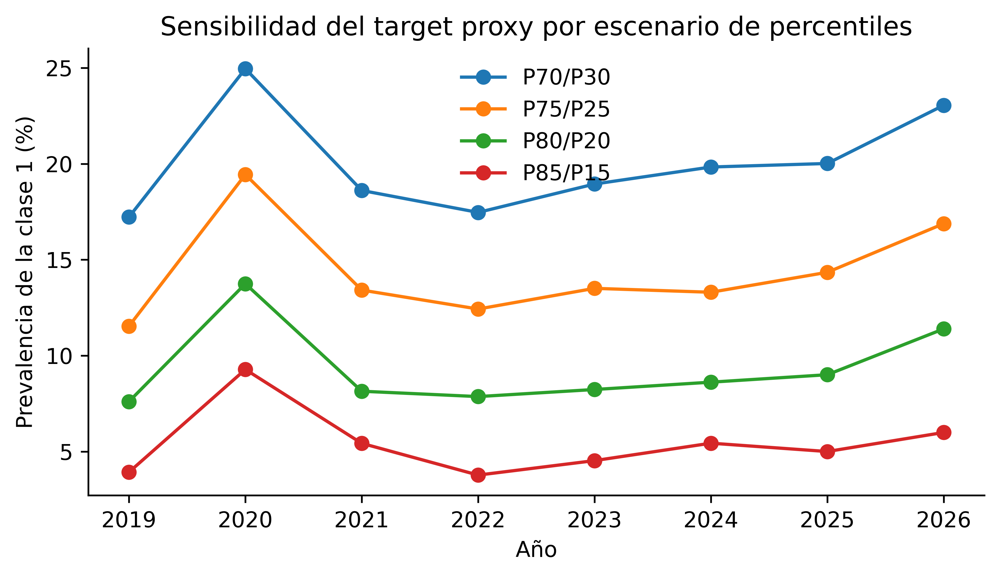

Rezago de la etiqueta — cobertura por año: {2019: 0.0, 2020: 0.9737, 2021: 0.8922, 2022: 0.9237, 2023: 0.9481, 2024: 0.9548, 2025: 0.9374, 2026: 0.9666}


In [12]:
#@title 4b. EJECUTAR etapas 00–04 y ver sus salidas
for _e in ["adquisicion", "consolidacion", "feature_engineering", "preprocessing", "sensibilidad_target"]:
    ejecutar_etapa(_e)

ver_tabla(T / "00_inventario_datos_crudos.csv", "Inventario y huellas SHA-256 de los CSV")
ver_tabla(T / "01_filas_por_anio.csv", "Registros por año tras la consolidación")
ver_tabla(T / "01_calidad_categoricas.csv", "Diagnóstico de calidad de variables categóricas")
ver_tabla(T / "01_perfil_iqr.csv", "Perfil IQR de ingresado y atendido (solo diagnóstico)")
ver_tabla(T / "04_sensibilidad_target.csv", "Sensibilidad del target proxy (Tabla 4)")
ver_figura("04_sensibilidad_target.png")
print("Rezago de la etiqueta — cobertura por año:", res("preprocessing", "rezago_etiqueta", {}).get("cobertura_por_anio"))

#### Lectura de resultados · etapa 4b
Los valores de esta sección se calculan en cada ejecución y se leen desde los archivos generados. No se conservan cifras de ejecuciones anteriores.


### Celda 5 · Definición de las etapas 05–07 (variables y partición)
**Qué hace:** filtros Pearson (0,90) y Cramér V (0,80), codificación one-hot + frecuencia, seis métodos de selección (MI, ANOVA, χ², Random Forest, Boruta, RFECV con F1 y pliegues anuales) con consenso ≥ 2/6, la partición temporal (capa *gold*) y la validación no supervisada del espacio de variables.
**Por qué:** el consenso de métodos heterogéneos reduce la dependencia de un único criterio, y la partición por años completos impide que información futura entre al entrenamiento.

**Actualización v1.01 — Observación 2:** la auditoría temporal usa `engineered.parquet` sin imputación global y vuelve a estimar, dentro de cada pliegue, target, rezago, imputación y codificación. Los seis métodos se ejecutan cuando son aplicables; RFECV se omite y documenta si no existen pliegues internos cronológicos válidos. El análisis se denomina *expanding-window temporal feature-selection stability analysis*, no nested CV completa.

In [13]:
#@title 5. Etapas 05–07: selección de variables, partición temporal (gold), espacio de características
def _cramer_v(izq, der, token_nulo) -> float:
    tabla = pd.crosstab(izq.fillna(token_nulo).astype(str), der.fillna(token_nulo).astype(str))
    n_obs = int(tabla.to_numpy().sum())
    min_dim = min(tabla.shape[0] - 1, tabla.shape[1] - 1)
    if n_obs == 0 or min_dim <= 0:
        return 0.0
    chi2_stat = float(stats.chi2_contingency(tabla, correction=False)[0])
    return float((chi2_stat / (n_obs * min_dim)) ** 0.5)


def _mi_scores(matriz, objetivo, discreta, semilla) -> dict:
    from sklearn.feature_selection import mutual_info_classif

    valores = mutual_info_classif(matriz, objetivo, discrete_features=discreta, random_state=semilla)
    return {c: float(v) for c, v in zip(matriz.columns, valores)}


def _eliminar_pares_redundantes(columnas, sim_fn, umbral, mi) -> list:
    """Recorrido codicioso por pares; del par sobre el umbral sale el de menor MI con el target."""
    eliminadas, conjunto = [], set()
    for i in range(len(columnas)):
        for j in range(i + 1, len(columnas)):
            a, b = columnas[i], columnas[j]
            if a in conjunto or b in conjunto:
                continue
            if abs(sim_fn(a, b)) <= umbral:
                continue
            perdedor = b if mi.get(a, 0.0) >= mi.get(b, 0.0) else a
            eliminadas.append(perdedor)
            conjunto.add(perdedor)
    return eliminadas


def pliegues_anuales(anios: np.ndarray, anios_bloque) -> list:
    """Pliegues expansivos por año: entrenar con años[:k], validar con años[k] (sobre filas ya ordenadas)."""
    anios_bloque = sorted(int(a) for a in anios_bloque)
    pliegues = []
    for k in range(1, len(anios_bloque)):
        tr = np.flatnonzero(np.isin(anios, anios_bloque[:k]))
        va = np.flatnonzero(anios == anios_bloque[k])
        if len(tr) and len(va):
            pliegues.append((tr, va))
    return pliegues


@etapa("feature_selection", "3.4 Feature selection (filtros + consenso de 6 métodos)", deps=["preprocessing"],
       cfg=["feature_selection", "split", "data.exclude_cols", "data.excluir_banderas_operandos", "data.target", "training.seeds",
            "preprocessing.token_categoria_nula"])
def etapa_feature_selection():
    from boruta import BorutaPy
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.feature_selection import RFECV, chi2, f_classif
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import TimeSeriesSplit
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

    fs = CONFIG["feature_selection"]
    sp = CONFIG["split"]
    token = CONFIG["preprocessing"]["token_categoria_nula"]
    metodos_esperados = ("mi", "anova", "chi2", "rf", "boruta", "rfecv")
    if sorted(fs["methods"]) != sorted(metodos_esperados):
        raise ValueError(f"feature_selection.methods debe contener exactamente {list(metodos_esperados)}")
    umbral_consenso = int(fs["consensus_threshold"])
    p = fs["params"]
    alto, bajo = CONFIG["data"]["target"]["primario"]

    df = pd.read_parquet(art("preprocessing", "processed"))
    frame, y_all, q_a, q_b, prev = construir_target(df, sp["train_years"], alto, bajo)
    frame = frame.reset_index(drop=True)
    y_all = np.asarray(y_all).ravel()
    log(f"[fs] target P{alto}/P{bajo}: q_saldo={q_a:.4f} q_tasa={q_b:.4f} prevalencia_train={prev:.4f}")

    excluidas = set(CONFIG["data"]["exclude_cols"])
    if CONFIG["data"]["excluir_banderas_operandos"]:
        excluidas |= {f"{c}_was_null" for c in ("ingresado", "atendido")}
    candidatas = [c for c in df.columns if c not in excluidas]
    n_candidatas = len(candidatas)
    fit_mask = frame["anio"].isin(sp["feature_selection_years"])
    y_fit = y_all[fit_mask.to_numpy()]
    if len(np.unique(y_fit)) < 2:
        raise ValueError("el target del bloque de selección tiene una sola clase")
    num_cand = [c for c in candidatas if pd.api.types.is_numeric_dtype(frame[c])]
    cat_cand = [c for c in candidatas if c not in set(num_cand)]

    if num_cand:
        num_fit = frame.loc[fit_mask, num_cand].astype(float)
        num_fit = num_fit.fillna(num_fit.median()).fillna(0.0)
        corr = num_fit.corr(method="pearson").fillna(0.0)
        mi_num = _mi_scores(num_fit, y_fit, False, SEMILLA)
        pearson_drop = _eliminar_pares_redundantes(num_cand, lambda a, b: abs(float(corr.loc[a, b])),
                                                   float(fs["filters"]["pearson"]), mi_num)
    else:
        pearson_drop = []
    if cat_cand:
        cat_fit = frame.loc[fit_mask, cat_cand].fillna(token).astype(str)
        codigos = pd.DataFrame({c: pd.factorize(cat_fit[c], sort=True)[0] for c in cat_cand}, index=cat_fit.index)
        mi_cat = _mi_scores(codigos, y_fit, True, SEMILLA)
        cramer_drop = _eliminar_pares_redundantes(cat_cand, lambda a, b: _cramer_v(cat_fit[a], cat_fit[b], token),
                                                  float(fs["filters"]["cramer_v"]), mi_cat)
    else:
        cramer_drop = []
    log(f"[fs] candidatas={n_candidatas} | Pearson elimina {len(pearson_drop)} | Cramér V elimina {len(cramer_drop)}")
    caidas = set(pearson_drop) | set(cramer_drop)
    sobrevivientes = [c for c in candidatas if c not in caidas]
    surv_num = [c for c in sobrevivientes if c in set(num_cand)]
    surv_cat = [c for c in sobrevivientes if c not in set(num_cand)]
    if not sobrevivientes:
        raise RuntimeError("los filtros eliminaron todas las candidatas")

    train_mask = frame["anio"].isin(sp["train_years"])
    oh_cols, oh_cats, fq_cols, fq_maps = fit_encoding_maps(frame, surv_cat, train_mask,
                                                           fs["one_hot_max_cardinality"], token)
    codificada = apply_encoding(frame, surv_num, oh_cols, oh_cats, fq_cols, fq_maps, token)
    n_cod = int(codificada.shape[1])
    X_fit = codificada.loc[fit_mask].copy()
    # Evitar que infinitos o NaN heredados de una transformación numérica
    # lleguen a los selectores sklearn.
    X_fit = X_fit.replace([np.inf, -np.inf], np.nan)
    if X_fit.isna().any().any():
        medianas_fit = X_fit.median(numeric_only=True).fillna(0.0)
        X_fit = X_fit.fillna(medianas_fit).fillna(0.0)
    if not np.isfinite(X_fit.to_numpy(dtype=float)).all():
        raise ValueError("feature_selection: X_fit contiene valores no finitos tras la imputación.")
    if X_fit.shape[1] == 0:
        raise ValueError("feature_selection: no quedaron variables codificadas.")
    tk = fs["top_k_per_method"]
    top_k = max(10, n_cod // 3) if tk == "third" else min(int(tk), n_cod)
    n_oh = sum(len(oh_cats[c]) for c in oh_cols)
    log(f"[fs] codificación '{fs['codificacion']}': codificadas={n_cod} = {len(surv_num)} numéricas + {n_oh} one-hot "
        f"({len(oh_cols)} categóricas) + {len(fq_cols)} de frecuencia | top_k={top_k}")

    log("[fs] método 1/6 información mutua")
    mi = _mi_scores(X_fit, y_fit, False, SEMILLA)
    orden_mi = sorted(mi, key=lambda c: (-mi[c], c))
    log("[fs] método 2/6 ANOVA F")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        f_vals, _ = f_classif(X_fit, y_fit)
    anova = {
        c: float(v) if np.isfinite(v) else -1.0
        for c, v in zip(X_fit.columns, f_vals)
    }
    orden_anova = sorted(anova, key=lambda c: (-anova[c], c))
    log("[fs] método 3/6 chi²")
    X_chi = X_fit.sub(X_fit.min(axis=0), axis=1).clip(lower=0.0)
    chi_vals, _ = chi2(X_chi, y_fit)
    chi = {
        c: float(v) if np.isfinite(v) else -1.0
        for c, v in zip(X_fit.columns, chi_vals)
    }
    orden_chi = sorted(chi, key=lambda c: (-chi[c], c))
    log("[fs] método 4/6 Random Forest")
    rf = RandomForestClassifier(n_estimators=int(p["rf_estimators"]), random_state=SEMILLA, n_jobs=1)
    rf.fit(X_fit, y_fit)
    rf_imp = {c: float(v) for c, v in zip(X_fit.columns, rf.feature_importances_)}
    orden_rf = sorted(rf_imp, key=lambda c: (-rf_imp[c], c))
    log("[fs] método 5/6 Boruta")
    bor = BorutaPy(RandomForestClassifier(n_estimators=int(p["rf_estimators"]), random_state=SEMILLA, n_jobs=1),
                   n_estimators="auto", max_iter=int(p["boruta_max_iter"]), random_state=SEMILLA, verbose=0)
    bor.fit(X_fit.to_numpy(), y_fit)
    # Empates de ranking resueltos por MI con el target en el bloque de ajuste (tie_break: target_mi_train).
    orden_bor = [X_fit.columns[i] for i in sorted(range(n_cod), key=lambda i: (int(bor.ranking_[i]), -mi[X_fit.columns[i]],
                                                                              X_fit.columns[i]))]
    log("[fs] método 6/6 RFECV")
    anios_fit = frame.loc[fit_mask, "anio"].to_numpy()
    cron = np.argsort(anios_fit, kind="stable")
    X_rfe = X_fit.iloc[cron]
    y_rfe = y_fit[cron]
    if p["rfecv_cv"] == "anual":
        cv = pliegues_anuales(anios_fit[cron], sp["feature_selection_years"])
    else:
        cv = TimeSeriesSplit(n_splits=int(str(p["rfecv_cv"]).rsplit("_", 1)[1]))
    if not cv:
        raise ValueError(
            "RFECV: no se pudieron construir pliegues temporales. "
            "Revise feature_selection_years y la distribución anual."
        )
    for _fold, (_itr, _iva) in enumerate(cv, start=1):
        if len(np.unique(y_rfe[_itr])) < 2:
            raise ValueError(
                f"RFECV: el conjunto de entrenamiento del pliegue {_fold} "
                "contiene una sola clase; revise el target y los años de selección."
            )
    logit = LogisticRegression(solver=p["rfecv_solver"], max_iter=2000, random_state=SEMILLA)
    if p["rfecv_escalar"]:
        estimador = Pipeline([("sc", StandardScaler()), ("lr", logit)])
        rfecv = RFECV(estimador, step=int(p["rfecv_step"]), cv=cv, importance_getter="named_steps.lr.coef_",
                      n_jobs=int(p["rfecv_n_jobs"]), scoring=p["rfecv_scoring"])
    else:
        rfecv = RFECV(logit, step=int(p["rfecv_step"]), cv=cv, n_jobs=int(p["rfecv_n_jobs"]), scoring=p["rfecv_scoring"])
    rfecv.fit(X_rfe, y_rfe)
    orden_rfe = [X_rfe.columns[i] for i in sorted(range(n_cod), key=lambda i: (int(rfecv.ranking_[i]), -mi[X_rfe.columns[i]],
                                                                              X_rfe.columns[i]))]

    votos_sets = {m: set(o[:top_k]) for m, o in
                  (("mi", orden_mi), ("anova", orden_anova), ("chi2", orden_chi), ("rf", orden_rf),
                   ("boruta", orden_bor), ("rfecv", orden_rfe))}
    votos = {f: int(sum(f in s for s in votos_sets.values())) for f in codificada.columns}
    seleccionadas = [f for f in codificada.columns if votos[f] >= umbral_consenso]
    if not seleccionadas:
        raise RuntimeError("consenso vacío: baje consensus_threshold")
    log(f"[fs] consenso >= {umbral_consenso}/6: {len(seleccionadas)} de {n_cod}")

    tabla_votos = pd.DataFrame([{"feature": f, "votes": votos[f], "consensus": votos[f] >= umbral_consenso,
                                 **{m: int(f in votos_sets[m]) for m in votos_sets},
                                 "mi_score": mi[f], "anova_f": anova[f], "chi2": chi[f], "rf_importance": rf_imp[f],
                                 "boruta_rank": int(bor.ranking_[list(X_fit.columns).index(f)]),
                                 "rfecv_rank": int(rfecv.ranking_[list(X_rfe.columns).index(f)])}
                                for f in sorted(codificada.columns, key=lambda c: (-votos[c], c))])
    t_votos = escribir_csv(tabla_votos, TABLES_DIR / "05_feature_selection_votes.csv")
    dist = []
    for v in range(len(votos_sets), -1, -1):
        n_v = int(sum(1 for f in votos if votos[f] == v))
        dist.append({"votos": f"{v}/{len(votos_sets)}", "n_variables": n_v, "pct_codificadas": n_v / n_cod * 100,
                     "retenidas": v >= umbral_consenso})
    t_dist = escribir_csv(pd.DataFrame(dist), TABLES_DIR / "05_distribucion_consenso.csv")
    metodos = pd.DataFrame([
        {"metodo": "Mutual Information", "tipo": "Filtro (continuo)", "votos_top_k": top_k, "seleccion_nativa": None},
        {"metodo": "ANOVA F-test", "tipo": "Filtro (continuo)", "votos_top_k": top_k, "seleccion_nativa": None},
        {"metodo": "Chi-cuadrado", "tipo": "Filtro (categórico)", "votos_top_k": top_k, "seleccion_nativa": None},
        {"metodo": "Random Forest", "tipo": "Embebido", "votos_top_k": top_k, "seleccion_nativa": None},
        {"metodo": "Boruta", "tipo": "Wrapper (all-relevant)", "votos_top_k": top_k,
         "seleccion_nativa": int(np.sum(bor.support_))},
        {"metodo": "RFECV", "tipo": "Wrapper (recursivo + CV temporal)", "votos_top_k": top_k,
         "seleccion_nativa": int(rfecv.n_features_)},
    ])
    t_met = escribir_csv(metodos, TABLES_DIR / "05_metodos_seleccion.csv")
    caracteristicas = pd.DataFrame([
        {"caracteristica": "Candidatas iniciales", "valor": n_candidatas},
        {"caracteristica": f"Tras filtro Pearson (>{fs['filters']['pearson']})", "valor": n_candidatas - len(pearson_drop)},
        {"caracteristica": f"Tras filtro Cramér V (>{fs['filters']['cramer_v']})", "valor": len(sobrevivientes)},
        {"caracteristica": "Tras codificación (one-hot + frecuencia)", "valor": n_cod},
        {"caracteristica": f"Finales (consenso >= {umbral_consenso}/6)", "valor": len(seleccionadas)},
    ])
    t_car = escribir_csv(caracteristicas, TABLES_DIR / "05_embudo_variables.csv")
    desglose = [{"variable": c, "tipo": "numérica", "columnas_generadas": 1} for c in surv_num]
    desglose += [{"variable": c, "tipo": "categórica one-hot", "columnas_generadas": len(oh_cats[c])} for c in oh_cols]
    desglose += [{"variable": c, "tipo": "categórica frecuencia", "columnas_generadas": 1} for c in fq_cols]
    t_desglose = escribir_csv(pd.DataFrame(desglose), TABLES_DIR / "05_desglose_codificacion.csv")
    codificacion = {"one_hot_cols": oh_cols, "one_hot_categories": oh_cats, "frequency_cols": fq_cols,
                    "frequency_maps": fq_maps, "n_encoded": n_cod, "fitted_num_cols": surv_num, "fitted_cat_cols": surv_cat}
    t_cod = escribir_json(GOLD_DIR / "encoding.json", codificacion)
    return {"artifacts": {"votos": t_votos, "distribucion": t_dist, "metodos": t_met, "embudo": t_car,
                          "desglose": t_desglose, "encoding": t_cod},
            "resumen": {"selected_features": seleccionadas, "n_candidates": n_candidatas, "pearson_dropped": pearson_drop,
                        "cramer_dropped": cramer_drop, "n_survivors": len(sobrevivientes), "n_encoded": n_cod,
                        "top_k": top_k, "boruta_nativo": int(np.sum(bor.support_)), "rfecv_nativo": int(rfecv.n_features_),
                        "thresholds": {"q_saldo": q_a, "q_tasa": q_b}}}


@etapa("split", "3.5 Temporal split (capa gold)", deps=["preprocessing", "feature_selection"],
       cfg=["split", "data.target", "data.columnas_clave", "preprocessing.token_categoria_nula"])
def etapa_split():
    sp = CONFIG["split"]
    token = CONFIG["preprocessing"]["token_categoria_nula"]
    alto, bajo = CONFIG["data"]["target"]["primario"]
    seleccionadas = res("feature_selection", "selected_features")
    cod = leer_json(art("feature_selection", "encoding"))
    df = pd.read_parquet(art("preprocessing", "processed"))
    frame, y_all, q_a, q_b, prev = construir_target(df, sp["train_years"], alto, bajo)
    frame = frame.reset_index(drop=True)
    y_all = np.asarray(y_all).ravel()
    # Verificación cruzada: el split recalcula la codificación con la misma regla y debe coincidir.
    train_mask = frame["anio"].isin(sp["train_years"])
    oh_cols, oh_cats, fq_cols, fq_maps = fit_encoding_maps(frame, cod["fitted_cat_cols"], train_mask,
                                                           CONFIG["feature_selection"]["one_hot_max_cardinality"], token)
    if set(oh_cols) != set(cod["one_hot_cols"]) or set(fq_cols) != set(cod["frequency_cols"]):
        raise RuntimeError("la codificación recalculada difiere de la de feature_selection: recalcule feature_selection")
    for c in oh_cols:
        if [str(v) for v in oh_cats[c]] != [str(v) for v in cod["one_hot_categories"][c]]:
            raise RuntimeError(f"el vocabulario one-hot de '{c}' cambió: recalcule feature_selection")
    codificada = apply_encoding(frame, cod["fitted_num_cols"], oh_cols, oh_cats, fq_cols, fq_maps, token)
    faltan = [f for f in seleccionadas if f not in codificada.columns]
    if faltan:
        raise RuntimeError(f"variables seleccionadas ausentes tras recodificar: {faltan[:5]}")
    fit_years = [a for a in sp["train_years"] if a != sp["feature_selection_valid_year"]]
    bloques = {"search_train": fit_years, "search_valid": [sp["feature_selection_valid_year"]],
               "train_full": list(sp["train_years"]), "calib": [sp["calib_valid_year"]], "test": [sp["test_year"]],
               "external": [sp["external_year"]]}
    meta_cols = ["anio", "ingresado", "atendido", "saldo_casos", "tasa_atencion"] + \
        [c for c in CONFIG["data"]["columnas_clave"] + ["ubigeo_pjfs"] if c in frame.columns]
    arts, detalle, mapa = {}, {}, []
    for nombre, anios in bloques.items():
        mask = frame["anio"].isin(anios)
        if not mask.any():
            raise ValueError(f"bloque vacío '{nombre}' para años {anios}")
        xb = codificada.loc[mask, seleccionadas].astype(float).reset_index(drop=True)
        yb = pd.DataFrame({"anio": frame.loc[mask, "anio"].to_numpy(int), TARGET: y_all[mask.to_numpy()].astype(int)})
        mb = frame.loc[mask, meta_cols].reset_index(drop=True)
        arts[f"X_{nombre}"] = escribir_parquet(xb, GOLD_DIR / f"X_{nombre}.parquet")
        arts[f"y_{nombre}"] = escribir_parquet(yb, GOLD_DIR / f"y_{nombre}.parquet")
        arts[f"M_{nombre}"] = escribir_parquet(mb, GOLD_DIR / f"M_{nombre}.parquet")
        detalle[nombre] = {"years": anios, "n_rows": int(mask.sum()), "prevalence": float(yb[TARGET].mean())}
        mapa += [{"anio": a, "split": nombre} for a in anios]
        log(f"[split] {nombre:<12} años={anios} filas={int(mask.sum())} prevalencia={yb[TARGET].mean():.4f}")
    indice = {"splits": detalle, "thresholds": {"q75_s": q_a, "q25_t": q_b}, "feature_list": seleccionadas, "target": TARGET}
    arts["split_index"] = escribir_json(GOLD_DIR / "split_index.json", indice)
    arts["split_map"] = escribir_csv(pd.DataFrame(mapa), TABLES_DIR / "06_split_map.csv")
    resumen_bloques = pd.DataFrame([{"bloque": k, "anios": ", ".join(map(str, v["years"])), "filas": v["n_rows"],
                                     "clase_0_pct": (1 - v["prevalence"]) * 100, "clase_1_pct": v["prevalence"] * 100}
                                    for k, v in detalle.items()])
    arts["bloques"] = escribir_csv(resumen_bloques, TABLES_DIR / "06_bloques_temporales.csv")
    return {"artifacts": arts, "resumen": {"splits": detalle, "thresholds": {"q75_s": q_a, "q25_t": q_b},
                                           "feature_list": seleccionadas, "n_features": len(seleccionadas)}}


def cargar_gold():
    X, y, M = {}, {}, {}
    for b in BLOQUES:
        X[b] = pd.read_parquet(art("split", f"X_{b}"))
        y[b] = pd.read_parquet(art("split", f"y_{b}"))[TARGET].to_numpy(dtype=int)
        M[b] = pd.read_parquet(art("split", f"M_{b}"))
    return X, y, M


def _codo(valores: np.ndarray) -> float:
    """Punto de máxima distancia a la recta entre extremos de la curva k-distancia ordenada."""
    v = np.sort(np.asarray(valores, dtype=float))
    n = len(v)
    if n < 3:
        return float(v[-1])
    x = np.arange(n, dtype=float)
    dx, dy = (n - 1.0), (v[-1] - v[0])
    d = np.abs(dx * (v[0] - v) - (0.0 - x) * dy) / (math.hypot(dx, dy) + 1e-12)
    return float(v[int(np.argmax(d))])


@etapa("espacio_caracteristicas", "4 Feature space validation (no supervisada)", deps=["split"], cfg=["espacio"])
def etapa_espacio():
    from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
    from sklearn.covariance import EmpiricalCovariance, MinCovDet
    from sklearn.decomposition import PCA
    from sklearn.ensemble import IsolationForest
    from sklearn.manifold import TSNE
    from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
    from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
    from sklearn.preprocessing import StandardScaler

    ec = CONFIG["espacio"]
    X, y, M = cargar_gold()
    Xtr = StandardScaler().fit_transform(X["train_full"].to_numpy(float))
    ytr = y["train_full"]
    n, d = Xtr.shape
    rng = np.random.default_rng(SEMILLA)
    filas, arts = [], {}

    def dispersion(z, titulo, archivo):
        fig, ax = plt.subplots(figsize=(5.2, 4.4))
        for clase, color, etiqueta in ((0, "#9aa7b8", "Clase 0"), (1, "#c0392b", "Clase 1 (riesgo)")):
            m = ytr_sub == clase
            ax.scatter(z[m, 0], z[m, 1], s=5, alpha=0.55 if clase == 0 else 0.8, c=color, label=etiqueta, linewidths=0)
        ax.set_title(titulo)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.legend(frameon=False, markerscale=3)
        return guardar_figura(fig, archivo)

    ytr_sub = ytr
    pca = PCA(n_components=2, random_state=SEMILLA).fit(Xtr)
    z_pca = pca.transform(Xtr)
    arts["fig_pca"] = dispersion(z_pca, "PCA (2 componentes)", "07_pca.png")
    filas.append({"analisis": "PCA (2 componentes)", "evidencia": f"varianza explicada = {pca.explained_variance_ratio_.sum():.3f}",
                  "resultado": "proyección 2D"})
    idx_ts = np.arange(n) if n <= ec["tsne_max_filas"] else np.sort(rng.choice(n, ec["tsne_max_filas"], replace=False))
    ytr_sub = ytr[idx_ts]
    z_ts = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEMILLA).fit_transform(Xtr[idx_ts])
    arts["fig_tsne"] = dispersion(z_ts, "t-SNE", "07_tsne.png")
    filas.append({"analisis": "t-SNE", "evidencia": f"{len(idx_ts)} filas, perplexity=30", "resultado": "proyección 2D"})
    if ec["umap"]:
        try:
            import umap

            ytr_sub = ytr
            z_um = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEMILLA).fit_transform(Xtr)
            arts["fig_umap"] = dispersion(z_um, "UMAP del bloque de entrenamiento", "07_umap.png")
            filas.append({"analisis": "UMAP", "evidencia": "n_neighbors=15, min_dist=0.1", "resultado": "proyección 2D"})
        except Exception as exc:  # umap-learn opcional
            log(f"[aviso] UMAP no disponible: {exc}")

    k_filas = []
    for k in ec["kmeans_k"]:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xtr)
        k_filas.append({"metodo": "kmeans", "k": k, "silhouette": float(silhouette_score(Xtr, km.labels_)),
                        "davies_bouldin": float(davies_bouldin_score(Xtr, km.labels_)),
                        "calinski_harabasz": float(calinski_harabasz_score(Xtr, km.labels_))})
    tab_k = pd.DataFrame(k_filas)
    k_best = int(tab_k.loc[tab_k["silhouette"].idxmax(), "k"])
    km_best = KMeans(n_clusters=k_best, n_init=10, random_state=SEMILLA).fit(Xtr)
    aris = []
    for b in range(int(ec["kmeans_bootstrap"])):
        idx = rng.choice(n, int(0.8 * n), replace=False)
        km_b = KMeans(n_clusters=k_best, n_init=10, random_state=SEMILLA + b + 1).fit(Xtr[idx])
        aris.append(adjusted_rand_score(km_best.labels_, km_b.predict(Xtr)))
    fila_k = tab_k[tab_k["k"] == k_best].iloc[0]
    filas.append({"analisis": "K-Means", "evidencia": f"Silh={fila_k.silhouette:.3f}; DB={fila_k.davies_bouldin:.3f}; "
                                                    f"CH={fila_k.calinski_harabasz:.1f}; ARI={np.mean(aris):.2f}±{np.std(aris):.2f}",
                  "resultado": f"k óptimo={k_best} (máxima silueta); estabilidad bootstrap n={len(aris)}"})

    idx_ag = np.arange(n) if n <= ec["aglomerativo_max_filas"] else np.sort(rng.choice(n, ec["aglomerativo_max_filas"], replace=False))
    ag_filas = []
    for k in ec["kmeans_k"]:
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xtr[idx_ag])
        ag_filas.append({"metodo": "aglomerativo_ward", "k": k, "silhouette": float(silhouette_score(Xtr[idx_ag], lab)),
                         "davies_bouldin": float(davies_bouldin_score(Xtr[idx_ag], lab)),
                         "calinski_harabasz": float(calinski_harabasz_score(Xtr[idx_ag], lab))})
    tab_ag = pd.DataFrame(ag_filas)
    fila_ag = tab_ag.loc[tab_ag["silhouette"].idxmax()]
    filas.append({"analisis": "Clustering aglomerativo (Ward)",
                  "evidencia": f"Silh={fila_ag.silhouette:.3f} (k={int(fila_ag.k)}); DB={fila_ag.davies_bouldin:.3f}; "
                               f"CH={fila_ag.calinski_harabasz:.1f}", "resultado": f"{len(idx_ag)} filas"})

    ms = int(ec["dbscan_min_samples"])
    dist_k = NearestNeighbors(n_neighbors=ms).fit(Xtr).kneighbors(Xtr)[0][:, -1]
    eps = _codo(dist_k)
    lab_db = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xtr)
    n_cl = int(len(set(lab_db)) - (1 if -1 in lab_db else 0))
    ruido = float((lab_db == -1).mean())
    if n_cl >= 2:
        m_ok = lab_db != -1
        ev_db = (f"{n_cl} clusters; ruido={ruido * 100:.1f}%; Silh={silhouette_score(Xtr[m_ok], lab_db[m_ok]):.3f}; "
                 f"DB={davies_bouldin_score(Xtr[m_ok], lab_db[m_ok]):.3f}; CH={calinski_harabasz_score(Xtr[m_ok], lab_db[m_ok]):.1f}")
    else:
        ev_db = f"{n_cl} clusters; ruido={ruido * 100:.1f}%"
    filas.append({"analisis": "DBSCAN", "evidencia": ev_db, "resultado": f"eps={eps:.3f} (codo k-distancia), min_samples={ms}"})

    iso = IsolationForest(contamination="auto", random_state=SEMILLA).fit_predict(Xtr)
    filas.append({"analisis": "Isolation Forest", "evidencia": f"{int((iso == -1).sum())}/{n} ({(iso == -1).mean() * 100:.2f}%)",
                  "resultado": "contamination=auto"})
    lof = LocalOutlierFactor(n_neighbors=int(ec["lof_vecinos"]), contamination="auto").fit_predict(Xtr)
    filas.append({"analisis": "Local Outlier Factor", "evidencia": f"{int((lof == -1).sum())}/{n} ({(lof == -1).mean() * 100:.2f}%)",
                  "resultado": f"n_neighbors={ec['lof_vecinos']}"})
    var_ok = Xtr.std(axis=0) > 1e-9
    Xm = Xtr[:, var_ok]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            cov = MinCovDet(random_state=SEMILLA).fit(Xm)
        metodo_cov = "MinCovDet"
    except Exception:
        cov = EmpiricalCovariance().fit(Xm)
        metodo_cov = "EmpiricalCovariance (MCD no convergió)"
    d2 = cov.mahalanobis(Xm)
    q = float(ec["mahalanobis_cuantil"])
    corte_chi2 = float(stats.chi2.ppf(q, df=Xm.shape[1]))
    corte_emp = float(np.quantile(d2, q))
    n_mah_chi2 = int((d2 > corte_chi2).sum())
    n_mah_emp = int((d2 > corte_emp).sum())
    n_mah = n_mah_emp if ec["mahalanobis_corte"] == "empirico" else n_mah_chi2
    filas.append({"analisis": "Distancia de Mahalanobis robusta", "evidencia": f"{n_mah}/{n} ({n_mah / n * 100:.2f}%)",
                  "resultado": f"{metodo_cov}; corte {'empírico p' + str(round(q * 100, 1)) if ec['mahalanobis_corte'] == 'empirico' else 'χ²'}"
                               f" (con χ²({Xm.shape[1]}, {q}): {n_mah_chi2}/{n})"})

    perfil = pd.DataFrame({"cluster": km_best.labels_, "saldo_casos": M["train_full"]["saldo_casos"].to_numpy(float), "y": ytr})
    perfil = perfil.groupby("cluster").agg(n=("y", "size"), saldo_medio=("saldo_casos", "mean"),
                                           tasa_riesgo=("y", "mean")).reset_index().sort_values("saldo_medio", ascending=False)
    rho, p_rho = stats.spearmanr(perfil["saldo_medio"], perfil["tasa_riesgo"])
    filas.append({"analisis": "Consistencia clusters–riesgo", "evidencia": f"Spearman(saldo medio, tasa de riesgo)={rho:.3f} (p={p_rho:.3f})",
                  "resultado": f"cluster de mayor saldo: tasa de riesgo={perfil.iloc[0]['tasa_riesgo']:.3f}"})

    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
    for ax, met, et in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"], ["Silueta (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"]):
        ax.plot(tab_k["k"], tab_k[met], marker="o", label="K-Means")
        ax.plot(tab_ag["k"], tab_ag[met], marker="s", label="Ward")
        ax.axvline(k_best, ls="--", c="grey", lw=0.8)
        ax.set_title(et)
        ax.set_xlabel("k")
    axes[0].legend(frameon=False)
    arts["fig_k"] = guardar_figura(fig, "07_seleccion_k.png")
    arts["tabla"] = escribir_csv(pd.DataFrame(filas), TABLES_DIR / "07_validacion_no_supervisada.csv")
    arts["k_metricas"] = escribir_csv(pd.concat([tab_k, tab_ag], ignore_index=True), TABLES_DIR / "07_metricas_clustering.csv")
    arts["perfil_clusters"] = escribir_csv(perfil, TABLES_DIR / "07_perfil_clusters_kmeans.csv")
    log(f"[espacio] K-Means k={k_best}; DBSCAN {n_cl} clusters; IF {int((iso == -1).sum())}; LOF {int((lof == -1).sum())}; "
        f"Mahalanobis {n_mah}")
    return {"artifacts": arts, "resumen": {"k_kmeans": k_best, "ari_media": float(np.mean(aris)), "ari_sd": float(np.std(aris)),
                                           "kmeans_silhouette": float(fila_k.silhouette), "kmeans_db": float(fila_k.davies_bouldin),
                                           "kmeans_ch": float(fila_k.calinski_harabasz), "aglomerativo_silhouette": float(fila_ag.silhouette),
                                           "aglomerativo_k": int(fila_ag.k), "dbscan_clusters": n_cl,
                                           "n_isolation_forest": int((iso == -1).sum()), "n_lof": int((lof == -1).sum()),
                                           "n_mahalanobis": n_mah, "n_mahalanobis_chi2": n_mah_chi2,
                                           "n_mahalanobis_empirico": n_mah_emp, "n_train": int(n), "spearman_saldo_riesgo": float(rho)}}

In [14]:
#@title 5a. Validación temporal expansiva corregida (Observación 2)
@etapa("temporal_nested_selection",
       "Expanding-window temporal feature-selection stability analysis; all fold-dependent transforms are train-only",
       deps=["feature_engineering"],
       cfg=["split", "data.target", "data.exclude_cols", "feature_selection", "training.seeds"])
def etapa_temporal_nested_selection():
    """Auditoría temporal por ventanas expansivas, sin imputación/codificación/target/rezago globales.

    Nota metodológica: se denomina análisis de estabilidad temporal, no nested CV completo,
    porque no ejecuta una búsqueda interna de hiperparámetros del clasificador.
    """
    from boruta import BorutaPy
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.feature_selection import mutual_info_classif, f_classif, chi2, RFECV
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
    import inspect

    fs = CONFIG["feature_selection"]
    sp = CONFIG["split"]
    alto, bajo = CONFIG["data"]["target"]["primario"]
    token = CONFIG["preprocessing"]["token_categoria_nula"]
    exclusions = set(CONFIG["data"]["exclude_cols"])
    if CONFIG["data"].get("excluir_banderas_operandos", False):
        exclusions |= {f"{c}_was_null" for c in ("ingresado", "atendido")}
    methods = ("mi", "anova", "chi2", "rf", "boruta", "rfecv")
    if tuple(fs["methods"]) != methods:
        raise ValueError(f"Se esperaban los seis métodos originales en este orden: {methods}; recibido={fs['methods']}")
    consensus_threshold = int(fs["consensus_threshold"])
    top_k_cfg = fs.get("top_k_per_method", 40)
    top_k = int(top_k_cfg) if str(top_k_cfg).isdigit() else 40
    seed = int(SEMILLA)
    key_cols = [c for c in CONFIG["data"]["columnas_clave"] if c in pd.read_parquet(art("feature_engineering", "engineered")).columns]
    raw = pd.read_parquet(art("feature_engineering", "engineered")).copy()
    raw["anio"] = pd.to_numeric(raw["anio"], errors="coerce").astype("Int64")
    years = sorted(set(map(int, sp["feature_selection_years"])) | {int(sp["feature_selection_valid_year"])})
    results, feature_rows, threshold_rows, method_rows = [], [], [], []

    def _fold_frame(train_years, valid_year):
        # Target: thresholds are fitted only on the current training years.
        frame, y, q_saldo, q_tasa, prev_train = construir_target(raw, train_years, alto, bajo)
        frame = frame.reset_index(drop=True)
        y = np.asarray(y, dtype=int)
        train_mask = frame["anio"].astype(int).isin(train_years).to_numpy()
        valid_mask = frame["anio"].astype(int).eq(int(valid_year)).to_numpy()
        # Lag label: previous-year labels are generated with this fold's training thresholds.
        if CONFIG["data"].get("rezago_etiqueta", False) and key_cols:
            ing = pd.to_numeric(frame["ingresado"], errors="coerce").to_numpy(float)
            ate = pd.to_numeric(frame["atendido"], errors="coerce").fillna(0).to_numpy(float)
            saldo = ing - ate
            tasa = np.divide(ate, ing, out=np.zeros_like(ate), where=ing > 0)
            prev_y = ((saldo >= q_saldo) & (tasa <= q_tasa)).astype(int)
            annual = (frame.assign(_fold_label=prev_y)
                      .groupby(key_cols + ["anio"], dropna=False)["_fold_label"].max().reset_index()
                      .rename(columns={"_fold_label": "riesgo_prev_anio"}))
            annual["anio"] = annual["anio"].astype(int) + 1
            frame = frame.drop(columns=[c for c in ("riesgo_prev_anio", "riesgo_prev_disponible") if c in frame])
            frame = frame.merge(annual, on=key_cols + ["anio"], how="left", validate="many_to_one")
            frame["riesgo_prev_disponible"] = frame["riesgo_prev_anio"].notna().astype(int)
            frame["riesgo_prev_anio"] = frame["riesgo_prev_anio"].fillna(0).astype(int)
        # Exclude direct target operands and metadata. Build the predictor matrix from raw engineered values.
        candidates = [c for c in frame.columns if c not in exclusions and c not in {TARGET, "_fold_label"}]
        num_cols = [c for c in candidates if pd.api.types.is_numeric_dtype(frame[c])]
        cat_cols = [c for c in candidates if c not in set(num_cols)]
        # Fold-local numeric imputation and missingness indicators.
        Xnum_train = frame.loc[train_mask, num_cols].apply(pd.to_numeric, errors="coerce")
        medians = Xnum_train.median().replace([np.inf, -np.inf], np.nan).fillna(0.0)
        Xnum = frame[num_cols].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
        for col in num_cols:
            if Xnum[col].isna().any():
                frame[f"{col}_was_null"] = Xnum[col].isna().astype(int)
        Xnum = Xnum.fillna(medians).fillna(0.0)
        # Include null flags only when the original pipeline's policy allows them.
        if not CONFIG["data"].get("excluir_banderas_operandos", False):
            for col in num_cols:
                flag = f"{col}_was_null"
                if flag in frame.columns and col not in CONFIG["data"].get("leakage_cols", []):
                    Xnum[flag] = frame[flag].astype(float)
        # Fold-local categorical normalization and frequency/one-hot maps.
        Xcat_parts = []
        for col in cat_cols:
            tr_values = frame.loc[train_mask, col].fillna(token).astype(str)
            all_values = frame[col].fillna(token).astype(str)
            cats = sorted(tr_values.unique().tolist())
            if fs["codificacion"] == "onehot_y_frecuencia":
                for cat in cats:
                    Xcat_parts.append(pd.Series((all_values == cat).astype(float).to_numpy(), name=f"{col}__{cat}"))
            elif fs["codificacion"] == "onehot_limitado" and len(cats) <= int(fs["one_hot_max_cardinality"]):
                for cat in cats:
                    Xcat_parts.append(pd.Series((all_values == cat).astype(float).to_numpy(), name=f"{col}__{cat}"))
            freq = tr_values.value_counts(normalize=True).to_dict()
            Xcat_parts.append(pd.Series(all_values.map(freq).fillna(0.0).astype(float).to_numpy(), name=f"freq_{col}"))
        X = Xnum.reset_index(drop=True)
        if Xcat_parts:
            X = pd.concat([X] + [p.reset_index(drop=True) for p in Xcat_parts], axis=1)
        X = X.loc[:, ~X.columns.duplicated()].replace([np.inf, -np.inf], np.nan).fillna(0.0)
        return frame, y, train_mask, valid_mask, X, q_saldo, q_tasa, prev_train, medians

    for fold_idx in range(1, len(years)):
        train_years, valid_year = years[:fold_idx], years[fold_idx]
        frame, y, tr, va, X, q_saldo, q_tasa, prev_train, medians = _fold_frame(train_years, valid_year)
        ytr, yva = y[tr], y[va]
        row = {"fold": fold_idx, "train_years": ",".join(map(str, train_years)), "valid_year": int(valid_year),
               "n_train": int(tr.sum()), "n_valid": int(va.sum()), "positives_train": int(ytr.sum()),
               "positives_valid": int(yva.sum()), "q_saldo": float(q_saldo), "q_tasa": float(q_tasa),
               "prevalence_train": float(prev_train), "n_candidate_features": int(X.shape[1])}
        threshold_rows.append({"fold": fold_idx, "train_years": row["train_years"], "valid_year": int(valid_year),
                               "q_saldo_p75": float(q_saldo), "q_tasa_p25": float(q_tasa),
                               "prevalence_train": float(prev_train), "n_medians_fit": int(len(medians)),
                               "median_fit_years": row["train_years"]})
        if tr.sum() == 0 or va.sum() == 0 or len(np.unique(ytr)) < 2 or len(np.unique(yva)) < 2:
            row.update({"n_features_selected": 0, "f1": np.nan, "roc_auc": np.nan, "pr_auc": np.nan,
                        "rfecv_status": "NOT_RUN", "status": "SKIPPED: clase insuficiente"})
            results.append(row)
            continue
        Xtr, Xva = X.loc[tr].reset_index(drop=True), X.loc[va].reset_index(drop=True)
        if Xtr.shape[1] == 0:
            raise RuntimeError(f"Fold {fold_idx}: no quedaron predictores tras codificación.")
        # Six original selection methods, each ranked using training data only.
        mi = mutual_info_classif(Xtr, ytr, discrete_features=False, random_state=seed)
        anova_vals, _ = f_classif(Xtr, ytr)
        Xchi = Xtr.sub(Xtr.min(axis=0), axis=1).clip(lower=0.0)
        chi_vals, _ = chi2(Xchi, ytr)
        rf = RandomForestClassifier(n_estimators=int(fs["params"]["rf_estimators"]), random_state=seed,
                                    n_jobs=1, class_weight="balanced_subsample")
        rf.fit(Xtr, ytr)
        bor_rf = RandomForestClassifier(n_estimators=int(fs["params"]["rf_estimators"]), random_state=seed,
                                        n_jobs=1, class_weight="balanced_subsample")
        bor = BorutaPy(bor_rf, n_estimators="auto", max_iter=int(fs["params"]["boruta_max_iter"]),
                       random_state=seed, verbose=0)
        bor.fit(Xtr.to_numpy(), ytr)
        n_features = Xtr.shape[1]
        k = min(max(1, top_k), n_features)
        rankings = {
            "mi": list(Xtr.columns[np.argsort(-np.nan_to_num(mi, nan=-1.0))[:k]]),
            "anova": list(Xtr.columns[np.argsort(-np.nan_to_num(anova_vals, nan=-1.0))[:k]]),
            "chi2": list(Xtr.columns[np.argsort(-np.nan_to_num(chi_vals, nan=-1.0))[:k]]),
            "rf": list(Xtr.columns[np.argsort(-np.nan_to_num(rf.feature_importances_, nan=0.0))[:k]]),
            "boruta": list(Xtr.columns[np.argsort(np.asarray(bor.ranking_, dtype=int))[:k]])
        }
        # RFECV requires at least two chronological training years and valid two-class inner folds.
        rfecv_status = "SKIPPED: insufficient chronological training years"
        if len(train_years) >= 2:
            fold_pairs = pliegues_anuales(frame.loc[tr, "anio"].astype(int).to_numpy(), train_years)
            # map fold-local positions onto Xtr positions; chronological annual split.
            cv = []
            train_year_array = frame.loc[tr, "anio"].astype(int).to_numpy()
            for k_inner in range(1, len(train_years)):
                itr = np.flatnonzero(np.isin(train_year_array, train_years[:k_inner]))
                iva = np.flatnonzero(train_year_array == train_years[k_inner])
                if len(itr) and len(iva) and len(np.unique(ytr[itr])) == 2 and len(np.unique(ytr[iva])) == 2:
                    cv.append((itr, iva))
            if cv:
                try:
                    logit = LogisticRegression(solver=fs["params"].get("rfecv_solver", "lbfgs"), max_iter=2000,
                                               random_state=seed, class_weight="balanced")
                    estimator = Pipeline([("sc", StandardScaler()), ("lr", logit)]) if fs["params"].get("rfecv_escalar", True) else logit
                    rfecv = RFECV(estimator, step=int(fs["params"].get("rfecv_step", 1)), cv=cv,
                                  scoring=fs["params"].get("rfecv_scoring", "f1"), n_jobs=1,
                                  importance_getter="named_steps.lr.coef_" if fs["params"].get("rfecv_escalar", True) else "auto")
                    rfecv.fit(Xtr, ytr)
                    rankings["rfecv"] = list(Xtr.columns[np.argsort(np.asarray(rfecv.ranking_, dtype=int))[:k]])
                    rfecv_status = f"OK: {len(cv)} chronological inner folds"
                except Exception as exc:
                    rfecv_status = f"SKIPPED: {type(exc).__name__}: {str(exc)[:180]}"
            else:
                rfecv_status = "SKIPPED: no valid two-class chronological inner folds"
        else:
            rfecv_status = "SKIPPED: only one training year; RFECV unavailable"
        active_methods = list(rankings.keys())
        vote_sets = {m: set(v) for m, v in rankings.items()}
        votes = {f: sum(f in vote_sets[m] for m in active_methods) for f in Xtr.columns}
        chosen = [f for f in Xtr.columns if votes[f] >= consensus_threshold]
        if not chosen:
            chosen = list(Xtr.columns[np.argsort(-np.nan_to_num(mi, nan=-1.0))[:min(k, n_features)]])
            consensus_fallback = True
        else:
            consensus_fallback = False
        # Fixed, transparent reference classifier; no hyperparameter search is claimed here.
        clf = Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(max_iter=3000,
                       class_weight="balanced", random_state=seed))])
        clf.fit(Xtr[chosen], ytr)
        prob = clf.predict_proba(Xva[chosen])[:, 1]
        pred = (prob >= 0.5).astype(int)
        row.update({"n_features_selected": len(chosen), "f1": float(f1_score(yva, pred, zero_division=0)),
                    "roc_auc": float(roc_auc_score(yva, prob)), "pr_auc": float(average_precision_score(yva, prob)),
                    "rfecv_status": rfecv_status, "active_methods": ",".join(active_methods),
                    "consensus_threshold": consensus_threshold, "consensus_fallback": consensus_fallback,
                    "status": "OK"})
        results.append(row)
        for feat in Xtr.columns:
            feature_rows.append({"fold": fold_idx, "train_years": row["train_years"], "valid_year": int(valid_year),
                                 "feature": feat, "votes": int(votes[feat]), "selected": bool(feat in chosen),
                                 **{f"vote_{m}": int(feat in vote_sets[m]) if m in vote_sets else 0 for m in methods},
                                 "rfecv_participated": int("rfecv" in vote_sets)})
        for method in methods:
            method_rows.append({"fold": fold_idx, "valid_year": int(valid_year), "method": method,
                                "participated": int(method in rankings),
                                "top_k": int(len(rankings[method])) if method in rankings else 0,
                                "status": rfecv_status if method == "rfecv" else "OK"})

    metrics = pd.DataFrame(results)
    features = pd.DataFrame(feature_rows)
    if features.empty:
        stability = pd.DataFrame(columns=["feature", "folds_available", "folds_selected", "selection_frequency_pct"])
    else:
        availability = features.groupby("feature").agg(folds_available=("fold", "nunique"),
                                                         folds_selected=("selected", "sum")).reset_index()
        availability["selection_frequency_pct"] = 100 * availability["folds_selected"] / availability["folds_available"]
        stability = availability.sort_values(["selection_frequency_pct", "folds_selected", "feature"],
                                              ascending=[False, False, True])
    paths = {
        "metrics": escribir_csv(metrics, TABLES_DIR / "05d_temporal_corrected_metrics.csv"),
        "features": escribir_csv(features, TABLES_DIR / "05e_temporal_corrected_features.csv"),
        "stability": escribir_csv(stability, TABLES_DIR / "05f_temporal_corrected_stability.csv"),
        "thresholds": escribir_csv(pd.DataFrame(threshold_rows), TABLES_DIR / "05g_temporal_corrected_thresholds.csv"),
        "methods": escribir_csv(pd.DataFrame(method_rows), TABLES_DIR / "05h_temporal_corrected_method_status.csv")
    }
    manifest = {"analysis": "expanding-window temporal feature-selection stability analysis",
                "claim": "not full nested CV; no inner hyperparameter optimization of the reference classifier",
                "target_percentiles": {"upper_balance": alto, "lower_attention_rate": bajo},
                "folds": [{"train_years": r["train_years"], "valid_year": int(r["valid_year"])} for r in results],
                "feature_selection_methods": list(methods), "consensus_threshold": consensus_threshold,
                "top_k_per_method": top_k, "rfecv_policy": "skip and document if no valid chronological inner folds",
                "fold_local_operations": ["target thresholds", "lagged target labels", "numeric medians", "categorical vocabulary", "frequency maps", "one-hot maps"],
                "reference_classifier": "StandardScaler + LogisticRegression(class_weight=balanced), fixed settings; no tuning",
                "artifacts": {k: str(v) for k, v in paths.items()}}
    manifest_path = TABLES_DIR / "05i_temporal_corrected_manifest.json"
    manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
    paths["manifest"] = manifest_path
    ok = int((metrics["status"] == "OK").sum()) if not metrics.empty else 0
    return {"artifacts": paths, "resumen": {"folds": len(metrics), "folds_ok": ok,
            "n_features_in_stability": int(len(stability)), "rfecv_skipped_folds": int(metrics.get("rfecv_status", pd.Series(dtype=str)).astype(str).str.startswith("SKIPPED").sum())}}


### Ejecución B · Etapas 05–07
**Qué hace:** ejecuta la validación temporal anidada de selección, selecciona variables, genera la partición temporal y valida el espacio de variables.
**Qué mirar:** el embudo de variables (Tabla 3), los votos por método (Tabla 5), la distribución del consenso (Tabla 6), el balance de clases por bloque y si los conglomerados con más saldo concentran más riesgo.

23:50:37 [run ] temporal_nested_selection — Expanding-window temporal feature-selection stability analysis; all fold-dependent transforms are train-only


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 1  6  7 13 14] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


00:11:49 [ok  ] temporal_nested_selection en 21 min 11.9 s
00:11:49 [run ] feature_selection — 3.4 Feature selection (filtros + consenso de 6 métodos)
00:11:49 [fs] target P75/P25: q_saldo=11.0000 q_tasa=0.9162 prevalencia_train=0.1399
00:11:49 [fs] candidatas=28 | Pearson elimina 6 | Cramér V elimina 9
00:11:50 [fs] codificación 'onehot_y_frecuencia': codificadas=379 = 10 numéricas + 366 one-hot (3 categóricas) + 3 de frecuencia | top_k=40
00:11:50 [fs] método 1/6 información mutua
00:11:55 [fs] método 2/6 ANOVA F
00:11:55 [fs] método 3/6 chi²
00:11:55 [fs] método 4/6 Random Forest


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [  6 224 256] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)


00:11:57 [fs] método 5/6 Boruta
00:12:34 [fs] método 6/6 RFECV
00:14:48 [fs] consenso >= 2/6: 66 de 379
00:14:48 [ok  ] feature_selection en 2 min 58.9 s
00:14:48 [run ] split — 3.5 Temporal split (capa gold)
00:14:48 [split] search_train años=[2019, 2020, 2021, 2022] filas=4861 prevalencia=0.1411
00:14:48 [split] search_valid años=[2023] filas=1214 prevalencia=0.1351
00:14:48 [split] train_full   años=[2019, 2020, 2021, 2022, 2023] filas=6075 prevalencia=0.1399
00:14:48 [split] calib        años=[2024] filas=1195 prevalencia=0.1331
00:14:49 [split] test         años=[2025] filas=1199 prevalencia=0.1435
00:14:49 [split] external     años=[2026] filas=1167 prevalencia=0.1688
00:14:49 [ok  ] split en 1.0 s
00:14:49 [run ] espacio_caracteristicas — 4 Feature space validation (no supervisada)
00:17:18 [espacio] K-Means k=3; DBSCAN 27 clusters; IF 14; LOF 517; Mahalanobis 152
00:17:18 [ok  ] espacio_caracteristicas en 2 min 28.8 s


**Validación temporal expansiva corregida por pliegue**  ·  `05d_temporal_corrected_metrics.csv`  ·  4 filas

... (20 outputs left out)

,analisis,evidencia,resultado
0,PCA (2 componentes),varianza explicada = 0.100,proyección 2D
1,t-SNE,"6075 filas, perplexity=30",proyección 2D
2,UMAP,"n_neighbors=15, min_dist=0.1",proyección 2D
3,K-Means,Silh=0.123; DB=2.265; CH=265.8; ARI=0.62±0.31,k óptimo=3 (máxima silueta); estabilidad bootstrap n=30
4,Clustering aglomerativo (Ward),Silh=0.092 (k=10); DB=1.731; CH=113.9,4000 filas
5,DBSCAN,27 clusters; ruido=1.0%; Silh=0.410; DB=0.795; CH=215.4,"eps=7.879 (codo k-distancia), min_samples=10"
6,Isolation Forest,14/6075 (0.23%),contamination=auto
7,Local Outlier Factor,517/6075 (8.51%),n_neighbors=20
8,Distancia de Mahalanobis robusta,152/6075 (2.50%),"MinCovDet; corte empírico p97.5 (con χ²(66, 0.975): 1129/6075)"
9,Consistencia clusters–riesgo,"Spearman(saldo medio, tasa de riesgo)=-1.000 (p=0.000)",cluster de mayor saldo: tasa de riesgo=0.139


**Perfil de los conglomerados K-Means: saldo medio y tasa de riesgo**  ·  `07_perfil_clusters_kmeans.csv`  ·  3 filas

,cluster,n,saldo_medio,tasa_riesgo
0,2,1629,159.8969,0.1387
1,0,4443,114.5773,0.1398
2,1,3,88.3333,1.0000


**Figura:** `07_umap.png`

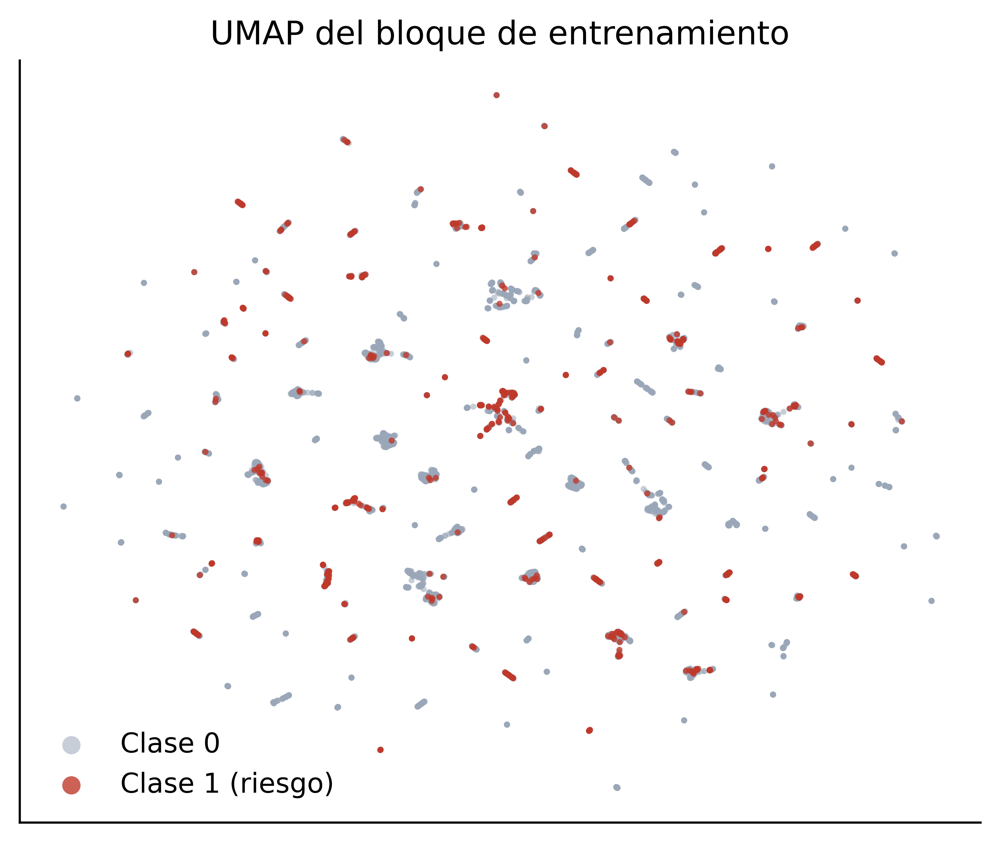

**Figura:** `07_seleccion_k.png`

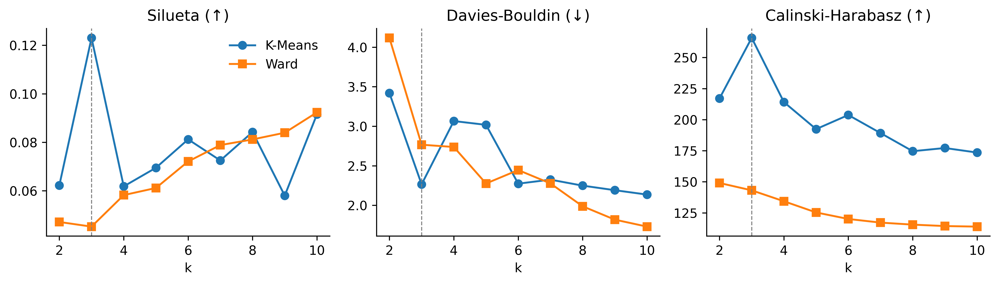

In [15]:
#@title 5b. EJECUTAR etapas 05–07 y ver sus salidas
for _e in ["temporal_nested_selection", "feature_selection", "split", "espacio_caracteristicas"]:
    try:
        ejecutar_etapa(_e)
    except Exception:
        log(f"[ABORTADO] La etapa {_e} falló; no se ejecutarán sus dependientes.")
        raise

ver_tabla(T / "05d_temporal_corrected_metrics.csv", "Validación temporal expansiva corregida por pliegue")
ver_tabla(T / "05f_temporal_corrected_stability.csv", "Estabilidad temporal corregida de variables")
ver_tabla(T / "05g_temporal_corrected_thresholds.csv", "Umbrales y prevalencia estimados dentro de cada pliegue")
ver_tabla(T / "05h_temporal_corrected_method_status.csv", "Estado de los seis métodos de selección por pliegue")
ver_tabla(T / "05_embudo_variables.csv", "Embudo de variables (Tabla 3)")
ver_tabla(T / "05_desglose_codificacion.csv", "Desglose de la codificación one-hot + frecuencia")
ver_tabla(T / "05_metodos_seleccion.csv", "Métodos de selección (Tabla 5)")
ver_tabla(T / "05_distribucion_consenso.csv", "Distribución del consenso (Tabla 6)")
ver_tabla(T / "05_feature_selection_votes.csv", "Variables con más votos (primeras 25)", max_filas=25)
ver_tabla(T / "06_bloques_temporales.csv", "Bloques temporales y balance de clases")
ver_tabla(T / "07_validacion_no_supervisada.csv", "Validación no supervisada del espacio de variables (Tabla 7)")
ver_tabla(T / "07_perfil_clusters_kmeans.csv", "Perfil de los conglomerados K-Means: saldo medio y tasa de riesgo")
ver_figura("07_umap.png", 560)
ver_figura("07_seleccion_k.png")

#### Lectura de resultados · etapa 5b
La tabla de métricas temporales anidadas, la estabilidad de variables, el embudo de selección y los bloques temporales se generan con los datos de la ejecución actual.


### Celda 6 · Definición del entrenamiento
**Qué hace:** búsqueda de hiperparámetros con F1 de la clase positiva en 2023 (RandomizedSearch o Optuna TPE, 100 iteraciones), reajuste en 2019–2023, umbral τ calibrado en 2024, Dummy, Voting y Stacking temporal; checkpoints cada 5 iteraciones.
**Por qué:** separar búsqueda (2023), calibración del umbral (2024) y prueba (2025) evita usar el año de prueba en cualquier decisión.

In [16]:
#@title 6. Etapa 08: entrenamiento (búsqueda, τ en 2024, ensambles) con reanudación por modelo
def construir_estimador(nombre: str, params: dict, semilla: int, y_fit=None):
    """Estimador de cada familia con ponderación de clases (class_weight balanced / scale_pos_weight)."""
    n_jobs = int(CONFIG["training"]["n_jobs"])
    if nombre == "logreg":
        import inspect

        from sklearn.linear_model import LogisticRegression

        penal = params.get("penalty", "l2")
        kwargs = {"C": float(params.get("C", 1.0)), "solver": "saga", "class_weight": "balanced", "max_iter": 5000,
                  "random_state": semilla}
        usa_ratio = CONFIG["training"]["sklearn_penalty_to_l1_ratio"] and \
            "l1_ratio" in inspect.signature(LogisticRegression).parameters and \
            _sklearn_menor(1, 8) is False
        if usa_ratio:
            kwargs["l1_ratio"] = 1.0 if penal == "l1" else 0.0
        else:
            kwargs["penalty"] = penal
        return LogisticRegression(**kwargs)
    if nombre == "svm_linear":
        from sklearn.calibration import CalibratedClassifierCV
        from sklearn.svm import LinearSVC

        base = LinearSVC(C=float(params.get("C", 1.0)), class_weight="balanced", max_iter=5000, random_state=semilla)
        return CalibratedClassifierCV(base, method="sigmoid", cv=3)
    if nombre == "xgboost":
        from xgboost import XGBClassifier

        yy = np.asarray(y_fit).ravel() if y_fit is not None else np.array([0, 1])
        n_pos, n_neg = int((yy == 1).sum()), int((yy == 0).sum())
        return XGBClassifier(n_estimators=int(params.get("n_estimators", 100)),
                             learning_rate=float(params.get("learning_rate", 0.1)),
                             max_depth=int(params.get("max_depth", 6)), scale_pos_weight=n_neg / max(n_pos, 1),
                             random_state=semilla, n_jobs=n_jobs, eval_metric="logloss")
    if nombre in ("lightgbm", "lightgbm_optuna"):
        from lightgbm import LGBMClassifier

        return LGBMClassifier(n_estimators=int(params.get("n_estimators", 100)),
                              learning_rate=float(params.get("learning_rate", 0.1)),
                              num_leaves=int(params.get("num_leaves", 31)), class_weight="balanced",
                              random_state=semilla, n_jobs=n_jobs, verbose=-1)
    if nombre == "catboost":
        from catboost import CatBoostClassifier

        return CatBoostClassifier(iterations=int(params.get("iterations", 100)),
                                  learning_rate=float(params.get("learning_rate", 0.1)), depth=int(params.get("depth", 6)),
                                  auto_class_weights="Balanced", random_seed=semilla, verbose=False, thread_count=n_jobs,
                                  allow_writing_files=False)
    if nombre == "dummy":
        from sklearn.dummy import DummyClassifier

        return DummyClassifier(strategy="most_frequent")
    raise ValueError(f"modelo desconocido '{nombre}'")


def _sklearn_menor(mayor: int, menor: int) -> bool:
    import sklearn

    partes = re.findall(r"\d+", sklearn.__version__)[:2]
    return (int(partes[0]), int(partes[1])) < (mayor, menor)


def ajustar(est, X, y):
    est.fit(np.asarray(X, dtype=float), np.asarray(y).ravel())
    return est


def proba_positiva(est, X) -> np.ndarray:
    X = np.asarray(X, dtype=float)
    if hasattr(est, "predict_proba"):
        p = np.asarray(est.predict_proba(X))
        return p[:, 1] if p.shape[1] > 1 else np.zeros(len(X))
    s = np.asarray(est.decision_function(X), dtype=float)
    lo, hi = s.min(), s.max()
    return np.full(s.shape, 0.5) if hi <= lo else (s - lo) / (hi - lo)


def muestrear_espacio(espacio: dict, rng) -> dict:
    """Muestreo del espacio: loguniform -> exp(U(log lo, log hi)); lista -> elección uniforme."""
    params = {}
    for nombre, spec in (espacio or {}).items():
        if isinstance(spec, dict) and spec.get("type") == "loguniform":
            lo, hi = float(spec["low"]), float(spec["high"])
            params[nombre] = float(math.exp(rng.uniform(math.log(lo), math.log(hi))))
        elif isinstance(spec, list):
            v = spec[int(rng.integers(0, len(spec)))]
            params[nombre] = v.item() if isinstance(v, np.generic) else v
        else:
            params[nombre] = spec
    return params


def matrices_escaladas():
    """Gold escalado con el StandardScaler ajustado en search_train (guardado por la etapa train)."""
    X, y, M = cargar_gold()
    escalador = leer_pickle(art("train", "scaler"))
    Xs = {b: pd.DataFrame(escalador.transform(X[b].to_numpy(float)), columns=X[b].columns) for b in BLOQUES}
    return Xs, y, M, escalador


def leer_predicciones(modelo: str, bloque: str) -> pd.DataFrame:
    return pd.read_csv(PREDS_DIR / f"train_{modelo}_{bloque}_proba.csv")


def _guardar_predicciones(modelo, probas: dict, y: dict, M: dict, tau: float):
    for b in ("calib", "test", "external"):
        fr = pd.DataFrame({"anio": M[b]["anio"].to_numpy(int), "y_true": y[b], "y_proba": np.asarray(probas[b], float)})
        fr["y_pred"] = (fr["y_proba"] >= tau).astype(int)
        escribir_csv(fr, PREDS_DIR / f"train_{modelo}_{b}_proba.csv")


def _forzar_modelo(nombre: str) -> bool:
    return any(x in FORZAR for x in ("todo", "train", f"train:{nombre}"))


def entrenar_modelo_base(nombre, Xs, y, M, huella_base, versiones) -> dict:
    mc = CONFIG["models"][nombre]
    huella = sha_obj({"base": huella_base, "nombre": nombre, "modelo": mc})
    ruta_man = MODELS_DIR / f"train_{nombre}_manifest.json"
    ruta_pkl = MODELS_DIR / f"train_{nombre}.pkl"
    previo = leer_json(ruta_man)
    forzar = _forzar_modelo(nombre)
    if (not forzar and isinstance(previo, dict) and previo.get("fingerprint") == huella and ruta_pkl.exists()
            and all((PREDS_DIR / f"train_{nombre}_{b}_proba.csv").exists() for b in ("calib", "test", "external"))):
        log(f"[train] {nombre}: manifest vigente, se reutiliza (best_search_f1={previo['best_search_f1']:.4f})")
        return previo
    t0 = time.perf_counter()
    optimizador = mc.get("optimizer")
    total = int(mc.get("trials", 30))
    espacio = mc.get("search_space", {})
    cadencia = int(CONFIG["training"]["cadence_trials"])
    sg = int(CONFIG["training"]["seeds"]["global"])
    ss = int(CONFIG["training"]["seeds"]["sampler"])
    imprimir = bool(IMPRIMIR_CADA_TRIAL)
    Xtr, ytr, Xva, yva = Xs["search_train"], y["search_train"], Xs["search_valid"], y["search_valid"]
    log(f"[train] {nombre}: {optimizador}, {total} trials")

    def evaluar(params):
        est = ajustar(construir_estimador(nombre, params, sg, ytr), Xtr, ytr)
        return calcular_f1(yva, (proba_positiva(est, Xva) >= 0.5).astype(int))

    if optimizador == "randomized_search":
        rng = np.random.default_rng(semilla_modelo(nombre))
        secuencia = [muestrear_espacio(espacio, rng) for _ in range(total)]
        ruta_hist = CKPT_DIR / f"trials_{nombre}.json"
        hist = leer_json(ruta_hist, {}) or {}
        trials = hist.get("trials", []) if (not forzar and hist.get("fingerprint") == huella) else []
        if trials:
            log(f"[train] {nombre}: se reanuda desde el trial {len(trials)}/{total}")
        for i in range(len(trials), total):
            puntaje = evaluar(secuencia[i])
            trials.append({"trial": i + 1, "params": secuencia[i], "f1_search_valid": puntaje})
            if (i + 1) % cadencia == 0 or (i + 1) == total:
                escribir_json(ruta_hist, {"fingerprint": huella, "trials": trials})
                mejor = max(t["f1_search_valid"] for t in trials)
                log(f"[train] {nombre}: checkpoint trial {i + 1}/{total} mejor={mejor:.4f}", imprimir=imprimir or (i + 1) == total)
        mejor_trial = max(trials, key=lambda t: t["f1_search_valid"])
        mejores, mejor_f1 = dict(mejor_trial["params"]), float(mejor_trial["f1_search_valid"])
        historial = pd.DataFrame([{"trial": t["trial"], **t["params"], "f1_search_valid": t["f1_search_valid"]} for t in trials])
    elif optimizador == "optuna_tpe":
        import optuna

        optuna.logging.set_verbosity(optuna.logging.WARNING)
        db_local = TMP_LOCAL / f"optuna_{nombre}.db"
        db_drive = CKPT_DIR / f"optuna_{nombre}.db"
        if forzar:
            for ruta in (db_local, db_drive):
                if ruta.exists():
                    ruta.unlink()
        if not db_local.exists() and db_drive.exists():
            shutil.copy2(db_drive, db_local)
        estudio = optuna.create_study(study_name=f"{nombre}_{huella[:12]}", storage=f"sqlite:///{db_local.as_posix()}",
                                      load_if_exists=True, direction="maximize",
                                      sampler=optuna.samplers.TPESampler(seed=ss))

        def objetivo(trial):
            params = {}
            for pn, spec in espacio.items():
                if isinstance(spec, dict) and spec.get("type") == "loguniform":
                    params[pn] = trial.suggest_float(pn, float(spec["low"]), float(spec["high"]), log=True)
                elif isinstance(spec, list):
                    params[pn] = trial.suggest_categorical(pn, spec)
            return evaluar(params)

        def completos():
            return [t for t in estudio.trials if t.state == optuna.trial.TrialState.COMPLETE]

        if completos():
            log(f"[train] {nombre}: se reanuda el estudio Optuna con {len(completos())} trials completos")
        while len(completos()) < total:
            estudio.optimize(objetivo, n_trials=min(cadencia, total - len(completos())))
            shutil.copy2(db_local, db_drive.with_name(db_drive.name + ".tmp"))
            db_drive.with_name(db_drive.name + ".tmp").replace(db_drive)
            log(f"[train] {nombre}: checkpoint trial {len(completos())}/{total} mejor={estudio.best_value:.4f}",
                imprimir=imprimir or len(completos()) >= total)
        mejores, mejor_f1 = dict(estudio.best_params), float(estudio.best_value)
        historial = pd.DataFrame([{"trial": t.number + 1, **t.params, "f1_search_valid": t.value} for t in completos()])
    else:
        raise ValueError(f"optimizador no soportado para {nombre}: {optimizador}")

    escribir_csv(historial, TABLES_DIR / f"08_trials_{nombre}.csv")
    final = ajustar(construir_estimador(nombre, mejores, sg, y["train_full"]), Xs["train_full"], y["train_full"])
    probas = {b: proba_positiva(final, Xs[b]) for b in ("calib", "test", "external")}
    tau = tau_optimo(y["calib"], probas["calib"])
    m_cal = metricas_binarias(y["calib"], probas["calib"], tau)
    m_test = metricas_binarias(y["test"], probas["test"], tau)
    m_ext = metricas_binarias(y["external"], probas["external"], tau)
    escribir_pickle(final, ruta_pkl)
    _guardar_predicciones(nombre, probas, y, M, tau)
    manifest = {"stage": "train", "model": nombre, "fingerprint": huella, "optimizer": optimizador, "trials": total,
                "seeds": {"global": sg, "sampler": ss, "busqueda_aleatoria": semilla_modelo(nombre)},
                "versions": versiones, "best_params": mejores, "best_search_f1": mejor_f1,
                "metrica_f1": CONFIG["evaluacion"]["metrica_f1"], "tau_star": tau, "metrics_valid": m_cal,
                "metrics_test": m_test, "metrics_external": m_ext,
                "summary": {"tau_star": tau, "f1_test": m_test[CONFIG["evaluacion"]["metrica_f1"]], "roc_auc_test": m_test["roc_auc"]}}
    escribir_json(ruta_man, manifest)
    log(f"[train] {nombre}: listo en {formatear_duracion(time.perf_counter() - t0)} | τ*={tau:.2f} | "
        f"test f1_macro={m_test['f1_macro']:.4f} f1_binary={m_test['f1_binary']:.4f} roc={m_test['roc_auc']:.4f}")
    return manifest


def entrenar_dummy(Xs, y, M, huella_base, versiones) -> dict:
    est = ajustar(construir_estimador("dummy", {}, SEMILLA), Xs["train_full"], y["train_full"])
    probas = {b: proba_positiva(est, Xs[b]) for b in ("calib", "test", "external")}
    tau = tau_optimo(y["calib"], probas["calib"])
    escribir_pickle(est, MODELS_DIR / "train_dummy.pkl")
    _guardar_predicciones("dummy", probas, y, M, tau)
    manifest = {"stage": "train", "model": "dummy", "fingerprint": sha_obj({"base": huella_base, "nombre": "dummy"}),
                "optimizer": None, "best_params": {"strategy": "most_frequent"}, "best_search_f1": None, "tau_star": tau,
                "metrics_valid": metricas_binarias(y["calib"], probas["calib"], tau),
                "metrics_test": metricas_binarias(y["test"], probas["test"], tau),
                "metrics_external": metricas_binarias(y["external"], probas["external"], tau), "versions": versiones}
    escribir_json(MODELS_DIR / "train_dummy_manifest.json", manifest)
    return manifest


def seleccionar_miembros(manifests_base: dict) -> list:
    ens = CONFIG["training"]["ensembles"]
    candidatos = [(n, m) for n, m in manifests_base.items() if n not in set(ens["exclude_from_voting"]) and m.get("best_params")]
    candidatos.sort(key=lambda kv: kv[1]["best_search_f1"], reverse=True)
    elegidos = candidatos[: int(ens["select_top_n"])]
    if not elegidos:
        raise RuntimeError("no hay modelos base válidos para los ensambles")
    return [{"name": n, "best_params": m["best_params"], "best_search_f1": m["best_search_f1"], "fingerprint": m["fingerprint"]}
            for n, m in elegidos]


def matriz_probas_miembros(miembros, X) -> np.ndarray:
    columnas = []
    for info in miembros:
        est = leer_pickle(MODELS_DIR / f"train_{info['name']}.pkl")
        columnas.append(proba_positiva(est, X))
    return np.column_stack(columnas)


def entrenar_voting(miembros, Xs, y, M, versiones) -> dict:
    huella = sha_obj({"miembros": [(m["name"], m["fingerprint"]) for m in miembros], "metrica": CONFIG["evaluacion"]["metrica_f1"],
                      "grid": CONFIG["calibration"]["grid"]})
    ruta_man = MODELS_DIR / "train_voting_manifest.json"
    previo = leer_json(ruta_man)
    if not _forzar_modelo("voting") and isinstance(previo, dict) and previo.get("fingerprint") == huella:
        log("[train] voting: manifest vigente, se reutiliza")
        return previo
    probas = {b: matriz_probas_miembros(miembros, Xs[b]).mean(axis=1) for b in ("calib", "test", "external")}
    tau = tau_optimo(y["calib"], probas["calib"])
    _guardar_predicciones("voting", probas, y, M, tau)
    escribir_pickle({"members": [m["name"] for m in miembros], "method": "soft_average"}, MODELS_DIR / "train_voting.pkl")
    manifest = {"stage": "train", "model": "voting", "fingerprint": huella,
                "params": {"method": "soft_average", "members": [m["name"] for m in miembros]}, "tau_star": tau,
                "metrics_valid": metricas_binarias(y["calib"], probas["calib"], tau),
                "metrics_test": metricas_binarias(y["test"], probas["test"], tau),
                "metrics_external": metricas_binarias(y["external"], probas["external"], tau), "versions": versiones}
    escribir_json(ruta_man, manifest)
    log(f"[train] voting: miembros={manifest['params']['members']} τ*={tau:.2f} "
        f"test f1_macro={manifest['metrics_test']['f1_macro']:.4f} roc={manifest['metrics_test']['roc_auc']:.4f}")
    return manifest


def entrenar_stacking(miembros, Xs, y, M, versiones) -> dict:
    """Meta-regresión logística sobre probabilidades OOF de pliegues anuales expansivos del bloque train_full."""
    from sklearn.linear_model import LogisticRegression

    huella = sha_obj({"miembros": [(m["name"], m["fingerprint"]) for m in miembros], "metrica": CONFIG["evaluacion"]["metrica_f1"],
                      "grid": CONFIG["calibration"]["grid"], "metodo": "temporal_oof_logreg"})
    ruta_man = MODELS_DIR / "train_stacking_manifest.json"
    previo = leer_json(ruta_man)
    if not _forzar_modelo("stacking") and isinstance(previo, dict) and previo.get("fingerprint") == huella:
        log("[train] stacking: manifest vigente, se reutiliza")
        return previo
    sg = int(CONFIG["training"]["seeds"]["global"])
    anios = M["train_full"]["anio"].to_numpy(int)
    orden = np.argsort(anios, kind="stable")
    Xf = Xs["train_full"].to_numpy(float)[orden]
    yf = np.asarray(y["train_full"])[orden]
    af = anios[orden]
    pliegues = pliegues_anuales(af, sorted(set(af.tolist())))
    oof = np.zeros((len(yf), len(miembros)))
    validado = np.zeros(len(yf), dtype=bool)
    for k, (tr, va) in enumerate(pliegues, start=1):
        for j, info in enumerate(miembros):
            est = ajustar(construir_estimador(info["name"], info["best_params"], sg, yf[tr]), Xf[tr], yf[tr])
            oof[va, j] = proba_positiva(est, Xf[va])
        validado[va] = True
        log(f"[train] stacking: pliegue {k}/{len(pliegues)} (valida {int(af[va][0])}, n={len(va)})")
    meta = LogisticRegression(solver="saga", class_weight="balanced", max_iter=5000, random_state=sg)
    solver = "saga"
    try:
        meta.fit(oof[validado], yf[validado])
    except Exception as exc:
        log(f"[aviso] stacking: saga falló ({exc}); se usa lbfgs")
        meta = LogisticRegression(solver="lbfgs", class_weight="balanced", max_iter=5000, random_state=sg)
        meta.fit(oof[validado], yf[validado])
        solver = "lbfgs"
    probas = {b: meta.predict_proba(matriz_probas_miembros(miembros, Xs[b]))[:, 1] for b in ("calib", "test", "external")}
    tau = tau_optimo(y["calib"], probas["calib"])
    _guardar_predicciones("stacking", probas, y, M, tau)
    escribir_pickle({"meta": meta, "members": [m["name"] for m in miembros], "solver": solver}, MODELS_DIR / "train_stacking.pkl")
    manifest = {"stage": "train", "model": "stacking", "fingerprint": huella,
                "params": {"method": "temporal_oof_logreg", "members": [m["name"] for m in miembros],
                           "n_oof_splits": len(pliegues), "meta": {"solver": solver, "class_weight": "balanced",
                                                                   "coef": meta.coef_.ravel().tolist(),
                                                                   "intercept": float(meta.intercept_[0])}},
                "tau_star": tau, "metrics_valid": metricas_binarias(y["calib"], probas["calib"], tau),
                "metrics_test": metricas_binarias(y["test"], probas["test"], tau),
                "metrics_external": metricas_binarias(y["external"], probas["external"], tau), "versions": versiones}
    escribir_json(ruta_man, manifest)
    log(f"[train] stacking: τ*={tau:.2f} test f1_macro={manifest['metrics_test']['f1_macro']:.4f} "
        f"roc={manifest['metrics_test']['roc_auc']:.4f}")
    return manifest


def verificar_quality_gates(metricas: dict, gates: dict) -> dict:
    fallas = []
    for modelo, por_metrica in gates.items():
        for metrica, lim in por_metrica.items():
            valor = (metricas.get(modelo) or {}).get(metrica)
            if not isinstance(valor, (int, float)) or valor is None or (isinstance(valor, float) and math.isnan(valor)):
                fallas.append(f"{modelo}.{metrica}: sin valor")
            elif not (lim["min"] <= valor <= lim["max"]):
                fallas.append(f"{modelo}.{metrica}: {valor:.4f} fuera de [{lim['min']}, {lim['max']}]")
    return {"passed": not fallas, "failures": fallas}


@etapa("train", "5 Model training (búsqueda + τ en 2024 + ensambles)", deps=["split"],
       cfg=["models", "training", "calibration", "evaluacion.metrica_f1"])
def etapa_train():
    from sklearn.preprocessing import StandardScaler

    tr = CONFIG["training"]
    X, y, M = cargar_gold()
    if tr["scale"] == "standard_scaler_train_only":
        escalador = StandardScaler().fit(X["search_train"].to_numpy(float))
    elif tr["scale"] == "none":
        escalador = StandardScaler(with_mean=False, with_std=False).fit(X["search_train"].to_numpy(float))
    else:
        raise ValueError(f"training.scale={tr['scale']!r} no soportado")
    ruta_scaler = escribir_pickle(escalador, MODELS_DIR / "train_scaler.pkl")
    Xs = {b: pd.DataFrame(escalador.transform(X[b].to_numpy(float)), columns=X[b].columns) for b in BLOQUES}
    versiones = {"python": platform.python_version()}
    for lib in ("sklearn", "pandas", "numpy", "optuna", "lightgbm", "xgboost", "catboost", "shap"):
        try:
            versiones[lib] = getattr(__import__(lib), "__version__", "instalado")
        except ImportError:
            versiones[lib] = "ausente"
    huella_base = sha_obj({"split": MANIFESTS["split"]["artifacts_sha"], "training": tr, "calibration": CONFIG["calibration"],
                           "metrica": CONFIG["evaluacion"]["metrica_f1"], "version": HUELLA_VERSION})
    base = {}
    for nombre in tr["active_models"]:
        base[nombre] = entrenar_modelo_base(nombre, Xs, y, M, huella_base, versiones)
    todos = dict(base)
    if tr["dummy"]:
        todos["dummy"] = entrenar_dummy(Xs, y, M, huella_base, versiones)
    miembros = seleccionar_miembros(base)
    log(f"[train] miembros de los ensambles (top {tr['ensembles']['select_top_n']} por F1 de búsqueda, sin "
        f"{tr['ensembles']['exclude_from_voting']}): {[m['name'] for m in miembros]}")
    if tr["ensembles"]["voting"]:
        todos["voting"] = entrenar_voting(miembros, Xs, y, M, versiones)
    if tr["ensembles"]["stacking"]:
        todos["stacking"] = entrenar_stacking(miembros, Xs, y, M, versiones)

    filas = []
    for nombre, man in todos.items():
        for bloque, clave in (("calib", "metrics_valid"), ("test", "metrics_test"), ("external", "metrics_external")):
            m = man[clave]
            filas.append({"modelo": nombre, "bloque": bloque, "tau_star": man["tau_star"],
                          **{k: m[k] for k in ("f1_binary", "f1_macro", "precision", "recall", "specificity", "roc_auc",
                                               "pr_auc", "accuracy", "mcc", "tp", "fp", "fn", "tn")}})
    tabla = pd.DataFrame(filas)
    t_met = escribir_csv(tabla, TABLES_DIR / "08_metricas_modelos_tau_star.csv")
    metricas_test = {n: {k: man["metrics_test"][k] for k in ("f1_macro", "f1_binary", "roc_auc", "accuracy")} for n, man in todos.items()}
    escribir_csv(pd.DataFrame([{"model": n, **v} for n, v in metricas_test.items()]), MODELS_DIR / "train_metrics.csv")
    gates = verificar_quality_gates(metricas_test, CONFIG["quality_gates"])
    if not gates["passed"]:
        log(f"[aviso] quality gates: {gates['failures']} (diagnosticar antes de cambiar código; nunca bajar el gate)")
    configuraciones = []
    for nombre in tr["active_models"]:
        man = base[nombre]
        configuraciones.append({"modelo": nombre, "optimizador": man["optimizer"], "trials": man["trials"],
                                "f1_busqueda_2023": man["best_search_f1"], "mejores_parametros": json.dumps(man["best_params"])})
    t_conf = escribir_csv(pd.DataFrame(configuraciones), TABLES_DIR / "08_configuraciones_modelos.csv")
    global_man = {"target": {"q75_s": res("split", "thresholds")["q75_s"], "q25_t": res("split", "thresholds")["q25_t"],
                             "train_prevalence": float(np.mean(y["train_full"]))},
                  "n_features": int(X["search_train"].shape[1]), "versions": versiones, "metrics": metricas_test,
                  "members": [m["name"] for m in miembros], "quality_check": gates, "metrica_f1": CONFIG["evaluacion"]["metrica_f1"]}
    t_glob = escribir_json(MODELS_DIR / "train_manifest.json", global_man)
    arts = {"scaler": ruta_scaler, "metricas": t_met, "configuraciones": t_conf, "train_manifest": t_glob}
    for nombre in todos:
        arts[f"manifest_{nombre}"] = MODELS_DIR / f"train_{nombre}_manifest.json"
    return {"artifacts": arts, "resumen": {"modelos": list(todos), "base": list(base), "miembros": [m["name"] for m in miembros],
                                           "tau_star": {n: m["tau_star"] for n, m in todos.items()},
                                           "best_params": {n: m["best_params"] for n, m in base.items()},
                                           "quality_check": gates, "versions": versiones}}

### Ejecución C · Entrenamiento
**Qué hace:** entrena los 6 modelos base, el Dummy y los dos conjuntos.
**Qué mirar:** la F1 de búsqueda de cada modelo y sus métricas en su propio τ*.

In [17]:
#@title 6b. EJECUTAR el entrenamiento (6 modelos × 100 iteraciones + Dummy + Voting + Stacking)
ejecutar_etapa("train")

ver_tabla(T / "08_configuraciones_modelos.csv", "Mejor configuración por modelo (F1 en 2023)")
ver_tabla(T / "08_metricas_modelos_tau_star.csv", "Métricas de cada modelo en su τ* (2024, 2025, 2026)", max_filas=30)

00:17:47 [run ] train — 5 Model training (búsqueda + τ en 2024 + ensambles)
00:17:53 [train] logreg: randomized_search, 100 trials
00:18:03 [train] logreg: checkpoint trial 5/100 mejor=0.5699
00:18:28 [train] logreg: checkpoint trial 10/100 mejor=0.5714


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


00:19:15 [train] logreg: checkpoint trial 15/100 mejor=0.5714
00:20:07 [train] logreg: checkpoint trial 20/100 mejor=0.5714
00:20:32 [train] logreg: checkpoint trial 25/100 mejor=0.5931
00:21:01 [train] logreg: checkpoint trial 30/100 mejor=0.5931
00:21:13 [train] logreg: checkpoint trial 35/100 mejor=0.5931


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


00:21:50 [train] logreg: checkpoint trial 40/100 mejor=0.5931
00:21:54 [train] logreg: checkpoint trial 45/100 mejor=0.5931


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


... (9 outputs left out)

**Mejor configuración por modelo (F1 en 2023)**  ·  `08_configuraciones_modelos.csv`  ·  6 filas

,modelo,optimizador,trials,f1_busqueda_2023,mejores_parametros
0,logreg,randomized_search,100,0.5931,"{""C"": 0.00220666245939848, ""penalty"": ""l1""}"
1,svm_linear,randomized_search,100,0.4375,"{""C"": 2.2178510793915542}"
2,xgboost,randomized_search,100,0.5879,"{""n_estimators"": 100, ""learning_rate"": 0.015984492195193017, ""max_..."
3,lightgbm,randomized_search,100,0.5831,"{""n_estimators"": 500, ""learning_rate"": 0.016189903738023183, ""num_..."
4,lightgbm_optuna,optuna_tpe,100,0.5851,"{""n_estimators"": 100, ""learning_rate"": 0.09223910396082194, ""num_l..."
5,catboost,randomized_search,100,0.5886,"{""iterations"": 100, ""learning_rate"": 0.015128131164774196, ""depth""..."


**Métricas de cada modelo en su τ* (2024, 2025, 2026)**  ·  `08_metricas_modelos_tau_star.csv`  ·  27 filas

,modelo,bloque,tau_star,f1_binary,f1_macro,precision,recall,specificity,roc_auc,pr_auc,accuracy,mcc,tp,fp,fn,tn
0,logreg,calib,0.55,0.6378,0.7906,0.6280,0.6478,0.9411,0.8548,0.5481,0.9021,0.5813,103,61,56,975
1,logreg,test,0.55,0.6159,0.7775,0.6474,0.5872,0.9464,0.8337,0.5737,0.8949,0.5560,101,55,71,972
2,logreg,external,0.55,0.6523,0.7933,0.6954,0.6142,0.9454,0.8168,0.5931,0.8895,0.5885,121,53,76,917
3,svm_linear,calib,0.28,0.5902,0.7651,0.6164,0.5660,0.9459,0.8619,0.5882,0.8954,0.5310,90,56,69,980
4,svm_linear,test,0.28,0.6000,0.7703,0.6739,0.5407,0.9562,0.8575,0.6472,0.8966,0.5458,93,45,79,982
5,svm_linear,external,0.28,0.5994,0.7647,0.6933,0.5279,0.9526,0.8391,0.6086,0.8809,0.5378,104,46,93,924
6,xgboost,calib,0.52,0.6442,0.7940,0.6287,0.6604,0.9402,0.8645,0.5598,0.9029,0.5882,105,62,54,974
7,xgboost,test,0.52,0.6121,0.7751,0.6392,0.5872,0.9445,0.8621,0.5968,0.8932,0.5510,101,57,71,970
8,xgboost,external,0.52,0.6524,0.7930,0.6893,0.6193,0.9433,0.8339,0.6097,0.8886,0.5875,122,55,75,915
9,lightgbm,calib,0.46,0.6301,0.7837,0.5829,0.6855,0.9247,0.8963,0.6115,0.8929,0.5705,109,78,50,958


#### Lectura de resultados · entrenamiento
Las métricas y configuraciones se muestran a partir de los artefactos producidos en la ejecución actual; no se incorporan resultados históricos fijos.


### Celda 7 · Definición de las etapas 09–13 (evaluación)
**Qué hace:** comparación a τ = 0,5 y CV temporal interna (Friedman), selección del modelo final en 2024, métricas con IC bootstrap, DeLong, umbrales alternativos y costos, walk-forward 2020–2026, calibración (ECE/MCE) y deriva (PSI).
**Por qué:** el modelo se elige con 2024; 2025 y 2026 solo se usan para informar el desempeño.

In [18]:
#@title 7. Etapas 09–13: comparativa y selección, evaluación final, walk-forward, calibración, deriva (PSI)
NOMBRES_MODELOS = {
    "logreg": "Logistic Regression", "svm_linear": "SVM (LinearSVC + Platt)", "xgboost": "XGBoost",
    "lightgbm": "LightGBM (búsqueda aleatoria)", "lightgbm_optuna": "LightGBM (Optuna TPE)", "catboost": "CatBoost",
    "voting": "VotingClassifier", "stacking": "Temporal Stacking", "dummy": "Dummy (baseline)",
    "persistencia": "Persistencia (etiqueta del año previo)",
}


def _X_sin_escalar_por_anio():
    """Concatena los bloques disjuntos (train_full, calib, test, external) sin escalar, con su año y target."""
    X, y, M = cargar_gold()
    partes_x, partes_y, partes_a = [], [], []
    for b in ("train_full", "calib", "test", "external"):
        partes_x.append(X[b].to_numpy(float))
        partes_y.append(y[b])
        partes_a.append(M[b]["anio"].to_numpy(int))
    return np.vstack(partes_x), np.concatenate(partes_y), np.concatenate(partes_a), list(X["train_full"].columns)


@etapa("comparativa", "6.1 Comparison of models (τ = 0,5) + selección del modelo final", deps=["train"],
       cfg=["evaluacion.seleccion", "evaluacion.metrica_f1", "split.train_years"])
def etapa_comparativa():
    from sklearn.preprocessing import StandardScaler

    metrica = CONFIG["evaluacion"]["metrica_f1"]
    umbral = float(CONFIG["evaluacion"]["seleccion"]["umbral"])
    modelos = res("train", "modelos")
    base = res("train", "base")
    filas = []
    for m in modelos:
        pc, pt, pe = (leer_predicciones(m, b) for b in ("calib", "test", "external"))
        mc = metricas_binarias(pc["y_true"], pc["y_proba"], umbral)
        mt = metricas_binarias(pt["y_true"], pt["y_proba"], umbral)
        me = metricas_binarias(pe["y_true"], pe["y_proba"], umbral)
        filas.append({"modelo": m, "nombre": NOMBRES_MODELOS.get(m, m),
                      "valid_f1_binary": mc["f1_binary"], "valid_f1_macro": mc["f1_macro"], "valid_roc_auc": mc["roc_auc"],
                      "valid_pr_auc": mc["pr_auc"],
                      "test_f1_binary": mt["f1_binary"], "test_f1_macro": mt["f1_macro"], "test_roc_auc": mt["roc_auc"],
                      "test_pr_auc": mt["pr_auc"], "external_f1_binary": me["f1_binary"], "external_roc_auc": me["roc_auc"]})
    # Referencia explícita: regla de persistencia (riesgo_prev_anio) y coincidencia de cada modelo con ella en 2024.
    Xg, yg, _ = cargar_gold()
    coincidencia = {}
    if "riesgo_prev_anio" in Xg["calib"].columns:
        prev = {b: (Xg[b]["riesgo_prev_anio"].to_numpy() > 0.5).astype(int) for b in ("calib", "test", "external")}
        for f in filas:
            pc = leer_predicciones(f["modelo"], "calib")
            coincidencia[f["modelo"]] = float(((pc["y_proba"].to_numpy() >= umbral).astype(int) == prev["calib"]).mean())
            f["coincidencia_persistencia_2024"] = coincidencia[f["modelo"]]
        mp = {b: metricas_binarias(yg[b], prev[b], 0.5) for b in prev}
        filas.append({"modelo": "persistencia", "nombre": NOMBRES_MODELOS["persistencia"],
                      "valid_f1_binary": mp["calib"]["f1_binary"], "valid_f1_macro": mp["calib"]["f1_macro"],
                      "valid_roc_auc": mp["calib"]["roc_auc"], "valid_pr_auc": mp["calib"]["pr_auc"], "test_f1_binary": mp["test"]["f1_binary"],
                      "test_f1_macro": mp["test"]["f1_macro"], "test_roc_auc": mp["test"]["roc_auc"],
                      "test_pr_auc": mp["test"]["pr_auc"], "external_f1_binary": mp["external"]["f1_binary"],
                      "external_roc_auc": mp["external"]["roc_auc"], "coincidencia_persistencia_2024": 1.0})
    tabla = pd.DataFrame(filas)
    col_sel = "valid_f1_binary" if metrica == "f1_binary" else "valid_f1_macro"
    tabla = tabla.sort_values([col_sel, "valid_roc_auc"], ascending=False).reset_index(drop=True)

    # CV temporal interna (pliegues anuales expansivos dentro de train_years) con los mejores parámetros.
    X, y, M = cargar_gold()
    Xtf = X["train_full"].to_numpy(float)
    ytf = y["train_full"]
    atf = M["train_full"]["anio"].to_numpy(int)
    pliegues = pliegues_anuales(atf, CONFIG["split"]["train_years"])
    mejores = res("train", "best_params")
    sg = int(CONFIG["training"]["seeds"]["global"])
    cv_filas = []
    for m in base:
        for k, (tr, va) in enumerate(pliegues, start=1):
            esc = StandardScaler().fit(Xtf[tr])
            est = ajustar(construir_estimador(m, mejores[m], sg, ytf[tr]), esc.transform(Xtf[tr]), ytf[tr])
            p = proba_positiva(est, esc.transform(Xtf[va]))
            mm = metricas_binarias(ytf[va], p, 0.5)
            cv_filas.append({"modelo": m, "pliegue": k, "anio_valid": int(atf[va][0]), "f1_binary": mm["f1_binary"],
                             "f1_macro": mm["f1_macro"], "roc_auc": mm["roc_auc"]})
    cv = pd.DataFrame(cv_filas)
    cv_res = cv.groupby("modelo").agg(cv_f1_binary_media=("f1_binary", "mean"), cv_f1_binary_sd=("f1_binary", "std"),
                                      cv_f1_macro_media=("f1_macro", "mean"), cv_f1_macro_sd=("f1_macro", "std"),
                                      cv_roc_auc_media=("roc_auc", "mean")).reset_index()
    tabla = tabla.merge(cv_res, on="modelo", how="left")
    pivote = cv.pivot(index="pliegue", columns="modelo", values=metrica)
    friedman = {"chi2": float("nan"), "p_value": float("nan"), "k_modelos": int(pivote.shape[1]), "n_pliegues": int(pivote.shape[0])}
    if pivote.shape[1] >= 3 and pivote.shape[0] >= 2:
        est_f, p_f = stats.friedmanchisquare(*[pivote[c].to_numpy() for c in pivote.columns])
        friedman.update({"chi2": float(est_f), "p_value": float(p_f)})
    rangos = pivote.rank(axis=1, ascending=False).mean().sort_values()
    friedman["rangos_promedio"] = {k: float(v) for k, v in rangos.items()}
    log(f"[comp] Friedman sobre {pivote.shape[0]} pliegues × {pivote.shape[1]} modelos: χ²={friedman['chi2']:.3f} p={friedman['p_value']:.4f}")

    sel = CONFIG["evaluacion"]["seleccion"]
    candidatos = base if sel["candidatos"] == "base" else [m for m in modelos if m != "dummy"]
    clones = [m for m in candidatos if coincidencia.get(m, 0.0) >= float(sel["umbral_clon"])]
    if sel["excluir_clones_persistencia"] and clones and len(clones) < len(candidatos):
        log(f"[comp] excluidos por reproducir la persistencia en 2024 (coincidencia ≥ {sel['umbral_clon']}): {clones}")
        candidatos = [m for m in candidatos if m not in clones]
    cand = tabla[tabla["modelo"].isin(candidatos)].copy()
    if sel["criterio"] == "rango_f1_roc":
        cand["rango_f1"] = cand[col_sel].rank(ascending=False, method="min")
        cand["rango_roc"] = cand["valid_roc_auc"].rank(ascending=False, method="min")
        cand["rango_promedio"] = (cand["rango_f1"] + cand["rango_roc"]) / 2
        cand = cand.sort_values(["rango_promedio", col_sel, "valid_roc_auc"], ascending=[True, False, False])
        criterio_txt = f"menor rango promedio de {col_sel} (τ={umbral}) y ROC-AUC en 2024"
        tabla = tabla.merge(cand[["modelo", "rango_f1", "rango_roc", "rango_promedio"]], on="modelo", how="left")
    else:
        cand = cand.sort_values([col_sel, "valid_roc_auc"], ascending=False)
        criterio_txt = f"máx. {col_sel} a τ={umbral} en 2024"
    final = str(cand.iloc[0]["modelo"])
    tau_final = float(res("train", "tau_star")[final])
    log(f"[comp] modelo final ({criterio_txt}): {final} | τ*={tau_final:.2f}")
    log("[comp] candidatos: " + "; ".join(f"{r.modelo} F1={getattr(r, col_sel):.3f} ROC={r.valid_roc_auc:.3f}"
                                          + (f" rango={r.rango_promedio:.1f}" if "rango_promedio" in cand.columns else "")
                                          for r in cand.itertuples()))

    # Sensibilidad de la regla de selección: qué modelo se elegiría con cada regla y cómo rinde en 2025/2026.
    # Se reporta para declarar con transparencia que la regla adoptada no se eligió por su resultado en prueba.
    base_tab = tabla[tabla["modelo"].isin(base)].copy()
    sin_clones = base_tab[~base_tab["modelo"].isin(clones)]

    def _por_rango(df):
        d = df.copy()
        d["_r"] = (d[col_sel].rank(ascending=False, method="min") + d["valid_roc_auc"].rank(ascending=False, method="min")) / 2
        return d.sort_values(["_r", col_sel, "valid_roc_auc"], ascending=[True, False, False]).iloc[0]["modelo"]

    reglas = [
        ("F1 2024 solamente", "todos", base_tab.sort_values([col_sel, "valid_roc_auc"], ascending=False).iloc[0]["modelo"]),
        ("F1 2024 sin clones de la persistencia", "sin clones",
         sin_clones.sort_values([col_sel, "valid_roc_auc"], ascending=False).iloc[0]["modelo"]),
        ("ROC-AUC 2024", "todos", base_tab.sort_values(["valid_roc_auc", col_sel], ascending=False).iloc[0]["modelo"]),
        ("PR-AUC 2024", "todos", base_tab.sort_values(["valid_pr_auc", col_sel], ascending=False).iloc[0]["modelo"]),
        ("Rango promedio F1 + ROC-AUC 2024", "todos", _por_rango(base_tab)),
        ("Rango promedio F1 + ROC-AUC 2024 sin clones (adoptada)", "sin clones", _por_rango(sin_clones)),
    ]
    filas_r = []
    for regla, cands, m in reglas:
        r = tabla.set_index("modelo").loc[m]
        filas_r.append({"regla": regla, "candidatos": cands, "modelo_elegido": m, "nombre": NOMBRES_MODELOS.get(m, m),
                        "coincidencia_persistencia_2024": r.get("coincidencia_persistencia_2024", float("nan")),
                        "test_f1_binary": r.test_f1_binary, "test_roc_auc": r.test_roc_auc, "test_pr_auc": r.test_pr_auc,
                        "external_f1_binary": r.external_f1_binary, "external_roc_auc": r.external_roc_auc})
    t_reglas = escribir_csv(pd.DataFrame(filas_r), TABLES_DIR / "09_sensibilidad_regla_seleccion.csv")
    log("[comp] sensibilidad de la regla: " + "; ".join(f"{f['regla']} → {f['modelo_elegido']}" for f in filas_r))
    t_comp = escribir_csv(tabla, TABLES_DIR / "09_comparacion_modelos_tau05.csv")
    t_cv = escribir_csv(cv, TABLES_DIR / "09_cv_temporal_interna.csv")
    t_fr = escribir_json(TABLES_DIR / "09_friedman.json", friedman)
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    orden = tabla["modelo"].tolist()
    xs = np.arange(len(orden))
    sufijo = "f1_binary" if metrica == "f1_binary" else "f1_macro"
    ax.bar(xs - 0.2, tabla[f"valid_{sufijo}"], width=0.4, label="Validación 2024", color="#34495e")
    ax.bar(xs + 0.2, tabla[f"test_{sufijo}"], width=0.4, label="Test 2025", color="#e67e22")
    ax.set_xticks(xs)
    ax.set_xticklabels([NOMBRES_MODELOS.get(m, m) for m in orden], rotation=35, ha="right")
    ax.set_ylabel(f"{sufijo} (τ = {umbral})")
    ax.set_title("Comparación de modelos")
    ax.legend(frameon=False)
    f_comp = guardar_figura(fig, "09_comparacion_modelos.png")
    return {"artifacts": {"comparacion": t_comp, "cv": t_cv, "friedman": t_fr, "figura": f_comp, "reglas": t_reglas},
            "resumen": {"modelo_final": final, "tau_final": tau_final, "criterio": criterio_txt, "clones_excluidos": clones,
                        "friedman": friedman, "ranking": cand[["modelo", col_sel, "valid_roc_auc"]].to_dict(orient="records")}}


def umbrales_alternativos(y_cal, p_cal, tau_f1) -> dict:
    ev = CONFIG["evaluacion"]
    fpr, tpr, thr = roc_curve(y_cal, p_cal)
    validos = np.isfinite(thr)
    j = np.argmax((tpr - fpr)[validos])
    youden = float(np.clip(thr[validos][j], 0.0, 1.0))
    fina = np.round(np.arange(0.01, 1.0, 0.01), 2)
    prec = np.array([precision_score(y_cal, (p_cal >= t).astype(int), zero_division=0) for t in fina])
    rec = np.array([recall_score(y_cal, (p_cal >= t).astype(int), zero_division=0) for t in fina])
    ok_p = np.flatnonzero(prec >= ev["precision_objetivo"])
    ok_r = np.flatnonzero(rec >= ev["recall_objetivo"])
    salida = {"tau_f1_calibrado": float(tau_f1), "tau_0.5": 0.5, "tau_youden": youden}
    if len(ok_p):
        salida[f"tau_precision>={ev['precision_objetivo']}"] = float(fina[ok_p[0]])
    if len(ok_r):
        salida[f"tau_recall>={ev['recall_objetivo']}"] = float(fina[ok_r[-1]])
    return salida


@etapa("evaluacion_final", "6.2 Final model performance (IC bootstrap, DeLong, umbrales, costos)", deps=["train", "comparativa"],
       cfg=["evaluacion"])
def etapa_evaluacion_final():
    ev = CONFIG["evaluacion"]
    final = res("comparativa", "modelo_final")
    tau = float(res("comparativa", "tau_final"))
    modelos = res("train", "modelos")
    pred = {b: leer_predicciones(final, b) for b in ("calib", "test", "external")}
    nombres_bloque = {"calib": "Validación 2024", "test": "Test 2025", "external": "Externo 2026"}
    metricas = {b: metricas_binarias(pred[b]["y_true"], pred[b]["y_proba"], tau) for b in pred}
    claves = ["accuracy", "precision", "recall", "f1_binary", "f1_macro", "roc_auc", "pr_auc", "mcc", "specificity",
              "balanced_accuracy", "kappa", "npv", "fpr", "fnr", "lr_pos", "lr_neg", "brier", "tp", "fp", "fn", "tn", "n",
              "prevalence"]
    tabla_final = pd.DataFrame({"metrica": claves, **{nombres_bloque[b]: [metricas[b][k] for k in claves] for b in pred}})
    t_final = escribir_csv(tabla_final, TABLES_DIR / "10_desempeno_modelo_final.csv")

    ics = []
    for b in pred:
        ic = bootstrap_ic(pred[b]["y_true"], pred[b]["y_proba"], tau, ev["n_bootstrap"])
        ic.insert(0, "bloque", nombres_bloque[b])
        ics.append(ic)
    t_ic = escribir_csv(pd.concat(ics, ignore_index=True), TABLES_DIR / "10_ic_bootstrap.csv")
    fila_ic = ics[1][ics[1]["metrica"] == "f1_binary"].iloc[0]
    log(f"[final] {final} τ={tau:.2f} | test F1 binaria={metricas['test']['f1_binary']:.3f} "
        f"(IC95% {fila_ic.ic_inf:.3f}–{fila_ic.ic_sup:.3f}, {ev['n_bootstrap']} remuestreos) | "
        f"ROC test={metricas['test']['roc_auc']:.3f} externo={metricas['external']['roc_auc']:.3f}")

    umbrales = umbrales_alternativos(pred["calib"]["y_true"].to_numpy(), pred["calib"]["y_proba"].to_numpy(), tau)
    filas_u = []
    for nombre_u, t_u in umbrales.items():
        for b in ("calib", "test", "external"):
            m = metricas_binarias(pred[b]["y_true"], pred[b]["y_proba"], t_u)
            costo = m["fn"] * ev["costo_fn"] + m["fp"] * ev["costo_fp"]
            filas_u.append({"umbral": nombre_u, "tau": t_u, "bloque": nombres_bloque[b], "precision": m["precision"],
                            "recall": m["recall"], "specificity": m["specificity"], "f1_binary": m["f1_binary"],
                            "f1_macro": m["f1_macro"], "tp": m["tp"], "fp": m["fp"], "fn": m["fn"], "tn": m["tn"],
                            "costo_fn": ev["costo_fn"], "costo_fp": ev["costo_fp"], "perdida_estimada": costo,
                            "ratio_fn_fp": f"{ev['costo_fn'] / ev['costo_fp']:.0f}:1"})
    t_umb = escribir_csv(pd.DataFrame(filas_u), TABLES_DIR / "10_umbrales_alternativos_y_costos.csv")

    filas_d = []
    for otro in modelos:
        if otro == final:
            continue
        for b in ("test", "external"):
            p_otro = leer_predicciones(otro, b)
            d = delong(pred[b]["y_true"], pred[b]["y_proba"], p_otro["y_proba"])
            filas_d.append({"bloque": nombres_bloque[b], "modelo_final": final, "comparado": otro,
                            "auc_final": d["auc_1"], "auc_comparado": d["auc_2"], "z": d["z"], "p_value": d["p_value"]})
    t_del = escribir_csv(pd.DataFrame(filas_d), TABLES_DIR / "10_delong.csv")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    for m in modelos:
        p = leer_predicciones(m, "test")
        if m == "dummy" or p["y_true"].nunique() < 2:
            continue
        fpr, tpr, _ = roc_curve(p["y_true"], p["y_proba"])
        pr, rc, _ = precision_recall_curve(p["y_true"], p["y_proba"])
        ancho = 2.2 if m == final else 1.0
        axes[0].plot(fpr, tpr, lw=ancho, label=f"{NOMBRES_MODELOS.get(m, m)} ({roc_auc_score(p['y_true'], p['y_proba']):.3f})")
        axes[1].plot(rc, pr, lw=ancho, label=f"{NOMBRES_MODELOS.get(m, m)} ({average_precision_score(p['y_true'], p['y_proba']):.3f})")
    axes[0].plot([0, 1], [0, 1], ls="--", c="grey", lw=0.8)
    axes[0].set_xlabel("Tasa de falsos positivos")
    axes[0].set_ylabel("Tasa de verdaderos positivos")
    axes[0].set_title("Curvas ROC — test 2025")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precisión")
    axes[1].set_title("Curvas precisión-recall — test 2025")
    for ax in axes:
        ax.legend(frameon=False, fontsize=7)
    f_roc = guardar_figura(fig, "10_roc_pr_test.png")
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
    for ax, b in zip(axes, ("calib", "test", "external")):
        m = metricas[b]
        cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
        ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="black", fontsize=11)
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(["Pred 0", "Pred 1"])
        ax.set_yticklabels(["Real 0", "Real 1"])
        ax.set_title(nombres_bloque[b])
    fig.suptitle(f"Matrices de confusión — {NOMBRES_MODELOS.get(final, final)}, τ = {tau:.2f}")
    f_cm = guardar_figura(fig, "10_matrices_confusion.png")
    return {"artifacts": {"tabla_final": t_final, "ic": t_ic, "umbrales": t_umb, "delong": t_del, "fig_roc": f_roc, "fig_cm": f_cm},
            "resumen": {"modelo_final": final, "tau": tau, "metricas": metricas, "umbrales": umbrales,
                        "f1_binary_test_ic": [float(fila_ic.ic_inf), float(fila_ic.ic_sup)]}}


@etapa("walk_forward", "6.2 External walk-forward validation (reentrenamiento anual)", deps=["train", "comparativa"],
       cfg=["evaluacion.walk_forward_anios", "evaluacion.walk_forward_modelos", "evaluacion.metrica_f1"])
def etapa_walk_forward():
    from sklearn.preprocessing import StandardScaler

    X_all, y_all, a_all, _ = _X_sin_escalar_por_anio()
    base = res("train", "base")
    lista = base if CONFIG["evaluacion"]["walk_forward_modelos"] == "base" else list(CONFIG["evaluacion"]["walk_forward_modelos"])
    mejores = res("train", "best_params")
    taus = res("train", "tau_star")
    sg = int(CONFIG["training"]["seeds"]["global"])
    filas = []
    for m in lista:
        for anio in CONFIG["evaluacion"]["walk_forward_anios"]:
            tr = a_all < anio
            te = a_all == anio
            if tr.sum() == 0 or te.sum() == 0 or len(np.unique(y_all[tr])) < 2:
                continue
            esc = StandardScaler().fit(X_all[tr])
            est = ajustar(construir_estimador(m, mejores[m], sg, y_all[tr]), esc.transform(X_all[tr]), y_all[tr])
            p = proba_positiva(est, esc.transform(X_all[te]))
            m_tau = metricas_binarias(y_all[te], p, taus[m])
            m_05 = metricas_binarias(y_all[te], p, 0.5)
            filas.append({"modelo": m, "anio_evaluado": int(anio), "n_train": int(tr.sum()), "n_eval": int(te.sum()),
                          "prevalencia": m_tau["prevalence"], "tau": taus[m], "f1_binary_tau": m_tau["f1_binary"],
                          "f1_macro_tau": m_tau["f1_macro"], "f1_binary_05": m_05["f1_binary"], "f1_macro_05": m_05["f1_macro"],
                          "roc_auc": m_tau["roc_auc"], "pr_auc": m_tau["pr_auc"]})
        log(f"[wf] {m}: {sum(1 for f in filas if f['modelo'] == m)} puntos temporales")
    tabla = pd.DataFrame(filas)
    resumen = tabla.groupby("modelo").agg(n_puntos=("anio_evaluado", "size"),
                                          f1_binary_tau_media=("f1_binary_tau", "mean"), f1_binary_tau_sd=("f1_binary_tau", "std"),
                                          f1_macro_tau_media=("f1_macro_tau", "mean"), f1_macro_tau_sd=("f1_macro_tau", "std"),
                                          f1_binary_05_media=("f1_binary_05", "mean"), f1_binary_05_sd=("f1_binary_05", "std"),
                                          roc_auc_media=("roc_auc", "mean")).reset_index()
    t1 = escribir_csv(tabla, TABLES_DIR / "11_walk_forward_por_anio.csv")
    t2 = escribir_csv(resumen, TABLES_DIR / "11_walk_forward_resumen.csv")
    col = "f1_binary_tau" if CONFIG["evaluacion"]["metrica_f1"] == "f1_binary" else "f1_macro_tau"
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for m, g in tabla.groupby("modelo"):
        ax.plot(g["anio_evaluado"], g[col], marker="o", label=NOMBRES_MODELOS.get(m, m))
    ax.set_xlabel("Año evaluado (entrenamiento con todos los años previos)")
    ax.set_ylabel(f"{col.replace('_tau', '')} a τ* del modelo")
    ax.set_title("Validación walk-forward externa")
    ax.legend(frameon=False, fontsize=7)
    f1 = guardar_figura(fig, "11_walk_forward.png")
    return {"artifacts": {"por_anio": t1, "resumen": t2, "figura": f1},
            "resumen": {"medias": resumen.to_dict(orient="records")}}


@etapa("calibracion", "6.5 Calibration (diagrama de confiabilidad, ECE, MCE)", deps=["train", "comparativa"],
       cfg=["evaluacion.calibracion_bins"])
def etapa_calibracion():
    final = res("comparativa", "modelo_final")
    tau = float(res("comparativa", "tau_final"))
    n_bins = int(CONFIG["evaluacion"]["calibracion_bins"])
    filas, curvas = [], []
    for m in res("train", "modelos"):
        for b in ("calib", "test", "external"):
            p = leer_predicciones(m, b)
            curva, ece, mce = curva_confiabilidad(p["y_true"], p["y_proba"], n_bins)
            filas.append({"modelo": m, "bloque": b, "ece": ece, "mce": mce,
                          "brier": float(brier_score_loss(p["y_true"], p["y_proba"]))})
            if m == final:
                curva.insert(0, "bloque", b)
                curvas.append(curva)
    tabla = pd.DataFrame(filas)
    curva_final = pd.concat(curvas, ignore_index=True)
    t1 = escribir_csv(tabla, TABLES_DIR / "12_calibracion_ece_mce.csv")
    t2 = escribir_csv(curva_final, TABLES_DIR / "12_curva_confiabilidad_modelo_final.csv")
    c_test = curva_final[curva_final["bloque"] == "test"]
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(5, 5.6), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)
    llenos = c_test[c_test["n"] > 0]
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=0.8, label="Calibración perfecta")
    ax.plot(llenos["confianza_media"], llenos["frecuencia_observada"], marker="o", c="#c0392b", label=NOMBRES_MODELOS.get(final, final))
    ax.axvline(tau, ls=":", c="#2c3e50", lw=1, label=f"τ = {tau:.2f}")
    fila = tabla[(tabla["modelo"] == final) & (tabla["bloque"] == "test")].iloc[0]
    ax.set_title(f"Confiabilidad — test 2025 (ECE={fila.ece:.3f}; MCE={fila.mce:.3f})")
    ax.set_ylabel("Frecuencia observada de la clase 1")
    ax.legend(frameon=False, fontsize=8)
    ax2.bar((c_test["limite_inf"] + c_test["limite_sup"]) / 2, c_test["n"], width=1.0 / n_bins * 0.9, color="#7f8c8d")
    ax2.set_xlabel("Probabilidad predicha")
    ax2.set_ylabel("n")
    f1 = guardar_figura(fig, "12_diagrama_confiabilidad.png")
    log(f"[calib] {final} test: ECE={fila.ece:.3f} MCE={fila.mce:.3f} Brier={fila.brier:.3f}")
    return {"artifacts": {"tabla": t1, "curva": t2, "figura": f1},
            "resumen": {"ece_test": float(fila.ece), "mce_test": float(fila.mce), "brier_test": float(fila.brier)}}


@etapa("drift_psi", "5.x Temporal drift (PSI respecto del bloque de entrenamiento)", deps=["split"],
       cfg=["evaluacion.psi_bins"])
def etapa_drift():
    X, y, M = cargar_gold()
    bins = int(CONFIG["evaluacion"]["psi_bins"])
    ref = X["train_full"]
    filas = []
    for f in ref.columns:
        fila = {"feature": f}
        for b in ("calib", "test", "external"):
            fila[f"psi_{b}"] = psi(ref[f].to_numpy(), X[b][f].to_numpy(), bins)
        fila["psi_max"] = max(fila[f"psi_{b}"] for b in ("calib", "test", "external"))
        fila["nivel"] = "alto (>0,25)" if fila["psi_max"] > 0.25 else ("moderado (0,10–0,25)" if fila["psi_max"] > 0.10 else "estable (<0,10)")
        filas.append(fila)
    tabla = pd.DataFrame(filas).sort_values("psi_max", ascending=False)
    t1 = escribir_csv(tabla, TABLES_DIR / "13_psi_drift.csv")
    top = tabla.head(30)
    fig, ax = plt.subplots(figsize=(6.5, max(3, 0.28 * len(top) + 1)))
    im = ax.imshow(top[["psi_calib", "psi_test", "psi_external"]].to_numpy(), aspect="auto", cmap="OrRd")
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top["feature"], fontsize=7)
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["2024", "2025", "2026"])
    fig.colorbar(im, ax=ax, label="PSI")
    ax.set_title("Deriva temporal de variables (PSI vs 2019–2023)")
    f1 = guardar_figura(fig, "13_psi_heatmap.png")
    conteo = tabla["nivel"].value_counts().to_dict()
    log(f"[psi] niveles: {conteo}")
    return {"artifacts": {"tabla": t1, "figura": f1}, "resumen": {"niveles": conteo,
                                                                  "top5": tabla.head(5)[["feature", "psi_max"]].to_dict(orient="records")}}

### Ejecución D · Etapas 09–13
**Qué hace:** produce las Tablas 8–10 y 12, las pruebas estadísticas y las figuras de evaluación.
**Qué mirar:** qué modelo se selecciona y por qué, el IC de la F1 en 2025, si DeLong encuentra diferencias significativas y si el desempeño se sostiene en el walk-forward y en 2026.

01:18:58 [run ] comparativa — 6.1 Comparison of models (τ = 0,5) + selección del modelo final
01:19:18 [comp] Friedman sobre 4 pliegues × 6 modelos: χ²=8.286 p=0.1412
01:19:18 [comp] excluidos por reproducir la persistencia en 2024 (coincidencia ≥ 0.99): ['logreg', 'xgboost']
01:19:18 [comp] modelo final (menor rango promedio de valid_f1_binary (τ=0.5) y ROC-AUC en 2024): lightgbm | τ*=0.46
01:19:18 [comp] candidatos: lightgbm F1=0.618 ROC=0.896 rango=1.5; lightgbm_optuna F1=0.615 ROC=0.900 rango=1.5; catboost F1=0.607 ROC=0.870 rango=3.0; svm_linear F1=0.407 ROC=0.862 rango=4.0
01:19:18 [comp] sensibilidad de la regla: F1 2024 solamente → logreg; F1 2024 sin clones de la persistencia → lightgbm; ROC-AUC 2024 → lightgbm_optuna; PR-AUC 2024 → lightgbm_optuna; Rango promedio F1 + ROC-AUC 2024 → lightgbm; Rango promedio F1 + ROC-AUC 2024 sin clones (adoptada) → lightgbm
01:19:19 [ok  ] comparativa en 20.4 s
01:19:19 [run ] evaluacion_final — 6.2 Final model performance (IC bootstrap, DeLo

**Comparación de modelos a τ = 0,5 (Tabla 9) + CV temporal interna (Tabla 8)**  ·  `09_comparacion_modelos_tau05.csv`  ·  10 filas

,modelo,nombre,valid_f1_binary,valid_f1_macro,valid_roc_auc,valid_pr_auc,test_f1_binary,test_f1_macro,test_roc_auc,test_pr_auc,external_f1_binary,external_roc_auc,coincidencia_persistencia_2024,cv_f1_binary_media,cv_f1_binary_sd,cv_f1_macro_media,cv_f1_macro_sd,cv_roc_auc_media,rango_f1,rango_roc,rango_promedio
0,persistencia,Persistencia (etiqueta del año previo),0.6378,0.7906,0.7945,0.4537,0.6159,0.7775,0.7668,0.4394,0.6523,0.7798,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,logreg,Logistic Regression,0.6358,0.7893,0.8548,0.5481,0.6140,0.7763,0.8337,0.5737,0.6505,0.8168,0.9992,0.5131,0.1258,0.6043,0.2946,0.7302,NaN,NaN,NaN
2,voting,VotingClassifier,0.6353,0.7874,0.8933,0.6257,0.6050,0.7680,0.8666,0.6614,0.6337,0.8585,0.9858,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,xgboost,XGBoost,0.6325,0.7866,0.8645,0.5598,0.6095,0.7727,0.8621,0.5968,0.6457,0.8339,0.9925,0.5092,0.0831,0.6805,0.0820,0.8319,NaN,NaN,NaN
4,stacking,Temporal Stacking,0.6236,0.7789,0.8912,0.6336,0.5957,0.7603,0.8689,0.6624,0.6212,0.8571,0.9724,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,lightgbm,LightGBM (búsqueda aleatoria),0.6176,0.7771,0.8963,0.6115,0.5930,0.7624,0.8615,0.6178,0.6051,0.8531,0.9690,0.5574,0.0178,0.7317,0.0172,0.8499,1.0,2.0,1.5
6,lightgbm_optuna,LightGBM (Optuna TPE),0.6149,0.7761,0.8997,0.6205,0.6041,0.7692,0.8571,0.6134,0.6190,0.8494,0.9749,0.5544,0.0206,0.7308,0.0198,0.8482,2.0,1.0,1.5
7,catboost,CatBoost,0.6067,0.7690,0.8699,0.5866,0.5824,0.7538,0.8675,0.6509,0.6108,0.8398,0.9724,0.4936,0.0718,0.6676,0.0712,0.8373,3.0,3.0,3.0
8,svm_linear,SVM (LinearSVC + Platt),0.4072,0.6734,0.8619,0.5882,0.4196,0.6799,0.8575,0.6472,0.4318,0.8391,0.9146,0.3818,0.1901,0.6490,0.1020,0.8443,4.0,4.0,4.0
9,dummy,Dummy (baseline),0.0000,0.4644,0.5000,0.1331,0.0000,0.4614,0.5000,0.1435,0.0000,0.5000,0.8628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Friedman sobre los pliegues temporales internos (6 modelos base)**  ·  `09_friedman.json`  ·  1 filas

,chi2,p_value,k_modelos,n_pliegues,rangos_promedio
0,8.2857,0.1412,6,4,"{'logreg': 2.0, 'lightgbm': 2.75, 'lightgbm_optuna': 2.75, 'xgboos..."


**Sensibilidad de la regla de selección (Tabla S14)**  ·  `09_sensibilidad_regla_seleccion.csv`  ·  6 filas

... (13 outputs left out)

,modelo,bloque,ece,mce,brier
0,logreg,calib,0.3035,0.5427,0.1706
1,logreg,test,0.2892,0.5427,0.1695
2,logreg,external,0.2719,0.5427,0.1700
3,svm_linear,calib,0.0218,0.2877,0.0803
4,svm_linear,test,0.0272,0.2948,0.0835
5,svm_linear,external,0.0455,0.3412,0.0995
6,xgboost,calib,0.2610,0.3639,0.1462
7,xgboost,test,0.2460,0.3153,0.1450
8,xgboost,external,0.2288,0.3437,0.1479
9,lightgbm,calib,0.0604,0.3853,0.0854


**Deriva temporal (PSI), 10 mayores**  ·  `13_psi_drift.csv`  ·  66 filas

,feature,psi_calib,psi_test,psi_external,psi_max,nivel
0,growth_atendido_prev,3.4333,7.7644,7.9727,7.9727,"alto (>0,25)"
1,post_pandemia,3.3633,3.3633,3.3633,3.3633,"alto (>0,25)"
2,hist_ingresado_mean_prev_was_null,1.5357,1.5357,1.5357,1.5357,"alto (>0,25)"
3,periodo_pandemia_2020,1.4556,1.4556,1.4556,1.4556,"alto (>0,25)"
4,riesgo_prev_disponible,0.4009,0.3025,0.4920,0.4920,"alto (>0,25)"
5,hist_saldo_mean_prev,0.2131,0.2548,0.3936,0.3936,"alto (>0,25)"
6,hist_ingresado_mean_prev,0.3454,0.2541,0.3060,0.3454,"alto (>0,25)"
7,freq_inter_distrito_tipo_caso,0.0027,0.0128,0.0096,0.0128,"estable (<0,10)"
8,inter_tipo_fiscalia_especialidad__SUPERIOR|PENAL,0.0071,0.0106,0.0121,0.0121,"estable (<0,10)"
9,inter_tipo_fiscalia_especialidad__PROVINCIAL|PENAL,0.0065,0.0088,0.0053,0.0088,"estable (<0,10)"


**Figura:** `09_comparacion_modelos.png`

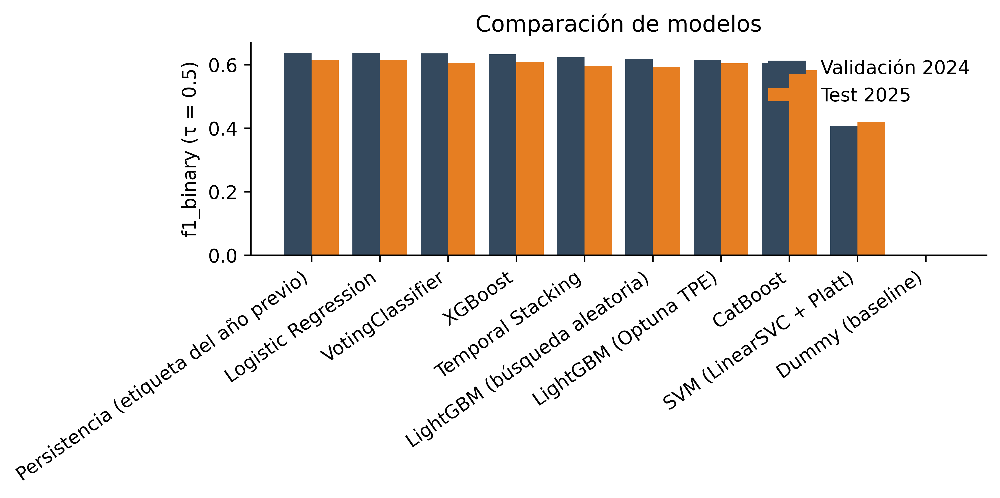

**Figura:** `10_roc_pr_test.png`

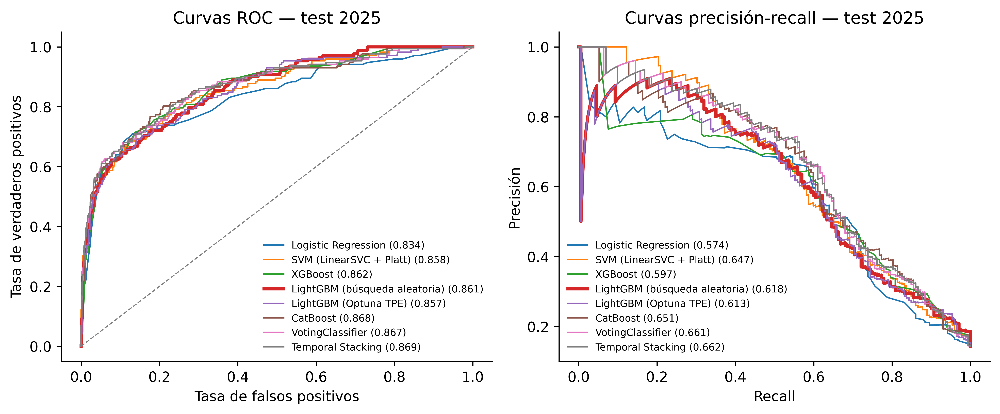

**Figura:** `10_matrices_confusion.png`

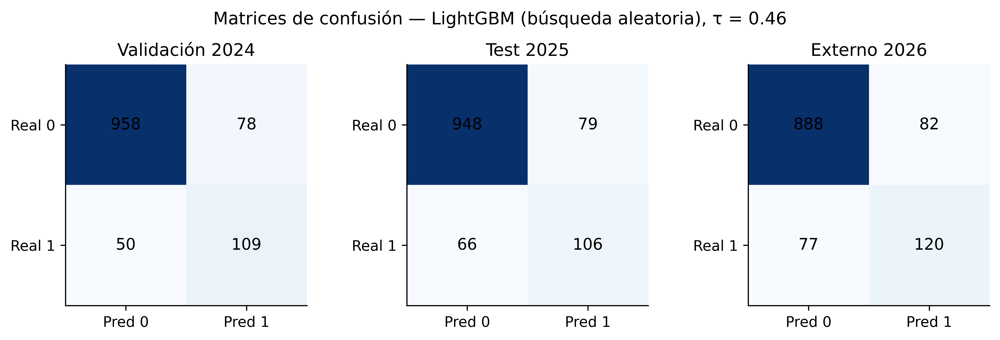

**Figura:** `11_walk_forward.png`

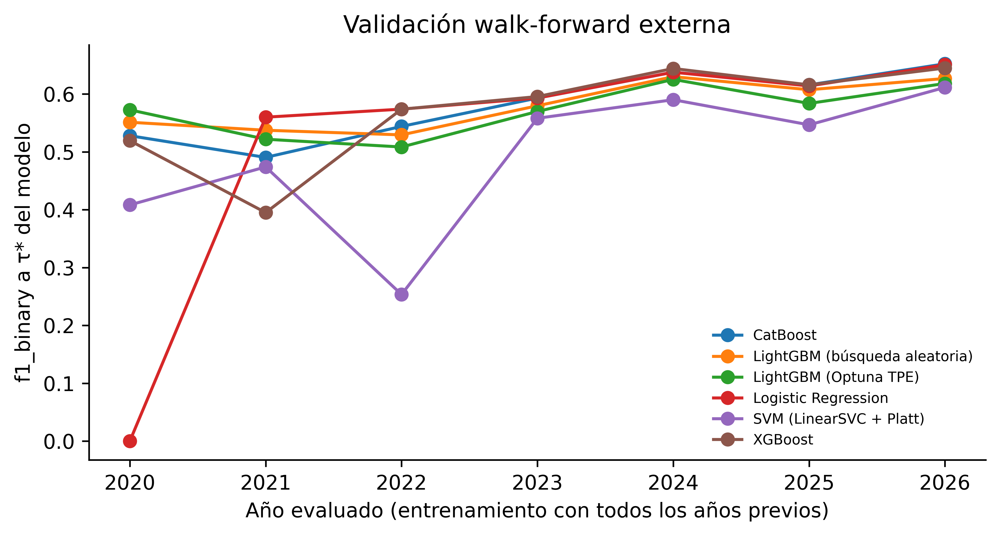

**Figura:** `12_diagrama_confiabilidad.png`

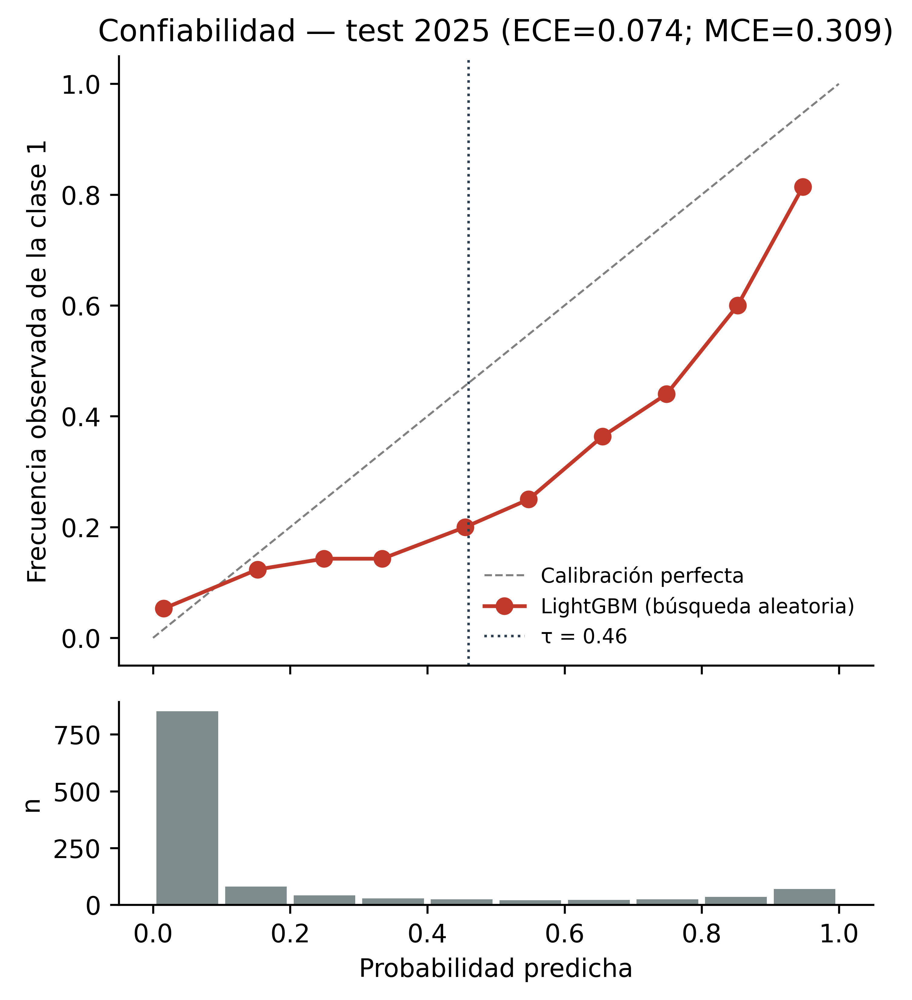

**Figura:** `13_psi_heatmap.png`

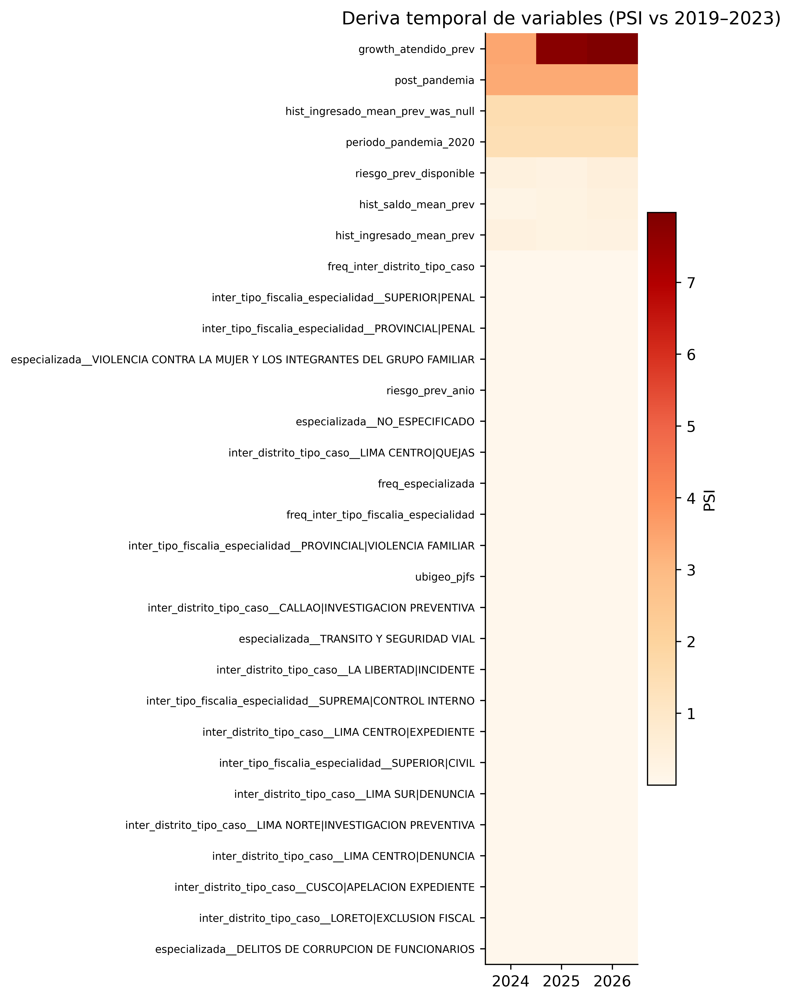

In [19]:
#@title 7b. EJECUTAR etapas 09–13 (comparación, evaluación final, walk-forward, calibración, PSI)
for _e in ["comparativa", "evaluacion_final", "walk_forward", "calibracion", "drift_psi"]:
    ejecutar_etapa(_e)

ver_tabla(T / "09_comparacion_modelos_tau05.csv", "Comparación de modelos a τ = 0,5 (Tabla 9) + CV temporal interna (Tabla 8)")
ver_tabla(T / "09_friedman.json", "Friedman sobre los pliegues temporales internos (6 modelos base)")
ver_tabla(T / "09_sensibilidad_regla_seleccion.csv", "Sensibilidad de la regla de selección (Tabla S14)")
print("Modelo final:", res("comparativa", "modelo_final"), "| τ* =", res("comparativa", "tau_final"),
      "| criterio:", res("comparativa", "criterio"))
ver_tabla(T / "10_desempeno_modelo_final.csv", "Desempeño del modelo final (Tabla 10)", max_filas=30)
ver_tabla(T / "10_ic_bootstrap.csv", "IC 95 % bootstrap", max_filas=40)
ver_tabla(T / "10_umbrales_alternativos_y_costos.csv", "Umbrales alternativos y costos (Tabla 12)")
ver_tabla(T / "10_delong.csv", "Prueba de DeLong: modelo final frente al resto")
ver_tabla(T / "11_walk_forward_resumen.csv", "Walk-forward externo 2020–2026")
ver_tabla(T / "12_calibracion_ece_mce.csv", "Calibración: ECE, MCE y Brier", max_filas=30)
ver_tabla(T / "13_psi_drift.csv", "Deriva temporal (PSI), 10 mayores", max_filas=10)
for _f in ["09_comparacion_modelos.png", "10_roc_pr_test.png", "10_matrices_confusion.png", "11_walk_forward.png",
           "12_diagrama_confiabilidad.png", "13_psi_heatmap.png"]:
    ver_figura(_f)

#### Lectura de resultados · evaluación
Las comparaciones, intervalos de confianza, pruebas estadísticas y métricas temporales se leen de los archivos generados por esta ejecución.


### Celda 8 · Definición de las etapas 14–16 (explicación y persistencia)
**Qué hace:** ablación por familias de variables (incluida la del rezago de la etiqueta), importancia por permutación, SHAP global, interacciones SHAP, contrafactuales y la comparación con la línea base de persistencia: transiciones, combinaciones sin historial y McNemar pareado.
**Por qué:** un revisor Q1 pregunta qué aporta cada grupo de variables, cómo decide el modelo y si supera a una regla trivial. La etapa de priorización mide lo que el modelo aporta como herramienta de ordenamiento frente a la persistencia.

In [20]:
#@title 8. Etapas 14–16: ablación, interpretabilidad (permutación, SHAP, contrafactuales), persistencia
TERRITORIALES = {"distrito_fiscal", "ubigeo_pjfs", "dpto_pjfs", "prov_pjfs", "dist_pjfs", "inter_distrito_tipo_caso"}
INSTITUCIONALES = {"tipo_fiscalia", "materia", "especialidad", "tipo_caso", "especializada", "inter_materia_tipo_fiscalia",
                   "inter_tipo_fiscalia_especialidad"}


def base_de_feature(f: str) -> str:
    b = f[5:] if f.startswith("freq_") else f.split("__")[0]
    return b[: -len("_was_null")] if b.endswith("_was_null") else b


def familias_de_feature(f: str) -> set:
    b = base_de_feature(f)
    fam = set()
    if f.startswith("freq_"):
        fam.add("frecuencia")
    if b.startswith("inter_"):
        fam.add("interaccion")
    if b.startswith("growth_"):
        fam.update({"historica_crecimiento", "historica"})
    if b.startswith("hist_"):
        fam.add("historica")
    if b in ("post_pandemia", "periodo_pandemia_2020"):
        fam.add("temporal")
    if b in TERRITORIALES:
        fam.add("territorial")
    if b in INSTITUCIONALES:
        fam.add("institucional")
    if f.endswith("_was_null"):
        fam.add("indicador_nulo")
    if b.startswith("riesgo_prev"):
        fam.add("rezago_etiqueta")
    return fam or {"otra"}


def modelo_base_para_analisis() -> str:
    final = res("comparativa", "modelo_final")
    if final in res("train", "base"):
        return final
    ranking = [r["modelo"] for r in res("comparativa", "ranking") if r["modelo"] in res("train", "base")]
    log(f"[aviso] el modelo final '{final}' es un ensamble; ablación/SHAP usan el mejor modelo base '{ranking[0]}'")
    return ranking[0]


@etapa("ablacion", "6.3 Ablation study (familias de variables)", deps=["train", "comparativa"], cfg=["evaluacion.seleccion"])
def etapa_ablacion():
    Xs, y, M, _ = matrices_escaladas()
    modelo = modelo_base_para_analisis()
    params = res("train", "best_params")[modelo]
    tau = float(res("train", "tau_star")[modelo])
    sg = int(CONFIG["training"]["seeds"]["global"])
    feats = list(Xs["train_full"].columns)
    variantes = [("Modelo completo", None), ("Sin crecimiento histórico", "historica_crecimiento"),
                 ("Sin variables históricas (hist_ + growth_)", "historica"), ("Sin codificación de frecuencia", "frecuencia"),
                 ("Sin interacciones", "interaccion"), ("Sin territoriales", "territorial"),
                 ("Sin institucionales", "institucional"), ("Sin temporales (pandemia)", "temporal"),
                 ("Sin indicadores de nulo", "indicador_nulo"), ("Sin rezago de la etiqueta", "rezago_etiqueta")]
    fam_por_feature = {f: familias_de_feature(f) for f in feats}
    filas = []
    for etiqueta, familia in variantes:
        cols = feats if familia is None else [f for f in feats if familia not in fam_por_feature[f]]
        if familia is not None and (len(cols) == len(feats) or not cols):
            continue
        est = ajustar(construir_estimador(modelo, params, sg, y["train_full"]), Xs["train_full"][cols], y["train_full"])
        p = proba_positiva(est, Xs["test"][cols])
        m05 = metricas_binarias(y["test"], p, 0.5)
        mt = metricas_binarias(y["test"], p, tau)
        filas.append({"variante": etiqueta, "familia_removida": familia or "—", "n_vars": len(cols),
                      "f1_binary_05": m05["f1_binary"], "f1_macro_05": m05["f1_macro"], "recall_05": m05["recall"],
                      "precision_05": m05["precision"], "roc_auc": m05["roc_auc"], "pr_auc": m05["pr_auc"],
                      "f1_binary_tau": mt["f1_binary"], "f1_macro_tau": mt["f1_macro"]})
        log(f"[abl] {etiqueta:<45} vars={len(cols):>3} F1b@0.5={m05['f1_binary']:.3f} ROC={m05['roc_auc']:.3f}")
    tabla = pd.DataFrame(filas)
    completo = tabla.iloc[0]
    for c in ("f1_binary_05", "roc_auc", "pr_auc"):
        tabla[f"delta_{c}"] = tabla[c] - completo[c]
    t1 = escribir_csv(tabla, TABLES_DIR / "14_ablacion.csv")
    t2 = escribir_csv(pd.DataFrame([{"feature": f, "familias": ", ".join(sorted(fam_por_feature[f]))} for f in feats]),
                      TABLES_DIR / "14_familias_de_variables.csv")
    return {"artifacts": {"tabla": t1, "familias": t2}, "resumen": {"modelo": modelo, "filas": tabla.to_dict(orient="records")}}


def _normalizar_shap(valores, n_features):
    if isinstance(valores, list):
        valores = valores[-1]
    valores = np.asarray(valores)
    if valores.ndim == 3 and valores.shape[-1] == 2 and valores.shape[1] == n_features:
        valores = valores[:, :, 1]
    return valores


def _normalizar_interacciones(valores, n_features):
    if isinstance(valores, list):
        valores = valores[-1]
    valores = np.asarray(valores)
    if valores.ndim == 4:
        valores = valores[..., 1]
    return valores


@etapa("interpretabilidad", "6.4 / 7.1 Feature importance e interpretabilidad (SHAP)", deps=["train", "comparativa"],
       cfg=["interpretabilidad", "evaluacion.seleccion"])
def etapa_interpretabilidad():
    import shap
    from sklearn.inspection import permutation_importance

    ic = CONFIG["interpretabilidad"]
    X, y, M = cargar_gold()
    Xs, _, _, escalador = matrices_escaladas()
    modelo = modelo_base_para_analisis()
    est = leer_pickle(MODELS_DIR / f"train_{modelo}.pkl")
    tau = float(res("train", "tau_star")[modelo])
    feats = list(Xs["test"].columns)
    nf = len(feats)
    rng = np.random.default_rng(SEMILLA)
    arts = {}

    pim = permutation_importance(est, Xs["test"].to_numpy(float), y["test"], scoring=ic["perm_scoring"],
                                 n_repeats=int(ic["perm_repeats"]), random_state=SEMILLA, n_jobs=1)
    tab_perm = pd.DataFrame({"feature": feats, "importancia_media": pim.importances_mean, "importancia_sd": pim.importances_std})
    tab_perm = tab_perm.sort_values("importancia_media", ascending=False)
    arts["permutacion"] = escribir_csv(tab_perm, TABLES_DIR / "15_importancia_permutacion.csv")

    n_sh = min(len(Xs["test"]), int(ic["shap_max_filas"]))
    idx = np.sort(rng.choice(len(Xs["test"]), n_sh, replace=False)) if n_sh < len(Xs["test"]) else np.arange(n_sh)
    Xsh = Xs["test"].to_numpy(float)[idx]
    Xsh_orig = X["test"].to_numpy(float)[idx]
    nombre_clase = type(est).__name__
    es_arbol = nombre_clase in ("LGBMClassifier", "XGBClassifier", "CatBoostClassifier")
    explicador = None
    if es_arbol:
        explicador = shap.TreeExplainer(est)
        sv = _normalizar_shap(explicador.shap_values(Xsh), nf)
        tipo = "TreeExplainer"
    elif nombre_clase == "LogisticRegression":
        fondo = Xs["train_full"].to_numpy(float)[rng.choice(len(Xs["train_full"]), min(500, len(Xs["train_full"])), replace=False)]
        sv = _normalizar_shap(shap.LinearExplainer(est, fondo).shap_values(Xsh), nf)
        tipo = "LinearExplainer"
    else:
        fondo = Xs["train_full"].to_numpy(float)[rng.choice(len(Xs["train_full"]), min(100, len(Xs["train_full"])), replace=False)]
        Xsh, Xsh_orig = Xsh[:200], Xsh_orig[:200]
        sv = shap.Explainer(lambda z: proba_positiva(est, z), shap.maskers.Independent(fondo))(Xsh).values
        tipo = "PermutationExplainer (proba)"
    abs_media = np.abs(sv).mean(axis=0)
    tab_shap = pd.DataFrame({"feature": feats, "shap_abs_medio": abs_media,
                             "familias": [", ".join(sorted(familias_de_feature(f))) for f in feats]})
    tab_shap = tab_shap.sort_values("shap_abs_medio", ascending=False).reset_index(drop=True)
    total = float(tab_shap["shap_abs_medio"].sum()) or 1.0
    tab_shap["pct_senal"] = tab_shap["shap_abs_medio"] / total * 100
    tab_shap["pct_acumulado"] = tab_shap["pct_senal"].cumsum()
    top5 = float(tab_shap["pct_senal"].head(5).sum())
    n_bottom = max(0, min(50, nf - 5))
    bottom = float(tab_shap["pct_senal"].tail(n_bottom).sum()) if n_bottom else 0.0
    por_familia = {}
    for fila in tab_shap.itertuples():
        for fam in fila.familias.split(", "):
            por_familia[fam] = por_familia.get(fam, 0.0) + fila.pct_senal
    arts["shap_global"] = escribir_csv(tab_shap, TABLES_DIR / "15_shap_global.csv")
    arts["shap_familias"] = escribir_csv(pd.DataFrame([{"familia": k, "pct_senal_shap": v} for k, v in
                                                       sorted(por_familia.items(), key=lambda kv: -kv[1])]),
                                         TABLES_DIR / "15_shap_por_familia.csv")
    rho_rank = float(stats.spearmanr(tab_shap.set_index("feature").loc[feats, "shap_abs_medio"],
                                     tab_perm.set_index("feature").loc[feats, "importancia_media"])[0])
    log(f"[shap] {tipo} sobre {len(Xsh)} filas de test | top-5 = {top5:.1f}% de la señal | "
        f"{n_bottom} menos influyentes = {bottom:.1f}% | Spearman(SHAP, permutación) = {rho_rank:.3f}")

    k = min(int(ic["top_k_grafico"]), nf)
    top = tab_shap.head(k).iloc[::-1]
    fig, ax = plt.subplots(figsize=(6.5, 0.3 * k + 1.2))
    ax.barh(top["feature"], top["shap_abs_medio"], color="#2c3e50")
    ax.set_xlabel("media(|SHAP|) — contribución al log-odds/probabilidad de riesgo")
    ax.set_title(f"Importancia global SHAP — {NOMBRES_MODELOS.get(modelo, modelo)} (test 2025)")
    ax.tick_params(axis="y", labelsize=7)
    arts["fig_shap_bar"] = guardar_figura(fig, "15_shap_global.png")
    try:
        plt.figure()
        shap.summary_plot(sv, Xsh_orig, feature_names=feats, max_display=k, show=False)
        arts["fig_shap_beeswarm"] = guardar_figura(plt.gcf(), "15_shap_beeswarm.png")
    except Exception as exc:
        log(f"[aviso] beeswarm no disponible: {exc}")

    pares = pd.DataFrame()
    if es_arbol:
        try:
            n_int = min(len(Xsh), int(ic["interacciones_max_filas"]))
            iv = _normalizar_interacciones(explicador.shap_interaction_values(Xsh[:n_int]), nf)
            media_abs = np.abs(iv).mean(axis=0)
            filas_p = [{"feature_i": feats[i], "feature_j": feats[j], "interaccion_abs_media": float(media_abs[i, j]),
                        "interaccion_abs_media_x2": float(media_abs[i, j] + media_abs[j, i])}
                       for i in range(nf) for j in range(i + 1, nf)]
            pares = pd.DataFrame(filas_p).sort_values("interaccion_abs_media", ascending=False).reset_index(drop=True)
            arts["interacciones"] = escribir_csv(pares.head(50), TABLES_DIR / "15_shap_interacciones_top50.csv")
            log(f"[shap] interacción principal: {pares.iloc[0].feature_i} × {pares.iloc[0].feature_j} "
                f"(media |φij| = {pares.iloc[0].interaccion_abs_media:.4f})")
        except Exception as exc:
            log(f"[aviso] valores de interacción SHAP no disponibles para {nombre_clase}: {exc}")

    def grafico_dependencia(fi, fj, archivo):
        i, j = feats.index(fi), feats.index(fj)
        fig, ax = plt.subplots(figsize=(5.8, 4.2))
        sc = ax.scatter(Xsh_orig[:, i], sv[:, i], c=Xsh_orig[:, j], cmap="viridis", s=10, alpha=0.8)
        fig.colorbar(sc, ax=ax, label=fj)
        ax.axhline(0, c="grey", lw=0.6)
        ax.set_xlabel(f"{fi} (escala original)")
        ax.tick_params(axis="x", rotation=30)
        ax.set_ylabel(f"SHAP de {fi}")
        ax.set_title("Dependencia SHAP e interacción")
        return guardar_figura(fig, archivo)

    if len(pares):
        p0 = pares.iloc[0]
        fi, fj = (p0.feature_i, p0.feature_j)
        if tab_shap.set_index("feature").loc[fj, "shap_abs_medio"] > tab_shap.set_index("feature").loc[fi, "shap_abs_medio"]:
            fi, fj = fj, fi
        arts["fig_dependencia_top"] = grafico_dependencia(fi, fj, "15_shap_dependencia_top_interaccion.png")
    if "freq_inter_distrito_tipo_caso" in feats and "ubigeo_pjfs" in feats:
        arts["fig_dependencia_articulo"] = grafico_dependencia("freq_inter_distrito_tipo_caso", "ubigeo_pjfs",
                                                               "15_shap_freq_inter_distrito_tipo_caso_x_ubigeo.png")

    # Contrafactuales controlados: cambiar UNA variable (respetando grupos one-hot) y ver si cruza τ.
    Xt = X["test"].to_numpy(float)
    p_test = proba_positiva(est, escalador.transform(Xt))
    ventana = float(ic["contrafactual_ventana"])
    cerca = np.flatnonzero(np.abs(p_test - tau) <= ventana)
    cerca = cerca[np.argsort(np.abs(p_test[cerca] - tau))][: int(ic["contrafactual_max_casos"])]
    Xtf = X["train_full"].to_numpy(float)
    grupos = {}
    for jx, f in enumerate(feats):
        if "__" in f and not f.startswith("freq_"):
            grupos.setdefault(f.split("__")[0], []).append(jx)
    binarias = [jx for jx in range(nf) if set(np.unique(Xtf[:, jx])).issubset({0.0, 1.0})]
    cuantiles = {jx: np.unique(np.quantile(Xtf[:, jx], ic["contrafactual_cuantiles"])) for jx in range(nf)}
    grupo_de = {jx: g for g, cols in grupos.items() for jx in cols}
    filas_cf, conteo_feat = [], {}
    for i in cerca:
        fila = Xt[i]
        lado = p_test[i] >= tau
        cambios, etiquetas = [], []
        for jx in range(nf):
            if jx in grupo_de:
                if fila[jx] == 1.0:
                    continue
                nueva = fila.copy()
                nueva[grupos[grupo_de[jx]]] = 0.0
                nueva[jx] = 1.0
                cambios.append(nueva)
                etiquetas.append(feats[jx])
            elif jx in binarias:
                nueva = fila.copy()
                nueva[jx] = 1.0 - fila[jx]
                cambios.append(nueva)
                etiquetas.append(feats[jx])
            else:
                for v in cuantiles[jx]:
                    if v == fila[jx]:
                        continue
                    nueva = fila.copy()
                    nueva[jx] = v
                    cambios.append(nueva)
                    etiquetas.append(feats[jx])
        if not cambios:
            continue
        p_new = proba_positiva(est, escalador.transform(np.vstack(cambios)))
        cruzan = sorted({etiquetas[c] for c in range(len(cambios)) if (p_new[c] >= tau) != lado})
        for f in cruzan:
            conteo_feat[f] = conteo_feat.get(f, 0) + 1
        filas_cf.append({"fila_test": int(i), "proba": float(p_test[i]), "prediccion": int(lado), "y_real": int(y["test"][i]),
                         "n_variables_que_cruzan": len(cruzan), "variables_que_cruzan": "; ".join(cruzan)})
    tab_cf = pd.DataFrame(filas_cf)
    tab_cf_feat = pd.DataFrame([{"feature": f, "casos_que_cruzan": n, "familias": ", ".join(sorted(familias_de_feature(f)))}
                                for f, n in sorted(conteo_feat.items(), key=lambda kv: -kv[1])])
    arts["contrafactual_casos"] = escribir_csv(tab_cf, TABLES_DIR / "15_contrafactuales_casos.csv")
    arts["contrafactual_features"] = escribir_csv(tab_cf_feat, TABLES_DIR / "15_contrafactuales_por_variable.csv")
    pct_cf = float((tab_cf["n_variables_que_cruzan"] > 0).mean() * 100) if len(tab_cf) else float("nan")
    log(f"[cf] {len(tab_cf)} casos a ±{ventana} de τ: {pct_cf:.1f}% cruzan el umbral cambiando una sola variable")
    return {"artifacts": arts,
            "resumen": {"modelo": modelo, "explicador": tipo, "top5_pct": top5, "bottom_pct": bottom, "n_bottom": n_bottom,
                        "spearman_shap_perm": rho_rank, "top10_shap": tab_shap.head(10)["feature"].tolist(),
                        "top10_perm": tab_perm.head(10)["feature"].tolist(),
                        "interaccion_top": pares.head(1).to_dict(orient="records"), "contrafactual_pct": pct_cf,
                        "shap_por_familia": por_familia}}


@etapa("persistencia", "8 Limitations: línea base de persistencia (etiqueta del año previo)", deps=["train", "comparativa"],
       cfg=["data.columnas_clave"])
def etapa_persistencia():
    """Compara el modelo final con la regla «repetir la etiqueta del año previo» de la misma combinación.

    Subconjuntos: todas las filas; combinaciones con historial; transiciones (la etiqueta cambia respecto del año
    previo, donde la persistencia falla por construcción); combinaciones sin historial. Incluye McNemar pareado.
    """
    X, y, M = cargar_gold()
    claves = [c for c in CONFIG["data"]["columnas_clave"] if c in M["test"].columns]
    final = res("comparativa", "modelo_final")
    tau = float(res("comparativa", "tau_final"))
    filas, pruebas = [], []
    for previo, actual, etiqueta in (("calib", "test", "2024 → 2025"), ("test", "external", "2025 → 2026")):
        prev = M[previo][claves].copy()
        prev["y_prev"] = y[previo]
        prev = prev.groupby(claves, dropna=False)["y_prev"].max().reset_index()
        cur = M[actual][claves].copy()
        cur["y"] = y[actual]
        cur["proba_modelo"] = leer_predicciones(final, actual)["y_proba"].to_numpy()
        cur = cur.merge(prev, on=claves, how="left")
        cubierto = cur["y_prev"].notna().to_numpy()
        y_hat = cur["y_prev"].fillna(0).astype(int).to_numpy()
        yt_all = cur["y"].to_numpy()
        pred_modelo = (cur["proba_modelo"].to_numpy() >= tau).astype(int)
        transicion = cubierto & (y_hat != yt_all)
        subconjuntos = (("todas las filas", np.ones(len(cur), bool)),
                        ("con historial (combinación vista el año previo)", cubierto),
                        ("transiciones (la etiqueta cambia respecto del año previo)", transicion),
                        ("sin historial (combinación nueva)", ~cubierto))
        for subconjunto, mask in subconjuntos:
            yt = yt_all[mask]
            if mask.sum() == 0:
                continue
            filas.append({"transicion": etiqueta, "subconjunto": subconjunto, "n": int(mask.sum()),
                          "positivos": int(yt.sum()), "cobertura_pct": float(cubierto.mean() * 100),
                          "persistencia_exactitud": float((y_hat[mask] == yt).mean()),
                          "persistencia_f1_binary": float(f1_score(yt, y_hat[mask], zero_division=0)),
                          "persistencia_precision": float(precision_score(yt, y_hat[mask], zero_division=0)),
                          "persistencia_recall": float(recall_score(yt, y_hat[mask], zero_division=0)),
                          "modelo_exactitud": float((pred_modelo[mask] == yt).mean()),
                          "modelo_f1_binary": float(f1_score(yt, pred_modelo[mask], zero_division=0)),
                          "modelo_precision": float(precision_score(yt, pred_modelo[mask], zero_division=0)),
                          "modelo_recall": float(recall_score(yt, pred_modelo[mask], zero_division=0)),
                          "modelo_roc_auc": float(roc_auc_score(yt, cur["proba_modelo"].to_numpy()[mask]))
                          if len(np.unique(yt)) > 1 else float("nan")})
        # McNemar pareado (con corrección de continuidad) sobre las filas con historial.
        ok_m = pred_modelo[cubierto] == yt_all[cubierto]
        ok_p = y_hat[cubierto] == yt_all[cubierto]
        b = int((ok_m & ~ok_p).sum())
        c = int((~ok_m & ok_p).sum())
        chi2_mc = float((abs(b - c) - 1) ** 2 / (b + c)) if (b + c) else 0.0
        pruebas.append({"transicion": etiqueta, "modelo_acierta_persistencia_falla": b,
                        "persistencia_acierta_modelo_falla": c, "chi2_mcnemar": chi2_mc,
                        "p_value": float(stats.chi2.sf(chi2_mc, 1)) if (b + c) else 1.0})
    tabla = pd.DataFrame(filas)
    t1 = escribir_csv(tabla, TABLES_DIR / "16_linea_base_persistencia.csv")
    t2 = escribir_csv(pd.DataFrame(pruebas), TABLES_DIR / "16_mcnemar_modelo_vs_persistencia.csv")
    r = tabla.iloc[0]
    tr = tabla[(tabla["transicion"] == "2024 → 2025") & tabla["subconjunto"].str.startswith("transiciones")]
    log(f"[persist] 2024→2025: persistencia F1b={r.persistencia_f1_binary:.3f} vs modelo F1b={r.modelo_f1_binary:.3f} "
        f"(cobertura {r.cobertura_pct:.1f}%); McNemar p={pruebas[0]['p_value']:.4f}"
        + (f"; transiciones: modelo acierta {tr.iloc[0].modelo_exactitud * 100:.1f}% (persistencia 0%)" if len(tr) else ""))
    return {"artifacts": {"tabla": t1, "mcnemar": t2},
            "resumen": {"filas": tabla.to_dict(orient="records"), "mcnemar": pruebas, "claves": claves}}

def _captura_esperada(y, puntaje, k: int) -> float:
    """Positivos esperados entre los k primeros al ordenar por puntaje, con empates resueltos al azar (valor esperado).

    Para un puntaje continuo coincide con el conteo exacto; para la persistencia (0/1) evita favorecerla o
    perjudicarla por el orden arbitrario de las filas empatadas.
    """
    y = np.asarray(y, int)
    s_ = np.asarray(puntaje, float)
    restantes, esperado = int(k), 0.0
    for v in np.sort(np.unique(s_))[::-1]:
        if restantes <= 0:
            break
        grupo = s_ == v
        tomar = min(restantes, int(grupo.sum()))
        esperado += tomar * y[grupo].mean()
        restantes -= tomar
    return float(esperado)


@etapa("priorizacion", "6.3 Priorización: captura top-k y diferencias pareadas frente a la persistencia",
       deps=["train", "comparativa", "persistencia"], cfg=["priorizacion", "evaluacion.seleccion"])
def etapa_priorizacion():
    """Evalúa el modelo final como herramienta de priorización frente a la persistencia y al azar.

    1) Captura top-k: % de combinaciones de riesgo halladas al revisar primero el k % con mayor puntaje.
    2) Bootstrap pareado de ROC-AUC y PR-AUC (modelo − persistencia) con IC 95 %.
    3) DeLong modelo frente a persistencia.
    """
    X, y, M = cargar_gold()
    final = res("comparativa", "modelo_final")
    pz = CONFIG["priorizacion"]
    rng = np.random.default_rng(SEMILLA)
    filas_k, filas_d, curvas = [], [], {}
    for bloque, etiqueta in (("test", "Prueba 2025"), ("external", ETIQ_EXT)):
        yt = np.asarray(y[bloque]).astype(int)
        p_mod = leer_predicciones(final, bloque)["y_proba"].to_numpy()
        p_per = (X[bloque]["riesgo_prev_anio"].to_numpy() > 0.5).astype(float)
        n, pos = len(yt), int(yt.sum())
        for k_pct in pz["top_k_pct"]:
            k = int(round(n * k_pct / 100))
            cm, cp = _captura_esperada(yt, p_mod, k), _captura_esperada(yt, p_per, k)
            filas_k.append({"bloque": etiqueta, "top_k_pct": k_pct, "k_filas": k, "positivos_totales": pos,
                            "modelo_capturados": cm, "persistencia_capturados": cp, "azar_capturados": k * pos / n,
                            "modelo_recall_at_k": cm / pos, "persistencia_recall_at_k": cp / pos, "azar_recall_at_k": k / n,
                            "modelo_precision_at_k": cm / k if k else float("nan"),
                            "persistencia_precision_at_k": cp / k if k else float("nan"),
                            "modelo_lift": (cm / k) / (pos / n) if k else float("nan")})
        grid = np.arange(0, 101)
        curvas[etiqueta] = {"x": grid,
                            "modelo": [_captura_esperada(yt, p_mod, int(round(n * g / 100))) / pos for g in grid],
                            "persistencia": [_captura_esperada(yt, p_per, int(round(n * g / 100))) / pos for g in grid]}
        dif = {"roc_auc": [], "pr_auc": []}
        for _ in range(int(pz["n_bootstrap"])):
            idx = rng.integers(0, n, n)
            if len(np.unique(yt[idx])) < 2:
                continue
            dif["roc_auc"].append(roc_auc_score(yt[idx], p_mod[idx]) - roc_auc_score(yt[idx], p_per[idx]))
            dif["pr_auc"].append(average_precision_score(yt[idx], p_mod[idx]) - average_precision_score(yt[idx], p_per[idx]))
        dl = delong(yt, p_mod, p_per)
        for met, fn in (("roc_auc", roc_auc_score), ("pr_auc", average_precision_score)):
            v = np.asarray(dif[met])
            filas_d.append({"bloque": etiqueta, "metrica": met, "modelo": fn(yt, p_mod), "persistencia": fn(yt, p_per),
                            "diferencia": fn(yt, p_mod) - fn(yt, p_per), "ic_inf": float(np.percentile(v, 2.5)),
                            "ic_sup": float(np.percentile(v, 97.5)), "p_bootstrap_unilateral": float((v <= 0).mean()),
                            "n_boot_validos": int(len(v)),
                            "delong_z": dl["z"] if met == "roc_auc" else float("nan"),
                            "delong_p": dl["p_value"] if met == "roc_auc" else float("nan")})
    tk, td = pd.DataFrame(filas_k), pd.DataFrame(filas_d)
    t1 = escribir_csv(tk, TABLES_DIR / "16d_priorizacion_topk.csv")
    t2 = escribir_csv(td, TABLES_DIR / "16d_diferencias_vs_persistencia.csv")
    fig, axes = plt.subplots(1, len(curvas), figsize=(10, 3.8), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (etq, c) in zip(axes, curvas.items()):
        ax.plot(c["x"], np.asarray(c["modelo"]) * 100, color="#1f4e79", lw=2, label=NOMBRES_MODELOS.get(final, final))
        ax.plot(c["x"], np.asarray(c["persistencia"]) * 100, color="#c0504d", lw=2, ls="--", label="Persistencia")
        ax.plot(c["x"], c["x"], color="#7f7f7f", lw=1, ls=":", label="Azar")
        ax.set_title(etq)
        ax.set_xlabel("% de combinaciones revisadas (orden por puntaje)")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("% de combinaciones de riesgo capturadas")
    axes[0].legend(frameon=False, loc="lower right")
    f1 = guardar_figura(fig, "16d_curva_ganancia_priorizacion.png")
    r10 = tk[(tk["bloque"] == "Prueba 2025") & (tk["top_k_pct"] == 10)]
    if len(r10):
        log(f"[prior] prueba 2025, top 10 %: modelo captura {r10.iloc[0].modelo_recall_at_k * 100:.1f} % de los positivos; "
            f"persistencia {r10.iloc[0].persistencia_recall_at_k * 100:.1f} %; azar 10,0 %")
    for r in td.itertuples():
        log(f"[prior] {r.bloque} {r.metrica}: Δ = {r.diferencia:+.3f} (IC 95 % {r.ic_inf:+.3f} a {r.ic_sup:+.3f})")
    return {"artifacts": {"topk": t1, "diferencias": t2, "figura": f1},
            "resumen": {"topk": tk.to_dict(orient="records"), "diferencias": td.to_dict(orient="records")}}

def _rezago_escenario(df: pd.DataFrame, train_years, alto: float, bajo: float) -> pd.DataFrame:
    """Igual que agregar_rezago_etiqueta pero con los percentiles de un escenario alternativo."""
    claves = [c for c in CONFIG["data"]["columnas_clave"] if c in df.columns]
    etiquetado, _, _, _, _ = construir_target(df, train_years, alto, bajo)
    anual = (etiquetado.groupby(claves + ["anio"], dropna=False)[TARGET].max().reset_index()
             .rename(columns={TARGET: "_rezago"}))
    anual["anio"] = anual["anio"] + 1
    base = df.drop(columns=[c for c in ("riesgo_prev_anio", "riesgo_prev_disponible") if c in df.columns])
    out = base.merge(anual, on=claves + ["anio"], how="left")
    out["riesgo_prev_anio"] = out["_rezago"].fillna(0).astype(int)
    return out.drop(columns="_rezago")


@etapa("robustez_target", "6.5 Robustez de las conclusiones a la definición del target proxy",
       deps=["train", "comparativa", "persistencia", "interpretabilidad", "split"],
       cfg=["data.target", "robustez_target", "split", "evaluacion.seleccion"])
def etapa_robustez_target():
    """¿Se mantienen las conclusiones si el target se define con otros percentiles?

    Para cada escenario: (1) acuerdo de etiquetas con el primario (kappa de Cohen, Jaccard de positivos);
    (2) LightGBM reajustado (mismas variables e hiperparámetros) → F1(τ*), ROC-AUC, PR-AUC y PR-AUC/prevalencia;
    (3) persistencia del mismo escenario y diferencia pareada de PR-AUC con IC 95 %; (4) captura en el top-k %;
    (5) estabilidad de SHAP frente al primario (Spearman de la importancia y solapamiento del top-k).
    Además, diagnóstico de la construcción del target primario en entrenamiento.
    """
    import shap

    rc = CONFIG["robustez_target"]
    sp = CONFIG["split"]
    df = pd.read_parquet(art("preprocessing", "processed"))
    # Línea base de volumen: casos ingresados de la misma combinación en el año previo (disponible al predecir).
    claves = [c for c in CONFIG["data"]["columnas_clave"] if c in df.columns]
    vol = (df.groupby(claves + ["anio"], dropna=False)["ingresado"].sum().reset_index()
           .rename(columns={"ingresado": "_ingresado_prev"}))
    vol["anio"] = vol["anio"] + 1
    df = df.merge(vol, on=claves + ["anio"], how="left")
    df["_ingresado_prev"] = df["_ingresado_prev"].fillna(0.0)
    X, y_prim, M = cargar_gold()
    escalador = leer_pickle(art("train", "scaler"))
    modelo = modelo_base_para_analisis()
    params = res("train", "best_params")[modelo]
    sg = int(CONFIG["training"]["seeds"]["global"])
    feats = list(X["train_full"].columns)
    if "riesgo_prev_anio" not in feats:
        raise RuntimeError("robustez_target requiere la variable riesgo_prev_anio en el conjunto final")
    i_lag = feats.index("riesgo_prev_anio")
    bloques = {"train_full": list(sp["train_years"]), "calib": [sp["calib_valid_year"]], "test": [sp["test_year"]],
               "external": [sp["external_year"]]}
    primario = CONFIG["data"]["target"]["primario"]
    escenarios = sorted([primario] + CONFIG["data"]["target"]["sensibilidad"], key=lambda e: e[0])
    filas, acuerdo, shap_rank = [], [], {}
    etiquetas_prim = {}
    for alto, bajo in escenarios:
        esc = f"P{alto}/P{bajo}"
        con_lag = _rezago_escenario(df, sp["train_years"], alto, bajo)
        frame, y_all, q_a, q_b, prev_tr = construir_target(con_lag, sp["train_years"], alto, bajo)
        frame = frame.reset_index(drop=True)
        y_all = np.asarray(y_all).ravel()
        yb, Xb = {}, {}
        for b, anios in bloques.items():
            mask = frame["anio"].isin(anios).to_numpy()
            if int(mask.sum()) != len(X[b]):
                raise RuntimeError(f"[{esc}] el bloque {b} no coincide con gold ({int(mask.sum())} vs {len(X[b])})")
            yb[b] = y_all[mask].astype(int)
            raw = X[b].to_numpy(float).copy()
            raw[:, i_lag] = frame.loc[mask, "riesgo_prev_anio"].to_numpy(float)
            Xb[b] = pd.DataFrame(escalador.transform(raw), columns=feats)
        if [alto, bajo] == list(primario):
            for b in bloques:
                if not np.array_equal(yb[b], y_prim[b]):
                    raise RuntimeError(f"la etiqueta primaria recalculada difiere de gold en {b}")
            etiquetas_prim = yb
        est = ajustar(construir_estimador(modelo, params, sg, yb["train_full"]), Xb["train_full"], yb["train_full"])
        p = {b: proba_positiva(est, Xb[b]) for b in ("calib", "test", "external")}
        tau = tau_optimo(yb["calib"], p["calib"])
        # Mismo generador y mismo orden de remuestreo que la etapa de priorización: los índices bootstrap son comunes a
        # todos los escenarios y, en el escenario primario, el intervalo coincide con el de la comparación principal.
        rng = np.random.default_rng(SEMILLA)
        for b, etq in (("test", "Prueba 2025"), ("external", ETIQ_EXT)):
            yt = yb[b]
            prev = X[b]["riesgo_prev_anio"].to_numpy()  # solo para dimensión
            per = (frame.loc[frame["anio"].isin(bloques[b]).to_numpy(), "riesgo_prev_anio"].to_numpy(float) > 0.5).astype(float)
            mm = metricas_binarias(yt, p[b], tau)
            mp = metricas_binarias(yt, per, 0.5)
            vol_b = frame.loc[frame["anio"].isin(bloques[b]).to_numpy(), "_ingresado_prev"].to_numpy(float)
            n, pos = len(yt), int(yt.sum())
            difs = []
            if int(rc["n_bootstrap"]) != int(CONFIG["priorizacion"]["n_bootstrap"]):
                raise ValueError("robustez_target.n_bootstrap debe ser igual a priorizacion.n_bootstrap")
            for _ in range(int(rc["n_bootstrap"])):
                idx = rng.integers(0, n, n)
                if len(np.unique(yt[idx])) < 2:
                    continue
                difs.append(average_precision_score(yt[idx], p[b][idx]) - average_precision_score(yt[idx], per[idx]))
            difs = np.asarray(difs)
            k = int(round(n * rc["top_k_pct"] / 100))
            filas.append({"escenario": esc, "rol": "primario" if [alto, bajo] == list(primario) else "alternativo",
                          "bloque": etq, "q_saldo": q_a, "q_tasa": q_b, "prevalencia_train_pct": prev_tr * 100,
                          "prevalencia_pct": float(yt.mean() * 100), "n_positivos": pos, "tau": tau,
                          "modelo_f1": mm["f1_binary"], "modelo_roc_auc": mm["roc_auc"], "modelo_pr_auc": mm["pr_auc"],
                          "modelo_pr_auc_sobre_prevalencia": mm["pr_auc"] / max(yt.mean(), 1e-12),
                          "persistencia_f1": mp["f1_binary"], "persistencia_roc_auc": mp["roc_auc"],
                          "persistencia_pr_auc": mp["pr_auc"], "delta_pr_auc": mm["pr_auc"] - mp["pr_auc"],
                          "delta_pr_auc_ic_inf": float(np.percentile(difs, 2.5)),
                          "delta_pr_auc_ic_sup": float(np.percentile(difs, 97.5)),
                          "delta_roc_auc": mm["roc_auc"] - mp["roc_auc"],
                          "volumen_roc_auc": float(roc_auc_score(yt, vol_b)),
                          "volumen_pr_auc": float(average_precision_score(yt, vol_b)),
                          f"modelo_recall_top{rc['top_k_pct']}": _captura_esperada(yt, p[b], k) / max(pos, 1),
                          f"persistencia_recall_top{rc['top_k_pct']}": _captura_esperada(yt, per, k) / max(pos, 1)})
            del prev
        sv = _normalizar_shap(shap.TreeExplainer(est).shap_values(Xb["test"].to_numpy(float)), len(feats))
        shap_rank[esc] = pd.Series(np.abs(sv).mean(axis=0), index=feats)
        for b in ("train_full", "calib", "test", "external"):
            acuerdo.append({"escenario": esc, "bloque": b, "yb": yb[b]})
        log(f"[rob] {esc}: τ={tau:.2f} | " + " | ".join(
            f"{f['bloque']}: F1={f['modelo_f1']:.3f} PR={f['modelo_pr_auc']:.3f} vs pers {f['persistencia_pr_auc']:.3f}"
            for f in filas[-2:]))
    # Acuerdo de etiquetas con el escenario primario
    esc_prim = f"P{primario[0]}/P{primario[1]}"
    filas_ac = []
    for a in acuerdo:
        yp = etiquetas_prim[a["bloque"]]
        ya = a["yb"]
        inter = int(((ya == 1) & (yp == 1)).sum())
        union = int(((ya == 1) | (yp == 1)).sum())
        filas_ac.append({"escenario": a["escenario"], "bloque": a["bloque"], "n": len(ya),
                         "prevalencia_pct": float(ya.mean() * 100),
                         "kappa_vs_primario": float(cohen_kappa_score(yp, ya)),
                         "jaccard_positivos_vs_primario": inter / union if union else float("nan"),
                         "positivos_del_primario_incluidos_pct": inter / max(int(yp.sum()), 1) * 100})
    # Estabilidad de SHAP
    from scipy.stats import spearmanr

    ref = shap_rank[esc_prim]
    top_ref = set(ref.sort_values(ascending=False).head(int(rc["top_k_shap"])).index)
    filas_sh = []
    for esc, imp in shap_rank.items():
        top = imp.sort_values(ascending=False)
        filas_sh.append({"escenario": esc, "spearman_importancia_vs_primario": float(spearmanr(ref, imp).statistic),
                         f"top{rc['top_k_shap']}_compartidas": len(top_ref & set(top.head(int(rc['top_k_shap'])).index)),
                         "variable_principal": top.index[0],
                         "pct_senal_variable_principal": float(top.iloc[0] / top.sum() * 100)})
    # Diagnóstico de la construcción del target primario (solo años de entrenamiento)
    fr, _, q_a, q_b, _ = construir_target(df, sp["train_years"], *primario)
    trm = fr["anio"].isin(sp["train_years"]).to_numpy()
    ing = fr.loc[trm, "ingresado"].to_numpy(float)
    ate = fr.loc[trm, "atendido"].to_numpy(float)
    s_ = ing - ate
    t_ = np.where(ing > 0, ate / ing, 0.0)
    ytr = fr.loc[trm, TARGET].to_numpy(int)
    p_s, p_t = float((s_ >= q_a).mean()), float((t_ <= q_b).mean())
    cuartil = pd.qcut(pd.Series(ing).rank(method="first"), 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (mayor)"])
    prev_q = pd.Series(ytr).groupby(cuartil.to_numpy(), observed=False).mean() * 100
    diag = [{"indicador": "Umbral saldo (q alto, entrenamiento)", "valor": q_a},
            {"indicador": "Umbral tasa de atención (q bajo, entrenamiento)", "valor": q_b},
            {"indicador": "P(saldo ≥ umbral) en entrenamiento", "valor": p_s},
            {"indicador": "P(tasa ≤ umbral) en entrenamiento", "valor": p_t},
            {"indicador": "P(conjunta) observada", "valor": float(ytr.mean())},
            {"indicador": "P(conjunta) esperada si fueran independientes", "valor": p_s * p_t},
            {"indicador": "Spearman(saldo, tasa de atención)", "valor": float(spearmanr(s_, t_).statistic)},
            {"indicador": "Spearman(ingresado, saldo)", "valor": float(spearmanr(ing, s_).statistic)}]
    diag += [{"indicador": f"Prevalencia por cuartil de casos ingresados: {q}", "valor": float(v)}
             for q, v in prev_q.items()]
    t1 = escribir_csv(pd.DataFrame(filas), TABLES_DIR / "16e_robustez_target_modelo.csv")
    t2 = escribir_csv(pd.DataFrame(filas_ac), TABLES_DIR / "16e_acuerdo_etiquetas_escenarios.csv")
    t3 = escribir_csv(pd.DataFrame(filas_sh), TABLES_DIR / "16e_estabilidad_shap_escenarios.csv")
    t4 = escribir_csv(pd.DataFrame(diag), TABLES_DIR / "16e_diagnostico_target.csv")
    tb = pd.DataFrame(filas)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    for ax, (etq, g) in zip(axes, tb.groupby("bloque", sort=False)):
        xx = np.arange(len(g))
        ax.bar(xx - 0.2, g["modelo_pr_auc"], 0.4, color="#1f4e79", label=NOMBRES_MODELOS.get(modelo, modelo))
        ax.bar(xx + 0.2, g["persistencia_pr_auc"], 0.4, color="#c0504d", label="Persistencia")
        ax.scatter(xx, g["prevalencia_pct"] / 100, marker="_", s=400, color="black", label="Prevalencia (azar)")
        ax.set_xticks(xx)
        ax.set_xticklabels(g["escenario"])
        ax.set_title(etq)
        ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("PR-AUC")
    axes[0].legend(frameon=False, fontsize=8)
    f1 = guardar_figura(fig, "16e_robustez_target.png")
    for r in pd.DataFrame(filas_ac).query("bloque == 'test'").itertuples():
        log(f"[rob] etiquetas {r.escenario} vs {esc_prim} (2025): kappa={r.kappa_vs_primario:.3f} "
            f"Jaccard={r.jaccard_positivos_vs_primario:.3f}")
    log(f"[rob] diagnóstico: P(conjunta)={ytr.mean():.3f} vs independencia {p_s * p_t:.3f}; prevalencia por cuartil de "
        f"ingresados {[round(float(v), 1) for v in prev_q.values]}")
    return {"artifacts": {"modelo": t1, "acuerdo": t2, "shap": t3, "diagnostico": t4, "figura": f1},
            "resumen": {"filas": filas, "acuerdo": filas_ac, "shap": filas_sh, "diagnostico": diag}}

### Celda 8a · Definición de auditoría de fuga, diversidad y subgrupos
**Qué hace:** verifica que ninguna variable final derive de las columnas que definen el target, mide la correlación entre modelos (diversidad de los conjuntos), repite Friedman con los 5 miembros y evalúa el desempeño por subgrupo.
**Por qué:** respalda con números el control de fuga, la diversidad de los conjuntos y el número de positivos por subgrupo.

In [21]:
#@title 8a. Etapas 16b–16c: auditoría de fuga, correlación entre modelos base y desempeño por subgrupo
MOTIVOS_EXCLUSION = {
    "ingresado": "fuga (operando del target)", "atendido": "fuga (operando del target)",
    "saldo_casos": "fuga (derivada de ingresado − atendido)", "tasa_atencion": "fuga (derivada de atendido / ingresado)",
    "ratio_saldo": "fuga (derivada de saldo / ingresado)", "anio_centrado": "colineal con anio",
    "anio": "metadato (solo clave de partición)", "periodo": "metadato temporal", "fecha_descarga": "metadato temporal",
    "fecha_corte": "metadato temporal", "archivo_fuente": "metadato de consolidación",
}


def verificar_protocolo_temporal(X, y, M, feats, directas) -> pd.DataFrame:
    """Controles de fuga y de separación temporal recalculados con los datos guardados (no con la configuración).

    Cada fila indica el control, la evidencia numérica y si pasa. Una falla detiene la etapa."""
    sp = CONFIG["split"]
    filas = []

    def ctrl(control, evidencia, ok, check="", evidence=""):
        filas.append({"n": len(filas) + 1, "control": control, "evidencia": evidencia, "resultado": "pasa" if ok else "FALLA",
                      "check": check, "evidence": evidence, "result": "Passed" if ok else "FAILED"})

    # 1. Variables del target fuera de los predictores
    fuga = CONFIG["data"]["leakage_cols"]
    ctrl("Las variables que definen el target no son predictores",
         f"{len(feats)} predictores finales; derivados directos de {fuga}: "
         f"{'; '.join(directas['en_variables_finales']) if len(directas) else 'ninguno'}", directas.empty,
         "Target-defining variables are not predictors",
         f"{len(feats)} final predictors; none derived from {', '.join(fuga)}" if directas.empty else
         f"derived predictors found: {'; '.join(directas['en_variables_finales'])}")
    # 2. Etiqueta recalculada con umbrales estimados solo en entrenamiento (implementación independiente)
    # s y t con ingresado/atendido tal como entran al target (atendido nulo imputado con la mediana de entrenamiento).
    alto, bajo = CONFIG["data"]["target"]["primario"]

    def _st(b):
        ing = M[b]["ingresado"].to_numpy(float)
        ate = M[b]["atendido"].to_numpy(float)
        with np.errstate(divide="ignore", invalid="ignore"):
            return ing - ate, np.where(ing > 0, ate / ing, 0.0)

    s_tr, t_tr = _st("train_full")
    q_s, q_t = float(np.quantile(s_tr, alto / 100)), float(np.quantile(t_tr, bajo / 100))
    iguales = {}
    for b in BLOQUES:
        s_b, t_b = _st(b)
        iguales[b] = bool(np.array_equal(((s_b >= q_s) & (t_b <= q_t)).astype(int), np.asarray(y[b]).astype(int)))
    ctrl("La etiqueta de todos los bloques usa umbrales estimados solo en 2019–2023",
         f"P{alto} saldo = {q_s:g}, P{bajo} tasa = {q_t:.4f} (train); coincidencia exacta por bloque: {iguales}",
         all(iguales.values()),
         "Labels of every block use thresholds estimated on 2019–2023 only",
         f"Recomputed P{alto} backlog = {q_s:g} and P{bajo} processing rate = {q_t:.3f}; labels identical in "
         f"{sum(iguales.values())} of {len(iguales)} blocks")
    # 3. Imputación ajustada en entrenamiento
    med = pd.read_csv(art("preprocessing", "medianas"))
    eng = pd.read_parquet(art("feature_engineering", "engineered"))
    tr_mask = eng["anio"].isin(sp["train_years"])
    difs = []
    for r in med.itertuples():
        if r.variable in eng.columns and pd.api.types.is_numeric_dtype(eng[r.variable]):
            difs.append(abs(float(eng.loc[tr_mask, r.variable].median()) - float(r.mediana_train)))
    ctrl("Las medianas de imputación se calcularon solo con los años de entrenamiento",
         f"{len(difs)} medianas recalculadas sobre {sorted(sp['train_years'])}; diferencia máxima = {max(difs) if difs else 0:g}",
         bool(difs) and max(difs) < 1e-9,
         "Imputation medians were computed on the training years only",
         f"{len(difs)} medians recomputed on {min(sp['train_years'])}–{max(sp['train_years'])}; maximum difference "
         f"{max(difs) if difs else 0:.1e}")
    # 4. Escalado ajustado solo en search_train
    esc = leer_pickle(art("train", "scaler"))
    media = X["search_train"].to_numpy(float).mean(axis=0)
    ok_esc = hasattr(esc, "mean_") and np.allclose(esc.mean_, media, equal_nan=True)
    ctrl("El escalador se ajustó solo con search_train (2019–2022)",
         f"máx |media del escalador − media de search_train| = {float(np.nanmax(np.abs(esc.mean_ - media))) if hasattr(esc, 'mean_') else float('nan'):.2e}",
         ok_esc, "The scaler was fitted on the 2019–2022 search-training block only",
         f"Maximum difference between scaler means and block means: "
         f"{float(np.nanmax(np.abs(esc.mean_ - media))) if hasattr(esc, 'mean_') else float('nan'):.1e}")
    # 5. Años de cada decisión
    fs = set(sp["feature_selection_years"]) | {sp["feature_selection_valid_year"]}
    eval_ = {sp["calib_valid_year"], sp["test_year"], sp["external_year"]}
    ctrl("Selección de variables y búsqueda de hiperparámetros sin 2024, 2025 ni 2026",
         f"años usados: {sorted(fs)}; años de evaluación: {sorted(eval_)}; intersección: {sorted(fs & eval_) or 'ninguna'}",
         not (fs & eval_), "Feature selection and hyperparameter search exclude 2024, 2025 and 2026",
         f"Years used: {min(fs)}–{max(fs)}; overlap with evaluation years: {sorted(fs & eval_) or 'none'}")
    anios = {b: sorted(int(a) for a in pd.unique(M[b]["anio"])) for b in BLOQUES}
    ctrl("Bloques temporales disjuntos y en orden",
         "; ".join(f"{b}: {v}" for b, v in anios.items()),
         set(anios["train_full"]).isdisjoint(set(anios["calib"]) | set(anios["test"]) | set(anios["external"]))
         and max(anios["train_full"]) < min(anios["calib"]) < min(anios["test"]) < min(anios["external"]),
         "Temporal blocks are disjoint and ordered",
         f"Training {min(anios['train_full'])}–{max(anios['train_full'])}; selection {anios['calib'][0]}; "
         f"test {anios['test'][0]}; external {anios['external'][0]}")
    # 6. Umbral τ optimizado en 2024
    final = res("comparativa", "modelo_final")
    tau_final = float(res("comparativa", "tau_final"))
    tau_rec = tau_optimo(np.asarray(y["calib"]).astype(int), leer_predicciones(final, "calib")["y_proba"].to_numpy())
    ctrl("El umbral τ del modelo final se optimizó en 2024 (no en 2025 ni 2026)",
         f"τ recalculado con las predicciones de 2024 = {tau_rec:.2f}; τ usado = {tau_final:.2f}", abs(tau_rec - tau_final) < 1e-9,
         "The decision threshold τ was optimized on 2024, not on 2025 or 2026",
         f"τ recomputed from the 2024 predictions = {tau_rec:.2f}; τ applied = {tau_final:.2f}")
    # 7. Rezago de la etiqueta: recalculado año por año usando solo el año previo
    pro = pd.read_parquet(art("preprocessing", "processed"))
    claves = [c for c in CONFIG["data"]["columnas_clave"] if c in pro.columns]
    ing = pd.to_numeric(pro["ingresado"], errors="coerce")
    ate = pd.to_numeric(pro["atendido"], errors="coerce").fillna(0.0)
    s_all = (ing - ate).to_numpy(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        t_all = np.where(ing > 0, ate / ing, 0.0)
    trm = pro["anio"].isin(sp["train_years"]).to_numpy()
    q_s2, q_t2 = np.quantile(s_all[trm], alto / 100), np.quantile(t_all[trm], bajo / 100)
    lab = pro[claves + ["anio"]].copy()
    lab["_y"] = ((s_all >= q_s2) & (t_all <= q_t2)).astype(int)
    esperado = pd.Series(0, index=pro.index)
    disponible = pd.Series(0, index=pro.index)
    for a in sorted(pro["anio"].unique()):
        previo = lab[lab["anio"] == a - 1].groupby(claves, dropna=False)["_y"].max().reset_index()
        actual = pro.loc[pro["anio"] == a, claves].reset_index()
        m = actual.merge(previo, on=claves, how="left").set_index("index")
        esperado.loc[m.index] = m["_y"].fillna(0).astype(int)
        disponible.loc[m.index] = m["_y"].notna().astype(int)
    ok_lag = bool((esperado == pro["riesgo_prev_anio"]).all() and (disponible == pro["riesgo_prev_disponible"]).all())
    ctrl("riesgo_prev_anio usa solo la etiqueta del año t−1 de la misma combinación",
         f"recalculado año por año con datos de t−1: coincide en {int((esperado == pro['riesgo_prev_anio']).sum())} de {len(pro)} filas",
         ok_lag, "riesgo_prev_anio uses only the label of year t−1 of the same combination",
         f"Recomputed year by year from year t−1 data: identical in {int((esperado == pro['riesgo_prev_anio']).sum())} "
         f"of {len(pro)} records")
    # 8. Métricas históricas: solo años previos (media expansiva desplazada y crecimiento t−1 vs t−2)
    g = CONFIG["feature_engineering"]["group_col"]
    an = (eng.assign(_ing=pd.to_numeric(eng["ingresado"], errors="coerce"))
          .groupby([g, "anio"], as_index=False)["_ing"].sum().sort_values([g, "anio"]))
    an["_hist"] = an.groupby(g)["_ing"].transform(lambda v: v.expanding().mean().shift(1))
    p1, p2 = an.groupby(g)["_ing"].shift(1), an.groupby(g)["_ing"].shift(2)
    an["_gr"] = (p1 - p2) / p2.where(p2 != 0, np.nan)
    chk = eng[[g, "anio", "hist_ingresado_mean_prev", "growth_ingresado_prev"]].merge(an[[g, "anio", "_hist", "_gr"]], on=[g, "anio"])
    ok_h = np.allclose(chk["hist_ingresado_mean_prev"].to_numpy(float), chk["_hist"].to_numpy(float), equal_nan=True)
    ok_g = np.allclose(chk["growth_ingresado_prev"].to_numpy(float), chk["_gr"].to_numpy(float), equal_nan=True)
    ctrl("Las métricas históricas por distrito usan solo años anteriores al evaluado",
         f"hist_ingresado_mean_prev (media de años < t) y growth_ingresado_prev (t−1 vs t−2) recalculados: "
         f"{'coinciden' if ok_h and ok_g else 'NO coinciden'} en {len(chk)} filas", ok_h and ok_g,
         "Lagged district metrics use only years before the year evaluated",
         f"hist_ingresado_mean_prev (mean of years < t) and growth_ingresado_prev (t−1 vs t−2) recomputed: "
         f"{'identical' if ok_h and ok_g else 'NOT identical'} in {len(chk)} records")
    return pd.DataFrame(filas)


@etapa("auditoria_fuga", "3.2.5 Data leakage control (auditoría)", deps=["preprocessing", "split", "train", "comparativa"],
       cfg=["data.exclude_cols", "data.leakage_cols"])
def etapa_auditoria_fuga():
    from sklearn.feature_selection import mutual_info_classif

    X, y, M = cargar_gold()
    feats = list(X["train_full"].columns)
    bases = {f: base_de_feature(f) for f in feats}
    proc_cols = set(pd.read_parquet(art("preprocessing", "processed")).columns)
    filas = []
    for c in CONFIG["data"]["exclude_cols"]:
        en_finales = [f for f in feats if f == c or bases[f] == c]
        filas.append({"columna_excluida": c, "motivo": MOTIVOS_EXCLUSION.get(c, "escenario proxy alternativo"),
                      "presente_en_datos": c in proc_cols, "en_variables_finales": "; ".join(en_finales) or "no"})
    excl = pd.DataFrame(filas)
    directas = excl[excl["en_variables_finales"].map(lambda v: any(x and not x.endswith("_was_null") for x in v.split("; ")) if v != "no" else False)]
    banderas = excl[excl["en_variables_finales"].map(lambda v: v != "no" and all(x.endswith("_was_null") for x in v.split("; ")))]
    s = M["train_full"]["saldo_casos"].to_numpy(float)
    t = M["train_full"]["tasa_atencion"].to_numpy(float)
    mi = mutual_info_classif(X["train_full"].to_numpy(float), y["train_full"], random_state=SEMILLA)
    asoc = []
    for j, f in enumerate(feats):
        v = X["train_full"][f].to_numpy(float)
        cte = np.nanstd(v) == 0
        asoc.append({"feature": f, "spearman_con_saldo": float("nan") if cte else float(stats.spearmanr(v, s)[0]),
                     "spearman_con_tasa": float("nan") if cte else float(stats.spearmanr(v, t)[0]), "mi_con_target": float(mi[j])})
    tab_asoc = pd.DataFrame(asoc).sort_values("mi_con_target", ascending=False)
    max_rho = float(np.nanmax(np.abs(tab_asoc[["spearman_con_saldo", "spearman_con_tasa"]].to_numpy()))) if len(tab_asoc) else float("nan")
    if not directas.empty:
        veredicto = "FALLA"
    elif not banderas.empty:
        veredicto = ("revisar: entraron banderas de nulo de operandos del target ("
                     + "; ".join(banderas["en_variables_finales"]) + "); el target de esas filas usa el valor imputado. "
                     "Para excluirlas: CONFIG['data']['excluir_banderas_operandos'] = True")
    else:
        veredicto = "pasa"
    controles = verificar_protocolo_temporal(X, y, M, feats, directas)
    n_falla = int((controles["resultado"] != "pasa").sum())
    ruta_ctrl = escribir_csv(controles, TABLES_DIR / "16b_verificacion_protocolo.csv")
    for r in controles.itertuples():
        log(f"[fuga] control {r.n}: {r.resultado} — {r.control}")
    if n_falla:
        raise RuntimeError(f"{n_falla} controles del protocolo temporal fallan: revise 16b_verificacion_protocolo.csv")
    log(f"[fuga] {veredicto} | máx |Spearman| de una variable final con s o t = {max_rho:.3f}")
    if not directas.empty:
        log(f"[aviso] variables finales derivadas de columnas excluidas: {directas['en_variables_finales'].tolist()}")
    return {"artifacts": {"exclusiones": escribir_csv(excl, TABLES_DIR / "16b_auditoria_fuga_exclusiones.csv"),
                          "asociacion": escribir_csv(tab_asoc, TABLES_DIR / "16b_auditoria_fuga_asociacion.csv"),
                          "controles": ruta_ctrl},
            "resumen": {"veredicto": veredicto, "max_abs_spearman_s_t": max_rho, "n_excluidas": len(excl),
                        "controles_pasan": int(len(controles) - n_falla), "controles_total": int(len(controles))}}


@etapa("diversidad_subgrupos", "5.3 Diversidad de modelos base · 6 Desempeño por subgrupo", deps=["train", "comparativa"],
       cfg=["subgrupos"])
def etapa_diversidad_subgrupos():
    X, y, M = cargar_gold()
    modelos = [m for m in res("train", "modelos") if m != "dummy"]
    probas = pd.DataFrame({m: leer_predicciones(m, "test")["y_proba"].to_numpy() for m in modelos})
    corr_p = probas.corr(method="pearson")
    corr_s = probas.corr(method="spearman")
    miembros = res("train", "miembros")
    sub = corr_p.loc[miembros, miembros].to_numpy()
    media_miembros = float(sub[np.triu_indices_from(sub, 1)].mean()) if len(miembros) > 1 else float("nan")
    arts = {"corr_pearson": escribir_csv(corr_p.reset_index().rename(columns={"index": "modelo"}),
                                         TABLES_DIR / "16c_correlacion_probas_test_pearson.csv"),
            "corr_spearman": escribir_csv(corr_s.reset_index().rename(columns={"index": "modelo"}),
                                          TABLES_DIR / "16c_correlacion_probas_test_spearman.csv")}
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    im = ax.imshow(corr_p.to_numpy(), vmin=0, vmax=1, cmap="viridis")
    etiquetas = [NOMBRES_MODELOS.get(m, m) for m in modelos]
    ax.set_xticks(range(len(modelos)))
    ax.set_yticks(range(len(modelos)))
    ax.set_xticklabels(etiquetas, rotation=45, ha="right", fontsize=7)
    ax.set_yticklabels(etiquetas, fontsize=7)
    for i in range(len(modelos)):
        for j in range(len(modelos)):
            ax.text(j, i, f"{corr_p.iat[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white")
    fig.colorbar(im, ax=ax, label="Pearson (probabilidades, test 2025)")
    ax.set_title("Correlación entre modelos")
    arts["fig_corr"] = guardar_figura(fig, "16c_correlacion_modelos.png")

    # Friedman sobre los miembros de los conjuntos (5 modelos, gl = 4), además del de 6 modelos de la comparativa.
    cv = pd.read_csv(art("comparativa", "cv"))
    metrica = CONFIG["evaluacion"]["metrica_f1"]
    piv = cv[cv["modelo"].isin(miembros)].pivot(index="pliegue", columns="modelo", values=metrica)
    fr5 = {"chi2": float("nan"), "p_value": float("nan"), "gl": int(piv.shape[1] - 1), "modelos": list(piv.columns),
           "n_pliegues": int(piv.shape[0])}
    if piv.shape[1] >= 3 and piv.shape[0] >= 2:
        est5, p5 = stats.friedmanchisquare(*[piv[c].to_numpy() for c in piv.columns])
        fr5.update({"chi2": float(est5), "p_value": float(p5)})
    arts["friedman_miembros"] = escribir_json(TABLES_DIR / "16c_friedman_miembros.json", fr5)
    log(f"[div] Friedman sobre los {piv.shape[1]} miembros (gl={fr5['gl']}): χ²={fr5['chi2']:.3f} p={fr5['p_value']:.4f}")

    final = res("comparativa", "modelo_final")
    tau = float(res("comparativa", "tau_final"))
    minimo = int(CONFIG["subgrupos"]["min_positivos"])
    n_boot = int(CONFIG["evaluacion"]["n_bootstrap"])
    filas = []
    for bloque, etiqueta in (("test", "Prueba 2025"), ("external", ETIQ_EXT)):
        pred = leer_predicciones(final, bloque)
        for col in CONFIG["subgrupos"]["columnas"]:
            if col not in M[bloque].columns:
                continue
            for valor, idx in M[bloque].groupby(col).groups.items():
                idx = np.asarray(list(idx))
                yt = pred["y_true"].to_numpy()[idx]
                pp = pred["y_proba"].to_numpy()[idx]
                n_pos = int(yt.sum())
                fila = {"bloque": etiqueta, "variable": col, "valor": valor, "n": int(len(idx)), "positivos": n_pos,
                        "prevalencia": float(yt.mean())}
                if 0 < n_pos < len(idx):
                    m = metricas_binarias(yt, pp, tau)
                    fila.update({"estado": "evaluable" if n_pos >= minimo else f"indicativo (< {minimo} positivos)",
                                 "precision": m["precision"], "recall": m["recall"], "f1_binary": m["f1_binary"],
                                 "roc_auc": m["roc_auc"]})
                    # IC 95 % por bootstrap estratificado dentro del subgrupo (misma semilla por subgrupo); solo si el
                    # subgrupo tiene al menos 10 positivos y 10 negativos (con menos, el intervalo no es informativo).
                    rng = np.random.default_rng(SEMILLA)
                    pos_i, neg_i = np.flatnonzero(yt == 1), np.flatnonzero(yt == 0)
                    if min(len(pos_i), len(neg_i)) < 10:
                        filas.append(fila)
                        continue
                    bs = {"precision": [], "recall": [], "f1_binary": []}
                    for _ in range(n_boot):
                        ii = np.concatenate([rng.choice(pos_i, len(pos_i)), rng.choice(neg_i, len(neg_i))])
                        mb = metricas_binarias(yt[ii], pp[ii], tau)
                        for k in bs:
                            bs[k].append(mb[k])
                    for k, v in bs.items():
                        fila[f"{k}_ic_inf"] = float(np.nanpercentile(v, 2.5))
                        fila[f"{k}_ic_sup"] = float(np.nanpercentile(v, 97.5))
                else:
                    fila.update({"estado": "sin positivos" if n_pos == 0 else "sin negativos", "precision": float("nan"),
                                 "recall": float("nan"), "f1_binary": float("nan"), "roc_auc": float("nan")})
                filas.append(fila)
    tab_sub = pd.DataFrame(filas)
    arts["subgrupos"] = escribir_csv(tab_sub, TABLES_DIR / "16c_desempeno_por_subgrupo.csv")
    sub_test = tab_sub[tab_sub["bloque"] == "Prueba 2025"]
    pct_ins = float((sub_test["estado"] != "evaluable").mean() * 100) if len(sub_test) else float("nan")
    log(f"[div] correlación media entre miembros del ensamble = {media_miembros:.3f}; subgrupos sin positivos suficientes: "
        f"{pct_ins:.1f}%")
    return {"artifacts": arts, "resumen": {"corr_media_miembros": media_miembros, "friedman_miembros": fr5, "pct_subgrupos_insuficientes": pct_ins,
                                           "n_subgrupos": int(len(sub_test))}}

### Ejecución E · Etapas 14–16c
**Qué hace:** ejecuta la ablación, la interpretabilidad, la persistencia, la auditoría de fuga y el análisis de subgrupos.
**Qué mirar:** qué familia de variables más afecta al desempeño cuando se retira, qué variables dominan SHAP, si el modelo supera a la persistencia (McNemar), qué acierta en las transiciones y cuánto riesgo captura al revisar primero el 10–20 % mejor puntuado.

01:21:35 [run ] ablacion — 6.3 Ablation study (familias de variables)
01:21:36 [abl] Modelo completo                               vars= 66 F1b@0.5=0.593 ROC=0.861
01:21:38 [abl] Sin crecimiento histórico                     vars= 65 F1b@0.5=0.567 ROC=0.857
01:21:39 [abl] Sin variables históricas (hist_ + growth_)    vars= 62 F1b@0.5=0.530 ROC=0.849
01:21:40 [abl] Sin codificación de frecuencia                vars= 63 F1b@0.5=0.578 ROC=0.851
01:21:41 [abl] Sin interacciones                             vars= 15 F1b@0.5=0.550 ROC=0.809
01:21:42 [abl] Sin territoriales                             vars= 29 F1b@0.5=0.557 ROC=0.859
01:21:43 [abl] Sin institucionales                           vars= 45 F1b@0.5=0.537 ROC=0.832
01:21:45 [abl] Sin temporales (pandemia)                     vars= 64 F1b@0.5=0.597 ROC=0.867
01:21:46 [abl] Sin indicadores de nulo                       vars= 65 F1b@0.5=0.588 ROC=0.856
01:21:48 [abl] Sin rezago de la etiqueta                     vars= 64 F1b@0.5=0.507 

**Ablación por familias de variables (Tabla 11)**  ·  `14_ablacion.csv`  ·  10 filas

,variante,familia_removida,n_vars,f1_binary_05,f1_macro_05,recall_05,precision_05,roc_auc,pr_auc,f1_binary_tau,f1_macro_tau,delta_f1_binary_05,delta_roc_auc,delta_pr_auc
0,Modelo completo,—,66,0.5930,0.7624,0.5930,0.5930,0.8615,0.6178,0.5938,0.7614,0.0000,0.0000,0.0000
1,Sin crecimiento histórico,historica_crecimiento,65,0.5674,0.7460,0.5872,0.5489,0.8574,0.6054,0.5699,0.7463,-0.0256,-0.0041,-0.0123
2,Sin variables históricas (hist_ + growth_),historica,62,0.5301,0.7159,0.6395,0.4527,0.8494,0.5919,0.5298,0.7151,-0.0629,-0.0121,-0.0259
3,Sin codificación de frecuencia,frecuencia,63,0.5777,0.7507,0.6163,0.5436,0.8508,0.6202,0.5617,0.7394,-0.0154,-0.0107,0.0024
4,Sin interacciones,interaccion,15,0.5503,0.7331,0.6047,0.5049,0.8091,0.5441,0.5012,0.6978,-0.0428,-0.0524,-0.0736
5,Sin territoriales,territorial,29,0.5571,0.7396,0.5814,0.5348,0.8595,0.6094,0.5503,0.7331,-0.0359,-0.0020,-0.0084
6,Sin institucionales,institucional,45,0.5371,0.7235,0.6105,0.4795,0.8318,0.5600,0.5256,0.7110,-0.0559,-0.0297,-0.0578
7,Sin temporales (pandemia),temporal,64,0.5966,0.7636,0.6105,0.5833,0.8674,0.6160,0.5940,0.7603,0.0036,0.0059,-0.0018
8,Sin indicadores de nulo,indicador_nulo,65,0.5879,0.7591,0.5930,0.5829,0.8564,0.6075,0.5972,0.7636,-0.0051,-0.0051,-0.0103
9,Sin rezago de la etiqueta,rezago_etiqueta,64,0.5067,0.7082,0.5465,0.4724,0.8396,0.5746,0.5093,0.7089,-0.0863,-0.0219,-0.0431


**Importancia global SHAP (15 primeras)**  ·  `15_shap_global.csv`  ·  66 filas

,feature,shap_abs_medio,familias,pct_senal,pct_acumulado
0,riesgo_prev_anio,0.8414,rezago_etiqueta,16.4672,16.4672
1,freq_inter_distrito_tipo_caso,0.6611,"frecuencia, interaccion, territorial",12.9387,29.4059
2,hist_saldo_mean_prev,0.3469,historica,6.7886,36.1945
3,freq_inter_tipo_fiscalia_especialidad,0.3256,"frecuencia, institucional, interaccion",6.3729,42.5674
4,hist_ingresado_mean_prev,0.3113,historica,6.0916,48.6590
5,ubigeo_pjfs,0.2943,territorial,5.7606,54.4196
6,freq_especializada,0.2908,"frecuencia, institucional",5.6920,60.1116
7,post_pandemia,0.2413,temporal,4.7215,64.8331
8,growth_atendido_prev,0.1724,"historica, historica_crecimiento",3.3737,68.2068
9,inter_tipo_fiscalia_especialidad__SUPERIOR|FAMILIA PENAL,0.1291,"institucional, interaccion",2.5261,70.7329


**Señal SHAP por familia de variables**  ·  `15_shap_por_familia.csv`  ·  9 filas

... (29 outputs left out)

,chi2,p_value,gl,modelos,n_pliegues
0,3.6,0.4628,4,"[catboost, lightgbm, lightgbm_optuna, logreg, xgboost]",4


**Desempeño del modelo final por subgrupo**  ·  `16c_desempeno_por_subgrupo.csv`  ·  28 filas

,bloque,variable,valor,n,positivos,prevalencia,estado,precision,recall,f1_binary,roc_auc,precision_ic_inf,precision_ic_sup,recall_ic_inf,recall_ic_sup,f1_binary_ic_inf,f1_binary_ic_sup
0,Prueba 2025,tipo_fiscalia,PROVINCIAL,575,132,0.2296,evaluable,0.6250,0.6818,0.6522,0.8488,0.5612,0.6949,0.6061,0.7576,0.5914,0.7122
1,Prueba 2025,tipo_fiscalia,SUPERIOR,621,39,0.0628,evaluable,0.3846,0.3846,0.3846,0.8097,0.2725,0.5304,0.2564,0.5385,0.2684,0.5000
2,Prueba 2025,tipo_fiscalia,SUPREMA,3,1,0.3333,indicativo (< 30 positivos),0.5000,1.0000,0.6667,1.0000,NaN,NaN,NaN,NaN,NaN,NaN
3,Prueba 2025,materia,CIVIL,57,9,0.1579,indicativo (< 30 positivos),0.5833,0.7778,0.6667,0.9167,NaN,NaN,NaN,NaN,NaN,NaN
4,Prueba 2025,materia,FAMILIA,445,81,0.1820,evaluable,0.5657,0.6914,0.6222,0.8716,0.4931,0.6374,0.5926,0.7778,0.5514,0.6928
5,Prueba 2025,materia,PENAL,697,82,0.1176,evaluable,0.5811,0.5244,0.5513,0.8362,0.4793,0.6781,0.4204,0.6341,0.4566,0.6436
6,Prueba 2025,especialidad,ACTOS CONTRA LA LIBERTAD SEXUAL,30,3,0.1000,indicativo (< 30 positivos),0.4000,0.6667,0.5000,0.8148,NaN,NaN,NaN,NaN,NaN,NaN
7,Prueba 2025,especialidad,CIVIL,57,9,0.1579,indicativo (< 30 positivos),0.5833,0.7778,0.6667,0.9167,NaN,NaN,NaN,NaN,NaN,NaN
8,Prueba 2025,especialidad,FAMILIA,1,1,1.0000,sin negativos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Prueba 2025,especialidad,FAMILIA CIVIL,89,16,0.1798,indicativo (< 30 positivos),0.5263,0.6250,0.5714,0.8682,0.3684,0.7249,0.3750,0.8453,0.3879,0.7352


**Figura:** `15_shap_global.png`

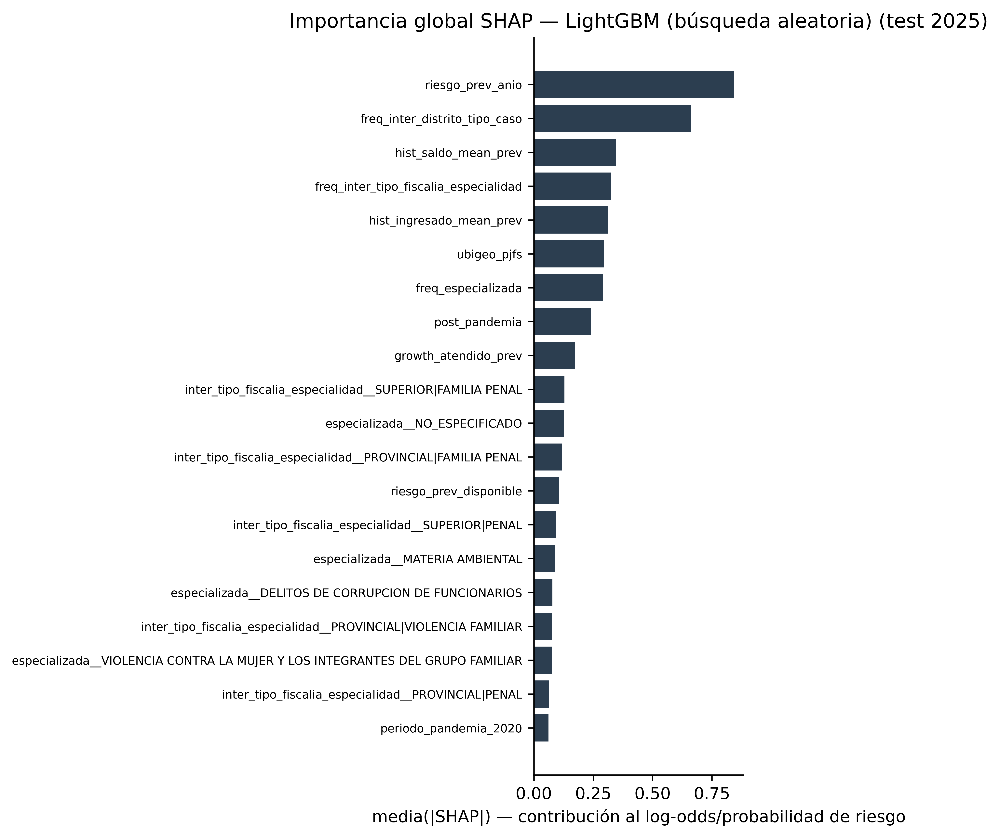

**Figura:** `15_shap_beeswarm.png`

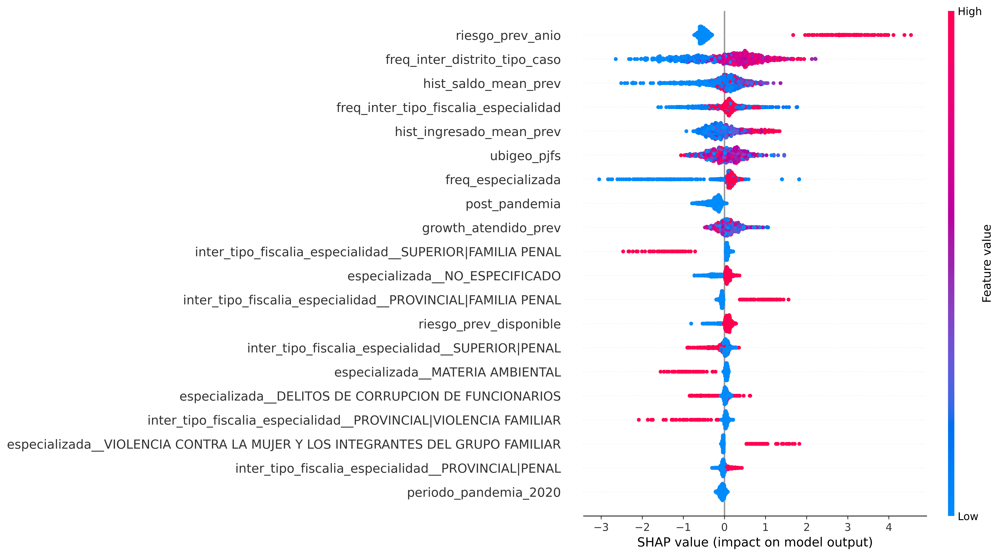

**Figura:** `15_shap_freq_inter_distrito_tipo_caso_x_ubigeo.png`

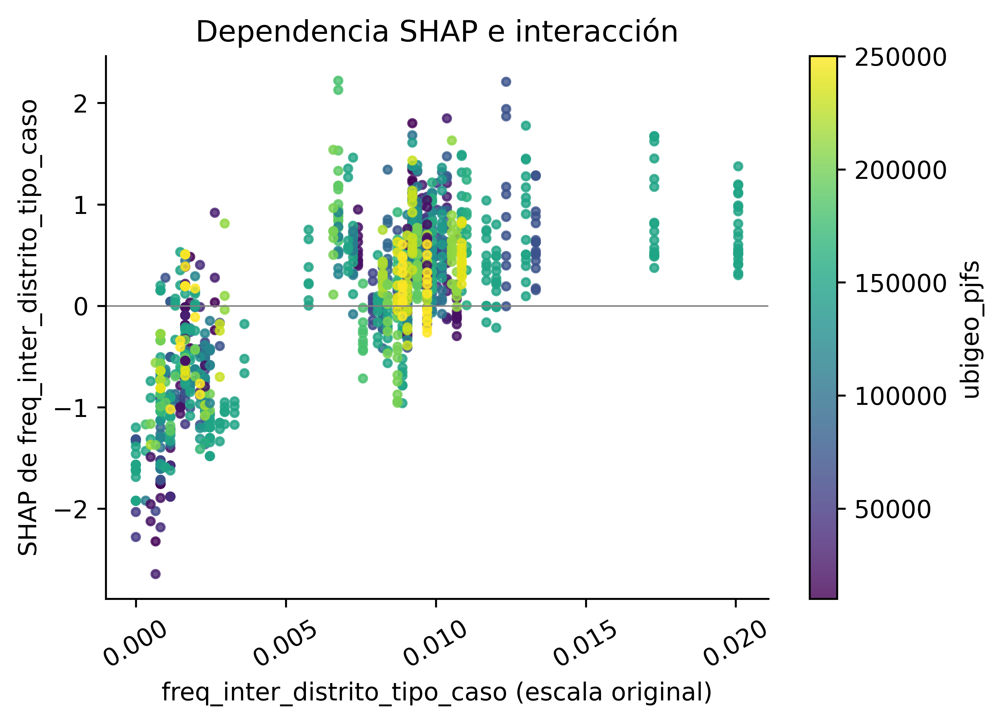

**Figura:** `15_shap_dependencia_top_interaccion.png`

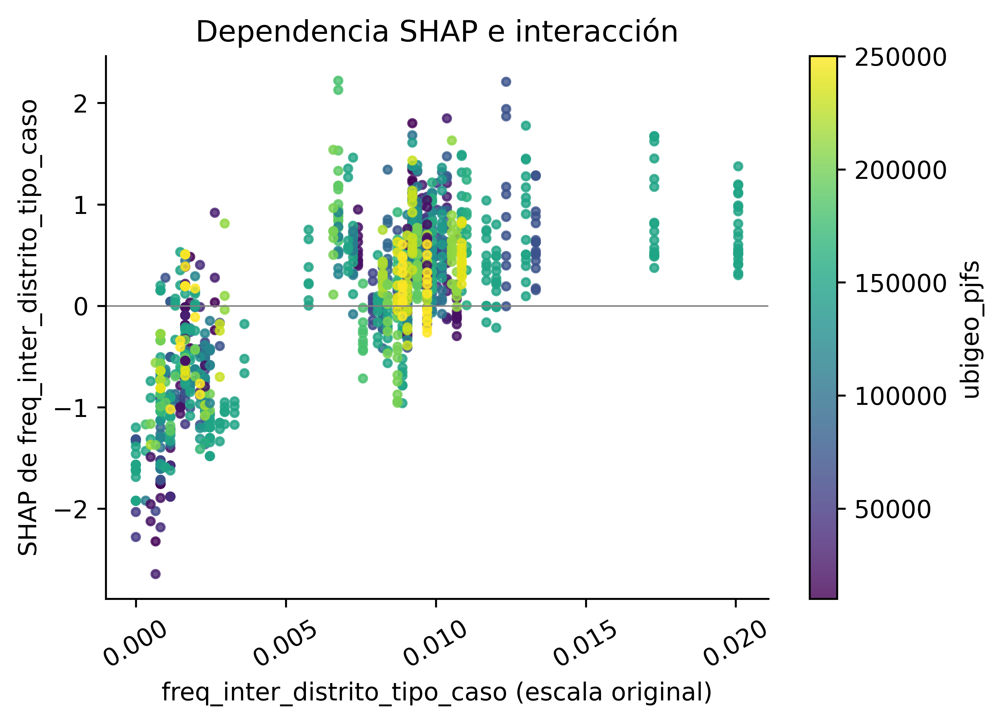

**Figura:** `16c_correlacion_modelos.png`

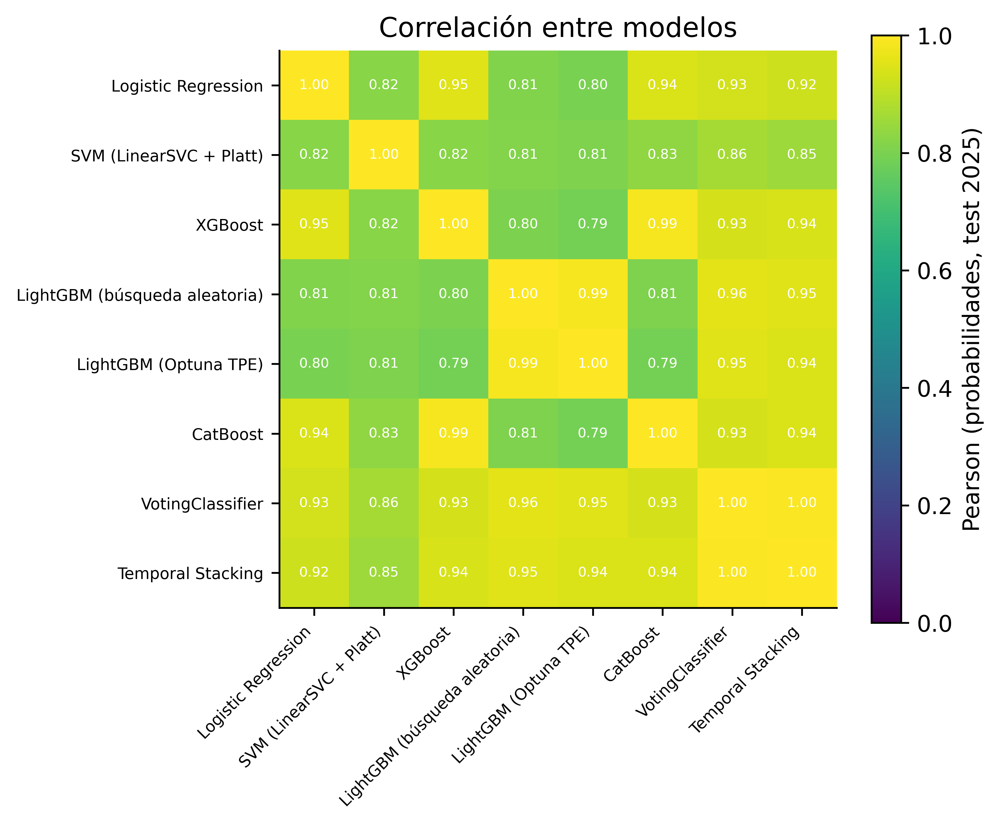

**Figura:** `16d_curva_ganancia_priorizacion.png`

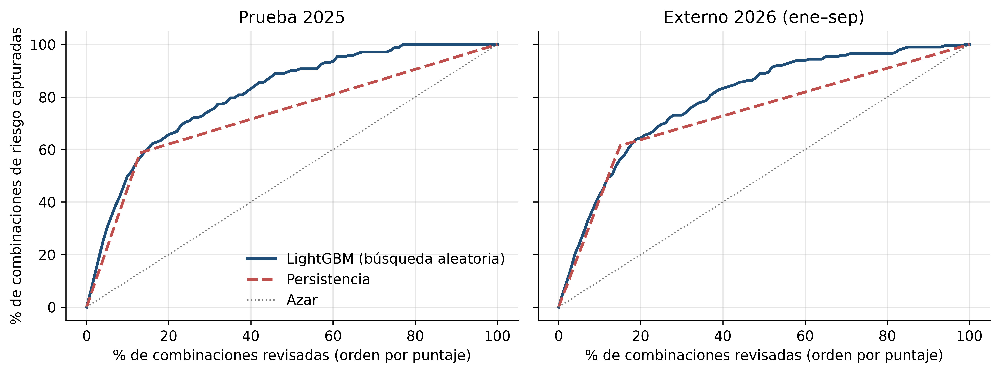

**Figura:** `16e_robustez_target.png`

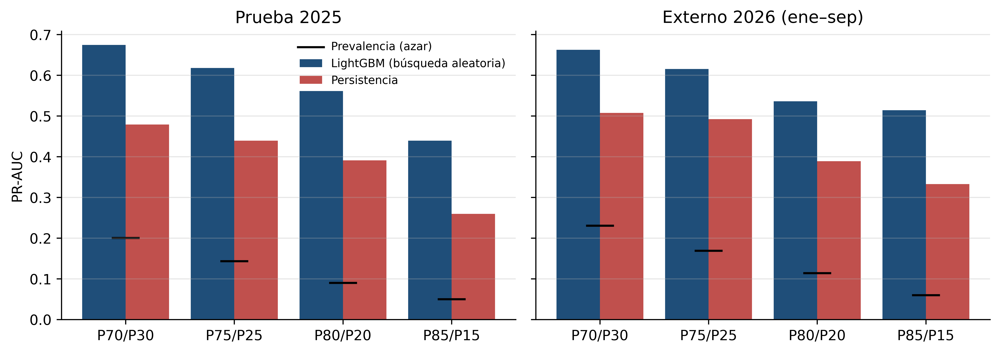

In [22]:
#@title 8c. EJECUTAR etapas 14–16e (ablación, SHAP, contrafactuales, persistencia, priorización, robustez, fuga, subgrupos)
for _e in ["ablacion", "interpretabilidad", "persistencia", "priorizacion", "robustez_target", "auditoria_fuga",
           "diversidad_subgrupos"]:
    ejecutar_etapa(_e)

ver_tabla(T / "14_ablacion.csv", "Ablación por familias de variables (Tabla 11)")
ver_tabla(T / "15_shap_global.csv", "Importancia global SHAP (15 primeras)", max_filas=15)
ver_tabla(T / "15_shap_por_familia.csv", "Señal SHAP por familia de variables")
ver_tabla(T / "15_importancia_permutacion.csv", "Importancia por permutación (15 primeras)", max_filas=15)
ver_tabla(T / "15_shap_interacciones_top50.csv", "Interacciones SHAP (10 primeras)", max_filas=10)
ver_tabla(T / "15_contrafactuales_por_variable.csv", "Contrafactuales: variables que cruzan τ con un solo cambio", max_filas=15)
ver_tabla(T / "16_linea_base_persistencia.csv", "Modelo final frente a la línea base de persistencia")
ver_tabla(T / "16_mcnemar_modelo_vs_persistencia.csv", "McNemar pareado: modelo frente a persistencia")
ver_tabla(T / "16d_priorizacion_topk.csv", "Priorización top-k: modelo, persistencia y azar (Tabla S12)")
ver_tabla(T / "16d_diferencias_vs_persistencia.csv", "Diferencias pareadas frente a la persistencia (Tabla S13)")
ver_tabla(T / "16e_robustez_target_modelo.csv", "Robustez a la definición del target: modelo, persistencia y volumen (Tabla S15)")
ver_tabla(T / "16e_acuerdo_etiquetas_escenarios.csv", "Acuerdo de etiquetas con el escenario primario (Tabla S16)")
ver_tabla(T / "16e_estabilidad_shap_escenarios.csv", "Estabilidad de SHAP entre escenarios (Tabla S16)")
ver_tabla(T / "16e_diagnostico_target.csv", "Diagnóstico de la construcción del target (Tabla S17)")
ver_tabla(T / "16b_auditoria_fuga_exclusiones.csv", "Auditoría de fuga: columnas excluidas")
print("Veredicto de la auditoría de fuga:", res("auditoria_fuga", "veredicto"))
ver_tabla(T / "16c_correlacion_probas_test_pearson.csv", "Correlación entre modelos (prueba 2025)")
ver_tabla(T / "16c_friedman_miembros.json", "Friedman sobre los 5 miembros de los conjuntos")
ver_tabla(T / "16c_desempeno_por_subgrupo.csv", "Desempeño del modelo final por subgrupo")
for _f in ["15_shap_global.png", "15_shap_beeswarm.png", "15_shap_freq_inter_distrito_tipo_caso_x_ubigeo.png",
           "15_shap_dependencia_top_interaccion.png", "16c_correlacion_modelos.png", "16d_curva_ganancia_priorizacion.png",
           "16e_robustez_target.png"]:
    ver_figura(_f)

#### Lectura de resultados · explicabilidad y subgrupos
Los resultados de ablación, SHAP, persistencia, auditoría de fuga y subgrupos se obtienen de las salidas de la ejecución actual.


### Verificaciones metodológicas del protocolo (etapa 16f)

Esta etapa forma parte del análisis científico ordinario. Evalúa faltantes y denominadores, sensibilidad de la operacionalización, umbrales, comparabilidad del periodo parcial de 2026 e incertidumbre de priorización. Sus resultados se documentan como resultados metodológicos y materiales suplementarios; no se etiquetan como respuestas a comentarios externos.

In [23]:
#@title 8d. Etapa 16f: verificaciones metodológicas adicionales (faltantes, umbrales, comparabilidad del corte parcial, priorización, validez del indicador)
# Esta etapa NO modifica la metodología ni reentrena: recalcula, a partir de los datos y las predicciones guardadas,
# los diagnósticos que acompañan al protocolo (valores faltantes y denominadores, umbrales aprendidos, comparabilidad
# del corte parcial 2026, incertidumbre de la priorización con capacidad limitada y estabilidad temporal del indicador).
_MESES_NUM = {"ENERO": 1, "FEBRERO": 2, "MARZO": 3, "ABRIL": 4, "MAYO": 5, "JUNIO": 6, "JULIO": 7, "AGOSTO": 8,
              "SETIEMBRE": 9, "SEPTIEMBRE": 9, "OCTUBRE": 10, "NOVIEMBRE": 11, "DICIEMBRE": 12}


def _n_meses_periodo(texto: str) -> int:
    """Número de meses cubiertos por el campo 'periodo' (p. ej. 'ENERO - SETIEMBRE' → 9)."""
    partes = [p.strip().upper() for p in str(texto).split("-")]
    if len(partes) != 2 or partes[0] not in _MESES_NUM or partes[1] not in _MESES_NUM:
        raise ValueError(f"no se pudo interpretar el periodo {texto!r}")
    return _MESES_NUM[partes[1]] - _MESES_NUM[partes[0]] + 1


def _metricas_rank(y, p, tau):
    y = np.asarray(y, int)
    ok = len(np.unique(y)) > 1
    m = metricas_binarias(y, p, tau)
    return {"n": int(len(y)), "positivos": int(y.sum()), "prevalencia": float(y.mean()),
            "f1_binary": m["f1_binary"], "recall": m["recall"], "precision": m["precision"],
            "roc_auc": float(roc_auc_score(y, p)) if ok else float("nan"),
            "pr_auc": float(average_precision_score(y, p)) if ok else float("nan")}


@etapa("revision_metodologica",
       "3.1 / 3.2 / 4.2 / 4.6 Verificaciones metodológicas adicionales (faltantes, umbrales, corte parcial, priorización, indicador)",
       deps=["preprocessing", "split", "train", "comparativa", "persistencia", "priorizacion"],
       cfg=["split", "data.target", "data.columnas_clave", "priorizacion", "preprocessing"])
def etapa_revision_metodologica():
    sp = CONFIG["split"]
    alto, bajo = CONFIG["data"]["target"]["primario"]
    claves = [c for c in CONFIG["data"]["columnas_clave"]]
    final = res("comparativa", "modelo_final")
    tau = float(res("comparativa", "tau_final"))
    pz = CONFIG["priorizacion"]
    df = pd.read_parquet(art("preprocessing", "processed"))
    frame, y_base, q_a, q_b, prev_tr = construir_target(df, sp["train_years"], alto, bajo)
    y_base = pd.Series(np.asarray(y_base).ravel(), index=frame.index)
    X, y, M = cargar_gold()
    bloques = {"test": ("Prueba %d" % sp["test_year"], sp["test_year"]), "external": (ETIQ_EXT, sp["external_year"])}
    p_mod = {b: leer_predicciones(final, b)["y_proba"].to_numpy() for b in bloques}
    p_per = {b: (X[b]["riesgo_prev_anio"].to_numpy() > 0.5).astype(float) for b in bloques}
    flag_at = df["atendido_was_null"].astype(int) if "atendido_was_null" in df.columns else pd.Series(0, index=df.index)
    flag_in = df["ingresado_was_null"].astype(int) if "ingresado_was_null" in df.columns else pd.Series(0, index=df.index)

    # ---- 17a. Valores faltantes y denominadores por año ---------------------------------------------------------
    filas = []
    for anio, g in df.groupby("anio"):
        idx_mod = frame.index.intersection(g.index)
        ing = pd.to_numeric(g["ingresado"], errors="coerce")
        filas.append({"anio": int(anio), "registros": int(len(g)),
                      "ingresado_nulo_imputado": int(flag_in.loc[g.index].sum()),
                      "ingresado_cero_o_negativo_excluido": int((ing <= 0).sum()),
                      "registros_modelables": int(len(idx_mod)),
                      "atendido_nulo_imputado": int(flag_at.loc[idx_mod].sum()),
                      "atendido_nulo_pct": float(flag_at.loc[idx_mod].mean() * 100) if len(idx_mod) else 0.0,
                      "atendido_nulo_con_etiqueta_1": int(((flag_at.loc[idx_mod] == 1) & (y_base.loc[idx_mod] == 1)).sum()),
                      "prevalencia_target_pct": float(y_base.loc[idx_mod].mean() * 100) if len(idx_mod) else float("nan")})
    t17a = pd.DataFrame(filas)
    tot = {"anio": "Total"}
    for c in t17a.columns[1:]:
        if c.endswith("_pct"):
            continue
        tot[c] = int(t17a[c].sum())
    tot["atendido_nulo_pct"] = float(flag_at.loc[frame.index].mean() * 100)
    tot["prevalencia_target_pct"] = float(y_base.mean() * 100)
    t17a = pd.concat([t17a, pd.DataFrame([tot])], ignore_index=True)
    r17a = escribir_csv(t17a, TABLES_DIR / "17a_faltantes_denominadores.csv")

    # ---- 17b. Sensibilidad de la etiqueta al tratamiento de atendido nulo (sin reentrenar) ------------------------
    afectados = frame.index[flag_at.loc[frame.index] == 1]
    escenarios = {"Base: mediana de entrenamiento": None, "atendido nulo = 0": "cero",
                  "atendido nulo = ingresado": "igual", "Excluir registros con atendido nulo": "excluir"}
    filas = []
    for nombre, modo in escenarios.items():
        d2 = df.copy()
        if modo == "cero":
            d2.loc[afectados, "atendido"] = 0.0
        elif modo == "igual":
            d2.loc[afectados, "atendido"] = d2.loc[afectados, "ingresado"]
        elif modo == "excluir":
            d2 = d2.drop(index=afectados)
        f2, y2, qa2, qb2, prev2 = construir_target(d2, sp["train_years"], alto, bajo)
        y2 = pd.Series(np.asarray(y2).ravel(), index=f2.index)
        aj = y_base.reindex(f2.index)
        aff = afectados.intersection(y2.index)
        cambios_afectados = int((y2.loc[aff] != y_base.loc[aff]).sum())
        fila = {"escenario": nombre, "registros_afectados": int(len(afectados)), "q_saldo_P75": qa2, "q_tasa_P25": qb2,
                "prevalencia_train_pct": prev2 * 100, "registros_afectados_con_etiqueta_distinta": cambios_afectados,
                "etiquetas_distintas_total": int((y2 != aj).sum())}
        for b, (etq, _anio) in bloques.items():
            idx_b = frame.index[frame["anio"] == bloques[b][1]]
            comunes = idx_b.intersection(y2.index)
            pos = idx_b.get_indexer(comunes)
            yy = y2.loc[comunes].to_numpy(int)
            mm = _metricas_rank(yy, p_mod[b][pos], tau)
            pp = _metricas_rank(yy, p_per[b][pos], 0.5)
            clave = "2025" if b == "test" else "2026"
            fila.update({f"afectados_en_{clave}": int(flag_at.loc[idx_b].sum()), f"n_{clave}": mm["n"],
                         f"prevalencia_{clave}_pct": mm["prevalencia"] * 100, f"modelo_f1_{clave}": mm["f1_binary"],
                         f"modelo_roc_auc_{clave}": mm["roc_auc"], f"modelo_pr_auc_{clave}": mm["pr_auc"],
                         f"persistencia_f1_{clave}": pp["f1_binary"]})
        filas.append(fila)
    t17b = pd.DataFrame(filas)
    r17b = escribir_csv(t17b, TABLES_DIR / "17b_sensibilidad_atendido_nulo.csv")

    # ---- 17c. Umbrales del target: 2019–2022 frente a 2019–2023 -------------------------------------------------
    fs_years = list(sp["feature_selection_years"])
    f_fs, y_fs, qa_fs, qb_fs, prev_fs = construir_target(df, fs_years, alto, bajo)
    y_fs = pd.Series(np.asarray(y_fs).ravel(), index=f_fs.index)
    filas = []
    for etiqueta, anios in (("Selección de variables (2019–2022)", fs_years), ("Año de validación interna (2023)", [sp["feature_selection_valid_year"]])):
        idx = frame.index[frame["anio"].isin(anios)]
        distinto = int((y_fs.loc[idx] != y_base.loc[idx]).sum())
        filas.append({"filas_evaluadas": etiqueta, "registros": int(len(idx)),
                      "q_saldo_2019_2022": qa_fs, "q_tasa_2019_2022": qb_fs, "q_saldo_2019_2023": q_a, "q_tasa_2019_2023": q_b,
                      "prevalencia_umbral_2019_2022_pct": float(y_fs.loc[idx].mean() * 100),
                      "prevalencia_umbral_2019_2023_pct": float(y_base.loc[idx].mean() * 100),
                      "etiquetas_distintas": distinto, "etiquetas_distintas_pct": distinto / len(idx) * 100})
    t17c = pd.DataFrame(filas)
    r17c = escribir_csv(t17c, TABLES_DIR / "17c_umbrales_2019_2022_vs_2019_2023.csv")

    # ---- 17d. Comparabilidad del corte parcial 2026 (exposición en meses) --------------------------------------------
    meses = {int(a): _n_meses_periodo(g["periodo"].dropna().astype(str).str.upper().mode().iloc[0])
             for a, g in df.groupby("anio") if "periodo" in df.columns and g["periodo"].notna().any()}
    m_ext = meses[sp["external_year"]]
    filas = []
    for a, g in frame.groupby("anio"):
        filas.append({"seccion": "Prevalencia por año", "anio": int(a), "meses_cubiertos": meses.get(int(a), np.nan),
                      "registros": int(len(g)), "prevalencia_pct": float(y_base.loc[g.index].mean() * 100),
                      "saldo_mediana": float(g["saldo_casos"].median()), "tasa_mediana": float(g["tasa_atencion"].median())})
    for b, (etq, anio_b) in bloques.items():
        idx_b = frame.index[frame["anio"] == anio_b]
        s = M[b]["saldo_casos"].to_numpy(float)
        t = M[b]["tasa_atencion"].to_numpy(float)
        esc = 12.0 / meses[anio_b]
        for nombre, factor in (("Etiqueta del protocolo (saldo observado)", 1.0), (f"Saldo anualizado (×12/{meses[anio_b]})", esc)):
            y_alt = ((s * factor >= q_a) & (t <= q_b)).astype(int)
            mm, pp = _metricas_rank(y_alt, p_mod[b], tau), _metricas_rank(y_alt, p_per[b], 0.5)
            filas.append({"seccion": "Evaluación con etiqueta alternativa", "bloque": etq, "etiqueta": nombre,
                          "meses_cubiertos": meses[anio_b], "registros": mm["n"], "positivos": mm["positivos"],
                          "prevalencia_pct": mm["prevalencia"] * 100, "modelo_f1": mm["f1_binary"],
                          "modelo_roc_auc": mm["roc_auc"], "modelo_pr_auc": mm["pr_auc"], "persistencia_f1": pp["f1_binary"],
                          "persistencia_roc_auc": pp["roc_auc"], "persistencia_pr_auc": pp["pr_auc"]})
    t17d = pd.DataFrame(filas)
    r17d = escribir_csv(t17d, TABLES_DIR / "17d_comparabilidad_corte_parcial.csv")

    # ---- 17e. Incertidumbre de la captura top-k (bootstrap pareado modelo − persistencia) -------------------------
    rng = np.random.default_rng(SEMILLA + 17)
    filas = []
    for b, (etq, _a) in bloques.items():
        yt = np.asarray(y[b]).astype(int)
        n = len(yt)
        idxs = [rng.integers(0, n, n) for _ in range(int(pz["n_bootstrap"]))]
        for k_pct in pz["top_k_pct"]:
            k = int(round(n * k_pct / 100))
            rec_m, rec_p = [], []
            for ix in idxs:
                yb = yt[ix]
                pos = yb.sum()
                if pos == 0:
                    continue
                kb = int(round(len(ix) * k_pct / 100))
                rec_m.append(_captura_esperada(yb, p_mod[b][ix], kb) / pos)
                rec_p.append(_captura_esperada(yb, p_per[b][ix], kb) / pos)
            rec_m, rec_p = np.asarray(rec_m), np.asarray(rec_p)
            d = rec_m - rec_p
            pos_tot = int(yt.sum())
            cm, cp = _captura_esperada(yt, p_mod[b], k) / pos_tot, _captura_esperada(yt, p_per[b], k) / pos_tot
            filas.append({"bloque": etq, "top_k_pct": k_pct, "k_registros_revisados": k, "positivos_totales": pos_tot,
                          "modelo_captura_pct": cm * 100, "modelo_ic_inf": np.percentile(rec_m, 2.5) * 100,
                          "modelo_ic_sup": np.percentile(rec_m, 97.5) * 100,
                          "persistencia_captura_pct": cp * 100, "persistencia_ic_inf": np.percentile(rec_p, 2.5) * 100,
                          "persistencia_ic_sup": np.percentile(rec_p, 97.5) * 100,
                          "azar_captura_pct": k / n * 100, "diferencia_pp": (cm - cp) * 100,
                          "dif_ic_inf_pp": np.percentile(d, 2.5) * 100, "dif_ic_sup_pp": np.percentile(d, 97.5) * 100,
                          "n_boot_validos": int(len(d))})
    t17e = pd.DataFrame(filas)
    r17e = escribir_csv(t17e, TABLES_DIR / "17e_topk_incertidumbre.csv")

    # ---- 17f. Estabilidad temporal del indicador: etiqueta en t frente a la carga observada en t+1 -----------------
    anual = (frame.assign(_y=y_base).groupby(claves + ["anio"], dropna=False)
             .agg(y=("_y", "max"), saldo=("saldo_casos", "mean"), tasa=("tasa_atencion", "mean")).reset_index())
    filas = []
    for a in sorted(anual["anio"].unique()):
        sig = a + 1
        if sig not in set(anual["anio"]):
            continue
        a0, a1 = anual[anual["anio"] == a], anual[anual["anio"] == sig]
        j = a0.merge(a1, on=claves, suffixes=("", "_sig"), how="inner")
        if len(j) == 0 or j["y"].nunique() < 2:
            continue
        g1, g0 = j[j["y"] == 1], j[j["y"] == 0]
        filas.append({"transicion": f"{a} → {sig}" + (" (corte parcial)" if sig == sp["external_year"] else ""),
                      "combinaciones_con_historial": int(len(j)), "marcadas_en_t": int(len(g1)),
                      "saldo_mediana_t1_si_marcada": float(g1["saldo_sig"].median()),
                      "saldo_mediana_t1_si_no_marcada": float(g0["saldo_sig"].median()),
                      "tasa_mediana_t1_si_marcada": float(g1["tasa_sig"].median()),
                      "tasa_mediana_t1_si_no_marcada": float(g0["tasa_sig"].median()),
                      "etiqueta_t1_si_marcada_pct": float(g1["y_sig"].mean() * 100),
                      "etiqueta_t1_si_no_marcada_pct": float(g0["y_sig"].mean() * 100),
                      "p_mannwhitney_saldo": float(stats.mannwhitneyu(g1["saldo_sig"], g0["saldo_sig"], alternative="two-sided").pvalue),
                      "p_mannwhitney_tasa": float(stats.mannwhitneyu(g1["tasa_sig"], g0["tasa_sig"], alternative="two-sided").pvalue)})
    t17f = pd.DataFrame(filas)
    r17f = escribir_csv(t17f, TABLES_DIR / "17f_estabilidad_temporal_indicador.csv")

    # ---- Resumen en texto ---------------------------------------------------------------------------------------------
    tot = t17a[t17a["anio"] == "Total"].iloc[0]
    k10 = t17e[t17e["top_k_pct"] == 10]
    lineas = ["# Verificaciones metodológicas adicionales (etapa 16f)", "",
              "- Los datos solo contienen `ingresado` y `atendido` del periodo de cada registro; no incluyen el inventario acumulado de expedientes "
              "pendientes. `saldo_casos` es el balance neto del periodo (flujo), no un stock.",
              f"- Registros: {int(tot['registros'])}; modelables: {int(tot['registros_modelables'])}; ingresado ≤ 0 excluido: "
              f"{int(tot['ingresado_cero_o_negativo_excluido'])}; ingresado nulo imputado: {int(tot['ingresado_nulo_imputado'])}; "
              f"atendido nulo imputado: {int(tot['atendido_nulo_imputado'])} ({tot['atendido_nulo_pct']:.2f} %).",
              "- Sensibilidad de la etiqueta al tratamiento de atendido nulo: "
              + "; ".join(f"{r.escenario}: {int(r.etiquetas_distintas_total)} etiquetas distintas del escenario base" for r in t17b.itertuples()) + ".",
              "- Umbrales 2019–2022 frente a 2019–2023: "
              + "; ".join(f"{r.filas_evaluadas}: {int(r.etiquetas_distintas)} de {int(r.registros)} etiquetas distintas ({r.etiquetas_distintas_pct:.2f} %)" for r in t17c.itertuples()) + ".",
              "- Captura top-10 % (modelo − persistencia, pp, IC 95 % bootstrap pareado): "
              + "; ".join(f"{r.bloque}: {r.diferencia_pp:+.1f} ({r.dif_ic_inf_pp:+.1f} a {r.dif_ic_sup_pp:+.1f})" for r in k10.itertuples()) + "."]
    _art_dir = OUTPUT_DIR / "articulo"
    _art_dir.mkdir(parents=True, exist_ok=True)
    md = _art_dir / "Resultados_revision_metodologica.md"
    md.write_text("\n".join(lineas) + "\n", encoding="utf-8")
    for l in lineas[2:]:
        log("[revision] " + l[2:200])
    return {"artifacts": {"faltantes": r17a, "sensibilidad_atendido": r17b, "umbrales": r17c, "comparabilidad_2026": r17d,
                          "topk_incertidumbre": r17e, "estabilidad_indicador": r17f, "texto": md},
            "resumen": {"faltantes": t17a.to_dict(orient="records"), "sensibilidad_atendido": t17b.to_dict(orient="records"),
                        "umbrales": t17c.to_dict(orient="records"), "comparabilidad_2026": t17d.to_dict(orient="records"),
                        "topk_incertidumbre": t17e.to_dict(orient="records"), "estabilidad_indicador": t17f.to_dict(orient="records"),
                        "meses_por_anio": {str(k): int(v) for k, v in meses.items()}}}


### Ejecución E2 · Etapa 16f

In [ ]:
#@title 8d-b. EJECUTAR la etapa 16f y ver sus salidas
ejecutar_etapa("revision_metodologica")

ver_tabla(T / "17a_faltantes_denominadores.csv", "Valores faltantes y denominadores por año (Supplementary Table S10)")
ver_tabla(T / "17b_sensibilidad_atendido_nulo.csv", "Sensibilidad de la etiqueta al tratamiento de atendido nulo (Supplementary Table S11)")
ver_tabla(T / "17c_umbrales_2019_2022_vs_2019_2023.csv", "Umbrales del target: 2019–2022 frente a 2019–2023 (Supplementary Table S12)")
ver_tabla(T / "17d_comparabilidad_corte_parcial.csv", "Comparabilidad del corte parcial 2026 (Supplementary Table S13)")
ver_tabla(T / "17e_topk_incertidumbre.csv", "Captura top-k con incertidumbre: modelo frente a persistencia (Supplementary Table S14)")
ver_tabla(T / "17f_estabilidad_temporal_indicador.csv", "Estabilidad temporal del indicador (Supplementary Table S15)")
ver_md((OUTPUT_DIR / "articulo" / "Resultados_revision_metodologica.md").read_text(encoding="utf-8"))


### Celda 8b · Definición de las tablas y figuras del artículo
**Qué hace:** arma las Tablas 1–12 del artículo, las tablas suplementarias S1–S18, las figuras y un tablas CSV/Markdown.
**Por qué:** las tablas del artículo se generan directamente de los resultados, sin copiar números a mano.

In [24]:
#@title 8b. Etapa 17a: tablas y figuras con la numeración del artículo (CSV + Markdown)
ARTICULO_DIR = OUTPUT_DIR / "articulo"
ARTICULO_DIR.mkdir(parents=True, exist_ok=True)

DIMENSIONES_CRUDAS = [
    ("Temporalidad", ["periodo", "anio", "fecha_descarga", "fecha_corte"]),
    ("Geografía institucional", ["distrito_fiscal", "ubigeo_pjfs", "dpto_pjfs", "prov_pjfs", "dist_pjfs"]),
    ("Taxonomía de casos", ["tipo_fiscalia", "materia", "especialidad", "tipo_caso", "especializada"]),
    ("Carga volumétrica", ["ingresado", "atendido"]),
]
FAMILIAS_DERIVADAS = [
    ("Presión operativa", ["saldo_casos", "tasa_atencion", "ratio_saldo"]),
    ("Descriptores temporales", ["anio_centrado†", "post_pandemia", "periodo_pandemia_2020"]),
    ("Interacciones categóricas (2.º orden)", ["inter_distrito_tipo_caso", "inter_materia_tipo_fiscalia",
                                              "inter_tipo_fiscalia_especialidad"]),
    ("Métricas históricas rezagadas (por distrito fiscal)", ["hist_ingresado_mean_prev", "hist_atendido_mean_prev",
                                                             "hist_saldo_mean_prev", "growth_ingresado_prev",
                                                             "growth_atendido_prev"]),
    ("Rezago de la etiqueta (por combinación)", ["riesgo_prev_anio", "riesgo_prev_disponible"]),
]
TITULOS_TABLAS = {
    1: "Tabla 1: Campos administrativos originales del diccionario de datos del MPFN.",
    2: "Tabla 2: Variables derivadas mediante ingeniería de variables.",
    3: "Tabla 3: Características generales del conjunto de datos.",
    4: "Tabla 4: Análisis de sensibilidad del objetivo proxy entre escenarios.",
    5: "Tabla 5: Métodos de selección de variables evaluados.",
    6: "Tabla 6: Distribución de la votación por consenso y variables retenidas.",
    7: "Tabla 7: Resumen de la validación no supervisada del espacio de variables.",
    8: "Tabla 8: Configuraciones de modelos evaluadas (búsqueda de hiperparámetros).",
    9: "Tabla 9: Comparación de modelos: F1 al umbral común 0,5 y al umbral τ* de cada modelo optimizado en 2024.",
    10: "Tabla 10: Desempeño del modelo final entre particiones temporales.",
    11: "Tabla 11: Estudio de ablación (conjunto de prueba de 2025, umbral = 0,5).",
    12: "Tabla 12: Impacto operativo bajo supuestos de costo ilustrativos.",
}


def _num(v, d=3):
    if v is None:
        return "—"
    try:
        f = float(v)
    except (TypeError, ValueError):
        return str(v)
    if math.isnan(f):
        return "—"
    return f"{f:.{d}f}".replace(".", ",")


def _miles(v) -> str:
    return f"{int(round(float(v))):,}".replace(",", ".")


def _periodo_texto(cons: pd.DataFrame, anios: list) -> str:
    """Periodo con la granularidad del campo 'periodo' (p. ej. 'ENERO-DICIEMBRE 2019 – ENERO-SETIEMBRE 2026')."""
    if "periodo" not in cons.columns:
        return f"{anios[0]} – {anios[-1]}"
    ini = ", ".join(sorted(cons.loc[cons["anio"] == anios[0], "periodo"].dropna().astype(str).unique())[:3])
    fin = ", ".join(sorted(cons.loc[cons["anio"] == anios[-1], "periodo"].dropna().astype(str).unique())[:3])
    return f"{ini} {anios[0]} – {fin} {anios[-1]}"


def construir_tablas_articulo() -> dict:
    tablas, notas = {}, {}
    cons = pd.read_parquet(art("consolidacion", "silver"))
    tablas[1] = pd.DataFrame([{"Dimensión": d, "Variables": ", ".join(c for c in cols if c in cons.columns),
                               "Ausentes en los CSV": ", ".join(c for c in cols if c not in cons.columns) or "—"}
                              for d, cols in DIMENSIONES_CRUDAS])
    notas[1] = "ubigeo_pjfs se codifica según el catálogo del INEI."
    tablas[2] = pd.DataFrame([{"Dimensión": d, "Variables": ", ".join(v)} for d, v in FAMILIAS_DERIVADAS])
    notas[2] = ("† Excluida de la matriz de variables candidatas por colinealidad directa con el año calendario. "
                f"growth_*_prev calculado en modo '{CONFIG['feature_engineering']['growth_modo']}'.")

    sp = res("split", "splits")
    anios = sorted(int(a) for a in cons["anio"].unique())
    embudo = pd.read_csv(art("feature_selection", "embudo"))
    tablas[3] = pd.DataFrame([
        ("Fuente", "MPFN – Datos Abiertos del Perú (Casos Fiscales)"),
        ("Periodo", _periodo_texto(cons, anios)),
        ("Registros totales", _miles(res("consolidacion", "n_rows"))),
        ("Campos originales", str(sum(c in cons.columns for c in COLUMNAS_CRUDAS))),
        *[(r.caracteristica, str(int(r.valor))) for r in embudo.itertuples()],
        ("Partición entren./valid./prueba/externo",
         " / ".join(str(sp[b]["n_rows"]) for b in ("train_full", "calib", "test", "external"))),
        ("Balance de clases (entrenamiento)",
         f"{_num((1 - sp['train_full']['prevalence']) * 100, 1)} % / {_num(sp['train_full']['prevalence'] * 100, 1)} %"),
        ("Validación", f"Bloques anuales, {len(CONFIG['split']['train_years']) - 1} pliegues"),
    ], columns=["Característica", "Valor"])
    notas[3] = "La partición se informa como entrenamiento/validación/prueba/externo. Balance = clase 0 / clase 1."

    sens = pd.read_csv(art("sensibilidad_target", "tabla"))
    sens["orden"] = sens["escenario"].str.extract(r"P(\d+)")[0].astype(int)
    sens = sens.sort_values("orden")
    cv_min, cv_max = sens["cv_interanual"].min(), sens["cv_interanual"].max()
    roles = {70: "Alerta temprana", 75: "Primario", 80: "Estricto", 85: "Muy estricto"}
    tablas[4] = pd.DataFrame([{
        "Umbral": r.escenario, "Entren. %": _num(r.train_pct, 1), "Prueba %": _num(r.test_pct, 1),
        "Ext. %": _num(r.external_pct, 1),
        "CV": _num(r.cv_interanual, 3) + (" (mín.)" if r.cv_interanual == cv_min else (" (máx.)" if r.cv_interanual == cv_max else "")),
        "Rol": roles.get(int(r.orden), r.rol)} for r in sens.itertuples()])
    notas[4] = ("Entren. % = prevalencia en entrenamiento; Prueba % = 2025; Ext. % = 2026; "
                "CV = coeficiente de variación interanual de la prevalencia (2019–2026).")

    met = pd.read_csv(art("feature_selection", "metodos"))
    tablas[5] = pd.DataFrame([{"Método": r.metodo, "Tipo": r.tipo,
                               "N.º vars": str(int(r.seleccion_nativa)) if not pd.isna(r.seleccion_nativa) else str(int(r.votos_top_k))}
                              for r in met.itertuples()])
    notas[5] = (f"Filtros y Random Forest votan su top-k = {res('feature_selection', 'top_k')} (max(10, n/3)); "
                "Boruta y RFECV muestran su selección nativa.")

    dist = pd.read_csv(art("feature_selection", "distribucion"))
    n_cod = int(res("feature_selection", "n_encoded"))
    umbral_c = int(CONFIG["feature_selection"]["consensus_threshold"])
    filas6 = []
    for r in dist.itertuples():
        v = int(str(r.votos).split("/")[0])
        etiqueta = r.votos + (" (unánime)" if v == 6 else (" (umbral mínimo)" if v == umbral_c else (" (descartadas)" if v < umbral_c else "")))
        filas6.append({"Votos (6 métodos)": etiqueta, "N.º vars": int(r.n_variables), f"% del total ({n_cod})": _num(r.pct_codificadas, 1) + " %"})
        if v == umbral_c:
            ret = int(dist[dist["retenidas"]]["n_variables"].sum())
            filas6.append({"Votos (6 métodos)": f"Subtotal retenido (≥ {umbral_c} votos)", "N.º vars": ret,
                           f"% del total ({n_cod})": _num(ret / n_cod * 100, 1) + " %"})
    tablas[6] = pd.DataFrame(filas6)
    votos = pd.read_csv(art("feature_selection", "votos"))
    unanimes = votos[votos["votes"] == 6]["feature"].tolist()
    notas[6] = f"Umbral de consenso = votos ≥ {umbral_c}/6. Variables con acuerdo unánime (6/6): {', '.join(unanimes) or 'ninguna'}."

    tablas[7] = pd.read_csv(art("espacio_caracteristicas", "tabla")).rename(
        columns={"analisis": "Análisis", "evidencia": "Evidencia", "resultado": "Resultado"})
    perfil = pd.read_csv(art("espacio_caracteristicas", "perfil_clusters"))
    notas[7] = (f"Consistencia clusters–riesgo: Spearman(saldo medio, tasa de riesgo) = "
                f"{_num(res('espacio_caracteristicas', 'spearman_saldo_riesgo'))}; el cluster de mayor saldo medio "
                f"tiene tasa de riesgo {_num(perfil.iloc[0]['tasa_riesgo'])}.")

    comp = pd.read_csv(art("comparativa", "comparacion")).set_index("modelo")
    conf = pd.read_csv(art("train", "configuraciones")).set_index("modelo")
    filas8 = [{"Modelo": "Dummy", "Optimizador": "—", "N.º de iteraciones": "—", "F1 (clase positiva)": "—", "F1-macro": "—"}]
    for m in res("train", "base"):
        c = conf.loc[m]
        filas8.append({"Modelo": NOMBRES_MODELOS.get(m, m),
                       "Optimizador": "Búsqueda aleatoria (validación 2023)" if c.optimizador == "randomized_search" else "TPE (Optuna)",
                       "N.º de iteraciones": int(c.trials),
                       "F1 (clase positiva)": _num(comp.loc[m, "cv_f1_binary_media"]),
                       "F1-macro": _num(comp.loc[m, "cv_f1_macro_media"])})
    filas8 += [{"Modelo": "VotingClassifier", "Optimizador": "— (conjunto, sin ajuste)", "N.º de iteraciones": "—",
                "F1 (clase positiva)": "—", "F1-macro": "—"},
               {"Modelo": "Stacking temporal", "Optimizador": "— (metamodelo OOF)", "N.º de iteraciones": "—",
                "F1 (clase positiva)": "—", "F1-macro": "—"}]
    tablas[8] = pd.DataFrame(filas8)
    notas[8] = (f"F1 = media sobre los {len(CONFIG['split']['train_years']) - 1} pliegues temporales internos (τ = 0,5). "
                f"Miembros de los conjuntos: {', '.join(res('train', 'miembros'))}.")

    orden9 = [m for m in comp.index if m != "dummy"] + (["dummy"] if "dummy" in comp.index else [])
    _ts = pd.read_csv(TABLES_DIR / "08_metricas_modelos_tau_star.csv")
    _ts = _ts[_ts["bloque"] == "test"].set_index("modelo")
    tablas[9] = pd.DataFrame([{"Modelo": NOMBRES_MODELOS.get(m, m), "F1 validación (τ = 0,5)": _num(comp.loc[m, "valid_f1_binary"]),
                               "F1 prueba (τ = 0,5)": _num(comp.loc[m, "test_f1_binary"]),
                               "τ* (2024)": _num(_ts.loc[m, "tau_star"], 2) if m in _ts.index else "—",
                               "F1 prueba (τ*)": _num(_ts.loc[m, "f1_binary"]) if m in _ts.index else "—",
                               "ROC-AUC prueba": _num(comp.loc[m, "test_roc_auc"]),
                               "F1-macro validación": _num(comp.loc[m, "valid_f1_macro"]),
                               "F1-macro prueba": _num(comp.loc[m, "test_f1_macro"])} for m in orden9])
    final = res("comparativa", "modelo_final")
    delong_t = pd.read_csv(art("evaluacion_final", "delong"))
    delong_t = delong_t[(delong_t["bloque"] == "Test 2025") & (delong_t["comparado"] != "dummy")]
    fr = res("comparativa", "friedman")
    fr5 = res("diversidad_subgrupos", "friedman_miembros") or {}
    notas[9] = (f"F1 = F1 de la clase positiva. Las columnas τ = 0,5 usan el umbral común; τ* es el umbral de cada modelo que "
                f"maximiza la F1 en 2024 y se aplica sin cambios a 2025. Modelo seleccionado por {res('comparativa', 'criterio')}: "
                f"{NOMBRES_MODELOS.get(final, final)}. Friedman entre pliegues ({len(fr5.get('modelos', []))} miembros): "
                f"χ² = {_num(fr5.get('chi2'))}, p = {_num(fr5.get('p_value'))}; con los 6 modelos base: χ² = {_num(fr['chi2'])}, "
                f"p = {_num(fr['p_value'])}.")

    mf = res("evaluacion_final", "metricas")
    tau = float(res("comparativa", "tau_final"))
    filas10 = []
    for et, k in (("Exactitud", "accuracy"), ("Precisión", "precision"), ("Exhaustividad (recall)", "recall"),
                  ("F1", "f1_binary"), ("F1-macro", "f1_macro"), ("ROC-AUC", "roc_auc"), ("PR-AUC", "pr_auc"),
                  ("Coeficiente de correlación de Matthews (MCC)", "mcc"), ("Especificidad", "specificity")):
        filas10.append({"Métrica": et, "Validación 2024": _num(mf["calib"][k]), "Prueba 2025": _num(mf["test"][k]),
                        "Externo 2026": _num(mf["external"][k])})
    tablas[10] = pd.DataFrame(filas10)
    ic = res("evaluacion_final", "f1_binary_test_ic")
    notas[10] = (f"Modelo final: {NOMBRES_MODELOS.get(final, final)}, umbral τ = {_num(tau, 2)} (máxima "
                 f"{CONFIG['evaluacion']['metrica_f1']} en 2024). IC 95 % bootstrap de la F1 en 2025: "
                 f"[{_num(ic[0])}, {_num(ic[1])}] ({CONFIG['evaluacion']['n_bootstrap']} remuestreos).")

    abl = pd.read_csv(art("ablacion", "tabla"))
    tablas[11] = pd.DataFrame([{"Variante": r.variante + (f" ({int(r.n_vars)} variables)" if r.familia_removida == "—" else ""),
                                "N.º vars": int(r.n_vars), "F1": _num(r.f1_binary_05), "Recall": _num(r.recall_05),
                                "Precisión": _num(r.precision_05), "ROC-AUC": _num(r.roc_auc), "PR-AUC": _num(r.pr_auc)}
                               for r in abl.itertuples()])
    notas[11] = f"Modelo: {NOMBRES_MODELOS.get(res('ablacion', 'modelo'), res('ablacion', 'modelo'))}, reentrenado sin cada familia."

    ev = CONFIG["evaluacion"]
    mt = mf["test"]
    perdida = mt["fn"] * ev["costo_fn"] + mt["fp"] * ev["costo_fp"]
    tablas[12] = pd.DataFrame([{"FN": mt["fn"], "FP": mt["fp"], "VP": mt["tp"], "VN": mt["tn"],
                                "Costo FN": f"S/ {_miles(ev['costo_fn'])}", "Costo FP": f"S/ {_miles(ev['costo_fp'])}",
                                "Pérdida estimada": f"S/ {_miles(perdida)}", "FN:FP": f"{ev['costo_fn'] / ev['costo_fp']:.0f}:1"}])
    notas[12] = "Los costos son supuestos paramétricos, no cifras auditadas. Otros umbrales: 10_umbrales_alternativos_y_costos.csv."
    return {"tablas": tablas, "notas": notas}


def resultados_en_texto() -> list:
    final = res("comparativa", "modelo_final")
    wf = pd.read_csv(art("walk_forward", "resumen")).set_index("modelo")
    col_wf = "f1_binary_tau"
    lineas = []
    delong_t = pd.read_csv(art("evaluacion_final", "delong"))
    delong_t = delong_t[(delong_t["bloque"] == "Test 2025") & (delong_t["comparado"].isin(res("train", "base")))]
    if len(delong_t):
        mejor = delong_t.sort_values("auc_comparado", ascending=False).iloc[0]
        lineas.append(f"DeLong (prueba 2025): {NOMBRES_MODELOS.get(final, final)} ROC-AUC = {_num(mejor.auc_final)} frente a "
                      f"{NOMBRES_MODELOS.get(mejor.comparado, mejor.comparado)} = {_num(mejor.auc_comparado)}; "
                      f"z = {_num(mejor.z, 2)}, p = {_num(mejor.p_value)}.")
    fr = res("comparativa", "friedman")
    fr5 = res("diversidad_subgrupos", "friedman_miembros") or {}
    lineas.append(f"Friedman entre pliegues temporales: χ² = {_num(fr5.get('chi2'), 2)}, p = {_num(fr5.get('p_value'))} "
                  f"({len(fr5.get('modelos', []))} miembros de los conjuntos, gl = {fr5.get('gl')}, {fr5.get('n_pliegues')} pliegues); "
                  f"con los {fr['k_modelos']} modelos base: χ² = {_num(fr['chi2'], 2)}, p = {_num(fr['p_value'])}.")
    partes = [f"{NOMBRES_MODELOS.get(m, m)} {_num(wf.loc[m, col_wf + '_media'])} ± {_num(wf.loc[m, col_wf + '_sd'])}"
              for m in wf.index]
    lineas.append(f"Walk-forward externo (F1 clase positiva a τ* de cada modelo, {int(wf['n_puntos'].max())} puntos): "
                  + "; ".join(partes) + ".")
    lineas.append(f"Calibración (prueba 2025): ECE = {_num(res('calibracion', 'ece_test'))}; MCE = {_num(res('calibracion', 'mce_test'))}; "
                  f"Brier = {_num(res('calibracion', 'brier_test'))}.")
    it = res("interpretabilidad", "interaccion_top") or []
    lineas.append(f"SHAP: la mitad menos influyente de las variables aporta el {_num(_senal_mitad_inferior(), 1)} % de la señal.")
    lineas.append(f"SHAP: cinco variables explican el {_num(res('interpretabilidad', 'top5_pct'), 1)} % de la señal; las "
                  f"{res('interpretabilidad', 'n_bottom')} menos influyentes aportan el {_num(res('interpretabilidad', 'bottom_pct'), 1)} %. "
                  f"Top-5 SHAP: {', '.join(res('interpretabilidad', 'top10_shap')[:5])}. "
                  f"Top-5 permutación: {', '.join(res('interpretabilidad', 'top10_perm')[:5])}.")
    if it:
        lineas.append(f"Interacción SHAP principal: {it[0]['feature_i']} × {it[0]['feature_j']} "
                      f"(media |φij| = {_num(it[0]['interaccion_abs_media'])}).")
    lineas.append(f"Contrafactuales: {_num(res('interpretabilidad', 'contrafactual_pct'), 1)} % de los casos cercanos a τ cruzan "
                  f"el umbral cambiando una sola variable (15_contrafactuales_por_variable.csv).")
    fam_shap = res("interpretabilidad", "shap_por_familia") or {}
    if fam_shap:
        lineas.append("Señal SHAP por familia de variables (%; una variable puede pertenecer a varias familias): "
                      + "; ".join(f"{k} {_num(v, 1)}" for k, v in sorted(fam_shap.items(), key=lambda kv: -kv[1])) + ".")
    cf = pd.read_csv(TABLES_DIR / "15_contrafactuales_por_variable.csv") if (TABLES_DIR / "15_contrafactuales_por_variable.csv").exists() else pd.DataFrame()
    if len(cf):
        conteo = {}
        for r in cf.itertuples():
            for fam in str(r.familias).split(", "):
                conteo[fam] = conteo.get(fam, 0) + int(r.casos_que_cruzan)
        total = sum(conteo.values()) or 1
        lineas.append("Cambios de una sola variable que cruzan τ, por familia: "
                      + "; ".join(f"{k} {_num(v / total * 100, 1)} %" for k, v in sorted(conteo.items(), key=lambda kv: -kv[1]))
                      + f". Variables más frecuentes: {', '.join(cf['feature'].head(5))}.")
    lineas.append(f"Correlación media (Pearson) entre las probabilidades de los {len(res('train', 'miembros'))} miembros de los "
                  f"conjuntos en 2025: {_num(res('diversidad_subgrupos', 'corr_media_miembros'))}.")
    lineas.append(f"Subgrupos (tipo de fiscalía, materia, especialidad) sin al menos {CONFIG['subgrupos']['min_positivos']} positivos "
                  f"en 2025: {_num(res('diversidad_subgrupos', 'pct_subgrupos_insuficientes'), 1)} % "
                  f"de {res('diversidad_subgrupos', 'n_subgrupos')} (16c_desempeno_por_subgrupo.csv).")
    lineas.append(f"Auditoría de fuga sobre las {res('auditoria_fuga', 'n_excluidas')} columnas excluidas: "
                  f"{res('auditoria_fuga', 'veredicto')}. Máx. |Spearman| de una variable final con saldo o tasa de atención = "
                  f"{_num(res('auditoria_fuga', 'max_abs_spearman_s_t'))}.")
    lineas.append(f"Calidad de datos: {res('consolidacion', 'duplicados_eliminados')} duplicados eliminados; "
                  f"{res('consolidacion', 'columnas_redundantes')} columnas redundantes detectadas (01_columnas_redundantes.csv).")
    persist = (res("persistencia", "filas") or [{}])[0]
    if persist:
        lineas.append(f"Línea base de persistencia 2024→2025: F1 = {_num(persist.get('persistencia_f1_binary'))} "
                      f"frente a {_num(persist.get('modelo_f1_binary'))} del modelo (cobertura {_num(persist.get('cobertura_pct'), 1)} %).")
        filas_p = pd.DataFrame(res("persistencia", "filas") or [])
        tr = filas_p[(filas_p["transicion"] == "2024 → 2025") & filas_p["subconjunto"].str.startswith("transiciones")]
        nh = filas_p[(filas_p["transicion"] == "2024 → 2025") & filas_p["subconjunto"].str.startswith("sin historial")]
        if len(tr):
            lineas.append(f"En las {int(tr.iloc[0].n)} transiciones 2024→2025 (la etiqueta cambia; la persistencia falla por "
                          f"construcción) el modelo acierta el {_num(tr.iloc[0].modelo_exactitud * 100, 1)} %.")
        if len(nh):
            lineas.append(f"En las {int(nh.iloc[0].n)} combinaciones sin historial (la persistencia no puede predecir) el modelo "
                          f"logra exactitud {_num(nh.iloc[0].modelo_exactitud)} y F1 {_num(nh.iloc[0].modelo_f1_binary)}.")
        mc = (res("persistencia", "mcnemar") or [{}])[0]
        if mc:
            lineas.append(f"McNemar pareado modelo vs persistencia (2025, filas con historial): χ² = {_num(mc.get('chi2_mcnemar'), 2)}, "
                          f"p = {_num(mc.get('p_value'))} (modelo acierta y persistencia falla: {mc.get('modelo_acierta_persistencia_falla')}; "
                          f"al revés: {mc.get('persistencia_acierta_modelo_falla')}).")
    tk = pd.read_csv(art("priorizacion", "topk"))
    for r in tk[tk["top_k_pct"].isin([10, 20])].itertuples():
        lineas.append(f"Priorización, {r.bloque}: revisar el {r.top_k_pct} % de combinaciones con mayor puntaje captura el "
                      f"{_num(r.modelo_recall_at_k * 100, 1)} % de las de riesgo (persistencia {_num(r.persistencia_recall_at_k * 100, 1)} %, "
                      f"azar {_num(r.azar_recall_at_k * 100, 1)} %; precisión {_num(r.modelo_precision_at_k)}, lift {_num(r.modelo_lift, 2)}).")
    for r in pd.read_csv(art("priorizacion", "diferencias")).itertuples():
        lineas.append(f"Diferencia pareada {r.metrica.upper().replace('_', '-')} modelo − persistencia, {r.bloque}: "
                      f"{_num(r.diferencia)} (IC 95 % {_num(r.ic_inf)} a {_num(r.ic_sup)})"
                      + (f"; DeLong z = {_num(r.delong_z, 2)}, p = {_num(r.delong_p, 4)}." if r.metrica == "roc_auc" else "."))
    rg = pd.read_csv(art("comparativa", "reglas"))
    lineas.append("Sensibilidad de la regla de selección: " + "; ".join(
        f"{r.regla} → {r.nombre} (F1 2025 = {_num(r.test_f1_binary)}, ROC-AUC 2025 = {_num(r.test_roc_auc)})" for r in rg.itertuples()) + ".")
    lineas.append(f"Nota sobre el bloque externo: {CONFIG['revista']['nota_externo']}.")
    rb = pd.read_csv(art("robustez_target", "modelo"))
    for r in rb.itertuples():
        lineas.append(f"Robustez {r.escenario} ({r.bloque}): prevalencia {_num(r.prevalencia_pct, 1)} %, F1 = {_num(r.modelo_f1)}, "
                      f"ROC-AUC = {_num(r.modelo_roc_auc)}, PR-AUC = {_num(r.modelo_pr_auc)} frente a persistencia "
                      f"{_num(r.persistencia_pr_auc)} (Δ = {_num(r.delta_pr_auc)}; IC 95 % {_num(r.delta_pr_auc_ic_inf)} a "
                      f"{_num(r.delta_pr_auc_ic_sup)}).")
    ac = pd.read_csv(art("robustez_target", "acuerdo"))
    for r in ac[ac["bloque"] == "test"].itertuples():
        lineas.append(f"Acuerdo de etiquetas {r.escenario} vs primario (2025): kappa = {_num(r.kappa_vs_primario)}, "
                      f"Jaccard = {_num(r.jaccard_positivos_vs_primario)}.")
    for r in pd.read_csv(art("robustez_target", "shap")).itertuples():
        lineas.append(f"SHAP {r.escenario}: Spearman con el primario = {_num(r.spearman_importancia_vs_primario)}; "
                      f"variable principal {r.variable_principal}.")
    for r in pd.read_csv(art("robustez_target", "diagnostico")).itertuples():
        lineas.append(f"Diagnóstico del target — {r.indicador}: {_num(r.valor, 4)}.")
    return lineas


FIGURAS_ARTICULO = [
    (2, "Figura 2: Representación UMAP bidimensional del espacio de variables del conjunto de entrenamiento.", ["07_umap.png", "07_tsne.png"]),
    (4, "Figura 4: Diagrama de fiabilidad del modelo final en el conjunto de prueba de 2025.", ["12_diagrama_confiabilidad.png"]),
    (5, "Figura 5: Importancia global de las variables según los valores SHAP medios.", ["15_shap_global.png"]),
    (6, "Figura 6: Interacción SHAP entre la frecuencia territorial y la ubicación geográfica.",
     ["15_shap_freq_inter_distrito_tipo_caso_x_ubigeo.png", "15_shap_dependencia_top_interaccion.png"]),
]


@etapa("tablas_articulo", "Tablas y figuras de resultados de C-15",
       deps=["evaluacion_final", "walk_forward", "calibracion", "drift_psi", "ablacion", "interpretabilidad", "persistencia",
             "priorizacion", "robustez_target",
             "espacio_caracteristicas", "sensibilidad_target", "auditoria_fuga", "diversidad_subgrupos"])
def etapa_tablas_articulo():
    contenido = construir_tablas_articulo()
    tablas, notas = contenido["tablas"], contenido["notas"]
    arts = {}
    for n, df in tablas.items():
        arts[f"tabla_{n:02d}"] = escribir_csv(df, ARTICULO_DIR / f"Tabla_{n:02d}.csv")
    textos = resultados_en_texto()
    (ARTICULO_DIR / "Resultados_en_texto.md").write_text("\n".join(f"- {t}" for t in textos) + "\n", encoding="utf-8")
    figuras = []
    for n, titulo, candidatas in FIGURAS_ARTICULO:
        origen = next((FIG_DIR / c for c in candidatas if (FIG_DIR / c).exists()), None)
        if origen is not None:
            destino = ARTICULO_DIR / f"Figura_{n:02d}.png"
            shutil.copy2(origen, destino)
            arts[f"figura_{n:02d}"] = destino
        figuras.append((n, titulo, origen))
    sup = construir_suplementarias()
    for k, df in sup.items():
        arts[f"tabla_{k}"] = escribir_csv(df, ARTICULO_DIR / f"Tabla_{k}.csv")
    # Tablas del manuscrito de revista_objetivo (inglés), construidas a partir de las tablas recién escritas.
    arts.update({f"revista_objetivo_{k}": v for k, v in tablas_revista_objetivo().items()})
    md = []
    for n, df in tablas.items():
        md += [f"**{TITULOS_TABLAS[n]}**", "", tabla_md(df), "", f"*{notas.get(n, '')}*", ""]
    md += ["**Resultados en texto (secciones 4.1–5.1)**", "", *[f"- {t}" for t in textos], ""]
    arts["markdown"] = ARTICULO_DIR / "Tablas_articulo.md"
    arts["markdown"].write_text("\n".join(md), encoding="utf-8")
    return {"artifacts": arts, "resumen": {"tablas": sorted(tablas), "figuras": [n for n, _, o in figuras if o is not None],
                                           "texto": textos}}


# ----------------------------------------------------------------------------------------------------
# Tablas suplementarias y leyendas de figuras
# ----------------------------------------------------------------------------------------------------
LEYENDAS_FIGURAS = {
    "04_sensibilidad_target.png": "Prevalencia anual de la clase 1 por escenario de percentiles del objetivo proxy",
    "07_pca.png": "Proyección PCA del bloque de entrenamiento",
    "07_tsne.png": "Proyección t-SNE del bloque de entrenamiento",
    "07_umap.png": "Proyección UMAP del bloque de entrenamiento",
    "07_seleccion_k.png": "Selección del número de conglomerados (silueta, Davies-Bouldin, Calinski-Harabasz)",
    "09_comparacion_modelos.png": "Comparación de modelos a τ = 0,5 (validación 2024 y prueba 2025)",
    "10_roc_pr_test.png": "Curvas ROC y precisión-exhaustividad en la prueba 2025",
    "10_matrices_confusion.png": "Matrices de confusión del modelo final (2024, 2025, 2026)",
    "11_walk_forward.png": "Validación walk-forward externa por año evaluado",
    "12_diagrama_confiabilidad.png": "Diagrama de fiabilidad del modelo final (prueba 2025)",
    "13_psi_heatmap.png": "Deriva temporal de variables (PSI)",
    "15_shap_global.png": "Importancia global SHAP",
    "15_shap_beeswarm.png": "Distribución de valores SHAP por variable",
    "15_shap_dependencia_top_interaccion.png": "Dependencia SHAP del par con mayor interacción",
    "15_shap_freq_inter_distrito_tipo_caso_x_ubigeo.png": "Interacción SHAP freq_inter_distrito_tipo_caso × ubigeo_pjfs",
    "16c_correlacion_modelos.png": "Correlación entre las probabilidades de los modelos (prueba 2025)",
    "16d_curva_ganancia_priorizacion.png": "Curva de ganancia: combinaciones de riesgo capturadas según el % revisado (modelo, persistencia, azar)",
    "16e_robustez_target.png": "PR-AUC del modelo reajustado y de la persistencia en cada definición del target",
}

TITULOS_SUPLEMENTARIAS = {
    "S1": "Tabla S1: Métricas completas del modelo final (protocolo de evaluación, sección 3.4.4) con IC 95 % bootstrap.",
    "S2": "Tabla S2: Umbrales alternativos (F1, 0,5, Youden, precisión y exhaustividad objetivo) y costos.",
    "S3": "Tabla S3: Prueba de DeLong del modelo final frente a los demás modelos.",
    "S4": "Tabla S4: Validación walk-forward externa (media ± DE, 2020–2026).",
    "S5": "Tabla S5: Deriva temporal de variables (PSI respecto de 2019–2023), 15 mayores.",
    "S6": "Tabla S6: Correlación entre las probabilidades de los modelos (prueba 2025).",
    "S7": "Tabla S7: Desempeño del modelo final por subgrupo (prueba 2025 y externo 2026), con IC 95 % bootstrap.",
    "S8": "Tabla S8: Auditoría de fuga de datos (columnas excluidas).",
    "S9": "Tabla S9: Calidad de datos — columnas redundantes de la integración anual.",
    "S10": "Tabla S10: Modelo final frente a la línea base de persistencia (todas, con historial, transiciones, sin historial).",
    "S11": "Tabla S11: Prueba de McNemar pareada, modelo final frente a persistencia.",
    "S12": "Tabla S12: Priorización top-k — % de combinaciones de riesgo capturadas al revisar primero el k % con mayor puntaje.",
    "S13": "Tabla S13: Diferencias pareadas de ROC-AUC y PR-AUC frente a la persistencia (IC 95 % bootstrap y DeLong).",
    "S14": "Tabla S14: Sensibilidad de la regla de selección del modelo final.",
    "S15": "Tabla S15: Robustez de las conclusiones a la definición del target (modelo reajustado frente a persistencia).",
    "S16": "Tabla S16: Acuerdo de etiquetas entre escenarios de percentiles y estabilidad de SHAP.",
    "S17": "Tabla S17: Diagnóstico de la construcción del target primario (años de entrenamiento).",
    "S18": "Tabla S18: Controles de fuga y de separación temporal recalculados con los datos guardados.",
}


def _senal_mitad_inferior() -> float:
    """% de la señal SHAP que aporta la mitad menos influyente de las variables finales."""
    ruta = TABLES_DIR / "15_shap_global.csv"
    if not ruta.exists():
        return float("nan")
    t = pd.read_csv(ruta)
    n_mitad = len(t) // 2
    return float(t["pct_senal"].tail(n_mitad).sum()) if n_mitad else float("nan")


def construir_suplementarias() -> dict:
    sup = {}
    ic = pd.read_csv(art("evaluacion_final", "ic"))
    tf = pd.read_csv(art("evaluacion_final", "tabla_final")).set_index("metrica")
    nombres = {"accuracy": "Exactitud", "precision": "Precisión", "recall": "Exhaustividad", "specificity": "Especificidad",
               "f1_binary": "F1", "f1_macro": "F1-macro", "balanced_accuracy": "Exactitud balanceada", "mcc": "MCC",
               "kappa": "Kappa de Cohen", "npv": "VPN", "fpr": "FPR", "fnr": "FNR", "lr_pos": "LR+", "lr_neg": "LR−",
               "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "brier": "Brier"}
    filas = []
    for k, et in nombres.items():
        fila = {"Métrica": et}
        for b in ("Validación 2024", "Test 2025", "Externo 2026"):
            v = tf.loc[k, b] if k in tf.index else float("nan")
            r = ic[(ic["bloque"] == b) & (ic["metrica"] == k)]
            fila[b] = _num(v) + (f" [{_num(r.iloc[0].ic_inf)}, {_num(r.iloc[0].ic_sup)}]" if len(r) else "")
        filas.append(fila)
    sup["S1"] = pd.DataFrame(filas)
    u = pd.read_csv(art("evaluacion_final", "umbrales"))
    sup["S2"] = u[u["bloque"] != "Validación 2024"][["umbral", "tau", "bloque", "precision", "recall", "f1_binary", "fn", "fp",
                                                     "perdida_estimada"]].round(3)
    d = pd.read_csv(art("evaluacion_final", "delong"))
    d["comparado"] = d["comparado"].map(lambda m: NOMBRES_MODELOS.get(m, m))
    sup["S3"] = d[["bloque", "comparado", "auc_final", "auc_comparado", "z", "p_value"]].round(4)
    wf = pd.read_csv(art("walk_forward", "resumen"))
    sup["S4"] = pd.DataFrame([{"Modelo": NOMBRES_MODELOS.get(r.modelo, r.modelo), "Puntos": int(r.n_puntos),
                               "F1 (τ*)": f"{_num(r.f1_binary_tau_media)} ± {_num(r.f1_binary_tau_sd)}",
                               "F1 (0,5)": f"{_num(r.f1_binary_05_media)} ± {_num(r.f1_binary_05_sd)}",
                               "F1-macro (τ*)": f"{_num(r.f1_macro_tau_media)} ± {_num(r.f1_macro_tau_sd)}",
                               "ROC-AUC": _num(r.roc_auc_media)} for r in wf.itertuples()])
    sup["S5"] = pd.read_csv(art("drift_psi", "tabla")).head(15).round(3)
    c = pd.read_csv(art("diversidad_subgrupos", "corr_pearson"))
    c["modelo"] = c["modelo"].map(lambda m: NOMBRES_MODELOS.get(m, m))
    sup["S6"] = c.round(2)
    sup["S7"] = pd.read_csv(art("diversidad_subgrupos", "subgrupos")).round(3)
    sup["S8"] = pd.read_csv(art("auditoria_fuga", "exclusiones"))
    sup["S9"] = pd.read_csv(art("consolidacion", "columnas_redundantes")).round(2)
    sup["S10"] = pd.read_csv(art("persistencia", "tabla")).round(3)
    sup["S11"] = pd.read_csv(art("persistencia", "mcnemar")).round(4)
    tk = pd.read_csv(art("priorizacion", "topk"))
    sup["S12"] = tk[["bloque", "top_k_pct", "k_filas", "positivos_totales", "modelo_recall_at_k", "persistencia_recall_at_k",
                     "azar_recall_at_k", "modelo_precision_at_k", "persistencia_precision_at_k", "modelo_lift"]].round(3)
    sup["S13"] = pd.read_csv(art("priorizacion", "diferencias")).round(4)
    sup["S14"] = pd.read_csv(art("comparativa", "reglas")).drop(columns=["modelo_elegido"]).round(3)
    sup["S15"] = pd.read_csv(art("robustez_target", "modelo")).round(3)
    ac = pd.read_csv(art("robustez_target", "acuerdo"))
    sh = pd.read_csv(art("robustez_target", "shap"))
    sup["S16"] = ac.merge(sh, on="escenario", how="left").round(3)
    sup["S17"] = pd.read_csv(art("robustez_target", "diagnostico")).round(4)
    sup["S18"] = pd.read_csv(art("auditoria_fuga", "controles"))[["n", "control", "evidencia", "resultado"]]
    return sup


# Correspondencia entre los elementos del manuscrito de revista_objetivo y los archivos de esta ejecución.
CORRESPONDENCIA_MANUSCRITO = [
    ("Table 1", "Dataset characteristics", "articulo/Tabla_03.csv"),
    ("Table 2", "Sensitivity of the proxy target", "articulo/Tabla_04.csv; tables/04_sensibilidad_target.csv"),
    ("Table 3", "Model comparison (τ = 0.5 and τ*)", "articulo/Tabla_09.csv; tables/08_metricas_modelos_tau_star.csv"),
    ("Table 4", "Final model across partitions", "articulo/Tabla_10.csv; tables/10_ic_bootstrap.csv"),
    ("Table 5", "Ablation study", "articulo/Tabla_11.csv"),
    ("Table 6", "Final model versus persistence", "articulo/revista_objetivo/Table_6.csv (from tables/16_*, 16d_*)"),
    ("Table 7", "Robustness to the target definition", "articulo/revista_objetivo/Table_7.csv (from tables/16e_robustez_target_modelo.csv)"),
    ("Table 8", "Operational impact", "articulo/Tabla_12.csv"),
    ("Supplementary Table S1", "Raw administrative fields", "articulo/Tabla_01.csv"),
    ("Supplementary Table S2", "Derived variables", "articulo/Tabla_02.csv"),
    ("Supplementary Table S3", "Feature selection methods", "articulo/Tabla_05.csv"),
    ("Supplementary Table S4", "Consensus voting", "articulo/Tabla_06.csv"),
    ("Supplementary Table S5", "Unsupervised validation", "articulo/Tabla_07.csv"),
    ("Supplementary Table S6", "Hyperparameter search configurations", "articulo/Tabla_08.csv"),
    ("Supplementary Table S7", "Model selection rules", "articulo/revista_objetivo/Table_S7.csv (from tables/09_sensibilidad_regla_seleccion.csv)"),
    ("Supplementary Table S8", "Leakage and temporal-separation checks", "articulo/revista_objetivo/Table_S8.csv (from tables/16b_verificacion_protocolo.csv)"),
    ("Supplementary Table S9", "Performance by subgroup", "articulo/revista_objetivo/Table_S9.csv (from tables/16c_desempeno_por_subgrupo.csv)"),
    ("Figure 1", "Methodological workflow", "conceptual diagram (not data-dependent)"),
    ("Figure 2", "UMAP projection", "articulo/Figura_02.png"),
    ("Figure 3", "Experimental design", "conceptual diagram (not data-dependent)"),
    ("Figure 4", "Reliability diagram", "articulo/Figura_04.png; tables/12_curva_confiabilidad_modelo_final.csv"),
    ("Figure 5", "Gain curves", "figures/16d_curva_ganancia_priorizacion.png; tables/16d_priorizacion_topk.csv"),
    ("Figure 6", "Global SHAP importance", "articulo/Figura_05.png; tables/15_shap_global.csv"),
    ("Figure 7", "SHAP interaction", "articulo/Figura_06.png; tables/15_shap_interacciones_top50.csv"),
]

REGLAS_EN = {"F1 2024 solamente": "F1 (2024) only", "F1 2024 sin clones de la persistencia": "F1 (2024), persistence clones excluded",
             "ROC-AUC 2024": "ROC-AUC (2024)", "PR-AUC 2024": "PR-AUC (2024)",
             "Rango promedio F1 + ROC-AUC 2024": "Mean rank of F1 and ROC-AUC (2024)",
             "Rango promedio F1 + ROC-AUC 2024 sin clones (adoptada)": "Mean rank of F1 and ROC-AUC (2024), clones excluded (adopted)"}
MODELOS_EN = {"logreg": "Logistic Regression", "svm_linear": "SVM (LinearSVC + Platt)", "xgboost": "XGBoost",
              "lightgbm": "LightGBM (random search)", "lightgbm_optuna": "LightGBM (Optuna)", "catboost": "CatBoost",
              "voting": "VotingClassifier", "stacking": "Temporal Stacking", "dummy": "Dummy (Baseline)"}
VARIABLES_EN = {"tipo_fiscalia": "Office type", "materia": "Subject matter", "especialidad": "Specialty"}


def tablas_revista_objetivo() -> dict:
    """Tablas del manuscrito de revista_objetivo que combinan varias salidas, en inglés y con el mismo formato del Word."""
    d = ARTICULO_DIR / "revista_objetivo"
    d.mkdir(parents=True, exist_ok=True)
    f3 = lambda v: "—" if pd.isna(v) else f"{v:.3f}"
    arts = {}
    dif = pd.read_csv(art("priorizacion", "diferencias"))
    tk = pd.read_csv(art("priorizacion", "topk"))
    per = pd.read_csv(art("persistencia", "tabla"))
    mc = pd.read_csv(art("persistencia", "mcnemar"))
    cols = {}
    for bloque, anio, etq in (("Prueba 2025", 2025, "Test 2025"), (ETIQ_EXT, CONFIG["split"]["external_year"], f"External {CONFIG['split']['external_year']}")):
        p = per[(per["transicion"].str.endswith(str(anio))) & per["subconjunto"].str.startswith("todas")].iloc[0]
        tr = per[(per["transicion"].str.endswith(str(anio))) & per["subconjunto"].str.startswith("transiciones")].iloc[0]
        m = mc[mc["transicion"].str.endswith(str(anio))].iloc[0]
        dr = dif[(dif["bloque"] == bloque) & (dif["metrica"] == "roc_auc")].iloc[0]
        dp = dif[(dif["bloque"] == bloque) & (dif["metrica"] == "pr_auc")].iloc[0]
        k = tk[tk["bloque"] == bloque].set_index("top_k_pct")
        cols[etq] = [f"{f3(p.modelo_f1_binary)} / {f3(p.persistencia_f1_binary)}", f"{f3(dr.modelo)} / {f3(dr.persistencia)}",
                     f"{f3(dp.modelo)} / {f3(dp.persistencia)}", f"{dr.diferencia:+.3f} ({f3(dr.ic_inf)}–{f3(dr.ic_sup)})",
                     f"{dp.diferencia:+.3f} ({f3(dp.ic_inf)}–{f3(dp.ic_sup)})",
                     f"{k.loc[10, 'modelo_recall_at_k'] * 100:.1f}% / {k.loc[10, 'persistencia_recall_at_k'] * 100:.1f}%",
                     f"{k.loc[20, 'modelo_recall_at_k'] * 100:.1f}% / {k.loc[20, 'persistencia_recall_at_k'] * 100:.1f}%",
                     f"{f3(tr.modelo_f1_binary)} / {f3(tr.persistencia_f1_binary)} ({int(tr.n)})",
                     f"{int(m.modelo_acierta_persistencia_falla)} / {int(m.persistencia_acierta_modelo_falla)}; {m.p_value:.3f}"]
    t6 = pd.DataFrame({"Metric": ["F1-score (operating threshold)", "ROC-AUC", "PR-AUC", "ΔROC-AUC (95% paired bootstrap CI)",
                                  "ΔPR-AUC (95% paired bootstrap CI)", "Captured within top 10% of records",
                                  "Captured within top 20% of records", "F1-score on transitions (n)",
                                  "McNemar on records with history (b / c; p)"], **cols})
    arts["T6"] = escribir_csv(t6, d / "Table_6.csv")
    rb = pd.read_csv(art("robustez_target", "modelo"))
    t7 = pd.DataFrame([{"Scenario": r.escenario, "Year": 2025 if r.bloque.startswith("Prueba") else CONFIG["split"]["external_year"],
                        "Prev. (%)": f"{r.prevalencia_pct:.1f}", "F1 (M / P)": f"{f3(r.modelo_f1)} / {f3(r.persistencia_f1)}",
                        "PR-AUC (M / P / V)": f"{f3(r.modelo_pr_auc)} / {f3(r.persistencia_pr_auc)} / {f3(r.volumen_pr_auc)}",
                        "ΔPR-AUC M−P (95% CI)": f"{r.delta_pr_auc:+.3f} ({f3(r.delta_pr_auc_ic_inf)}–{f3(r.delta_pr_auc_ic_sup)})",
                        "ROC-AUC (M / V)": f"{f3(r.modelo_roc_auc)} / {f3(r.volumen_roc_auc)}"} for r in rb.itertuples()])
    arts["T7"] = escribir_csv(t7, d / "Table_7.csv")
    rg = pd.read_csv(art("comparativa", "reglas"))
    ext = CONFIG["split"]["external_year"]
    s7 = pd.DataFrame([{"Selection rule (2024)": REGLAS_EN.get(r.regla, r.regla),
                        "Selected model": MODELOS_EN.get(r.modelo_elegido, r.modelo_elegido),
                        "Agreement with previous-year label, 2024 (%)": f"{r.coincidencia_persistencia_2024 * 100:.1f}",
                        "Test F1": f3(r.test_f1_binary), "Test ROC-AUC": f3(r.test_roc_auc), "Test PR-AUC": f3(r.test_pr_auc),
                        f"{ext} F1": f3(r.external_f1_binary), f"{ext} ROC-AUC": f3(r.external_roc_auc)} for r in rg.itertuples()])
    arts["S7"] = escribir_csv(s7, d / "Table_S7.csv")
    sb = pd.read_csv(art("diversidad_subgrupos", "subgrupos"))
    # Estimación puntual siempre que el subgrupo tenga positivos y negativos; IC solo con ≥ 10 positivos y ≥ 10 negativos.
    ci = lambda r, k: ("—" if pd.isna(r.get(k, np.nan)) else
                       f3(r[k]) if pd.isna(r.get(f"{k}_ic_inf", np.nan)) else
                       f"{f3(r[k])} ({f3(r[f'{k}_ic_inf'])}–{f3(r[f'{k}_ic_sup'])})")
    s8 = pd.DataFrame([{"Year": 2025 if r["bloque"].startswith("Prueba") else ext, "Variable": VARIABLES_EN.get(r["variable"], r["variable"]),
                        "Group": str(r["valor"]).capitalize(), "N": int(r["n"]), "Positives": int(r["positivos"]),
                        "Prevalence (%)": f"{r['prevalencia'] * 100:.1f}", "Precision (95% CI)": ci(r, "precision"),
                        "Recall (95% CI)": ci(r, "recall"), "F1 (95% CI)": ci(r, "f1_binary"),
                        "Status": {"evaluable": "Evaluable"}.get(r["estado"], "Indicative (< 30 positives)" if str(r["estado"]).startswith("indicativo")
                                                                 else ("No positives" if r["estado"] == "sin positivos" else "No negatives"))}
                       for _, r in sb.iterrows()])
    arts["S9"] = escribir_csv(s8, d / "Table_S9.csv")
    cp = pd.read_csv(art("auditoria_fuga", "controles"))
    arts["S8"] = escribir_csv(cp[["n", "check", "evidence", "result"]].rename(
        columns={"n": "No.", "check": "Check", "evidence": "Evidence", "result": "Result"}), d / "Table_S8.csv")
    arts["correspondencia"] = escribir_csv(pd.DataFrame(CORRESPONDENCIA_MANUSCRITO, columns=["Manuscript element", "Content", "Source in this run"]),
                                           d / "Correspondencia_manuscrito_revista_objetivo.csv")
    arts.update(tablas_revista_objetivo_simples(d))
    return arts


MESES_LARGO = {"ENERO": "January", "FEBRERO": "February", "MARZO": "March", "ABRIL": "April", "MAYO": "May",
               "JUNIO": "June", "JULIO": "July", "AGOSTO": "August", "SETIEMBRE": "September", "SEPTIEMBRE": "September",
               "OCTUBRE": "October", "NOVIEMBRE": "November", "DICIEMBRE": "December"}
MESES_EN = {"ENERO": "Jan.", "FEBRERO": "Feb.", "MARZO": "Mar.", "ABRIL": "Apr.", "MAYO": "May", "JUNIO": "Jun.",
            "JULIO": "Jul.", "AGOSTO": "Aug.", "SETIEMBRE": "Sep.", "SEPTIEMBRE": "Sep.", "OCTUBRE": "Oct.",
            "NOVIEMBRE": "Nov.", "DICIEMBRE": "Dec."}


def _num_en(v) -> str:
    """'0,593' → '0.593'; '9.636' → '9,636'; 'S/ 3.695.000' → 'S/ 3,695,000'; '86,0 %' → '86.0%'."""
    t = str(v)
    t = re.sub(r"(?<=\d)\.(?=\d{3}(\D|$))", "§", t)   # separador de miles español
    t = t.replace(",", ".").replace("§", ",").replace(" %", "%")
    return t


def tablas_revista_objetivo_simples(d: Path) -> dict:
    """Tablas 1–5 y 8 y la Tabla S6 del manuscrito, en inglés, a partir de las tablas del artículo de esta ejecución."""
    arts = {}
    sp = CONFIG["split"]
    t3 = pd.read_csv(ARTICULO_DIR / "Tabla_03.csv", dtype=str).set_index("Característica")["Valor"]
    fin_mes = MESES_EN.get(sp["external_periodo"].split("-")[-1].strip().upper(), "")
    filas = [("Source", "MPFN – Peru Open Data (Ministerio Público – Fiscalía de la Nación (MPFN), 2022)"),
             ("Period", f"Jan. {min(sp['train_years'])} – {fin_mes} {sp['external_year']}"),
             ("Total Records", _num_en(t3["Registros totales"])),
             ("Original Fields", t3["Campos originales"]),
             ("Candidate Features (Initial)", t3["Candidatas iniciales"]),
             ("After Pearson Filter (>0.90)", t3["Tras filtro Pearson (>0.9)"]),
             ("After Cramér's V Filter (>0.80)", t3["Tras filtro Cramér V (>0.8)"]),
             ("After Encoding (One-Hot + Frequency)", t3["Tras codificación (one-hot + frecuencia)"]),
             ("Final Features (6-Method Consensus)", t3["Finales (consenso >= 2/6)"]),
             ("Train/Valid/Test/External Split", t3["Partición entren./valid./prueba/externo"]),
             ("Class Balance (Train)", _num_en(t3["Balance de clases (entrenamiento)"])),
             ("Internal Validation", "Expanding-window temporal CV, 4 folds")]
    arts["T1"] = escribir_csv(pd.DataFrame(filas, columns=["Characteristic", "Value"]), d / "Table_1.csv")
    t4 = pd.read_csv(ARTICULO_DIR / "Tabla_04.csv", dtype=str)
    rol = {"Alerta temprana": "Early warning", "Primario": "Primary", "Estricto": "Strict", "Muy estricto": "Very strict"}
    arts["T2"] = escribir_csv(pd.DataFrame({
        "Threshold": t4["Umbral"], "Train %": t4["Entren. %"].map(_num_en), "Test %": t4["Prueba %"].map(_num_en),
        "Ext %": t4["Ext. %"].map(_num_en),
        "CV": t4["CV"].map(lambda v: _num_en(v).replace("mín.", "min.").replace("máx.", "max.")),
        "Role": t4["Rol"].map(lambda v: rol.get(v, v))}), d / "Table_2.csv")
    t9 = pd.read_csv(ARTICULO_DIR / "Tabla_09.csv", dtype=str)
    inv = {v: k for k, v in NOMBRES_MODELOS.items()}
    nombre_en = lambda n: "Persistence (Previous-Year Label)" if n.startswith("Persistencia") else MODELOS_EN.get(inv.get(n, ""), n)
    arts["T3"] = escribir_csv(pd.DataFrame({
        "Model": t9["Modelo"].map(nombre_en), "Validation F1 (τ = 0.5)": t9["F1 validación (τ = 0,5)"].map(_num_en),
        "Test F1 (τ = 0.5)": t9["F1 prueba (τ = 0,5)"].map(_num_en), "τ* (2024)": t9["τ* (2024)"].map(_num_en),
        "Test F1 (τ*)": t9["F1 prueba (τ*)"].map(_num_en), "Test ROC-AUC": t9["ROC-AUC prueba"].map(_num_en)}), d / "Table_3.csv")
    t10 = pd.read_csv(ARTICULO_DIR / "Tabla_10.csv", dtype=str)
    met = {"Exactitud": "Accuracy", "Precisión": "Precision", "Exhaustividad (recall)": "Recall", "F1": "F1-score",
           "ROC-AUC": "ROC-AUC", "PR-AUC": "PR-AUC", "Coeficiente de correlación de Matthews (MCC)":
           "Matthews Correlation Coefficient (MCC)", "Especificidad": "Specificity"}
    t10 = t10[t10["Métrica"].isin(met)]
    arts["T4"] = escribir_csv(pd.DataFrame({
        "Metric": t10["Métrica"].map(met), "Validation 2024": t10["Validación 2024"].map(_num_en),
        "Test 2025": t10["Prueba 2025"].map(_num_en),
        f"External {sp['external_year']}": t10[f"Externo {sp['external_year']}"].map(_num_en)}), d / "Table_4.csv")
    t11 = pd.read_csv(ARTICULO_DIR / "Tabla_11.csv", dtype=str)
    var = {"Sin crecimiento histórico": "Without Historical Growth Features",
           "Sin variables históricas (hist_ + growth_)": "Without Historical Features (hist_ + growth_)",
           "Sin codificación de frecuencia": "Without Frequency Encoding", "Sin interacciones": "Without Interaction Features",
           "Sin territoriales": "Without Territorial Features", "Sin institucionales": "Without Institutional Features",
           "Sin temporales (pandemia)": "Without Temporal (Pandemic) Descriptors",
           "Sin indicadores de nulo": "Without Missingness Indicators", "Sin rezago de la etiqueta": "Without Label-Lag Features"}
    def nom_var(v):
        if v.startswith("Modelo completo"):
            return "Full Model (" + re.search(r"\d+", v).group(0) + " Features)"
        return var.get(v, v)
    arts["T5"] = escribir_csv(pd.DataFrame({
        "Variant": t11["Variante"].map(nom_var), "No. vars": t11["N.º vars"], "F1": t11["F1"].map(_num_en),
        "Recall": t11["Recall"].map(_num_en), "Precision": t11["Precisión"].map(_num_en),
        "ROC-AUC": t11["ROC-AUC"].map(_num_en), "PR-AUC": t11["PR-AUC"].map(_num_en)}), d / "Table_5.csv")
    t12 = pd.read_csv(ARTICULO_DIR / "Tabla_12.csv", dtype=str)
    arts["T8"] = escribir_csv(pd.DataFrame({
        "FN": t12["FN"], "FP": t12["FP"], "TP": t12["VP"], "TN": t12["VN"], "FN Cost": t12["Costo FN"].map(_num_en),
        "FP Cost": t12["Costo FP"].map(_num_en), "Estimated Loss": t12["Pérdida estimada"].map(_num_en),
        "FN:FP": t12["FN:FP"]}), d / "Table_8.csv")
    t8 = pd.read_csv(ARTICULO_DIR / "Tabla_08.csv", dtype=str)
    opt = lambda o: ("Random search (validated on 2023)" if o.startswith("Búsqueda aleatoria") else
                     "TPE (Optuna)" if o.startswith("TPE") else
                     "— (ensemble, no tuning)" if "conjunto" in o else "— (OOF meta-model)" if "metamodelo" in o else o)
    nom8 = lambda n: {"Stacking temporal": "Temporal Stacking", "Dummy": "Dummy"}.get(n, MODELOS_EN.get(inv.get(n, ""), n))
    arts["S6"] = escribir_csv(pd.DataFrame({
        "Model": t8["Modelo"].map(nom8), "Optimizer": t8["Optimizador"].map(opt), "No. of Iterations": t8["N.º de iteraciones"],
        "F1": t8["F1 (clase positiva)"].map(_num_en), "F1-macro": t8["F1-macro"].map(_num_en)}), d / "Table_S6.csv")
    return arts


# ------------------------------------------------------------------ 3. figuras del manuscrito en inglés (Figures 2–7)
def leyendas_revista_objetivo() -> dict:
    sp = CONFIG["split"]
    tau = float(res("comparativa", "tau_final"))
    final = res("comparativa", "modelo_final")
    nombre = MODELOS_EN.get(final, final).split(" (")[0]
    fin_mes = MESES_LARGO.get(sp["external_periodo"].split("-")[-1].strip().upper(), "")
    return {
        1: "Methodological workflow: from data quality assessment to consensus feature selection.",
        2: f"Two-dimensional UMAP representation of the feature space of the training set ({min(sp['train_years'])}–{max(sp['train_years'])}).",
        3: "Experimental design for model training and temporal validation.",
        4: f"Reliability diagram of the final model ({nombre}, τ = {tau:.2f}) on the {sp['test_year']} test set.",
        5: (f"Gain curves of the final model, the persistence baseline and a random order: share of at-risk combinations "
            f"captured as a function of the share of records reviewed ({sp['test_year']} test set and January–{fin_mes} "
            f"{sp['external_year']})."),
        6: f"Global feature importance of the final model according to mean absolute SHAP values ({sp['test_year']} test set; 20 leading features).",
        7: (f"SHAP dependence of the feature pair with the highest mean SHAP interaction ({sp['test_year']} test set): "
            f"contribution of the district × case type frequency, coloured by geographic location (ubigeo_pjfs)."),
    }


def _figura_diseno(ruta: Path) -> None:
    """Figure 3 dibujada con los valores de esta ejecución (sin dependencias externas)."""
    from matplotlib.patches import FancyBboxPatch

    sp = CONFIG["split"]
    tau = float(res("comparativa", "tau_final"))
    final = MODELOS_EN.get(res("comparativa", "modelo_final"), res("comparativa", "modelo_final")).split(" (")[0]
    ctrl = pd.read_csv(art("auditoria_fuga", "controles"))
    fin_mes = MESES_EN.get(sp["external_periodo"].split("-")[-1].strip().upper(), "")
    fs = sp["feature_selection_years"]
    cajas = [
        ("1  Temporal design", [f"Search training {min(fs)}–{max(fs)}", f"Search validation {sp['feature_selection_valid_year']}",
                                f"Refit {min(sp['train_years'])}–{max(sp['train_years'])}",
                                f"Selection {sp['calib_valid_year']}", f"Test {sp['test_year']} (hold-out)",
                                f"External Jan.–{fin_mes} {sp['external_year']}"]),
        ("2  Preprocessing", [f"Fitted on {min(sp['train_years'])}–{max(sp['train_years'])} only",
                              "Median imputation + flags", "Previous-year label (lag)", "One-hot + frequency encoding",
                              "Leakage exclusion list", "Consensus selection (≥ 2/6)", f"   fitted on {min(fs)}–{max(fs)}"]),
        ("3  Models", ["Logistic regression", "Linear SVM (Platt)", "XGBoost · LightGBM · CatBoost", "LightGBM (Optuna TPE)",
                       "Soft voting · temporal stacking", "Class weighting"]),
        ("4  Hyperparameter search", ["Random search (100 configurations)", "Optuna TPE (100 trials)",
                                      f"Fit {min(fs)}–{max(fs)}, F1 on {sp['feature_selection_valid_year']}",
                                      f"Refit {min(sp['train_years'])}–{max(sp['train_years'])}"]),
        (f"5  Selection on {sp['calib_valid_year']}", ["Mean rank of F1 + ROC-AUC", "(persistence clones excluded)",
                                                       f"→ {final}", "Threshold grid 0.05–0.95", f"→ τ = {tau:.2f}"]),
        ("6  Evaluation", [f"{sp['test_year']} test · {sp['external_year']} external", "F1, ROC-AUC, PR-AUC, MCC",
                           "Bootstrap 95% CI", "Persistence baseline · top-k capture", "Calibration (ECE) · PSI drift",
                           f"Leakage checks ({int((ctrl['resultado'] == 'pasa').sum())}/{len(ctrl)} passed)"]),
    ]
    fig, ax = plt.subplots(figsize=(11, 6.4))
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 2)
    ax.axis("off")
    pos = [(0, 1), (1, 1), (2, 1), (0, 0), (1, 0), (2, 0)]
    for (titulo, lineas), (cx, cy) in zip(cajas, pos):
        ax.add_patch(FancyBboxPatch((cx + 0.06, cy + 0.06), 0.88, 0.86, boxstyle="round,pad=0.01,rounding_size=0.04",
                                    fc="white", ec="#1f4e79", lw=1.6))
        ax.text(cx + 0.11, cy + 0.85, titulo, fontsize=11.5, fontweight="bold", va="top", color="#1f4e79")
        paso = 0.62 / max(len(lineas), 6)
        for k, l in enumerate(lineas):
            ax.text(cx + 0.11, cy + 0.72 - k * paso, l, fontsize=9.4, va="top")
    flecha = dict(arrowstyle="-|>", lw=1.4, color="#404040")
    for a, b in (((0.94, 1.5), (1.06, 1.5)), ((1.94, 1.5), (2.06, 1.5)), ((0.94, 0.5), (1.06, 0.5)), ((1.94, 0.5), (2.06, 0.5))):
        ax.annotate("", xy=b, xytext=a, arrowprops=flecha)
    # De la caja 3 a la caja 4: recorrido en ángulo recto por el espacio entre filas
    ax.plot([2.5, 2.5, 0.5], [1.06, 1.0, 1.0], color="#404040", lw=1.4)
    ax.annotate("", xy=(0.5, 0.93), xytext=(0.5, 1.0), arrowprops=flecha)
    fig.savefig(ruta, dpi=600, bbox_inches="tight")
    plt.close(fig)


@etapa(ETAPA_FIGURAS_ID, "Figuras del manuscrito (inglés, numeración de revista_objetivo)",
       deps=["espacio_caracteristicas", "calibracion", "interpretabilidad", "priorizacion", "comparativa", "auditoria_fuga"])
def etapa_figuras_revista_objetivo():
    """Figures 2–7 del manuscrito en inglés (PNG y TIFF a 600 dpi) y sus leyendas; Figure 1 es un diagrama conceptual."""
    import shap
    import umap
    from PIL import Image
    from sklearn.preprocessing import StandardScaler

    d = ARTICULO_DIR / "revista_objetivo" / "figures"
    d.mkdir(parents=True, exist_ok=True)
    sp = CONFIG["split"]
    final = res("comparativa", "modelo_final")
    nombre = MODELOS_EN.get(final, final)
    tau = float(res("comparativa", "tau_final"))
    X, y, M = cargar_gold()
    rutas = {}

    def guardar(fig, n):
        p = d / f"Figure_{n}.png"
        fig.tight_layout()
        fig.savefig(p, dpi=600, bbox_inches="tight")
        plt.close(fig)
        rutas[n] = p

    # Figure 2 — UMAP del bloque de entrenamiento
    Xtr = StandardScaler().fit_transform(X["train_full"].to_numpy(float))
    ytr = np.asarray(y["train_full"])
    z = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEMILLA).fit_transform(Xtr)
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    for clase, color, etq in ((0, "#9aa7b8", "Class 0"), (1, "#c0392b", "Class 1 (at risk)")):
        m = ytr == clase
        ax.scatter(z[m, 0], z[m, 1], s=5, alpha=0.55 if clase == 0 else 0.8, c=color, label=etq, linewidths=0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.legend(frameon=False, markerscale=3)
    guardar(fig, 2)
    # Figure 3 — diseño experimental
    _figura_diseno(d / "Figure_3.png")
    rutas[3] = d / "Figure_3.png"
    # Figure 4 — confiabilidad (prueba)
    cc = pd.read_csv(TABLES_DIR / "12_curva_confiabilidad_modelo_final.csv")
    cc = cc[cc["bloque"] == "test"]
    cal = pd.read_csv(TABLES_DIR / "12_calibracion_ece_mce.csv")
    cal = cal[(cal["modelo"] == final) & (cal["bloque"] == "test")].iloc[0]
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(5.2, 5.6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    ax.plot([0, 1], [0, 1], "--", c="grey", lw=1, label="Perfect calibration")
    v = cc[cc["n"] > 0]
    ax.plot(v["confianza_media"], v["frecuencia_observada"], "o-", c="#c0392b", label=nombre)
    ax.axvline(tau, ls=":", c="#2c3e50", label=f"τ = {tau:.2f}")
    ax.set_ylabel("Observed frequency of Class 1")
    ax.set_title(f"Reliability, {sp['test_year']} test set (ECE = {cal.ece:.3f}; MCE = {cal.mce:.3f})", fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax2.bar((cc["limite_inf"] + cc["limite_sup"]) / 2, cc["n"], width=0.09, color="#7f8c8d")
    ax2.set_ylabel("n")
    ax2.set_xlabel("Predicted probability")
    guardar(fig, 4)
    # Figure 5 — curvas de ganancia
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
    fin_mes = MESES_LARGO.get(sp["external_periodo"].split("-")[-1].strip().upper(), "")
    for ax, (bloque, titulo) in zip(axes, (("test", f"{sp['test_year']} test set"),
                                           ("external", f"{sp['external_year']} (January–{fin_mes})"))):
        yt = np.asarray(y[bloque]).astype(int)
        p_mod = leer_predicciones(final, bloque)["y_proba"].to_numpy()
        p_per = (X[bloque]["riesgo_prev_anio"].to_numpy() > 0.5).astype(float)
        n, pos = len(yt), yt.sum()
        grid = np.arange(0, 101)
        ax.plot(grid, [_captura_esperada(yt, p_mod, int(round(n * k / 100))) / pos * 100 for k in grid], color="#1f4e79", lw=2,
                label=nombre)
        ax.plot(grid, [_captura_esperada(yt, p_per, int(round(n * k / 100))) / pos * 100 for k in grid], color="#c0504d", lw=2,
                ls="--", label="Persistence (previous-year label)")
        ax.plot(grid, grid, color="#7f7f7f", lw=1, ls=":", label="Random order")
        ax.set_title(titulo, fontsize=10)
        ax.set_xlabel("Records reviewed, ranked by score (%)")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("At-risk combinations captured (%)")
    axes[0].legend(frameon=False, loc="lower right", fontsize=8)
    guardar(fig, 5)
    # Figure 6 — importancia SHAP global
    sh = pd.read_csv(TABLES_DIR / "15_shap_global.csv").head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(6.5, 0.3 * 20 + 1.2))
    ax.barh(sh["feature"], sh["shap_abs_medio"], color="#2c3e50")
    ax.set_xlabel("Mean |SHAP value| (contribution to the log-odds of risk)")
    ax.tick_params(axis="y", labelsize=7)
    guardar(fig, 6)
    # Figure 7 — dependencia SHAP del par con mayor interacción
    Xs, _, _, _ = matrices_escaladas()
    est = leer_pickle(MODELS_DIR / f"train_{modelo_base_para_analisis()}.pkl")
    feats = list(Xs["test"].columns)
    sv = _normalizar_shap(shap.TreeExplainer(est).shap_values(Xs["test"].to_numpy(float)), len(feats))
    par = pd.read_csv(TABLES_DIR / "15_shap_interacciones_top50.csv").iloc[0]
    fi, fj = ("freq_inter_distrito_tipo_caso", "ubigeo_pjfs") if {par.feature_i, par.feature_j} == {
        "freq_inter_distrito_tipo_caso", "ubigeo_pjfs"} else (par.feature_i, par.feature_j)
    i, j = feats.index(fi), feats.index(fj)
    xo = X["test"].to_numpy(float)
    fig, ax = plt.subplots(figsize=(5.8, 4.2))
    sc = ax.scatter(xo[:, i], sv[:, i], c=xo[:, j], cmap="viridis", s=10, alpha=0.8)
    fig.colorbar(sc, ax=ax, label=fj)
    ax.axhline(0, c="grey", lw=0.6)
    ax.set_xlabel(f"{fi} (original scale)")
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylabel(f"SHAP value of {fi}")
    guardar(fig, 7)
    # TIFF (LZW, 600 dpi) y leyendas
    filas = []
    for n_, p in sorted(rutas.items()):
        im = Image.open(p)
        tif = d / f"Figure{n_}.tif"
        im.convert("RGB").save(tif, compression="tiff_lzw", dpi=(600, 600))
        filas.append({"figure": n_, "png": p.name, "tiff": tif.name, "pixels": f"{im.width}×{im.height}", "dpi": 600})
    ley = leyendas_revista_objetivo()
    (d / "Figure_legends.md").write_text("\n\n".join(f"**Figure {k}.** {v}" for k, v in ley.items()) + "\n", encoding="utf-8")
    escribir_json(d / "Figure_legends.json", {str(k): v for k, v in ley.items()})
    t = escribir_csv(pd.DataFrame(filas), d / "figures.csv")
    log(f"[fig-fr] Figures 2–7 en {d} (Figure 1 es un diagrama conceptual que no depende de los datos)")
    return {"artifacts": {"tabla": t, **{f"fig{k}": v for k, v in rutas.items()}}, "resumen": {"figuras": sorted(rutas)}}




### Celda 9 · Definición del reporte, del material de envío y del empaquetado
**Qué hace:** reporte Markdown con el protocolo, todas las tablas, las decisiones metodológicas y los tiempos; material de envío para revista de inteligencia artificial (cifras del resumen, declaraciones, figuras TIFF, lista de control); ZIP de `outputs/`.
**Por qué:** deja un registro autocontenido de la ejecución para el material suplementario y el depósito del código.

In [25]:
#@title 9. Etapa 17: reporte (Markdown), resumen del protocolo, tiempos y ZIP
NOTAS_METODOLOGICAS = [
    ("Target proxy",
     "y = 1 si el saldo (ingresado − atendido) ≥ P75 y la tasa de atención (atendido / ingresado) ≤ P25, con umbrales "
     "estimados solo en 2019–2023 y aplicados sin cambios a 2024–2026."),
    ("Control de fuga",
     "Las variables que definen el target (ingresado, atendido, saldo, tasa, ratio) y el año centrado se excluyen de los "
     "predictores; toda imputación, codificación y escalado se ajusta en el bloque de entrenamiento."),
    ("Rezago de la etiqueta",
     "riesgo_prev_anio y riesgo_prev_disponible: etiqueta del año previo de la misma combinación, calculada con los umbrales "
     "de entrenamiento y solo con años cerrados."),
    ("Validación temporal anidada",
     "En pliegues expansivos, los umbrales del target y los mapas de codificación se estiman solo con los años previos; se compara un selector de referencia (información mutua, ANOVA y Random Forest) y una regresión logística de referencia en el año siguiente. Este análisis complementario informa estabilidad temporal y no sustituye la selección principal de seis métodos."),
    ("Validez del constructo",
     "El resultado es un proxy operacional construido con saldo y tasa de atención; no equivale al inventario institucional de expedientes pendientes ni demuestra validez de criterio frente a stock, antigüedad o duración de casos."),
    ("Selección de variables",
     "Filtros Pearson (0,90) y Cramér V (0,80); one-hot y frecuencia de cada categórica; seis métodos votan por sus 40 mejores "
     "variables (empates por información mutua; RFECV con F1 y pliegues anuales); se retienen las de ≥ 2 votos."),
    ("Crecimiento interanual",
     "growth_*_prev compara t−1 con t−2, de modo que no usa información del año evaluado."),
    ("Selección del modelo",
     "Menor rango promedio de F1 (τ = 0,5) y ROC-AUC en 2024, con exclusión de candidatos que coinciden ≥ 99 % con la "
     "etiqueta del año previo. La exclusión se añadió durante el análisis, después de que la selección por F1 sola eligiera "
     "una regresión logística que coincidía en 99,9 % con la etiqueta previa; la Tabla S14 muestra qué modelo elige cada regla "
     "y cómo rinde, y la regla de rango elige el mismo modelo con o sin la exclusión."),
    ("Verificación del protocolo",
     "La auditoría de fuga recalcula con los datos guardados la etiqueta, las medianas, el escalador, τ, el rezago y las "
     "métricas históricas (16b_verificacion_protocolo.csv); la etapa se detiene si algún control falla."),
    ("Huellas SHA-256",
     "outputs/reproducibilidad/sha256_manifest.json registra la huella del código (script y notebook), de los CSV de entrada "
     "y de cada archivo de resultados; SHA256SUMS.txt permite verificarlas con sha256sum -c."),
    ("Umbral operativo",
     "τ* maximiza la F1 de la clase positiva en 2024 (grilla de 91 valores entre 0,05 y 0,95)."),
    ("Líneas base",
     "No informativa (clase mayoritaria), persistencia (etiqueta del año previo) y volumen (casos ingresados el año previo)."),
    ("Priorización y robustez",
     "Captura top-k con empates resueltos en valor esperado; diferencias pareadas de ROC-AUC y PR-AUC con 1000 remuestreos "
     "bootstrap comunes a todos los escenarios; el modelo se reajusta con P70/P30, P80/P20 y P85/P15 conservando variables "
     "e hiperparámetros, por lo que los resultados alternativos son conservadores."),
    ("Reproducibilidad",
     "Semillas fijas por modelo (crc32), n_jobs = 1, manifests SHA-256 por etapa y archivo de datos."),
]


def tabla_protocolo() -> pd.DataFrame:
    return pd.DataFrame([
        {"elemento": "Origen de datos", "configuracion_C15": "CSV originales MPFN 2019–2026; procesamiento reproducible por etapas"},
        {"elemento": "Unidad de análisis", "configuracion_C15": "Registro administrativo agregado por año y combinación institucional/territorial"},
        {"elemento": "Objetivo", "configuracion_C15": "Riesgo proxy P75/P25; umbrales estimados en años de entrenamiento"},
        {"elemento": "Validación de variables", "configuracion_C15": "Selección principal 2019–2022; análisis complementario expansivo 2019→2020, 2019–2020→2021, 2019–2021→2022 y 2019–2022→2023; target y codificación ajustados por pliegue"},
        {"elemento": "Selección de modelo y umbral", "configuracion_C15": "2024"},
        {"elemento": "Hold-out", "configuracion_C15": "2025"},
        {"elemento": "Evaluación externa", "configuracion_C15": f"2026 parcial ({CONFIG['split']['external_periodo'].lower()})"},
        {"elemento": "Reproducibilidad", "configuracion_C15": "Semillas fijas, manifests SHA-256 y cálculo completo desde los CSV"},
    ])


def _leer_tabla(nombre: str) -> pd.DataFrame:
    ruta = TABLES_DIR / nombre
    return pd.read_csv(ruta) if ruta.exists() else pd.DataFrame()


@etapa("reporte", "Reporte final", deps=["tablas_articulo"])
def etapa_reporte():
    rep = tabla_protocolo()
    t_rep = escribir_csv(rep, TABLES_DIR / "17_protocolo_metodologico_C15.csv")
    tiempos = pd.DataFrame([{"etapa": k, "estado": ESTADO_ETAPAS.get(k, ""), "segundos": round(v, 2),
                             "duracion": formatear_duracion(v)} for k, v in TIEMPOS.items()])
    final = res("comparativa", "modelo_final")
    tau = res("comparativa", "tau_final")
    ic = res("evaluacion_final", "f1_binary_test_ic", [float("nan"), float("nan")])
    secciones = [
        f"# Reporte {SCRIPT_NOMBRE} v{SCRIPT_VERSION}",
        "",
        f"- Generado: {ahora_utc()} · modo **{MODO}** · Colab: {EN_COLAB}",
        f"- Raíz de salidas: `{ROOT}`",
        f"- Métrica F1 de búsqueda / τ / selección: `{CONFIG['evaluacion']['metrica_f1']}`",
        f"- Modelo final: **{NOMBRES_MODELOS.get(final, final)}** · τ* = {tau:.2f} · "
        f"F1 (clase positiva) test 2025 = {res('evaluacion_final', 'metricas')['test']['f1_binary']:.3f} "
        f"(IC95% bootstrap {ic[0]:.3f}–{ic[1]:.3f})",
        f"- Versiones: `{json.dumps(res('train', 'versions'), ensure_ascii=False)}`",
        "",
        "## 1. Protocolo metodológico C-15",
        tabla_md(rep, 3),
        "",
        "## 1b. Tablas y resultados con la numeración del artículo",
        "Las tablas se entregan en CSV y Markdown; el manuscrito principal se mantiene independiente.",
        "",
        art("tablas_articulo", "markdown").read_text(encoding="utf-8"),
        "",
        "## 2. Datos",
        tabla_md(_leer_tabla("00_inventario_datos_crudos.csv").drop(columns=["sha256"], errors="ignore")),
        "",
        tabla_md(_leer_tabla("01_filas_por_anio.csv")),
        "",
        "### Calidad de variables categóricas",
        tabla_md(_leer_tabla("01_calidad_categoricas.csv")),
        "",
        "### Perfil IQR",
        tabla_md(_leer_tabla("01_perfil_iqr.csv"), 2),
        "",
        "## 3. Sensibilidad del target proxy",
        tabla_md(_leer_tabla("04_sensibilidad_target.csv"), 3),
        "",
        "## 4. Selección de variables",
        tabla_md(_leer_tabla("05_embudo_variables.csv")),
        "",
        tabla_md(_leer_tabla("05_metodos_seleccion.csv")),
        "",
        tabla_md(_leer_tabla("05_distribucion_consenso.csv"), 1),
        "",
        f"Variables finales: `{', '.join(res('split', 'feature_list') or [])}`",
        "",
        "## 4b. Validación temporal anidada de selección",
        tabla_md(_leer_tabla("05a_temporal_nested_metrics.csv")),
        "### Estabilidad de variables seleccionadas",
        tabla_md(_leer_tabla("05c_temporal_feature_stability.csv").head(30)),
        "## 5. Partición temporal",
        tabla_md(_leer_tabla("06_bloques_temporales.csv"), 1),
        "",
        "## 6. Validación no supervisada del espacio de características",
        tabla_md(_leer_tabla("07_validacion_no_supervisada.csv")),
        "",
        "## 7. Modelos",
        tabla_md(_leer_tabla("08_configuraciones_modelos.csv")),
        "",
        "### Comparación a τ = 0,5 (validación 2024 / test 2025) y CV temporal interna",
        tabla_md(_leer_tabla("09_comparacion_modelos_tau05.csv")),
        "",
        f"Friedman sobre pliegues internos: `{json.dumps(res('comparativa', 'friedman'), ensure_ascii=False)}`",
        "",
        "## 8. Modelo final",
        tabla_md(_leer_tabla("10_desempeno_modelo_final.csv")),
        "",
        "### Intervalos de confianza bootstrap",
        tabla_md(_leer_tabla("10_ic_bootstrap.csv")),
        "",
        "### Umbrales alternativos y costos operativos ilustrativos",
        tabla_md(_leer_tabla("10_umbrales_alternativos_y_costos.csv")),
        "",
        "### DeLong (modelo final vs. resto)",
        tabla_md(_leer_tabla("10_delong.csv")),
        "",
        "## 9. Walk-forward externo",
        tabla_md(_leer_tabla("11_walk_forward_resumen.csv")),
        "",
        "## 10. Calibración",
        tabla_md(_leer_tabla("12_calibracion_ece_mce.csv")),
        "",
        "## 11. Deriva (PSI, 10 variables con mayor PSI)",
        tabla_md(_leer_tabla("13_psi_drift.csv").head(10)),
        "",
        "## 12. Ablación",
        tabla_md(_leer_tabla("14_ablacion.csv")),
        "",
        "## 13. Interpretabilidad",
        f"- Explicador: {res('interpretabilidad', 'explicador')} · top-5 variables = {res('interpretabilidad', 'top5_pct'):.1f}% "
        f"de la señal SHAP · {res('interpretabilidad', 'n_bottom')} menos influyentes = {res('interpretabilidad', 'bottom_pct'):.1f}%",
        f"- Spearman entre rankings SHAP y permutación: {res('interpretabilidad', 'spearman_shap_perm'):.3f}",
        f"- Interacción SHAP principal: `{json.dumps(res('interpretabilidad', 'interaccion_top'), ensure_ascii=False)}`",
        f"- Contrafactuales: {res('interpretabilidad', 'contrafactual_pct'):.1f}% de los casos cercanos a τ cruzan el umbral "
        f"cambiando una sola variable",
        "",
        tabla_md(_leer_tabla("15_shap_global.csv").head(15)),
        "",
        tabla_md(_leer_tabla("15_shap_por_familia.csv"), 2),
        "",
        "## 14. Línea base de persistencia (análisis adicional)",
        tabla_md(_leer_tabla("16_linea_base_persistencia.csv")),
        "",
        "## 15. Decisiones metodológicas",
        *[f"- **{t}.** {d}" for t, d in NOTAS_METODOLOGICAS],
        "",
        "## 16. Tiempos por etapa",
        tabla_md(tiempos, 2) if len(tiempos) else "(sin datos)",
        "",
        "## 17. Figuras",
        *[f"- `{p.name}`" for p in sorted(FIG_DIR.glob("*.png"))],
    ]
    ruta = REPORT_DIR / f"REPORTE_{SCRIPT_NOMBRE}_v{SCRIPT_VERSION}.md"
    ruta.write_text("\n".join(secciones) + "\n", encoding="utf-8")
    log(f"[reporte] {ruta}")
    return {"artifacts": {"reporte": ruta, "protocolo": t_rep}, "resumen": {"protocolo": rep.to_dict(orient="records")}}


@etapa("kit_envio", "Material de envío para la revista objetivo", deps=["tablas_articulo", ETAPA_FIGURAS_ID, "reporte"])
def etapa_kit_envio():
    """Cifras para el resumen, plantillas de declaraciones, figuras TIFF y lista de control (revista_objetivo)."""
    from PIL import Image

    rv = CONFIG["revista"]
    kit = ARTICULO_DIR / f"envio_{rv['nombre'].replace(' ', '_')}"
    figdir = kit / "figuras_tiff"
    figdir.mkdir(parents=True, exist_ok=True)
    arts = {}
    final = res("comparativa", "modelo_final")
    mt = res("evaluacion_final", "metricas")
    ic = pd.read_csv(art("evaluacion_final", "ic"))
    ict = ic[ic["bloque"] == "Test 2025"].set_index("metrica")
    per = pd.read_csv(art("comparativa", "comparacion")).set_index("modelo").loc["persistencia"]
    tk = pd.read_csv(art("priorizacion", "topk"))
    td = pd.read_csv(art("priorizacion", "diferencias"))
    k10 = tk[(tk["bloque"] == "Prueba 2025") & (tk["top_k_pct"] == 10)].iloc[0]
    pr = td[(td["bloque"] == "Prueba 2025") & (td["metrica"] == "pr_auc")].iloc[0]
    pers = pd.DataFrame(res("persistencia", "filas"))
    tr = pers[(pers["transicion"] == "2024 → 2025") & pers["subconjunto"].str.startswith("transiciones")].iloc[0]
    fil = pd.read_csv(TABLES_DIR / "01_filas_por_anio.csv")
    rb = pd.read_csv(art("robustez_target", "modelo"))
    resumen = [
        f"# Key figures for the abstract ({rv['nombre']}, {rv['seccion']})", "",
        f"- Data: {int(fil['filas'].sum())} annual records (combinations of fiscal district, office type, subject, "
        f"specialty, case type and specialized office), {int(fil['anio'].min())}-{int(fil['anio'].max())}; "
        f"{rv['nota_externo_en']}.",
        f"- Final model ({NOMBRES_MODELOS.get(final, final)}), 2025 test: F1 = {mt['test']['f1_binary']:.3f} "
        f"(95% CI {ict.loc['f1_binary', 'ic_inf']:.3f}-{ict.loc['f1_binary', 'ic_sup']:.3f}), ROC-AUC = {mt['test']['roc_auc']:.3f} "
        f"(95% CI {ict.loc['roc_auc', 'ic_inf']:.3f}-{ict.loc['roc_auc', 'ic_sup']:.3f}), PR-AUC = {mt['test']['pr_auc']:.3f}.",
        f"- 2026 ({CONFIG['split']['external_etiqueta_en']}): F1 = {mt['external']['f1_binary']:.3f}, ROC-AUC = {mt['external']['roc_auc']:.3f}.",
        f"- Last-year persistence, 2025: F1 = {per.test_f1_binary:.3f}, ROC-AUC = {per.test_roc_auc:.3f}, PR-AUC = {per.test_pr_auc:.3f}; "
        f"paired difference in PR-AUC = {pr.diferencia:+.3f} (95% CI {pr.ic_inf:+.3f} to {pr.ic_sup:+.3f}).",
        f"- Top 10% of ranked combinations capture {k10.modelo_recall_at_k * 100:.1f}% of high-risk ones "
        f"(persistence {k10.persistencia_recall_at_k * 100:.1f}%, random 10%).",
        f"- State transitions 2024-2025 (n = {int(tr.n)}): persistence F1 = 0 by construction; model F1 = {tr.modelo_f1_binary:.3f}.",
        f"- Ranking advantage over persistence under four target definitions: PR-AUC differences between "
        f"{rb['delta_pr_auc'].min():+.3f} and {rb['delta_pr_auc'].max():+.3f}, all 95% CIs above zero: "
        f"{'yes' if (rb['delta_pr_auc_ic_inf'] > 0).all() else 'NO'}.",
    ]
    (kit / "Cifras_para_el_resumen.md").write_text("\n".join(resumen) + "\n", encoding="utf-8")
    arts["resumen"] = kit / "Cifras_para_el_resumen.md"
    decl = [
        f"# Declaraciones para {rv['nombre']} ({rv['seccion']}) — plantillas para completar", "",
        "## Conflict of Interest", "",
        "The authors declare that the research was conducted in the absence of any commercial or financial relationships "
        "that could be construed as a potential conflict of interest. [CONFIRMAR]", "",
        "## Author Contributions", "", "[COMPLETAR: iniciales de cada autor y roles CRediT]", "",
        "## Funding", "", "[COMPLETAR: SENATI — proyecto o convocatoria y número]", "",
        "## Generative AI Statement", "",
        "[COMPLETAR con veracidad: herramientas utilizadas, tareas y revisión humana del contenido]", "",
        "## Data Availability Statement", "",
        "The datasets analyzed for this study are publicly available from the open data portal of the Public Prosecutor's "
        "Office of Peru. SHA-256 checksums of each file are listed in 00_inventario_datos_crudos.csv. The complete pipeline "
        f"({SCRIPT_NOMBRE} v{SCRIPT_VERSION}) is archived at Zenodo: https://doi.org/{rv['doi_codigo']} "
        "[ACTUALIZAR al DOI de la versión depositada].",
    ]
    (kit / "Declaraciones_plantilla.md").write_text("\n".join(decl) + "\n", encoding="utf-8")
    arts["declaraciones"] = kit / "Declaraciones_plantilla.md"
    # Figuras del manuscrito en inglés, con la numeración de revista_objetivo (Figure 1 es conceptual y se adjunta aparte).
    fuentes = sorted((ARTICULO_DIR / "revista_objetivo" / "figures").glob("Figure_*.png"))
    filas_fig = []
    for src in [f for f in fuentes if f.exists()]:
        img = Image.open(src)
        dpi = img.info.get("dpi", (0, 0))[0]
        destino = figdir / (src.stem + ".tif")
        img.convert("RGB").save(destino, compression="tiff_lzw", dpi=(dpi or rv["dpi_figuras"],) * 2)
        filas_fig.append({"figura": src.name, "tiff": destino.name, "pixeles": f"{img.width}×{img.height}",
                          "dpi": round(float(dpi)), "cumple_300dpi": float(dpi) >= 300})
    checks = pd.DataFrame(filas_fig)
    lista = [f"# Lista de control de envío — {rv['nombre']} ({rv['seccion']}, {rv['tipo_articulo']})", "",
             "## Comprobado automáticamente", "",
             f"- Figuras exportadas a TIFF: {len(checks)}; con ≥ 300 dpi: {int(checks['cumple_300dpi'].sum()) if len(checks) else 0}.",
             f"- Tablas principales (CSV editables): {len(list(ARTICULO_DIR.glob('Tabla_[0-9]*.csv')))}; suplementarias: "
             f"{len(list(ARTICULO_DIR.glob('Tabla_S*.csv')))}.",
             f"- Paquete reproducible con manifests SHA-256: sí ({MANIFEST_DIR.name}/).", "",
             "## Requisitos de la plantilla de revista_objetivo a verificar en el Word", "",
             "- Numeración de líneas continua.",
             "- Figuras subidas como archivos individuales, en el orden en que se citan; leyendas al final del manuscrito.",
             "- Tablas al final del manuscrito, en formato editable; cada tabla y figura citada en orden numérico.",
             f"- Entre {rv['palabras_clave_min_max'][0]} y {rv['palabras_clave_min_max'][1]} palabras clave; resumen sin citas.",
             "- Citas autor-año (dominio Science/Engineering).",
             "- Secciones: Conflict of Interest, Author Contributions, Funding, Generative AI Statement, Data Availability Statement.",
             f"- Bloque externo parcial: {rv['nota_externo']}."]
    (kit / "Lista_de_control.md").write_text("\n".join(lista) + "\n", encoding="utf-8")
    arts["lista"] = kit / "Lista_de_control.md"
    arts["figuras"] = escribir_csv(checks, kit / "figuras_tiff.csv")
    log(f"[kit] {kit} | TIFF {len(checks)}")
    return {"artifacts": arts, "resumen": {"figuras": filas_fig, "carpeta": kit.as_posix()}}


def _codigo_de_notebook(nb_json: dict) -> str:
    """Código de las celdas (sin salidas): su huella no cambia al ejecutar el notebook."""
    fuente = lambda c: c["source"] if isinstance(c.get("source"), str) else "".join(c.get("source", []))
    return "\n\n".join(fuente(c).replace("\r\n", "\n").rstrip() for c in nb_json.get("cells", [])
                       if c.get("cell_type") == "code")


def localizar_codigo() -> dict:
    """Ubica el .py y el .ipynb. Colab: ruta indicada o contenido de la sesión; script: __file__."""
    out = {"script": None, "notebook": None, "notebook_json": None, "origen_script": None, "origen_notebook": None}
    for cand, origen in ((SCRIPT_RUTA, "SCRIPT_RUTA"), (os.environ.get("C15_SCRIPT", ""), "C15_SCRIPT"),
                         (globals().get("__file__", ""), "__file__")):
        if cand and Path(cand).suffix == ".py" and Path(cand).exists():
            out["script"], out["origen_script"] = Path(cand).resolve(), origen
            break
    for cand, origen in ((NOTEBOOK_RUTA, "NOTEBOOK_RUTA"), (os.environ.get("C15_NOTEBOOK", ""), "C15_NOTEBOOK")):
        if cand and Path(cand).exists():
            out["notebook"], out["origen_notebook"] = Path(cand).resolve(), origen
            break
    if out["notebook"] is None and EN_COLAB:
        try:
            from google.colab import _message

            r = _message.blocking_request("get_ipynb", timeout_sec=60)
            if r and "ipynb" in r:
                out["notebook_json"], out["origen_notebook"] = r["ipynb"], "contenido de la sesión de Colab (get_ipynb)"
        except Exception as exc:  # noqa: BLE001
            log(f"[sha] no se pudo leer el notebook de la sesión: {exc}")
    if out["notebook"] is None and out["notebook_json"] is None:
        bases = [Path.cwd(), ROOT, ROOT.parent, Path("/content/drive/MyDrive/Colab Notebooks")]
        hallados = sorted((p for b in bases if b.exists() for p in b.glob("C15_MPFN_Pipeline_*.ipynb")),
                          key=lambda p: p.stat().st_mtime)
        if hallados:
            out["notebook"], out["origen_notebook"] = hallados[-1], "búsqueda automática (último guardado)"
    return out


def huellas_codigo() -> dict:
    loc = localizar_codigo()
    cod = {"script_py": None, "notebook_ipynb": None, "notebook_codigo": None}
    if loc["script"]:
        cod["script_py"] = {"ruta": loc["script"].as_posix(), "origen": loc["origen_script"], "sha256": sha256_archivo(loc["script"])}
    nb = loc["notebook_json"]
    if loc["notebook"]:
        cod["notebook_ipynb"] = {"ruta": loc["notebook"].as_posix(), "origen": loc["origen_notebook"],
                                 "sha256": sha256_archivo(loc["notebook"])}
        nb = json.loads(loc["notebook"].read_text(encoding="utf-8"))
    if nb is not None:
        codigo = _codigo_de_notebook(nb)
        cod["notebook_codigo"] = {"origen": loc["origen_notebook"], "celdas_de_codigo": sum(1 for c in nb.get("cells", [])
                                                                                            if c.get("cell_type") == "code"),
                                  "sha256": hashlib.sha256(codigo.encode("utf-8")).hexdigest(),
                                  "nota": "huella del código de las celdas, sin salidas; no cambia al ejecutar"}
    if not any(cod.values()):
        log("[sha] código no localizado: indique SCRIPT_RUTA o NOTEBOOK_RUTA en la celda de configuración")
    return cod


def registrar_reproducibilidad() -> dict:
    """Entorno, semillas, hiperparámetros, entradas, tiempos, errores, advertencias y manifiesto SHA-256 de todo."""
    import importlib.metadata as md
    import sys

    rd = OUTPUT_DIR / "reproducibilidad"
    rd.mkdir(parents=True, exist_ok=True)
    paquetes = sorted({(d.metadata["Name"], d.version) for d in md.distributions() if d.metadata["Name"]},
                      key=lambda x: x[0].lower())
    escribir_csv(pd.DataFrame(paquetes, columns=["paquete", "version"]), rd / "paquetes_instalados.csv")
    claves = ["numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "xgboost", "catboost", "optuna", "shap", "Boruta",
              "umap-learn", "statsmodels", "matplotlib", "pyarrow"]
    dic = {n.lower(): v for n, v in paquetes}
    ttr = res("train", "best_params") or {}
    hp = [{"modelo": m, "semilla": semilla_modelo(m), "parametro": k, "valor": json.dumps(v, default=str)}
          for m, ps in ttr.items() for k, v in (ps or {}).items()]
    escribir_csv(pd.DataFrame(hp), rd / "hiperparametros_seleccionados.csv")
    errores = json.loads((LOG_DIR / "errors.json").read_text(encoding="utf-8")) if (LOG_DIR / "errors.json").exists() else []
    adv = pd.DataFrame(ADVERTENCIAS)
    if len(adv):
        adv = adv.groupby(["categoria", "mensaje", "origen"], as_index=False).agg(veces=("utc", "size"), primera_utc=("utc", "min"))
    escribir_json(LOG_DIR / "warnings.json", adv.to_dict(orient="records") if len(adv) else [])
    # Identificación del equipo de cómputo utilizado (cuando el entorno lo permite).
    def _detectar_hardware():
        import subprocess
        import os
        cpu_modelo = platform.processor() or platform.machine()
        try:
            with open("/proc/cpuinfo", "r", encoding="utf-8", errors="ignore") as _f:
                for _line in _f:
                    if _line.lower().startswith(("model name", "hardware")):
                        cpu_modelo = _line.split(":", 1)[-1].strip()
                        break
        except OSError:
            pass
        cpu_logicos = os.cpu_count()
        cpu_fisicos = None
        try:
            import psutil
            cpu_fisicos = psutil.cpu_count(logical=False)
            ram_total_gb = round(psutil.virtual_memory().total / (1024 ** 3), 2)
        except ImportError:
            try:
                ram_total_gb = round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / (1024 ** 3), 2)
            except (ValueError, OSError, AttributeError):
                ram_total_gb = None
        gpu = []
        try:
            _r = subprocess.run(
                ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                capture_output=True, text=True, timeout=10, check=False
            )
            if _r.returncode == 0 and _r.stdout.strip():
                gpu = [x.strip() for x in _r.stdout.strip().splitlines()]
        except (FileNotFoundError, subprocess.TimeoutExpired, OSError):
            pass
        return {
            "cpu_modelo": cpu_modelo,
            "cpu_nucleos_fisicos": cpu_fisicos,
            "cpu_nucleos_logicos": cpu_logicos,
            "ram_total_gb": ram_total_gb,
            "gpu_detectada": gpu if gpu else ["No detectada / no disponible"],
            "tipo_entorno": "Google Colab" if EN_COLAB else "Entorno local u otro",
        }

    hardware = _detectar_hardware()
    entorno = {
        "pipeline": SCRIPT_NOMBRE, "version": SCRIPT_VERSION, "huella_metodologica": HUELLA_VERSION, "modo": MODO,
        "inicio_utc": INICIO_UTC, "fin_utc": ahora_utc(), "duracion": formatear_duracion(time.perf_counter() - INICIO_TOTAL),
        "semillas": {"global": SEMILLA, "sampler": int(CONFIG["training"]["seeds"]["sampler"]),
                     "por_modelo": {m: semilla_modelo(m) for m in CONFIG["training"]["active_models"]}},
        "python": sys.version, "plataforma": platform.platform(), "procesador": platform.processor() or platform.machine(),
        "hardware": hardware,
        "colab": EN_COLAB, "librerias": {k: dic.get(k.lower(), "ausente") for k in claves},
        "modelo_final": res("comparativa", "modelo_final"), "tau_final": res("comparativa", "tau_final"),
        "hiperparametros": ttr, "configuracion": CONFIG,
        "entradas": pd.read_csv(TABLES_DIR / "00_inventario_datos_crudos.csv").to_dict(orient="records"),
        "tiempos_por_etapa": {k: {"segundos": round(v, 2), "estado": ESTADO_ETAPAS.get(k)} for k, v in TIEMPOS.items()},
        "errores_registrados": len(errores), "advertencias_distintas": int(len(adv)),
    }
    escribir_json(rd / "entorno_ejecucion.json", entorno)
    # Manifiesto SHA-256: código, datos de entrada y todos los resultados (salvo el propio manifiesto).
    # La bitácora de la sesión sigue escribiéndose después del manifiesto: va en el ZIP pero no en el manifiesto.
    propios = {rd / "sha256_manifest.json", rd / "SHA256SUMS.txt", *LOG_DIR.glob("run_*.log")}
    datos = [{"archivo": p.relative_to(ROOT).as_posix(), "bytes": p.stat().st_size, "sha256": sha256_archivo(p)}
             for p in sorted(RAW_DIR.glob(CONFIG["data"]["raw_glob"]))]
    resultados = [{"archivo": p.relative_to(ROOT).as_posix(), "bytes": p.stat().st_size, "sha256": sha256_archivo(p)}
                  for p in sorted(list(OUTPUT_DIR.rglob("*")) + list(GOLD_DIR.glob("*.json")))
                  if p.is_file() and p not in propios and not p.name.endswith(".tmp")]
    codigo = huellas_codigo()
    manifiesto = {"algoritmo": "SHA-256", "generado_utc": ahora_utc(), "pipeline": f"{SCRIPT_NOMBRE} v{SCRIPT_VERSION}",
                  "codigo": codigo, "datos_entrada": datos, "resultados": resultados,
                  "n_archivos": len(datos) + len(resultados)}
    escribir_json(rd / "sha256_manifest.json", manifiesto)
    lineas = [f"{r['sha256']}  {r['archivo']}" for r in datos + resultados]
    (rd / "SHA256SUMS.txt").write_text("\n".join(lineas) + "\n", encoding="utf-8")
    log(f"[sha] manifiesto: {len(datos)} entradas + {len(resultados)} resultados; código: "
        + ", ".join(f"{k}={v['sha256'][:12]}" for k, v in codigo.items() if v))
    return manifiesto


def verificar_huellas() -> pd.DataFrame:
    """Recalcula las huellas del manifiesto y del código y las compara (después de guardar la versión definitiva)."""
    rd = OUTPUT_DIR / "reproducibilidad"
    man = json.loads((rd / "sha256_manifest.json").read_text(encoding="utf-8"))
    filas = []
    for grupo in ("datos_entrada", "resultados"):
        n_ok = n_dif = n_falta = 0
        for r in man[grupo]:
            p = ROOT / r["archivo"]
            if not p.exists():
                n_falta += 1
            elif sha256_archivo(p) == r["sha256"]:
                n_ok += 1
            else:
                n_dif += 1
        filas.append({"grupo": grupo, "archivos": len(man[grupo]), "coinciden": n_ok, "difieren": n_dif, "faltan": n_falta})
    actual = huellas_codigo()
    for k, v in (man.get("codigo") or {}).items():
        if v:
            ahora = (actual.get(k) or {}).get("sha256")
            filas.append({"grupo": f"código: {k}", "archivos": 1, "coinciden": int(ahora == v["sha256"]),
                          "difieren": int(ahora is not None and ahora != v["sha256"]), "faltan": int(ahora is None),
                          "sha256_registrado": v["sha256"], "sha256_actual": ahora})
    return pd.DataFrame(filas)


def empaquetar_resultados() -> Path:
    import zipfile

    registrar_reproducibilidad()

    sello = datetime.now().strftime("%Y%m%d_%H%M%S")
    destino = ROOT / f"{SCRIPT_NOMBRE}_v{SCRIPT_VERSION}_resultados_{sello}.zip"
    with zipfile.ZipFile(destino, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for p in sorted(OUTPUT_DIR.rglob("*")):
            if p.is_file() and not p.name.endswith(".tmp"):
                zf.write(p, p.relative_to(ROOT).as_posix())
        for p in sorted(GOLD_DIR.glob("*.json")):
            zf.write(p, p.relative_to(ROOT).as_posix())
    log(f"[zip] {destino} ({destino.stat().st_size / 1e6:.1f} MB)")
    return destino

### Ejecución F · Tablas del artículo, reporte, material de envío y ZIP
**Qué hace:** genera el reporte, el material de envío para la revista y el ZIP, e imprime el resumen de tiempos y del equipo utilizado (CPU, RAM y GPU si está disponible).
**Qué mirar:** los «Resultados en texto», las cifras del resumen y la lista de control con los puntos que aún debe completar a mano.

In [26]:
# @title 9b. CIERRE INTEGRAL C-15 — REPRODUCIBILIDAD COMPLETA + PAQUETE DE ENVÍO

import os, json, time, zipfile, hashlib, shutil
from pathlib import Path
from datetime import datetime

def _hash_file_c15(path, block=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def _buscar_notebook_c15():
    # Primero usa NOTEBOOK_RUTA; luego busca una copia guardada en Drive.
    if globals().get("NOTEBOOK_RUTA") and Path(NOTEBOOK_RUTA).exists():
        return Path(NOTEBOOK_RUTA)
    candidatos = list(ROOT.glob("**/C15_MPFN_Pipeline_*.ipynb"))
    candidatos += list(Path("/content/drive/MyDrive/Colab Notebooks").glob("C15_MPFN_Pipeline_*.ipynb")) if Path("/content/drive/MyDrive/Colab Notebooks").exists() else []
    candidatos = [p for p in candidatos if p.is_file() and "resultados" not in p.name.lower()]
    return max(candidatos, key=lambda p: p.stat().st_mtime) if candidatos else None

print("="*85)
print("C-15 v1.01 — CIERRE INTEGRAL")
print("="*85)

# 1) No reemplazar la función integral: usa el esquema original del notebook.
if "registrar_reproducibilidad" not in globals():
    raise RuntimeError("No existe registrar_reproducibilidad(). Ejecute primero la celda 9.")

nb_path = _buscar_notebook_c15()
if nb_path:
    NOTEBOOK_RUTA = str(nb_path)
    print("[OK] Notebook para huella:", NOTEBOOK_RUTA)
else:
    print("[AVISO] No se localizó notebook guardado. Se intentará registrar el código de la sesión Colab.")

# Registrar el manifiesto integral original: código, datos, resultados, seeds, HP, hardware y paquetes.
man = registrar_reproducibilidad()
print("[OK] Manifiesto integral registrado.")
print("Entradas:", len(man.get("datos_entrada", [])))
print("Resultados:", len(man.get("resultados", [])))
print("Huellas de código:", [k for k,v in man.get("codigo", {}).items() if v])

# 2) Generar inventario de archivos con SHA idénticos en distintas rutas.
# No borrar archivos originales: registrar duplicados para evitar pérdida de rutas referenciadas.
all_files = [p for p in OUTPUT_DIR.rglob("*") if p.is_file() and not p.name.endswith((".tmp",".part"))]
by_hash = {}
for p in all_files:
    digest = _hash_file_c15(p)
    by_hash.setdefault(digest, []).append(p.relative_to(ROOT).as_posix())

duplicates = [
    {"sha256": h, "n_paths": len(paths), "canonical_path": sorted(paths)[0],
     "duplicate_paths": " | ".join(sorted(paths)[1:])}
    for h, paths in by_hash.items() if len(paths) > 1
]
dup_path = OUTPUT_DIR / "reproducibilidad" / "duplicados_por_sha256.csv"
pd.DataFrame(duplicates).to_csv(dup_path, index=False, encoding="utf-8-sig")
print(f"[INFO] Grupos de archivos idénticos en rutas distintas: {len(duplicates)}")
print("[INFO] No se borran CSV duplicados: se conserva la estructura y se documentan.")

# 3) Reunir código fuente y notebook en el paquete, cuando existan.
PACKAGE_DIR = OUTPUT_DIR / "submission_package"
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)
code_candidates = []
if nb_path: code_candidates.append(nb_path)
if globals().get("SCRIPT_RUTA") and Path(SCRIPT_RUTA).exists():
    code_candidates.append(Path(SCRIPT_RUTA))
if "__file__" in globals() and Path(__file__).exists():
    code_candidates.append(Path(__file__))

for src in code_candidates:
    dst = PACKAGE_DIR / src.name
    if src.resolve() != dst.resolve():
        shutil.copy2(src, dst)

# 4) Añadir suplementarios y figuras si ya fueron generados por las celdas 12–13.
for folder_name in ["Supplementary_Material", "Figures_for_Submission"]:
    src = ARTICULO_DIR / folder_name
    if src.exists():
        dst = PACKAGE_DIR / folder_name
        if dst.exists(): shutil.rmtree(dst)
        shutil.copytree(src, dst)

# 5) Crear ZIP limpio: excluye ZIPs anteriores/anidados y archivos temporales.
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
zip_path = ROOT / f"C15_MPFN_v1.01_SUBMISSION_{stamp}.zip"
excluded_suffixes = (".tmp", ".part")
excluded_names = {"timings_cierre.json"}
files_to_zip = []
for p in OUTPUT_DIR.rglob("*"):
    if not p.is_file() or p.name.endswith(excluded_suffixes) or p.name in excluded_names:
        continue
    if p.suffix.lower() == ".zip":
        continue
    files_to_zip.append(p)

# Añadir notebook/script guardados fuera de OUTPUT_DIR.
for p in code_candidates:
    if p.is_file() and p not in files_to_zip:
        files_to_zip.append(p)

# Deduplicar contenido idéntico dentro del ZIP manteniendo un mapa de alias.
# Solo se omiten copias byte-a-byte idénticas; el CSV original se conserva en Drive.
seen = {}
archive_items = []
aliases = []
for p in sorted(files_to_zip, key=lambda x: x.as_posix()):
    h = _hash_file_c15(p)
    rel = p.relative_to(ROOT).as_posix() if ROOT in p.parents else f"source_code/{p.name}"
    if h in seen:
        aliases.append({"omitted_archive_path": rel, "canonical_archive_path": seen[h], "sha256": h})
    else:
        seen[h] = rel
        archive_items.append((p, rel, h))

alias_csv = OUTPUT_DIR / "reproducibilidad" / "zip_duplicate_aliases.csv"
pd.DataFrame(aliases).to_csv(alias_csv, index=False, encoding="utf-8-sig")
# Añadir el mapa al ZIP después de generarlo.
archive_items.append((alias_csv, alias_csv.relative_to(ROOT).as_posix(), _hash_file_c15(alias_csv)))

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=1) as zf:
    for p, rel, h in archive_items:
        zf.write(p, arcname=rel)

with zipfile.ZipFile(zip_path, "r") as zf:
    bad = zf.testzip()
    if bad:
        raise RuntimeError(f"ZIP corrupto: {bad}")

print("[OK] ZIP validado:", zip_path)
print("[OK] Archivos incluidos:", len(archive_items))
print("[OK] Copias idénticas omitidas del ZIP:", len(aliases))
print("[OK] Notebook/script incluidos:", [p.name for p in code_candidates])
print("[OK] Reproducibilidad: esquema integral original restaurado.")
print("="*85)


C-15 v1.01 — CIERRE INTEGRAL
[OK] Notebook para huella: /content/drive/MyDrive/Colab Notebooks/C15_MPFN_Pipeline_v1_01.ipynb
02:06:21 [sha] manifiesto: 8 entradas + 175 resultados; código: notebook_ipynb=4d95f1794185, notebook_codigo=dc843a1f12c0
[OK] Manifiesto integral registrado.
Entradas: 8
Resultados: 175
Huellas de código: ['notebook_ipynb', 'notebook_codigo']
[INFO] Grupos de archivos idénticos en rutas distintas: 1
[INFO] No se borran CSV duplicados: se conserva la estructura y se documentan.
[OK] ZIP validado: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/C15_MPFN_v1.01_SUBMISSION_20261122_020621.zip
[OK] Archivos incluidos: 178
[OK] Copias idénticas omitidas del ZIP: 2
[OK] Notebook/script incluidos: ['C15_MPFN_Pipeline_v1_01.ipynb']
[OK] Reproducibilidad: esquema integral original restaurado.


In [27]:
#@title 9c Verificar los archivos de reproducibilidad
from pathlib import Path
from datetime import datetime

# Ruta conocida del proyecto C-15
ROOT = Path("/content/drive/MyDrive/C-15-MPFN")

# Directorio de reproducibilidad
RD = ROOT / "runs" / "C15_EJECUCION_ACTUAL" / "outputs" / "reproducibilidad"

print("PROYECTO:", ROOT)
print("PROYECTO EXISTE:", ROOT.exists())
print("REPRODUCIBILIDAD:", RD)
print("DIRECTORIO EXISTE:", RD.exists())

for nombre in [
    "sha256_manifest.json",
    "entorno_ejecucion.json",
    "SHA256SUMS.txt"
]:
    p = RD / nombre

    if p.exists():
        print(
            f"{nombre} | EXISTE | "
            f"{p.stat().st_size / 1024:.2f} KB | "
            f"Modificado: {datetime.fromtimestamp(p.stat().st_mtime)}"
        )
    else:
        print(f"{nombre} | NO EXISTE")

PROYECTO: /content/drive/MyDrive/C-15-MPFN
PROYECTO EXISTE: True
REPRODUCIBILIDAD: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_ACTUAL/outputs/reproducibilidad
DIRECTORIO EXISTE: False
sha256_manifest.json | NO EXISTE
entorno_ejecucion.json | NO EXISTE
SHA256SUMS.txt | NO EXISTE


In [28]:
#@title 9d Buscar y verificar ZIP de resultados C-15 MPFN

from pathlib import Path
from datetime import datetime
import zipfile

ROOT = Path("/content/drive/MyDrive/C-15-MPFN")

print("=" * 75)
print("VERIFICACIÓN DE ARCHIVOS ZIP - C15 MPFN")
print("=" * 75)

if not ROOT.exists():
    raise FileNotFoundError(f"No existe el proyecto: {ROOT}")

# Buscar ZIP recursivamente, sin distinguir mayúsculas/minúsculas
zips = sorted(
    [p for p in ROOT.rglob("*") if p.is_file() and p.suffix.lower() == ".zip"],
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

print(f"\nPROYECTO: {ROOT}")
print(f"TOTAL DE ZIP ENCONTRADOS: {len(zips)}")

if not zips:
    print("\nNO SE ENCONTRARON ARCHIVOS ZIP.")
else:
    print("\nARCHIVOS ZIP ENCONTRADOS:\n")

    for i, p in enumerate(zips, 1):
        size_mb = p.stat().st_size / (1024 ** 2)
        fecha = datetime.fromtimestamp(p.stat().st_mtime)

        try:
            with zipfile.ZipFile(p, "r") as z:
                corrupto = z.testzip()
                estado = "CORRECTO" if corrupto is None else f"ERROR: {corrupto}"
                cantidad = len(z.namelist())
        except Exception as e:
            estado = f"NO VÁLIDO: {e}"
            cantidad = 0

        print(f"{i}. {p.name}")
        print(f"   Ubicación: {p}")
        print(f"   Tamaño: {size_mb:.2f} MB")
        print(f"   Modificado: {fecha}")
        print(f"   Archivos internos: {cantidad}")
        print(f"   Integridad ZIP: {estado}\n")

    # Identificar el ZIP más reciente
    ZIP_FINAL = zips[0]

    print("=" * 75)
    print("ZIP MÁS RECIENTE")
    print("=" * 75)
    print("ARCHIVO:", ZIP_FINAL.name)
    print("RUTA:", ZIP_FINAL)
    print(f"TAMAÑO: {ZIP_FINAL.stat().st_size / (1024**2):.2f} MB")

    # Copia del ZIP más reciente a la carpeta principal del proyecto
    if ZIP_FINAL.parent != ROOT:
        DESTINO = ROOT / ZIP_FINAL.name
        if not DESTINO.exists():
            import shutil
            shutil.copy2(ZIP_FINAL, DESTINO)
            print("\nCOPIA CREADA:", DESTINO)
        else:
            print("\nYA EXISTE EN LA CARPETA PRINCIPAL:", DESTINO)

VERIFICACIÓN DE ARCHIVOS ZIP - C15 MPFN

PROYECTO: /content/drive/MyDrive/C-15-MPFN
TOTAL DE ZIP ENCONTRADOS: 1

ARCHIVOS ZIP ENCONTRADOS:

1. C15_MPFN_v1.01_SUBMISSION_20261122_020621.zip
   Ubicación: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/C15_MPFN_v1.01_SUBMISSION_20261122_020621.zip
   Tamaño: 14.21 MB
   Modificado: 2026-11-22 02:06:23
   Archivos internos: 178
   Integridad ZIP: CORRECTO

ZIP MÁS RECIENTE
ARCHIVO: C15_MPFN_v1.01_SUBMISSION_20261122_020621.zip
RUTA: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/C15_MPFN_v1.01_SUBMISSION_20261122_020621.zip
TAMAÑO: 14.21 MB

COPIA CREADA: /content/drive/MyDrive/C-15-MPFN/C15_MPFN_v1.01_SUBMISSION_20261122_020621.zip


### Control de ejecución limpia C-15

Esta versión inicia una ejecución completamente nueva e integra los controles metodológicos en las etapas originales, sin crear una auditoría separada de observaciones. La celda de configuración elimina únicamente `runs/C15_EJECUCION_ACTUAL/` y vuelve a crearla vacía. Los ocho CSV originales ubicados en `data/raw/` se conservan intactos.

No se permite reutilizar manifiestos, modelos, checkpoints, predicciones, tablas, figuras ni resultados de corridas anteriores. Todas las etapas deben quedar registradas como ejecutadas en esta sesión. El ZIP final debe incluir el notebook de esta versión, los scripts fuente disponibles, los datos de entrada con sus hashes, los manifiestos, las tablas suplementarias y las figuras individuales.

**Requisito:** reiniciar el entorno de Colab y ejecutar el notebook desde la primera celda mediante `Entorno de ejecución → Ejecutar todo`. No iniciar desde una celda intermedia.

### Celda 10 · Huellas SHA-256
**Qué hace:** muestra el manifiesto SHA-256 del código (script y notebook), de los CSV de entrada y de todos los resultados, recalcula las huellas para verificarlas y resume el entorno (Python, librerías, semillas, errores y advertencias).
**Por qué:** permite comprobar que los resultados del artículo provienen exactamente de este código y de estos datos. Vuelva a ejecutarla tras guardar la versión definitiva del notebook.

In [33]:

# @title 10. REPRODUCIBILIDAD SHA-256 — CONSULTA Y AUDITORÍA INTEGRAL C-15 MPFN

import json
import hashlib
import pandas as pd
import os
from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown

# ============================================================
# 0. CONFIGURACIÓN — EJECUCIÓN REAL
# ============================================================

BASE = Path("/content/drive/MyDrive/C-15-MPFN")

RUN_ID = "C15_EJECUCION_20261121_234915_v1_01"

RUN_DIR = BASE / "runs" / RUN_ID
OUTPUT_DIR = RUN_DIR / "outputs"

RD = OUTPUT_DIR / "reproducibilidad"
MANIFESTS_DIR = OUTPUT_DIR / "manifests"

print("\n" + "=" * 95)
print("C-15 MPFN — REPRODUCIBILIDAD Y TRAZABILIDAD SHA-256")
print("=" * 95)

print("Ejecución:", RUN_DIR)
print("Outputs:", OUTPUT_DIR)
print("Reproducibilidad:", RD)
print("Manifiestos:", MANIFESTS_DIR)

if not RUN_DIR.is_dir():
    raise FileNotFoundError(f"No existe la ejecución: {RUN_DIR}")

# ============================================================
# 1. VALIDAR ARCHIVOS REQUERIDOS
# ============================================================

print("\n[1/7] COMPROBACIÓN DE MANIFIESTOS")
print("-" * 95)

archivos_requeridos = {
    "Manifiesto SHA-256": RD / "sha256_manifest.json",
    "Sumas SHA-256": RD / "SHA256SUMS.txt",
    "Entorno de ejecución": RD / "entorno_ejecucion.json"
}

for nombre, ruta in archivos_requeridos.items():

    if not ruta.is_file() or ruta.stat().st_size == 0:
        raise FileNotFoundError(
            f"Archivo inexistente o vacío: {ruta}"
        )

    print(
        f"[OK] {nombre}: "
        f"{ruta.stat().st_size / 1024:.2f} KB"
    )

print("\n[OK] Los tres archivos requeridos existen.")

# ============================================================
# 2. LEER MANIFIESTO GLOBAL
# ============================================================

print("\n[2/7] MANIFIESTO GLOBAL SHA-256")
print("-" * 95)

with open(
    RD / "sha256_manifest.json",
    "r",
    encoding="utf-8"
) as f:

    manifiesto = json.load(f)

print("Pipeline:", manifiesto.get("pipeline", "N/D"))
print("Versión:", manifiesto.get("version", "N/D"))
print("Fecha local:", manifiesto.get("fecha_local", "N/D"))
print("Algoritmo:", manifiesto.get("algoritmo", "N/D"))
print("Total declarado:", manifiesto.get("total_archivos", 0))

registros = manifiesto.get("archivos", [])

if not isinstance(registros, list):
    raise ValueError(
        "El campo 'archivos' no tiene el formato esperado."
    )

df_hashes = pd.DataFrame(registros)

if not df_hashes.empty:

    columnas = [
        c for c in ["archivo", "sha256", "size_bytes"]
        if c in df_hashes.columns
    ]

    display(df_hashes[columnas])

else:
    print("[AVISO] No existen registros de archivos.")

print("\nTotal de registros SHA-256:", len(registros))

# ============================================================
# 3. CONSULTAR MANIFIESTOS INDIVIDUALES
# ============================================================

print("\n[3/7] MANIFIESTOS INDIVIDUALES DE LAS ETAPAS")
print("-" * 95)

manifiestos_etapas = sorted(
    MANIFESTS_DIR.glob("*_manifest.json")
) if MANIFESTS_DIR.exists() else []

resumen_etapas = []

for ruta in manifiestos_etapas:

    try:

        with open(
            ruta,
            "r",
            encoding="utf-8"
        ) as f:

            contenido = json.load(f)

        resumen_etapas.append({

            "manifiesto": ruta.name,

            "pipeline": contenido.get(
                "pipeline", "N/D"
            ),

            "version": contenido.get(
                "version", "N/D"
            ),

            "campos": len(contenido),

            "tamaño_kb": round(
                ruta.stat().st_size / 1024, 2
            )

        })

    except Exception as e:

        resumen_etapas.append({

            "manifiesto": ruta.name,
            "pipeline": "ERROR",
            "version": str(e),
            "campos": 0,
            "tamaño_kb": 0

        })

df_etapas = pd.DataFrame(resumen_etapas)

if not df_etapas.empty:
    display(df_etapas)
else:
    print("[AVISO] No se encontraron manifiestos individuales.")

print(
    "\nTotal de manifiestos individuales:",
    len(manifiestos_etapas)
)

# ============================================================
# 4. CONSULTAR ENTORNO COMPUTACIONAL
# ============================================================

print("\n[4/7] ENTORNO COMPUTACIONAL")
print("-" * 95)

with open(
    RD / "entorno_ejecucion.json",
    "r",
    encoding="utf-8"
) as f:

    entorno = json.load(f)

python_version = str(
    entorno.get("python", "N/D")
).split()[0]

resumen_entorno = {

    "Pipeline": entorno.get(
        "pipeline", "N/D"
    ),

    "Versión": entorno.get(
        "version", "N/D"
    ),

    "Fecha local": entorno.get(
        "fecha_local", "N/D"
    ),

    "Python": python_version,

    "Plataforma": entorno.get(
        "platform", "N/D"
    ),

    "Procesador": entorno.get(
        "processor", "N/D"
    ),

    "Arquitectura": entorno.get(
        "machine", "N/D"
    )

}

display(
    pd.DataFrame(
        resumen_entorno.items(),
        columns=["Parámetro", "Valor"]
    )
)

# ============================================================
# 5. CONSULTAR LIBRERÍAS
# ============================================================

print("\n[5/7] LIBRERÍAS Y VERSIONES")
print("-" * 95)

paquetes = entorno.get("packages", {})

if paquetes:

    df_paquetes = pd.DataFrame(
        paquetes.items(),
        columns=["Librería", "Versión"]
    )

    display(
        df_paquetes.sort_values(
            "Librería"
        ).reset_index(drop=True)
    )

else:

    print("[AVISO] No hay librerías registradas.")

# ============================================================
# 6. COMPARACIÓN JSON VS SHA256SUMS
# ============================================================

print("\n[6/7] CONSISTENCIA ENTRE MANIFIESTOS")
print("-" * 95)

ruta_sums = RD / "SHA256SUMS.txt"

lineas_sums = [

    linea.strip()

    for linea in ruta_sums.read_text(
        encoding="utf-8"
    ).splitlines()

    if linea.strip()

]

sums_dict = {}

for linea in lineas_sums:

    partes = linea.split("  ", 1)

    if len(partes) == 2:

        digest, nombre = partes

        sums_dict[nombre] = digest

coincidencias = 0
diferencias = []

for registro in registros:

    nombre = registro.get("archivo")
    digest = registro.get("sha256")

    if sums_dict.get(nombre) == digest:

        coincidencias += 1

    else:

        diferencias.append(nombre)

print("Registros JSON:", len(registros))
print("Registros SHA256SUMS:", len(sums_dict))
print("Coincidencias:", coincidencias)
print("Diferencias:", len(diferencias))

if diferencias:

    print("\nArchivos con discrepancias:")

    for nombre in diferencias:

        print(" -", nombre)

# ============================================================
# 7. VERIFICACIÓN FÍSICA SHA-256
# ============================================================

print("\n[7/7] VERIFICACIÓN FÍSICA DE INTEGRIDAD")
print("-" * 95)

def calcular_sha256(ruta, bloque=1024 * 1024):

    h = hashlib.sha256()

    with open(ruta, "rb") as f:

        while True:

            datos = f.read(bloque)

            if not datos:
                break

            h.update(datos)

    return h.hexdigest()


def localizar_archivo(nombre):

    """
    Resuelve rutas absolutas o relativas.
    No modifica los archivos.
    """

    p = Path(str(nombre))

    candidatos = []

    if p.is_absolute():
        candidatos.append(p)

    else:

        candidatos.extend([

            RUN_DIR / p,

            OUTPUT_DIR / p,

            RD / p,

            RUN_DIR / "inputs" / p,

            RUN_DIR / "outputs" / p

        ])

    for candidato in candidatos:

        if candidato.is_file():
            return candidato

    # Último intento: búsqueda por nombre exacto.
    coincidencias = list(
        RUN_DIR.rglob(p.name)
    )

    if len(coincidencias) == 1:
        return coincidencias[0]

    return None


verificaciones = []

for registro in registros:

    nombre = registro.get("archivo")
    digest_esperado = registro.get("sha256")

    if not nombre or not digest_esperado:

        verificaciones.append({

            "archivo": nombre,
            "estado": "REGISTRO_INCOMPLETO"

        })

        continue

    ruta = localizar_archivo(nombre)

    if ruta is None:

        verificaciones.append({

            "archivo": nombre,
            "estado": "NO_LOCALIZADO"

        })

        continue

    digest_real = calcular_sha256(ruta)

    verificaciones.append({

        "archivo": nombre,

        "ruta": str(ruta.relative_to(RUN_DIR)),

        "sha256_esperado": digest_esperado,

        "sha256_calculado": digest_real,

        "estado": (

            "OK"

            if digest_real == digest_esperado

            else "HASH_DISTINTO"

        )

    })

df_integridad = pd.DataFrame(verificaciones)

if not df_integridad.empty:

    display(df_integridad)

resumen_integridad = (
    df_integridad["estado"]
    .value_counts(dropna=False)
    .to_dict()
    if not df_integridad.empty
    else {}
)

print("\nResumen de integridad física:")

for estado, cantidad in resumen_integridad.items():

    print(f"{estado}: {cantidad}")

# ============================================================
# 8. VALIDACIÓN DEL ZIP DE ENTREGA
# ============================================================

print("\n[8/8] ARCHIVO ZIP DE ENTREGA")
print("-" * 95)

archivos_zip = sorted(
    RUN_DIR.glob("*.zip")
)

if archivos_zip:

    for ruta_zip in archivos_zip:

        print("[OK] ZIP:", ruta_zip.name)

        print(
            "Tamaño:",
            round(ruta_zip.stat().st_size / 1024**2, 2),
            "MB"
        )

else:

    print("[AVISO] No se encontró ZIP en la ejecución.")

# ============================================================
# 9. RESUMEN FINAL DE AUDITORÍA
# ============================================================

print("\n" + "=" * 95)
print("RESUMEN DE REPRODUCIBILIDAD C-15 MPFN")
print("=" * 95)

json_sums_ok = (

    len(registros) > 0

    and len(registros) == len(sums_dict)

    and not diferencias

)

fisica_ok = (

    len(verificaciones) > 0

    and all(
        x["estado"] == "OK"
        for x in verificaciones
    )

)

print(
    "[OK] Manifiesto global consultado."
)

print(
    "[OK] Manifiestos individuales consultados."
)

print(
    "[OK] Entorno computacional consultado."
)

print(
    "[OK] Librerías registradas consultadas."
)

print(
    "[OK] JSON y SHA256SUMS coinciden."
    if json_sums_ok
    else "[AVISO] Existen diferencias entre JSON y SHA256SUMS."
)

print(
    "[OK] Integridad física comprobada."
    if fisica_ok
    else "[AVISO] Revisar integridad física de archivos."
)

print(
    "[OK] ZIP de entrega localizado."
    if archivos_zip
    else "[AVISO] No se encontró ZIP."
)

print("\nEjecución:", RUN_ID)

print("Archivos registrados:", len(registros))

print(
    "Manifiestos individuales:",
    len(manifiestos_etapas)
)

print(
    "Archivos físicamente verificados:",
    len(verificaciones)
)

print(
    "Archivos íntegros:",
    resumen_integridad.get("OK", 0)
)

print(
    "Archivos no localizados:",
    resumen_integridad.get("NO_LOCALIZADO", 0)
)

print(
    "Archivos con hash distinto:",
    resumen_integridad.get("HASH_DISTINTO", 0)
)

print("\n" + "=" * 95)

if json_sums_ok and fisica_ok:

    print("AUDITORÍA SHA-256: INTEGRIDAD VERIFICADA")

else:

    print("AUDITORÍA SHA-256: REQUIERE REVISIÓN")

print("=" * 95)

print("\n[SKIP] No se ejecutaron modelos.")
print("[SKIP] No se modificaron resultados.")
print("[SKIP] No se recalcularon los manifiestos originales.")




C-15 MPFN — REPRODUCIBILIDAD Y TRAZABILIDAD SHA-256
Ejecución: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01
Outputs: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs
Reproducibilidad: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/reproducibilidad
Manifiestos: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/manifests

[1/7] COMPROBACIÓN DE MANIFIESTOS
-----------------------------------------------------------------------------------------------
[OK] Manifiesto SHA-256: 32.97 KB
[OK] Sumas SHA-256: 19.50 KB
[OK] Entorno de ejecución: 13.74 KB

[OK] Los tres archivos requeridos existen.

[2/7] MANIFIESTO GLOBAL SHA-256
-----------------------------------------------------------------------------------------------
Pipeline: C-15 v1.01-C15-MPFN-temporal-validation
Versión: N/D
Fecha local: N/D
Algoritmo: SHA-256
Total declarado: 0
[AVISO] No existen registros

,manifiesto,pipeline,version,campos,tamaño_kb
0,ablacion_manifest.json,N/D,N/D,10,6.67
1,adquisicion_manifest.json,N/D,N/D,10,2.57
2,auditoria_fuga_manifest.json,N/D,N/D,10,1.03
3,calibracion_manifest.json,N/D,N/D,10,0.98
4,comparativa_manifest.json,N/D,N/D,10,2.31
5,consolidacion_manifest.json,N/D,N/D,10,2.02
6,diversidad_subgrupos_manifest.json,N/D,N/D,10,1.67
7,drift_psi_manifest.json,N/D,N/D,10,1.26
8,espacio_caracteristicas_manifest.json,N/D,N/D,10,1.99
9,evaluacion_final_manifest.json,N/D,N/D,10,4.21



Total de manifiestos individuales: 22

[4/7] ENTORNO COMPUTACIONAL
-----------------------------------------------------------------------------------------------


,Parámetro,Valor
0,Pipeline,C-15
1,Versión,1.01-C15-MPFN-temporal-validation
2,Fecha local,N/D
3,Python,3.13.18
4,Plataforma,N/D
5,Procesador,N/D
6,Arquitectura,N/D



[5/7] LIBRERÍAS Y VERSIONES
-----------------------------------------------------------------------------------------------
[AVISO] No hay librerías registradas.

[6/7] CONSISTENCIA ENTRE MANIFIESTOS
-----------------------------------------------------------------------------------------------
Registros JSON: 0
Registros SHA256SUMS: 183
Coincidencias: 0
Diferencias: 0

[7/7] VERIFICACIÓN FÍSICA DE INTEGRIDAD
-----------------------------------------------------------------------------------------------

Resumen de integridad física:

[8/8] ARCHIVO ZIP DE ENTREGA
-----------------------------------------------------------------------------------------------
[OK] ZIP: C15_MPFN_v1.01_SUBMISSION_20261122_020621.zip
Tamaño: 14.21 MB

RESUMEN DE REPRODUCIBILIDAD C-15 MPFN
[OK] Manifiesto global consultado.
[OK] Manifiestos individuales consultados.
[OK] Entorno computacional consultado.
[OK] Librerías registradas consultadas.
[AVISO] Existen diferencias entre JSON y SHA256SUMS.
[AVISO] Rev

### Manuscrito independiente
El manuscrito principal se mantiene fuera del pipeline. Las cifras se contrastan manualmente con las tablas CSV y el reporte Markdown generados.


In [34]:
#@title 11. Control de independencia del manuscrito
print("El manuscrito principal no se genera ni modifica desde este notebook.")


El manuscrito principal no se genera ni modifica desde este notebook.


In [35]:
#@title 11. Control de independencia del manuscrito
print("El manuscrito principal se mantiene fuera del pipeline. Revise sus cifras contra outputs/articulo/Tablas_articulo.md y las tablas CSV exportadas.")


El manuscrito principal se mantiene fuera del pipeline. Revise sus cifras contra outputs/articulo/Tablas_articulo.md y las tablas CSV exportadas.


### Celda 12 · Material suplementario independiente
Exporta las tablas S1–S18 en CSV y un libro Excel con hojas separadas, además de un ZIP.


In [36]:
#@title 12. SUPPLEMENTARY MATERIAL — S1–S18 (CSV + Excel + ZIP; sin Word)
from pathlib import Path
import pandas as pd
import zipfile

SUP_DIR = ARTICULO_DIR / "Supplementary_Material"
SUP_DIR.mkdir(parents=True, exist_ok=True)
if "construir_suplementarias" not in globals():
    raise RuntimeError("No existe construir_suplementarias(). Ejecute primero la etapa de tablas.")
sup_tables = construir_suplementarias()
if not sup_tables:
    raise RuntimeError("No se generaron tablas suplementarias.")
inventario_sup = []
for sid, df in sup_tables.items():
    p = SUP_DIR / f"Supplementary_Table_{sid}.csv"
    df.to_csv(p, index=False, encoding="utf-8-sig")
    inventario_sup.append({"id": sid, "title": TITULOS_SUPLEMENTARIAS.get(sid, sid),
                           "rows": len(df), "columns": len(df.columns), "file": p.name})
xlsx_path = SUP_DIR / "Supplementary_Tables_S1-S18.xlsx"
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    for sid, df in sup_tables.items():
        df.to_excel(writer, sheet_name=sid[:31], index=False)
inventory_path = SUP_DIR / "Supplementary_Material_inventory.csv"
pd.DataFrame(inventario_sup).to_csv(inventory_path, index=False, encoding="utf-8-sig")
zip_path = ARTICULO_DIR / "Supplementary_Material_CSV_XLSX.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(SUP_DIR.glob("*")):
        if p.is_file(): z.write(p, arcname=p.name)
print("Tablas suplementarias:", len(sup_tables))
print("Excel:", xlsx_path)
print("ZIP:", zip_path)


Tablas suplementarias: 18
Excel: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/articulo/Supplementary_Material/Supplementary_Tables_S1-S18.xlsx
ZIP: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/articulo/Supplementary_Material_CSV_XLSX.zip


### Celda 13 · Figures for Submission
Exporta Figure 1–7 individualmente en PNG y TIFF con metadatos de 600 dpi, y crea inventario y leyendas.

In [41]:

# @title 13. FIGURES FOR SUBMISSION — C-15 MPFN v1.0 (PNG + TIFF 600 DPI)
# Exportación de las siete figuras científicas para el manuscrito.
#
# Figure 1: Methodological workflow.
# Figure 2: UMAP projection.
# Figure 3: Temporal experimental design.
# Figure 4: Reliability diagram.
# Figure 5: Gain curves.
# Figure 6: Global SHAP importance.
# Figure 7: SHAP dependence / interaction.
#
# Mejoras:
# - Búsqueda automática de las figuras fuente.
# - Compatibilidad con nombres descriptivos originales.
# - No modifica ni elimina las figuras originales.
# - Exportación PNG y TIFF LZW.
# - Metadatos de resolución de 600 DPI.
# - Inventario, leyendas y ZIP.
# - Verificación individual de las siete figuras.

from pathlib import Path
import shutil
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from PIL import Image
import os
import json
import warnings

# ============================================================
# 1. CONFIGURACIÓN DE DIRECTORIOS
# ============================================================

if "ARTICULO_DIR" not in globals():
    raise NameError(
        "No existe ARTICULO_DIR. Ejecuta primero las etapas "
        "de configuración del pipeline C-15."
    )

ARTICULO_DIR = Path(ARTICULO_DIR)

FIG_SUB_DIR = ARTICULO_DIR / "Figures_for_Submission"
PNG_SUB = FIG_SUB_DIR / "PNG"
TIFF_SUB = FIG_SUB_DIR / "TIFF_600dpi"

# Directorio editorial de figuras.
fig_src_dir = ARTICULO_DIR / "revista_objetivo" / "figures"

for folder in [FIG_SUB_DIR, PNG_SUB, TIFF_SUB, fig_src_dir]:
    folder.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("C-15 MPFN — FIGURES FOR SUBMISSION v2.0")
print("=" * 75)
print("ARTICULO_DIR:", ARTICULO_DIR)
print("Directorio editorial:", fig_src_dir)
print("Directorio de exportación:", FIG_SUB_DIR)


# ============================================================
# 2. LOCALIZACIÓN DE DIRECTORIOS DE RESULTADOS
# ============================================================

# Se utilizan únicamente directorios existentes en el entorno.
search_roots = []

for variable in ["OUTPUT_DIR", "RUN_DIR", "BASE_DIR"]:
    value = globals().get(variable)

    if value is not None:
        try:
            path = Path(value)
            if path.exists() and path.is_dir():
                search_roots.append(path)
        except Exception:
            pass

search_roots.extend([
    ARTICULO_DIR,
    fig_src_dir
])

# Eliminar rutas duplicadas.
unique_roots = []
seen_roots = set()

for root in search_roots:
    key = str(root.resolve())

    if key not in seen_roots:
        seen_roots.add(key)
        unique_roots.append(root)

search_roots = unique_roots

print("\nDirectorios considerados para localizar las figuras:")

for root in search_roots:
    print(" -", root)


# ============================================================
# 3. GENERADOR DE FIGURE 1 — WORKFLOW CONCEPTUAL
# ============================================================

def _crear_figura1_workflow(ruta):

    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(figsize=(14, 6))

    ax.set_xlim(0, 4.2)
    ax.set_ylim(0, 2)
    ax.axis("off")

    boxes = [
        (
            "Data acquisition",
            "Annual MPFN records\n2019–2026"
        ),
        (
            "Operational target",
            "Net balance + attention rate\nP75/P25 proxy"
        ),
        (
            "Temporal pipeline",
            "Feature selection, preprocessing\nand temporal partitions"
        ),
        (
            "Evaluation & use",
            "Explainable ML, persistence\nand top-k prioritization"
        )
    ]

    for i, (title, body) in enumerate(boxes):

        x = i + 0.08

        ax.add_patch(
            FancyBboxPatch(
                (x, 0.65),
                0.82,
                0.72,
                boxstyle="round,pad=0.025",
                facecolor="white",
                edgecolor="#1f4e79",
                linewidth=1.6
            )
        )

        ax.text(
            x + 0.41,
            1.18,
            title,
            ha="center",
            va="center",
            fontsize=9,
            weight="bold",
            wrap=True
        )

        ax.text(
            x + 0.41,
            0.91,
            body,
            ha="center",
            va="center",
            fontsize=7.5
        )

        if i < 3:
            ax.annotate(
                "",
                xy=(x + 1.0, 1.01),
                xytext=(x + 0.84, 1.01),
                arrowprops={
                    "arrowstyle": "->",
                    "lw": 1.5,
                    "color": "#1f4e79"
                }
            )

    ax.text(
        2.1,
        0.30,
        (
            "The outcome is an administrative risk proxy, "
            "not a validated inventory of pending cases."
        ),
        ha="center",
        fontsize=8.5,
        style="italic"
    )

    fig.savefig(
        ruta,
        dpi=600,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.close(fig)

    return ruta


fig1_path = fig_src_dir / "Figure_1.png"

_crear_figura1_workflow(fig1_path)

print("\nFigure 1 generada:", fig1_path)


# ============================================================
# 4. GENERADOR / RECUPERACIÓN DE FIGURE 3
# ============================================================

fig3_path = fig_src_dir / "Figure_3.png"

figura_diseno = globals().get("_figura_diseno")

if callable(figura_diseno):

    try:
        figura_diseno(fig3_path)

        if not fig3_path.exists():
            raise RuntimeError(
                "_figura_diseno() no generó Figure_3.png."
            )

        print("Figure 3 generada mediante _figura_diseno().")

    except Exception as exc:

        print(
            "ADVERTENCIA: no fue posible generar Figure 3:",
            repr(exc)
        )

elif fig3_path.exists():

    print("Figure 3 recuperada del directorio editorial.")

else:

    print(
        "ADVERTENCIA: no existe _figura_diseno() "
        "ni una Figure_3.png previa."
    )


# ============================================================
# 5. DEFINICIÓN DE LEYENDAS DEL MANUSCRITO
# ============================================================

captions = {

    1: (
        "Methodological workflow of the C-15 MPFN framework. "
        "The target is an operational administrative proxy."
    ),

    2: (
        "UMAP projection of the training feature space (2019–2023)."
    ),

    3: (
        "Experimental design for model training, threshold selection "
        "and temporal evaluation."
    ),

    4: (
        "Reliability diagram of the final model on the 2025 test set."
    ),

    5: (
        "Gain curves showing at-risk combinations captured "
        "at different review-capacity levels."
    ),

    6: (
        "Global feature importance according to mean absolute SHAP values."
    ),

    7: (
        "SHAP interaction/dependence for the leading feature pair."
    )
}


# ============================================================
# 6. BÚSQUEDA AUTOMÁTICA DE FIGURAS FUENTE
# ============================================================

# Los nombres descriptivos corresponden a las figuras
# generadas por las etapas anteriores del pipeline.

source_candidates = {

    2: [
        "Figure_2.png",
        "07_umap.png"
    ],

    4: [
        "Figure_4.png",
        "12_diagrama_confiabilidad.png"
    ],

    5: [
        "Figure_5.png",
        "16d_curva_ganancia_priorizacion.png"
    ],

    6: [
        "Figure_6.png",
        "15_shap_global.png"
    ],

    7: [
        "Figure_7.png",
        "15_shap_dependencia_top_interaccion.png"
    ]
}


def buscar_figura(numero, nombres, roots):

    """
    Busca una figura en los directorios disponibles.

    Prioridad:
    1. Nombre original Figure_N.png en el directorio editorial.
    2. Nombre descriptivo en el directorio editorial.
    3. Nombre original o descriptivo en los resultados.
    """

    candidatos = []

    # Prioridad al directorio editorial.
    for nombre in nombres:

        path = fig_src_dir / nombre

        if path.exists():
            candidatos.append(path)

    # Búsqueda en los directorios de resultados.
    for root in roots:

        for nombre in nombres:

            try:
                encontrados = list(root.rglob(nombre))

                for path in encontrados:

                    if path.is_file() and path not in candidatos:
                        candidatos.append(path)

            except (PermissionError, OSError):
                continue

    # Evitar reutilizar como fuente una exportación final.
    candidatos = [
        p for p in candidatos
        if FIG_SUB_DIR not in p.parents
    ]

    if not candidatos:
        return None

    # Priorizar nombres descriptivos de la etapa correspondiente
    # cuando el archivo Figure_N no existe.
    for nombre in nombres:

        for path in candidatos:

            if path.name == nombre:
                return path

    return candidatos[0]


source_map = {
    1: fig1_path,
    3: fig3_path
}

for numero, nombres in source_candidates.items():

    source_map[numero] = buscar_figura(
        numero,
        nombres,
        search_roots
    )

print("\n" + "=" * 75)
print("VERIFICACIÓN DE FUENTES")
print("=" * 75)

for numero in range(1, 8):

    src = source_map.get(numero)

    if src is not None and Path(src).exists():
        print(f"Figure {numero}: ENCONTRADA -> {src}")
    else:
        print(f"Figure {numero}: NO ENCONTRADA")


# ============================================================
# 7. EXPORTACIÓN PNG + TIFF 600 DPI
# ============================================================

rows = []

for numero in range(1, 8):

    src = source_map.get(numero)

    png_out = PNG_SUB / f"Figure_{numero}.png"
    tiff_out = TIFF_SUB / f"Figure_{numero}.tif"

    if src is None or not Path(src).exists():

        rows.append({
            "figure": f"Figure {numero}",
            "caption": captions[numero],
            "status": "MISSING_SOURCE",
            "source": None,
            "png": None,
            "tiff": None,
            "width_px": None,
            "height_px": None,
            "source_dpi_x": None,
            "source_dpi_y": None,
            "export_dpi_metadata": None
        })

        continue

    src = Path(src)

    try:

        # Leer imagen original.
        with Image.open(src) as im:

            im.load()

            width, height = im.size
            dpi_src = im.info.get("dpi", (None, None))

            # Conservar el contenido visual original.
            # Solo se convierte el formato de color cuando es necesario.
            if im.mode in ("RGBA", "LA", "P"):

                rgba = im.convert("RGBA")

                background = Image.new(
                    "RGBA",
                    rgba.size,
                    (255, 255, 255, 255)
                )

                background.alpha_composite(rgba)

                im_rgb = background.convert("RGB")

                background.close()
                rgba.close()

            elif im.mode == "RGB":

                im_rgb = im.copy()

            else:

                im_rgb = im.convert("RGB")

            # Exportación PNG.
            im_rgb.save(
                png_out,
                format="PNG",
                dpi=(600, 600)
            )

            # Exportación TIFF con compresión LZW.
            im_rgb.save(
                tiff_out,
                format="TIFF",
                compression="tiff_lzw",
                dpi=(600, 600)
            )

            im_rgb.close()

        # Comprobar existencia y dimensiones.
        with Image.open(png_out) as check_png:

            check_png.verify()

        with Image.open(tiff_out) as check_tiff:

            check_tiff.verify()

        rows.append({

            "figure": f"Figure {numero}",
            "caption": captions[numero],
            "status": "OK",
            "source": str(src),
            "png": str(png_out),
            "tiff": str(tiff_out),
            "width_px": width,
            "height_px": height,
            "source_dpi_x": (
                dpi_src[0] if dpi_src else None
            ),
            "source_dpi_y": (
                dpi_src[1] if dpi_src else None
            ),
            "export_dpi_metadata": 600

        })

        print(
            f"Figure {numero}: exportada correctamente "
            f"({width} x {height} px)"
        )

    except Exception as exc:

        rows.append({

            "figure": f"Figure {numero}",
            "caption": captions[numero],
            "status": (
                f"EXPORT_ERROR: {type(exc).__name__}: {exc}"
            ),
            "source": str(src),
            "png": None,
            "tiff": None,
            "width_px": None,
            "height_px": None,
            "source_dpi_x": None,
            "source_dpi_y": None,
            "export_dpi_metadata": None

        })

        print(
            f"ERROR Figure {numero}: {type(exc).__name__}: {exc}"
        )


# ============================================================
# 8. INVENTARIO DE FIGURAS
# ============================================================

df_figures = pd.DataFrame(rows)

fig_inventory = (
    FIG_SUB_DIR / "Figure_inventory_and_captions.csv"
)

df_figures.to_csv(
    fig_inventory,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 9. ARCHIVO DE LEYENDAS
# ============================================================

caption_file = (
    FIG_SUB_DIR / "Figure_legends_for_manuscript.txt"
)

caption_file.write_text(

    "\n\n".join(
        f"Figure {numero}. {captions[numero]}"
        for numero in range(1, 8)
    ) + "\n",

    encoding="utf-8"
)


# ============================================================
# 10. INFORME DE CONTROL DE CALIDAD
# ============================================================

quality_report = {

    "pipeline": "C-15 MPFN",
    "stage": "13 - Figures for Submission",
    "version": "2.0",
    "expected_figures": 7,

    "figures_exported": int(
        (df_figures["status"] == "OK").sum()
    ),

    "missing_sources": int(
        (df_figures["status"] == "MISSING_SOURCE").sum()
    ),

    "export_errors": int(
        df_figures["status"].str.startswith(
            "EXPORT_ERROR"
        ).sum()
    ),

    "export_formats": [
        "PNG",
        "TIFF"
    ],

    "tiff_compression": "LZW",
    "export_dpi_metadata": 600,

    "figure_inventory": str(fig_inventory),
    "caption_file": str(caption_file),

    "figures": rows
}

quality_file = (
    FIG_SUB_DIR / "Figure_quality_control.json"
)

with open(quality_file, "w", encoding="utf-8") as f:

    json.dump(
        quality_report,
        f,
        indent=4,
        ensure_ascii=False,
        default=str
    )


# ============================================================
# 11. GENERACIÓN DEL ZIP
# ============================================================

fig_zip = (
    FIG_SUB_DIR / "C15_Figures_for_Submission.zip"
)

# Crear ZIP solo con los archivos exportados y documentación.
with zipfile.ZipFile(

    fig_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6

) as zf:

    for folder in [PNG_SUB, TIFF_SUB]:

        for path in sorted(folder.glob("*")):

            if path.is_file():

                zf.write(
                    path,
                    arcname=f"{folder.name}/{path.name}"
                )

    for path in [
        fig_inventory,
        caption_file,
        quality_file
    ]:

        if path.exists():

            zf.write(
                path,
                arcname=path.name
            )


# ============================================================
# 12. VERIFICACIÓN FINAL
# ============================================================

ok_count = int(
    (df_figures["status"] == "OK").sum()
)

missing_count = int(
    (df_figures["status"] == "MISSING_SOURCE").sum()
)

error_count = int(
    df_figures["status"].str.startswith(
        "EXPORT_ERROR"
    ).sum()
)

print("\n" + "=" * 75)
print("C-15 MPFN — FINAL FIGURE VALIDATION")
print("=" * 75)

print(
    df_figures[
        [
            "figure",
            "status",
            "width_px",
            "height_px",
            "export_dpi_metadata"
        ]
    ].to_string(index=False)
)

print("\nRESUMEN GENERAL")
print("-" * 50)

print(f"Figuras esperadas:       7")
print(f"Figuras exportadas:      {ok_count}/7")
print(f"Fuentes faltantes:       {missing_count}")
print(f"Errores de exportación:  {error_count}")

print("\nARCHIVOS GENERADOS")
print("-" * 50)

print("ZIP:", fig_zip)
print("Inventario:", fig_inventory)
print("Leyendas:", caption_file)
print("Control de calidad:", quality_file)

print("\n" + "=" * 75)

if ok_count == 7 and missing_count == 0 and error_count == 0:

    print("RESULTADO: SUCCESS — 7/7 FIGURES EXPORTED.")

    print(
        "Las siete figuras cuentan con versiones PNG y TIFF."
    )

    print(
        "El paquete está preparado para revisión editorial."
    )

else:

    print("RESULTADO: PARTIAL EXPORT.")

    print(
        "No se debe considerar cerrado el paquete "
        "hasta resolver las figuras faltantes."
    )

    print("\nFiguras que requieren atención:")

    for _, row in df_figures.iterrows():

        if row["status"] != "OK":

            print(
                f" - {row['figure']}: {row['status']}"
            )

print("\nNOTA METODOLÓGICA:")
print(
    "Los 600 DPI corresponden a los metadatos de exportación. "
    "No incrementan la resolución de píxeles de las imágenes fuente."
)

print("=" * 75)


C-15 MPFN — FIGURES FOR SUBMISSION v2.0
ARTICULO_DIR: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/articulo
Directorio editorial: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/articulo/revista_objetivo/figures
Directorio de exportación: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/articulo/Figures_for_Submission

Directorios considerados para localizar las figuras:
 - /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs
 - /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01
 - /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/articulo
 - /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/articulo/revista_objetivo/figures

Figure 1 generada: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/articulo/revista_objetivo/figures/Figure_1.pn

### Celda 14 · Control final de artefactos científicos
Comprueba tablas, suplementos CSV/Excel, figuras individuales y manifiestos de reproducibilidad. No verifica ni genera el manuscrito Word.


In [40]:

#@title 14. CONTROL FINAL — RESULTADOS CIENTÍFICOS, FIGURAS Y REPRODUCIBILIDAD

from pathlib import Path
from zipfile import ZipFile, BadZipFile
import pandas as pd

checks = []

def _check(label, condition, detail):
    checks.append({
        "control": label,
        "status": "PASS" if condition else "REVIEW",
        "detail": str(detail)
    })

# ---------------------------------------------------------
# 1. TABLAS PRINCIPALES
# Buscar en el directorio real de tablas y en el editorial
# ---------------------------------------------------------

tablas = {}

for base in [TABLES_DIR, ARTICULO_DIR]:
    if Path(base).exists():
        for p in Path(base).rglob("*.csv"):
            tablas[str(p.resolve())] = p

tablas_principales = list(tablas.values())

_check(
    "Tablas principales CSV",
    len(tablas_principales) >= 8,
    f"{len(tablas_principales)} CSV encontrados en TABLES_DIR y ARTICULO_DIR"
)

# ---------------------------------------------------------
# 2. REPORTE MARKDOWN
# No basta con que exista una carpeta vacía
# ---------------------------------------------------------

reportes = []

for base in [OUTPUT_DIR / "reports", ARTICULO_DIR]:
    if Path(base).exists():
        reportes.extend(Path(base).rglob("*.md"))

reportes = list({str(p.resolve()): p for p in reportes}.values())

_check(
    "Reporte Markdown",
    len(reportes) > 0,
    f"{len(reportes)} archivos Markdown encontrados"
)

# ---------------------------------------------------------
# 3. ZIP DE FIGURAS Y SU INTEGRIDAD
# ---------------------------------------------------------

fig_dir = ARTICULO_DIR / "Figures_for_Submission"
zip_figuras = fig_dir / "C15_Figures_for_Submission.zip"

zip_figuras_ok = False
detalle_zip = "ZIP no encontrado"

if zip_figuras.is_file():
    try:
        with ZipFile(zip_figuras, "r") as z:
            error = z.testzip()
            zip_figuras_ok = error is None
            detalle_zip = (
                f"{len(z.namelist())} archivos internos; "
                f"integridad: {'correcta' if error is None else error}"
            )
    except (BadZipFile, OSError) as e:
        detalle_zip = f"ZIP inválido: {e}"

_check(
    "ZIP de figuras",
    zip_figuras_ok,
    detalle_zip
)

# ---------------------------------------------------------
# 4. MATERIAL SUPLEMENTARIO CSV / XLSX
# ---------------------------------------------------------

supp_dir = ARTICULO_DIR / "Supplementary_Material"
supp_xlsx = supp_dir / "Supplementary_Tables_S1-S18.xlsx"

supp_csv = (
    list(supp_dir.glob("*.csv"))
    if supp_dir.exists() else []
)

supp_ok = supp_xlsx.is_file() and len(supp_csv) > 0

_check(
    "Material suplementario CSV/XLSX",
    supp_ok,
    f"Excel: {'EXISTE' if supp_xlsx.is_file() else 'FALTA'}; "
    f"CSV: {len(supp_csv)}"
)

# ---------------------------------------------------------
# 5. MANIFIESTO SHA-256
# ---------------------------------------------------------

sha_file = OUTPUT_DIR / "reproducibilidad" / "sha256_manifest.json"

_check(
    "Manifiesto SHA-256",
    sha_file.is_file() and sha_file.stat().st_size > 0,
    f"{sha_file.stat().st_size / 1024:.2f} KB"
    if sha_file.is_file() else "Archivo no encontrado"
)

# ---------------------------------------------------------
# 6. RESULTADOS DE VALIDACIÓN TEMPORAL ANIDADA
# ---------------------------------------------------------

nested_file = TABLES_DIR / "05a_temporal_nested_metrics.csv"

nested_ok = (
    nested_file.is_file()
    and nested_file.stat().st_size > 0
)

_check(
    "Resultados nested temporal",
    nested_ok,
    f"Archivo: {nested_file.name}"
    if nested_ok else "Archivo no encontrado o vacío"
)

# ---------------------------------------------------------
# 7. REPORTE FINAL
# ---------------------------------------------------------

control = pd.DataFrame(checks)

control_file = TABLES_DIR / "99_control_final_artefactos.csv"
control.to_csv(
    control_file,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 85)
print("CONTROL FINAL — C15 MPFN")
print("=" * 85)
print(control.to_string(index=False))

total = len(control)
passed = (control["status"] == "PASS").sum()
review = (control["status"] == "REVIEW").sum()

print("\n" + "=" * 85)
print(f"CONTROLES APROBADOS: {passed}/{total}")
print(f"CONTROLES POR REVISAR: {review}/{total}")
print(f"REPORTE GUARDADO: {control_file}")

if review == 0:
    print("\nTODOS LOS CONTROLES DE ARTEFACTOS PASARON.")
else:
    print("\nATENCIÓN: REVISE LOS CONTROLES MARCADOS REVIEW.")


CONTROL FINAL — C15 MPFN
                        control status                                          detail
         Tablas principales CSV   PASS 91 CSV encontrados en TABLES_DIR y ARTICULO_DIR
               Reporte Markdown REVIEW                 0 archivos Markdown encontrados
                 ZIP de figuras   PASS      17 archivos internos; integridad: correcta
Material suplementario CSV/XLSX   PASS                          Excel: EXISTE; CSV: 19
             Manifiesto SHA-256   PASS                                        32.97 KB
     Resultados nested temporal REVIEW                   Archivo no encontrado o vacío

CONTROLES APROBADOS: 4/6
CONTROLES POR REVISAR: 2/6
REPORTE GUARDADO: /content/drive/MyDrive/C-15-MPFN/runs/C15_EJECUCION_20261121_234915_v1_01/outputs/tables/99_control_final_artefactos.csv

ATENCIÓN: REVISE LOS CONTROLES MARCADOS REVIEW.


## FIN 21.11.2026 -- 21:21 P.M. PERU